# 103_04 — Evaluación con cuatro predictores, tres intervalos y comportamientos · Australia del Sur (SA1) 5 min · precio spot (asinh) · rezago 1 cruzado · $M = 1..10$

La 103 es la 27 (`real_sa1_precio_v02`, copiada a `real_sa1_103_v02` con `00_copiar_27.py`; trazas de la 27) reevaluada con el pipeline de las 30x: el precio spot de 5 minutos de la región SA1 del NEM (AEMO), curva $\operatorname{asinh}(\mathrm{RRP}/100)$, 288 puntos por día; 2022-2024 entrena y 2025 prueba. Sus §1–§10 con la esperanza y la equi-colas deben reproducir la 27 al bit.


## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
    tabla_predictores, curvas_draws, diagnostico_multimodalidad,
    INTERVALOS as INTERVALOS_TODOS, tabla_intervalos, filtrar_ventana,
)
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.fit.comparacion_barrido import ganadores_por_ventana
from model_psbp_fd.fit.comportamientos import comportamientos_barrido, catalogo_barrido
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
    plot_predictores_vs_M, plot_histogramas_draws, plot_curvas_predictores,
    plot_comportamientos, plot_K_barrido, plot_K_serie, plot_catalogo,
)
from model_psbp_fd.graphics.viz_evaluacion_barrido import (
    plot_ventana_grupos_por_M, plot_ganador_grupo_vs_M,
)
from model_psbp_fd.graphics import ESTILOS_PREDICTORES
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

import json

from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen, pesos_normalizados
from model_psbp_fd.fit.resumenes_predictiva import distancia_a_muestra_mas_cercana

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 103_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "sa1_103", 2   # ventana 2: entrena 2022-2024, prueba 2025 (27_01 §1.1; artefactos copiados por 00_copiar_27.py)
M_FPCA_LIST = (1, 2, 3, 4, 5, 6, 7, 8, 9, 10)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None
# Picos de precio (§3.2, §12.4): un día tiene pico si algún intervalo de 5 min supera UMBRAL_PICO_RRP
# AUD/MWh; X_obs = asinh(RRP / ESCALA_ASINH) (27_01 §2.1), así que RRP = ESCALA_ASINH * sinh(X_obs).
UMBRAL_PICO_RRP = 300.0   # AUD/MWh (el mismo umbral del diagnóstico frac_rrp_mayor_300 de 27_01)
ESCALA_ASINH    = 100.0

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 103_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
BURN_EVAL           = None    # iteraciones descartadas; None = el burn del .mat (500), como la 27 y las 30x.
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria; G = 288)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# Predictores puntuales (docs 03_05_04) y comportamientos (03_06).
PREDICTORES    = PREDICTORES_TODOS    # esperanza, mediana, medoide, modal
INTERVALOS     = INTERVALOS_TODOS     # equicolas, simultanea, hdr (docs §03_05_05)
K_MAX_HDR      = 3                    # tramos por (t, tau) de la HDR
N_DETALLE      = 10                   # orígenes consecutivos de prueba para el análisis predictivo
T0_DETALLE     = None                 # None = criterio automático del escenario; un entero lo fija a mano
GUARDAR_DRAWS  = True                 # draws_scores_psbp.npy en predict/
UMBRAL_SEP     = 0.25                 # §11: |esperanza - mediana| > UMBRAL_SEP x sd robusta
N_REF_NN       = 100                  # §11: extracciones de referencia (distancia típica)
COMP_SOLO_TEST = False                # §12: también en train
M_DETALLE      = (1, 5, 10)            # figuras por origen sólo en estos M
N_EJEMPLOS     = 4

# §7: dispersión entre cadenas del PIP que se avisa.
SD_PIP_MAX = 0.15

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : real_sa1_103_v02
barrido en M    : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_obs, X_suav = DIS["grilla"], DIS["X_obs"], DIS["X_suav"]      # sin X_true: datos reales

  M  comp  cadenas  covariables  seed_base
  1     1        3            1  41232
  2     2        3            2  41232
  3     3        3            3  41232
  4     4        3            4  41232
  5     5        3            5  41232
  6     6        3            6  41232
  7     7        3            7  41232
  8     8        3            8  41232
  9     9        3            9  41232
 10    10        3           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=1  FPCA M=1 K=29  var. explicada=64.3697%  ·  curvas (1461, 288)
M=2  FPCA M=2 K=29  var. explicada=74.1819%  ·  curvas (1461, 288)
M=3  FPCA M=3 K=29  var. explicada=81.7499%  ·  curvas (1461, 288)
M=4  FPCA M=4 K=29  var. explicada=86.7709%  ·  curvas (1461, 288)


M=5  FPCA M=5 K=29  var. explicada=89.8083%  ·  curvas (1461, 288)
M=6  FPCA M=6 K=29  var. explicada=91.4054%  ·  curvas (1461, 288)
M=7  FPCA M=7 K=29  var. explicada=92.8710%  ·  curvas (1461, 288)
M=8  FPCA M=8 K=29  var. explicada=93.8858%  ·  curvas (1461, 288)
M=9  FPCA M=9 K=29  var. explicada=94.7117%  ·  curvas (1461, 288)


M=10  FPCA M=10 K=29  var. explicada=95.4294%  ·  curvas (1461, 288)

OK 10 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1461 T0=1096 n_lags=1   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido; `feature_names` del `.mat` se cruza con el dataset.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS, BURN_EVAL)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=2: 2 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=7: 7 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=8: 8 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=9: 9 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=10: 10 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa

Cuatro predictores (esperanza, mediana puntual, medoide $L^1$, átomo modal) y tres intervalos (equi-colas, simultánea, HDR) sobre las mismas extracciones.

In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED,
                 predictores=PREDICTORES, pesos_tau=PESOS_TAU,
                 intervalos=INTERVALOS, k_max_hdr=K_MAX_HDR)

# La HDR fusiona tramos cuando una (t, tau) da más de K_MAX_HDR: no debe pasar del 1 %.
for M in M_OK:
    print(f"M={M}: HDR con fusión de tramos en {EST[M]['hdr_fusiones']} (t, tau) "
          f"= {EST[M]['hdr_frac_fusiones']:.3%}")
assert max(EST[M]["hdr_frac_fusiones"] for M in M_OK) <= 0.01, "subir K_MAX_HDR y reportarlo"

origenes evaluados: 1460  (train 1095 · test 365)
SC_draws de TODO el barrido: 1927 MB en float32


M=1: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.93% / 0.07% / 0.00% · fusiones en 0.00% de los (t, g)


M=1: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 35 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.145823   <- distancia del objetivo a su propia proyeccion en M


M=2: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 100.00% / 0.00% / 0.00% · fusiones en 0.00% de los (t, g)


M=2: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 70 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.101679   <- distancia del objetivo a su propia proyeccion en M


...

M=8: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 280 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.021379   <- distancia del objetivo a su propia proyeccion en M


M=9: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.94% / 0.06% / 0.00% · fusiones en 0.00% de los (t, g)


M=9: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 315 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.018158   <- distancia del objetivo a su propia proyeccion en M


M=10: HDR puntual (k_max=3, recorte (0.005, 0.995)): (t, g) con 1/2/3... tramos 99.97% / 0.03% / 0.00% · fusiones en 0.00% de los (t, g)


M=10: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 350 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.015723   <- distancia del objetivo a su propia proyeccion en M
M=1: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=2: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=3: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=4: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=5: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=6: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=7: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=8: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=9: HDR con fusión de tramos en 0 (t, tau) = 0.000%
M=10: HDR con fusión de tramos en 0 (t, tau) = 0.000%


### 3.1 Persistencia

`banda_funcional_psbp.npz` (predictores e intervalos) y `draws_scores_psbp.npy` en `predict/`; los lee el `_05`.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG, guardar_draws=GUARDAR_DRAWS)

[M=1] banda funcional -> banda_funcional_psbp.npz  (15.5 MB, (1460, 288))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']
        extracciones de scores -> draws_scores_psbp.npy (35 MB, (6000, 1460, 1))


[M=2] banda funcional -> banda_funcional_psbp.npz  (15.4 MB, (1460, 288))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (70 MB, (6000, 1460, 2))


[M=3] banda funcional -> banda_funcional_psbp.npz  (15.4 MB, (1460, 288))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (105 MB, (6000, 1460, 3))


...

        extracciones de scores -> draws_scores_psbp.npy (280 MB, (6000, 1460, 8))


[M=9] banda funcional -> banda_funcional_psbp.npz  (15.4 MB, (1460, 288))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (315 MB, (6000, 1460, 9))


[M=10] banda funcional -> banda_funcional_psbp.npz  (15.4 MB, (1460, 288))  + ['X_pred_mediana', 'X_pred_medoide', 'X_pred_modal', 'hdr_L', 'hdr_U', 'hdr_kmax', 'li_simultanea', 'ls_simultanea']


        extracciones de scores -> draws_scores_psbp.npy (350 MB, (6000, 1460, 10))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


### 3.2 Ventana de detalle

Las métricas de la ventana móvil (§4–§10) y el número de comportamientos (§12.1) se calculan
en toda la serie. El **análisis predictivo** —§6, §11, §12.2–§12.4 y, en el `_05`, §9 y
§10— va sobre `N_DETALLE` orígenes consecutivos de prueba, desde `T0_DETALLE`. Con `None`
se elige con un criterio calculado sobre lo observado, nunca sobre lo que el modelo predijo: **picos de precio**: la ventana de prueba con más días en que el precio observado supera `UMBRAL_PICO_RRP` AUD/MWh en algún intervalo de 5 min. Queda en `112_ventana_detalle.json`, que lee el `_05`. Con
10 orígenes, aciertos y coberturas son **descriptivos** y se reportan como cuentas.


In [7]:
# 103 (precio SA1): calendario y picos de precio de los días predichos. Día de la semana de dias.csv
# (27_01 §2) y pico = algún intervalo de 5 min del día observado con RRP > UMBRAL_PICO_RRP. Criterio
# automático: la ventana de N_DETALLE días de prueba con más días con pico; en empate, la primera. Es el
# análogo real del cambio de régimen de la 300: el día con pico es donde la predictiva debería partirse.
DIAS = pd.to_datetime(pd.read_csv(EST[M_OK[0]]["paths"]["raw"] / "dias.csv")["dia"])
assert len(DIAS) == T, f"dias.csv trae {len(DIAS)} días y T = {T}"
MEDIDA  = ESCALA_ASINH * np.sinh(X_obs).max(axis=1)                   # (T,) RRP máximo del día, AUD/MWh
EVENTO  = MEDIDA > UMBRAL_PICO_RRP                                     # (T,) día con pico
NOMBRE_EVENTO, NOMBRE_MEDIDA = "pico", "rrp_max"                   # columnas en 65_* y 112_*
DESCR_EVENTO = f"día con pico de precio (RRP máximo del día > {UMBRAL_PICO_RRP:g} AUD/MWh)"
DIA_SEM   = DIAS.dt.day_name().str[:3].to_numpy()                       # (T,) Mon .. Sun
MES       = DIAS.dt.month.to_numpy()                                    # (T,) 1 .. 12
EVENTO_OR = EVENTO[t_orig - 1].astype(int)                              # el día PREDICHO de cada origen
i_test = np.flatnonzero(~es_train)
cand   = i_test[: len(i_test) - N_DETALLE + 1]
puntaje = np.array([EVENTO_OR[i:i + N_DETALLE].sum() for i in cand])
j = int(np.argmax(puntaje))                                             # empate: la primera
T0_DETALLE_AUTO = int(t_orig[cand[j]])
CRITERIO_DET    = f"{DESCR_EVENTO} entre los días predichos de la ventana, suma"
VALOR_DET       = float(puntaje[j])
VERDAD_DET = {"fecha": DIAS.dt.strftime("%Y-%m-%d").to_numpy()[t_orig - 1],
              "dia_semana": DIA_SEM[t_orig - 1], "mes": MES[t_orig - 1],
              NOMBRE_MEDIDA: MEDIDA[t_orig - 1],
              NOMBRE_EVENTO: EVENTO_OR, f"ayer_{NOMBRE_EVENTO}": EVENTO[t_orig - 2].astype(int)}
print(f"{DESCR_EVENTO}: {int(EVENTO.sum())} de {T} días (train {int(EVENTO[:T0].sum())}, test {int(EVENTO[T0:].sum())})")


día con pico de precio (RRP máximo del día > 300 AUD/MWh): 688 de 1461 días (train 560, test 128)


In [8]:
if T0_DETALLE is None:
    T0_DET, CRITERIO, VALOR = T0_DETALLE_AUTO, CRITERIO_DET, VALOR_DET
else:
    T0_DET, CRITERIO, VALOR = int(T0_DETALLE), "fijado a mano en [CONFIG]", float("nan")
IDX_DET  = np.flatnonzero((t_orig >= T0_DET) & (t_orig < T0_DET + N_DETALLE))
assert len(IDX_DET) == N_DETALLE and not es_train[IDX_DET].any(), "la ventana de detalle debe caer en prueba"
MASK_DET = np.isin(np.arange(n_orig), IDX_DET)
T_DET    = t_orig[IDX_DET]
(PATH_BARRIDO / "112_ventana_detalle.json").write_text(json.dumps(
    {"t0": int(T0_DET), "n": int(N_DETALLE), "criterio": CRITERIO, "valor": VALOR},
    ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Ventana de detalle: t = {T0_DET}..{T0_DET + N_DETALLE - 1}   ·   {CRITERIO}: {VALOR:g}")

Ventana de detalle: t = 1227..1236   ·   día con pico de precio (RRP máximo del día > 300 AUD/MWh) entre los días predichos de la ventana, suma: 9


## 4. Bloque A: error puntual sobre la ventana móvil

MAE, RMSE y error máximo del mismo error $e_t(\tau)$, una fila por ventana y predictor. Las figuras son de la esperanza; se calcula una vez en `tablas_fun`, la misma tabla del Bloque B.

[ventana_movil_funcional[w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=3.5s  t=16 [train] mise=0.2695


  71/1431 ( 5.0%) t=0.0s eta=0.3s  t=86 [train] mise=0.2312


  142/1431 ( 9.9%) t=0.0s eta=0.2s  t=157 [train] mise=0.5156


  213/1431 (14.9%) t=0.0s eta=0.2s  t=228 [train] mise=0.4464


...

  1349/1431 (94.3%) t=0.2s eta=0.0s  t=1364 [test] mise=0.163

  1420/1431 (99.2%) t=0.2s eta=0.0s  t=1435 [test] mise=0.205


  1431/1431 (100.0%) t=0.2s eta=0.0s  t=1446 [test] mise=0.2117


[ventana_movil_funcional[w=30]] listo: 1431 pasos en 0.2s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 10 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


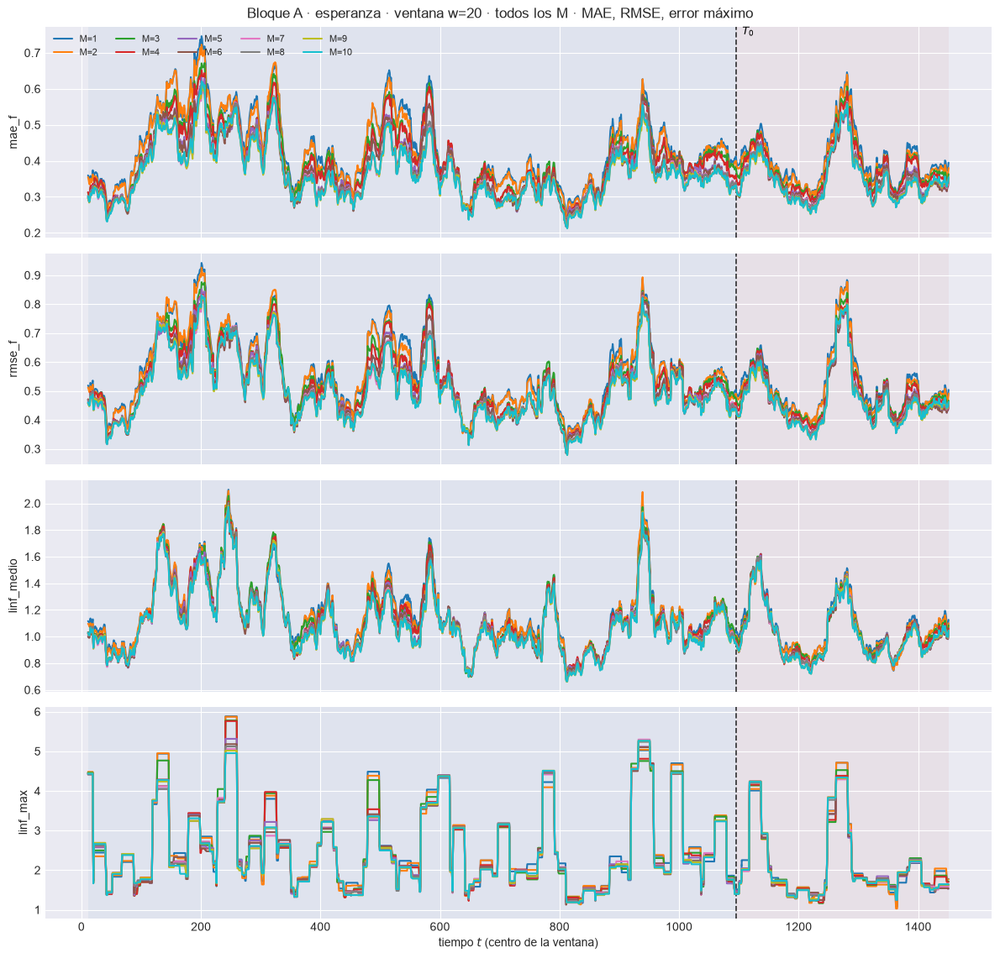

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.1s eta=0.2s  mae_f: w=30 train=0.3771  w=30 test=0.3496


  2/4 (50.0%) t=0.1s eta=0.1s  rmse_f: w=30 train=0.5153  w=30 test=0.4586


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.095  w=30 test=0.9753


  4/4 (100.0%) t=0.2s eta=0.0s  linf_max: w=30 train=2.602  w=30 test=1.832


[plot_ventana_movil] listo: 4 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_barrido_M\85_bloqueA_w30.png


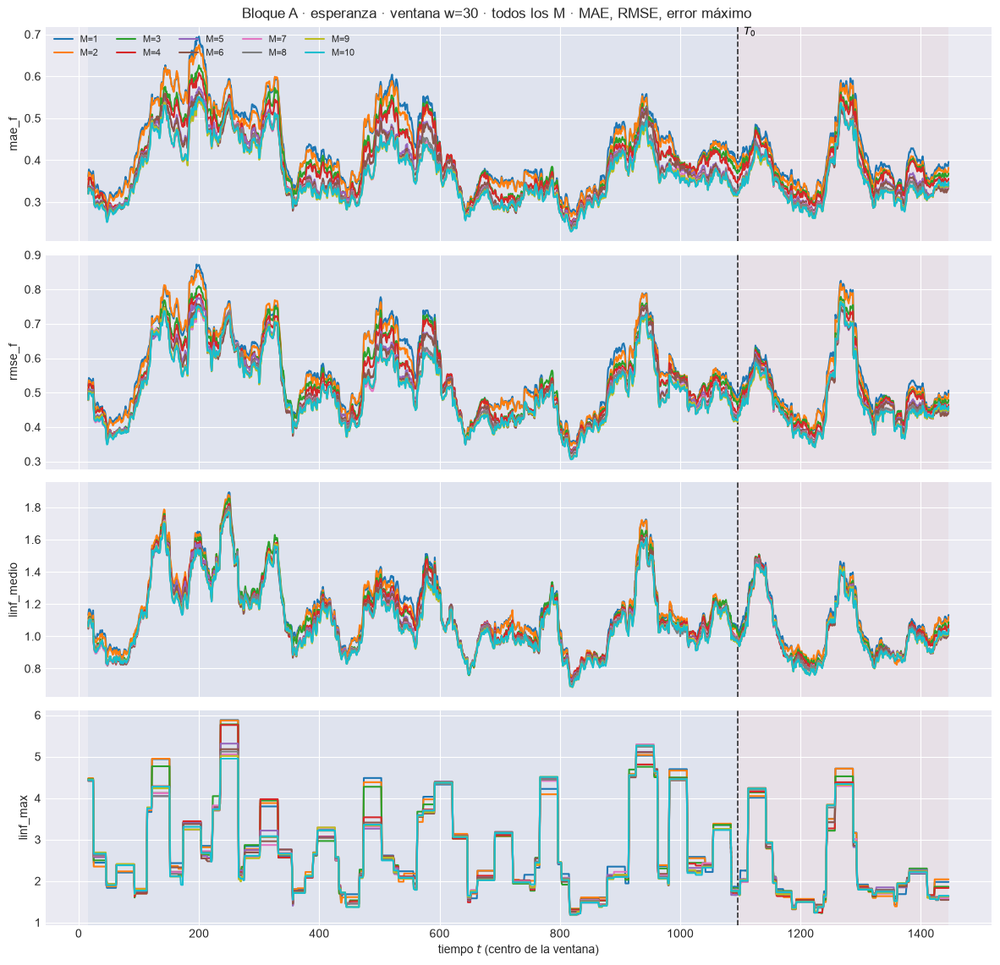

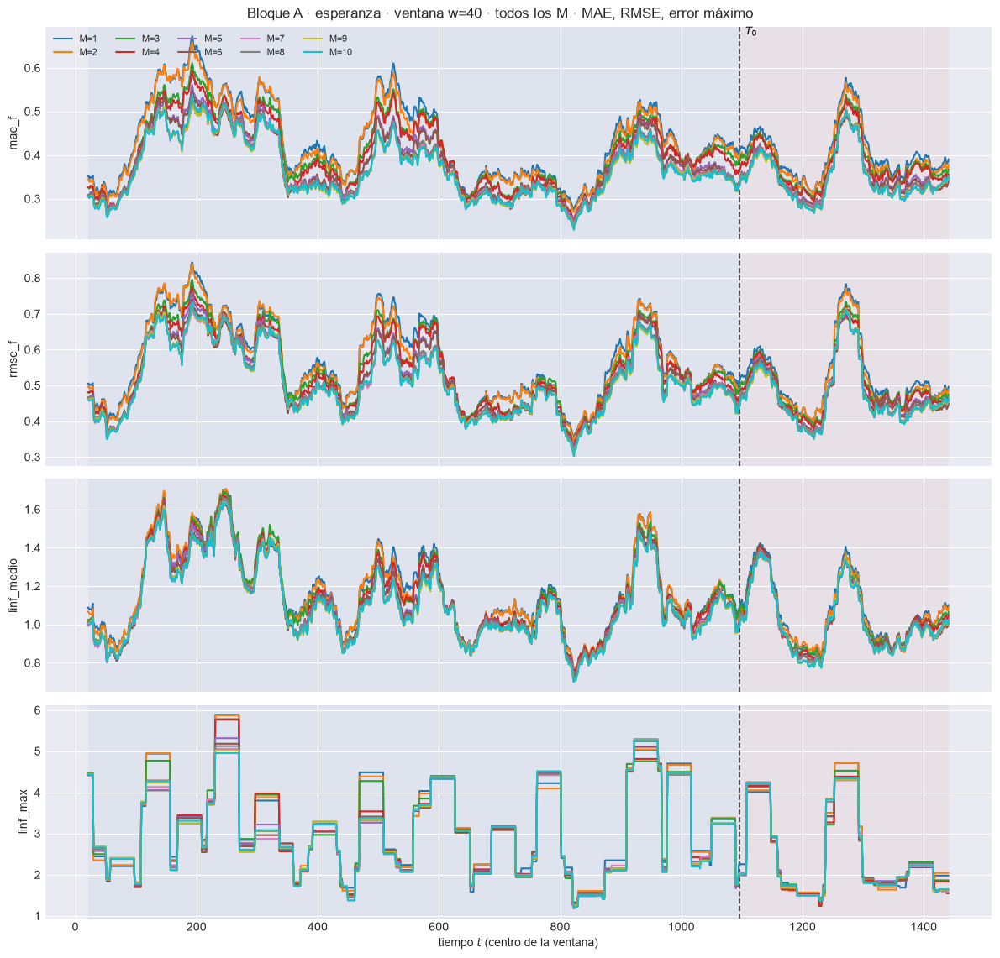

In [9]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU, predictores=PREDICTORES, intervalos=INTERVALOS)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · esperanza · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?

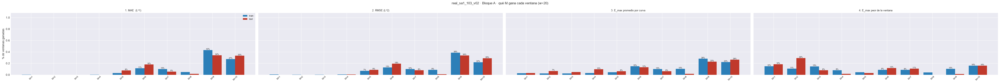

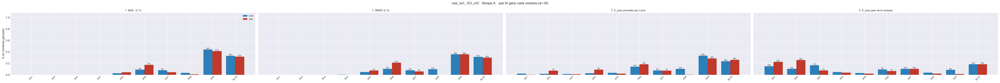

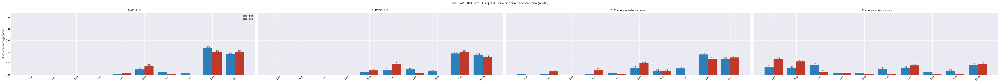

In [10]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

### 4.2 ¿Qué predictor gana cada ventana?

Bajo MAE ganan las medianas si la predictiva es multimodal o asimétrica; bajo RMSE, la esperanza.

In [11]:
for M in M_OK:
    EST[M]["ventana_pred"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas")
GANA_P, REL_P = ganadores_por_ventana(EST, "ventana_pred", "predictor", METRICAS_A, NIVEL)
GANA_P.to_csv(PATH_BARRIDO / "101b_ganador_predictor.csv", index=False)

for etiqueta, _c in METRICAS_A:
    display(GANA_P[(GANA_P.metrica == etiqueta) & (GANA_P.bloque == "test")]
            .pivot(index="predictor", columns="M", values="pct_ventanas_ganadas").loc[list(PREDICTORES)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada predictor (w={W_REF})"))

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,58.9%,51.2%,37.2%,47.6%,52.4%,54.2%,48.5%,59.2%,51.5%,51.2%
mediana,14.0%,9.2%,26.5%,14.0%,22.9%,30.4%,25.0%,21.4%,33.3%,42.0%
medoide,22.9%,35.4%,25.3%,23.8%,3.6%,2.4%,5.4%,0.0%,0.0%,1.2%
modal,4.2%,4.2%,11.0%,14.6%,21.1%,13.1%,21.1%,19.3%,15.2%,5.7%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,47.9%,65.5%,48.2%,56.8%,61.0%,53.9%,55.4%,58.9%,54.5%,57.1%
mediana,23.5%,9.5%,28.3%,24.1%,21.1%,30.1%,34.8%,36.6%,42.3%,39.6%
medoide,26.5%,23.8%,19.3%,12.2%,1.8%,3.6%,0.0%,0.3%,0.3%,3.3%
modal,2.1%,1.2%,4.2%,6.8%,16.1%,12.5%,9.8%,4.2%,3.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,37.5%,48.8%,27.1%,37.5%,48.5%,43.5%,46.4%,50.0%,54.2%,62.5%
mediana,18.5%,15.2%,17.9%,22.3%,28.6%,28.0%,31.8%,34.8%,34.2%,31.0%
medoide,26.2%,29.8%,28.3%,22.9%,4.5%,9.2%,3.0%,13.7%,7.4%,0.9%
modal,17.9%,6.2%,26.8%,17.3%,18.5%,19.3%,18.8%,1.5%,4.2%,5.7%


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,38.4%,53.9%,40.8%,25.6%,36.9%,57.7%,39.3%,40.2%,33.9%,25.9%
mediana,26.5%,3.6%,14.6%,24.7%,17.0%,17.9%,21.7%,22.0%,17.0%,28.6%
medoide,7.4%,20.5%,27.7%,28.0%,29.5%,14.9%,26.2%,22.9%,43.2%,16.7%
modal,27.7%,22.0%,17.0%,21.7%,16.7%,9.5%,12.8%,14.9%,6.0%,28.9%


### 4.3 Los cuatro predictores en la ventana móvil

`58_ventana_predictores_w<w>.png` por $M$ y `108_predictores_ventana_w30.png` en el barrido.

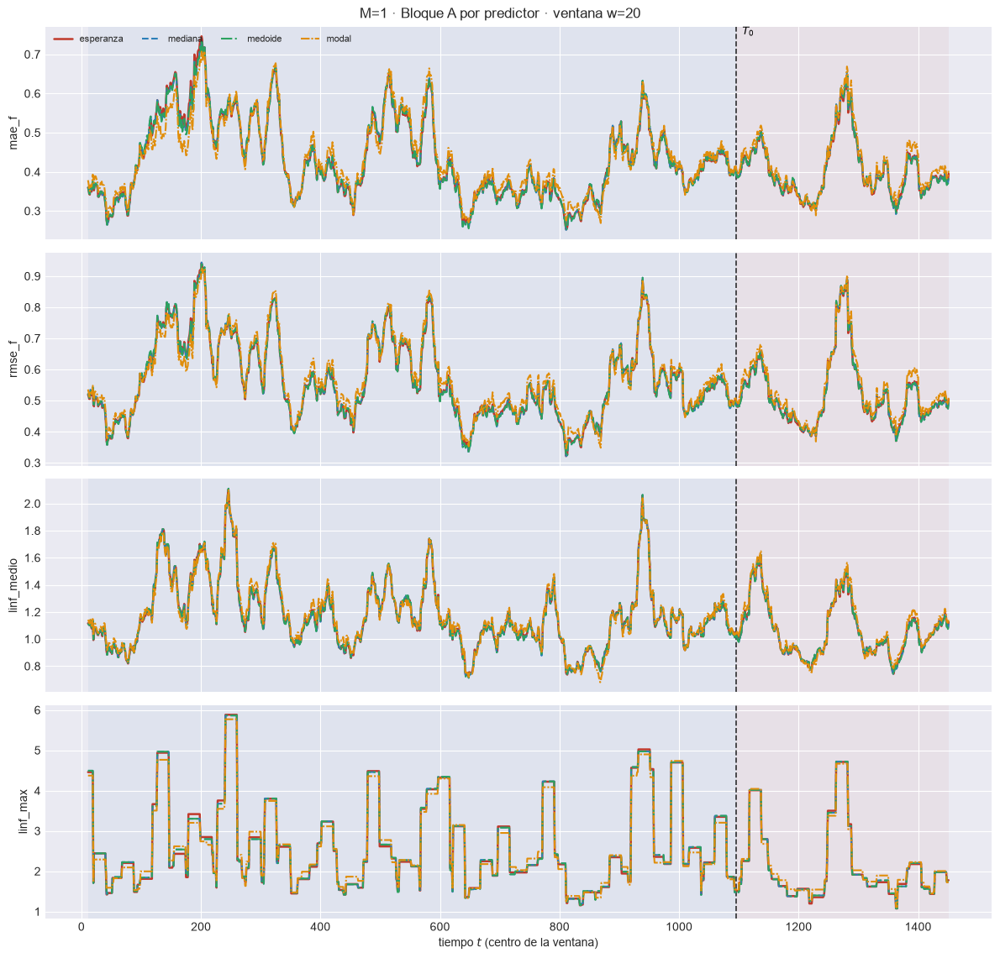

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.4248  w=30 test=0.3877


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.5529  w=30 test=0.494


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.15  w=30 test=1.018


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.64  w=30 test=1.914


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m01\58_ventana_predictores_w30.png


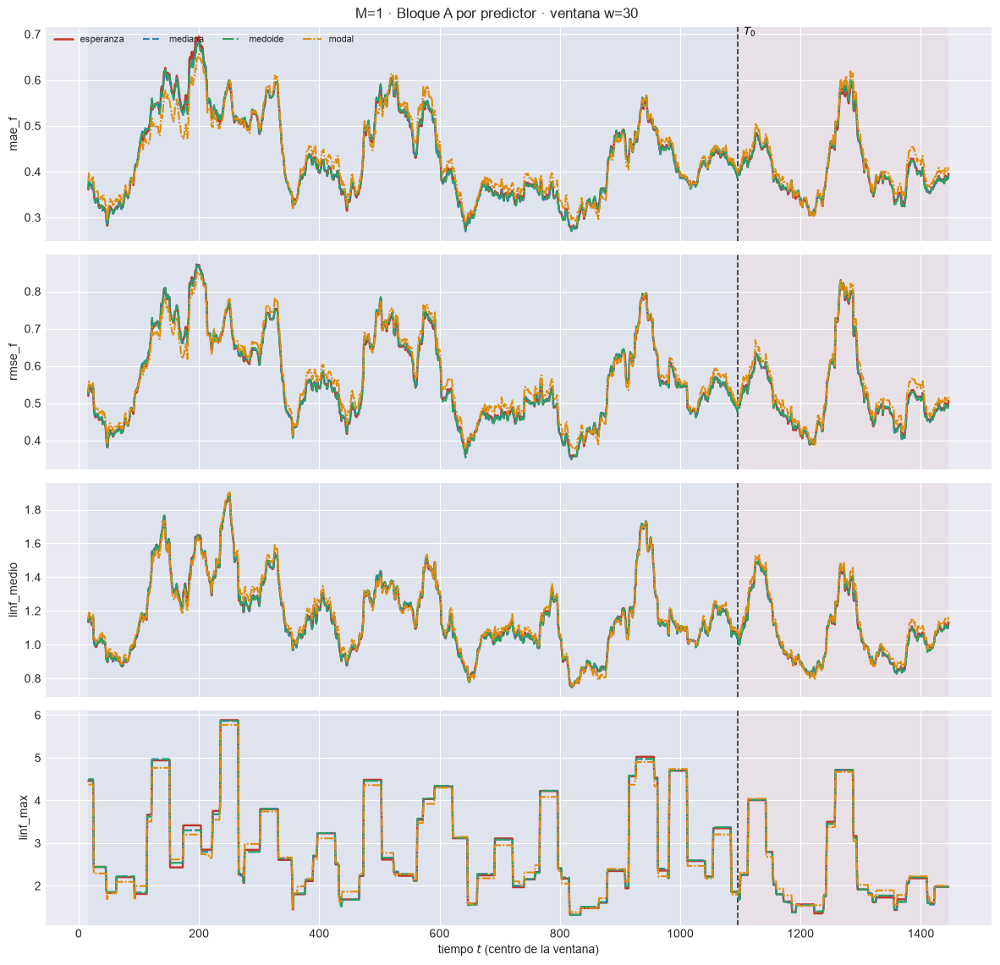

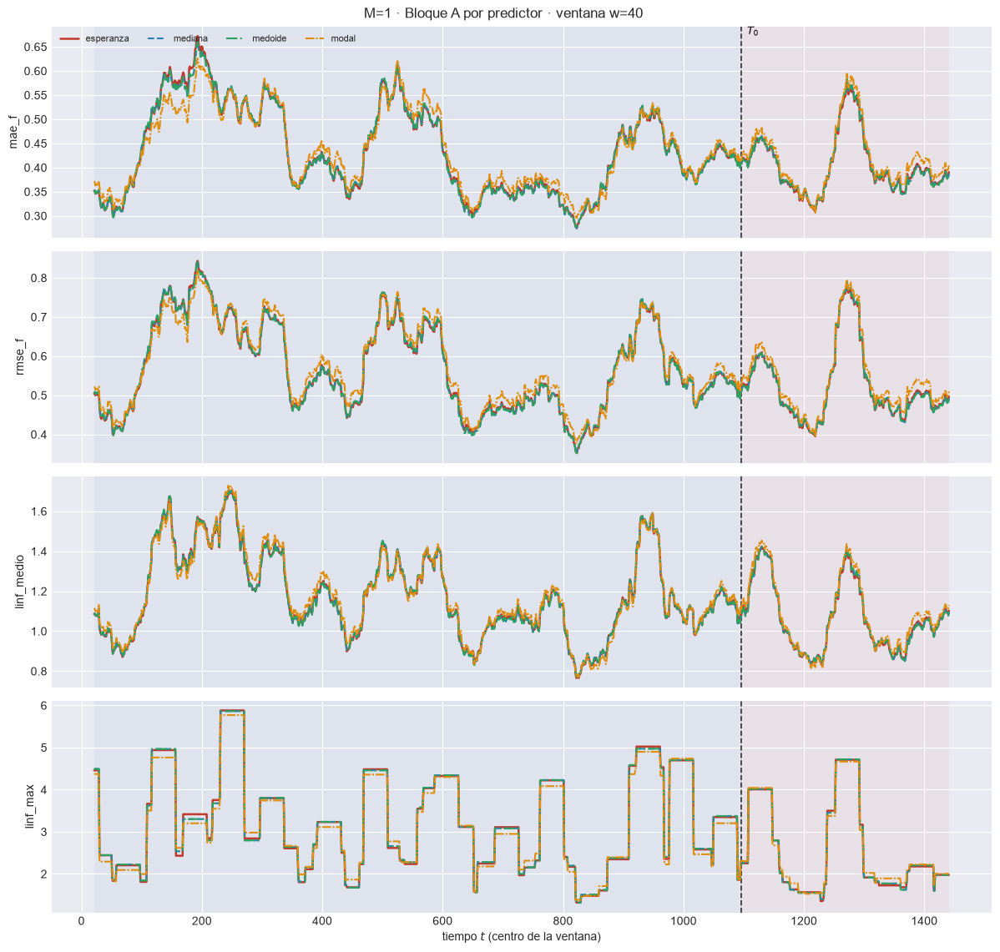

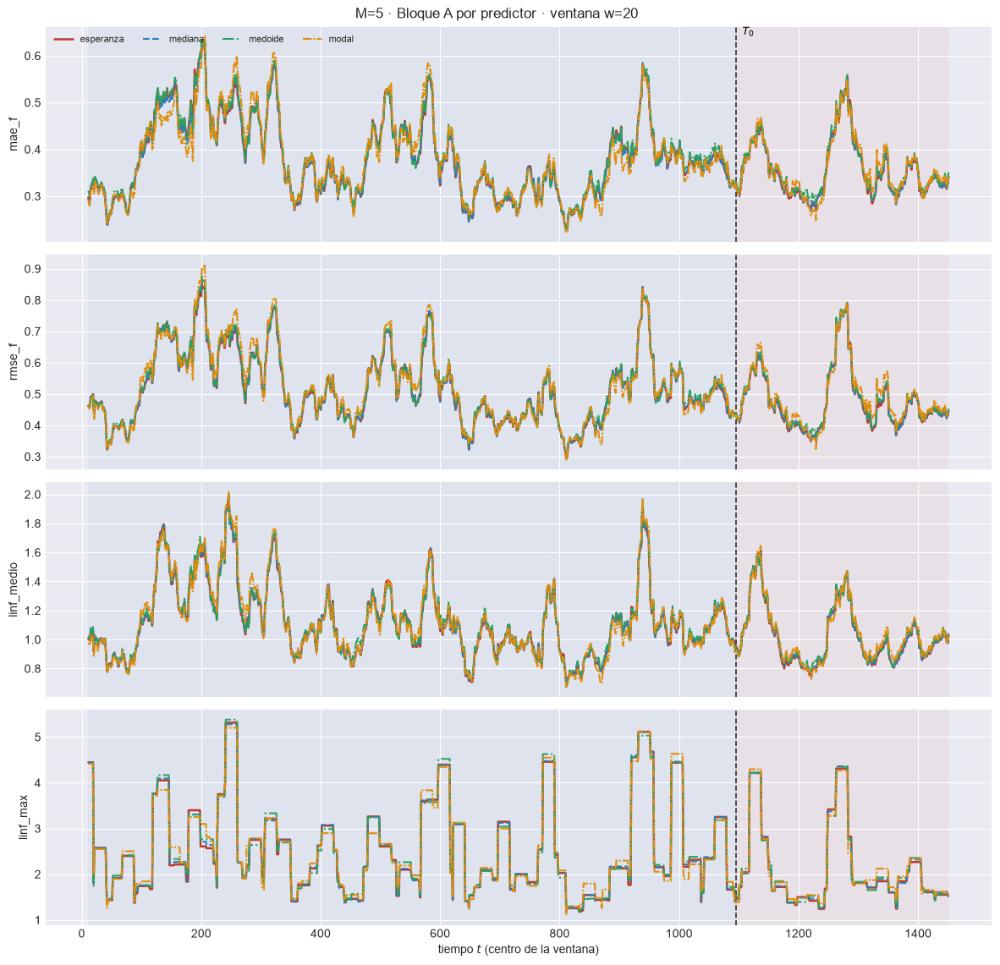

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.3748  w=30 test=0.3454


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.5097  w=30 test=0.4623


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.091  w=30 test=0.9743


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.638  w=30 test=1.872


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m05\58_ventana_predictores_w30.png


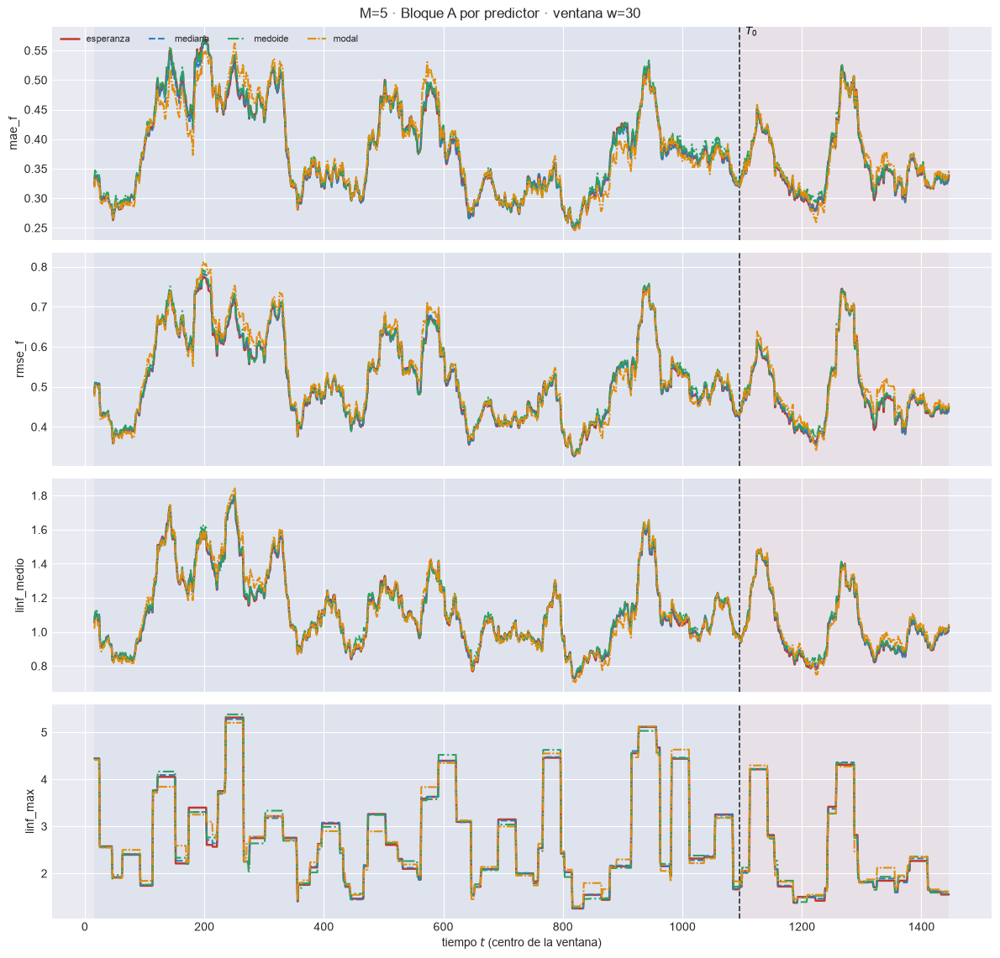

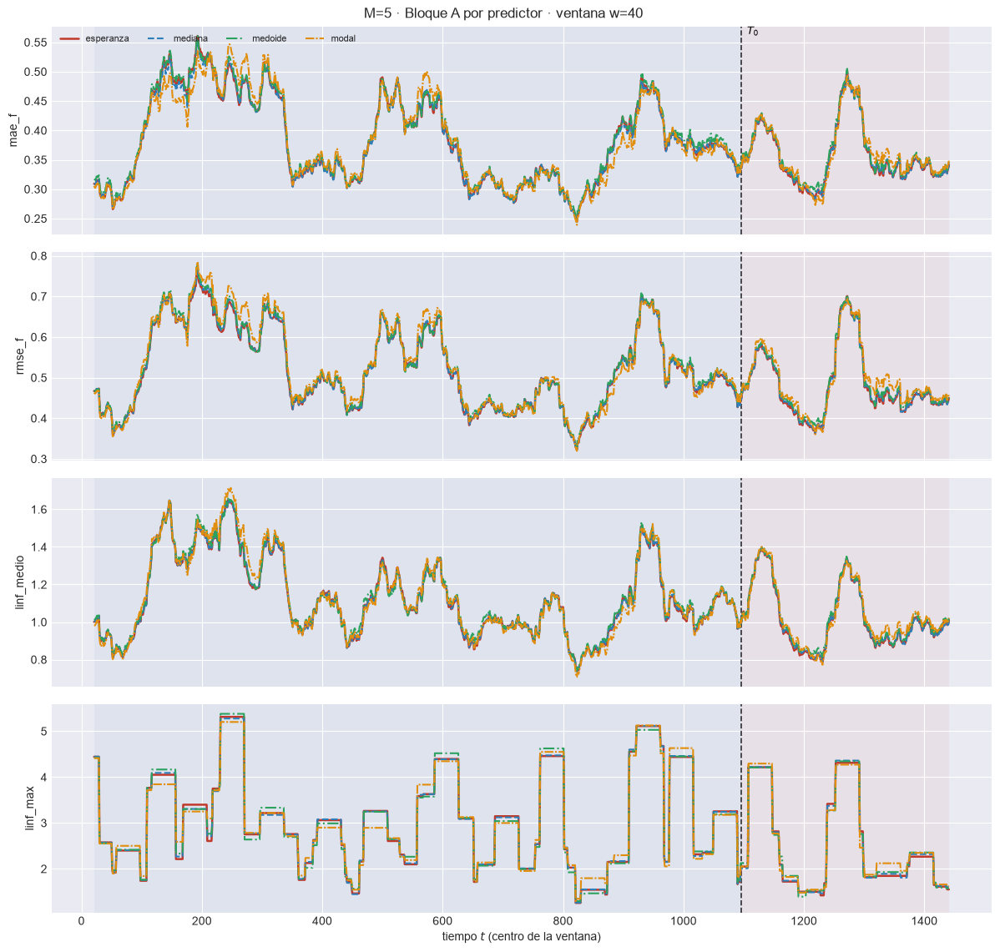

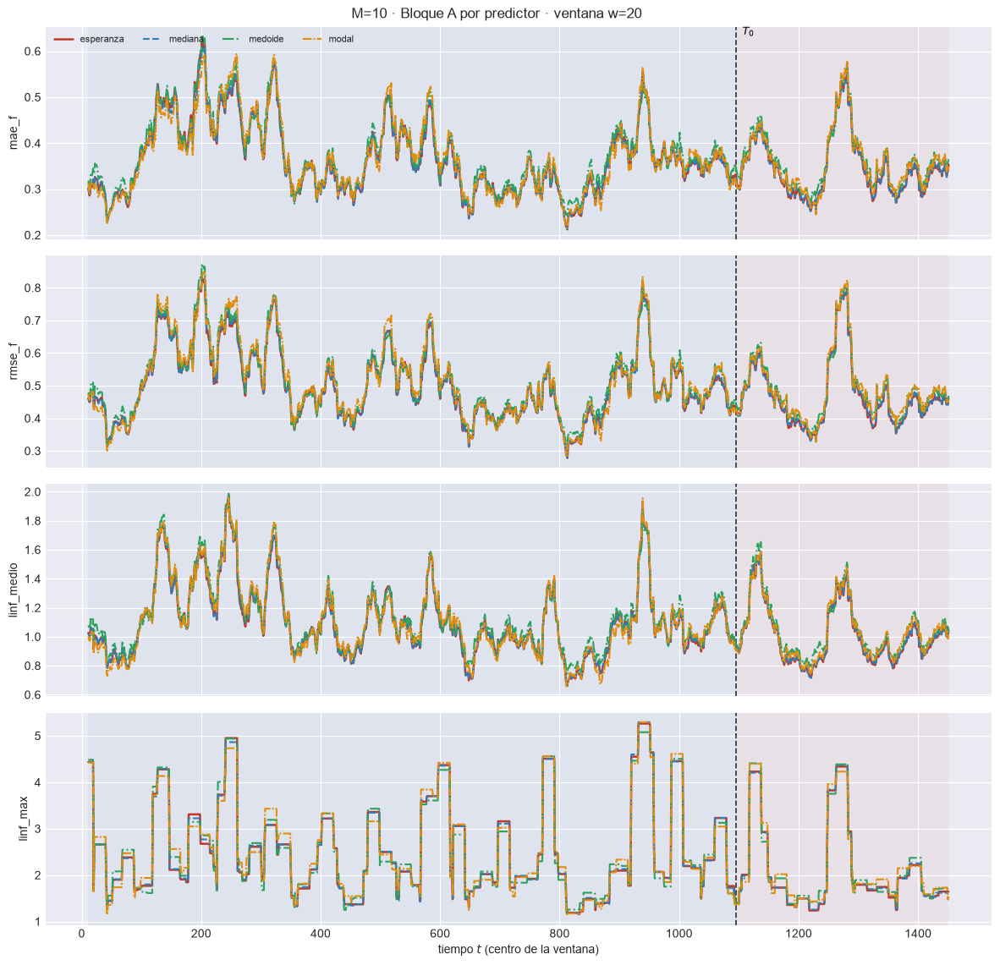

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.0s  mae_f: w=30 train=0.359  w=30 test=0.3391


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.5016  w=30 test=0.4571


  3/4 (75.0%) t=0.0s eta=0.0s  linf_medio: w=30 train=1.074  w=30 test=0.9781


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.635  w=30 test=1.907


[plot_ventana_movil] listo: 4 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m10\58_ventana_predictores_w30.png


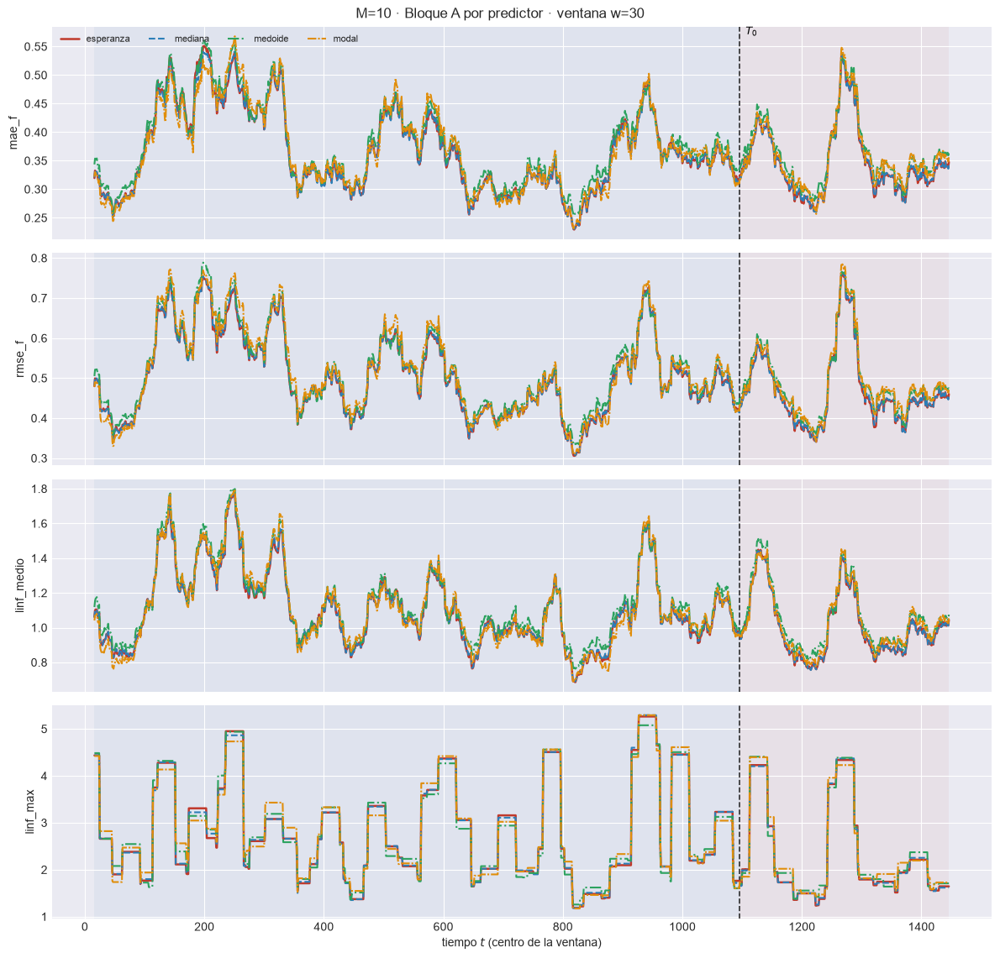

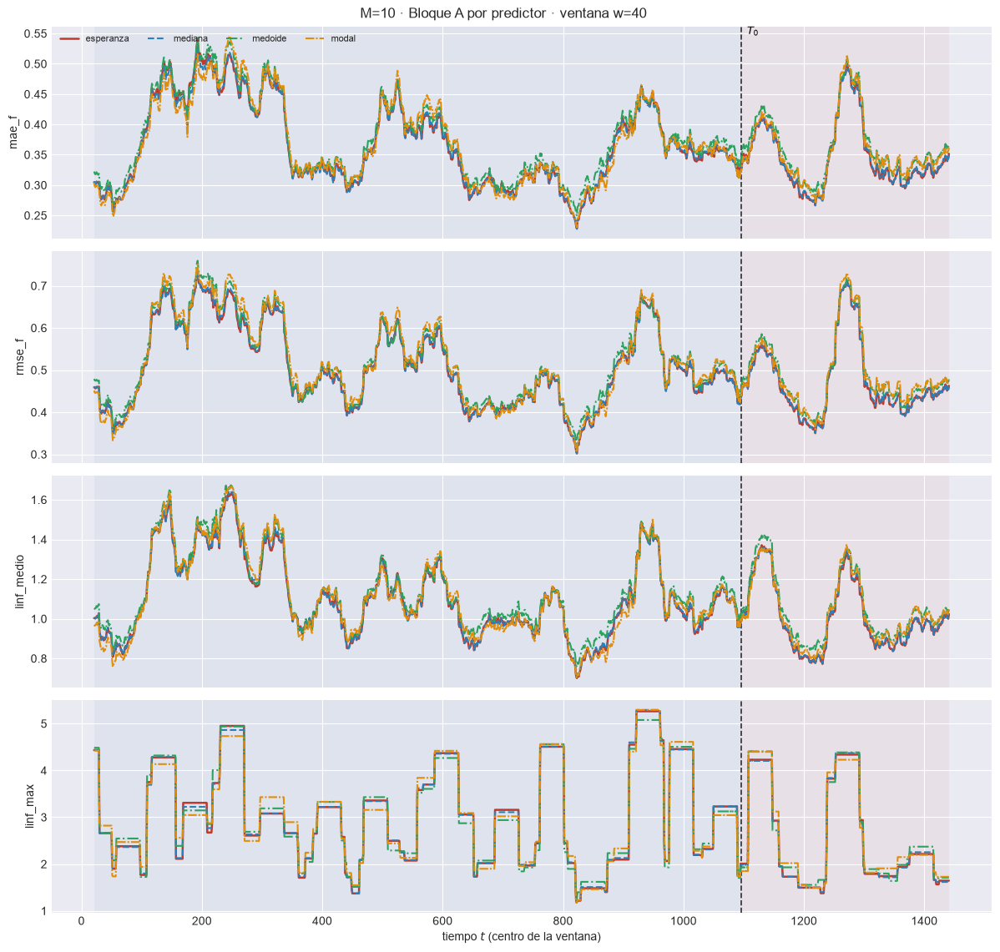

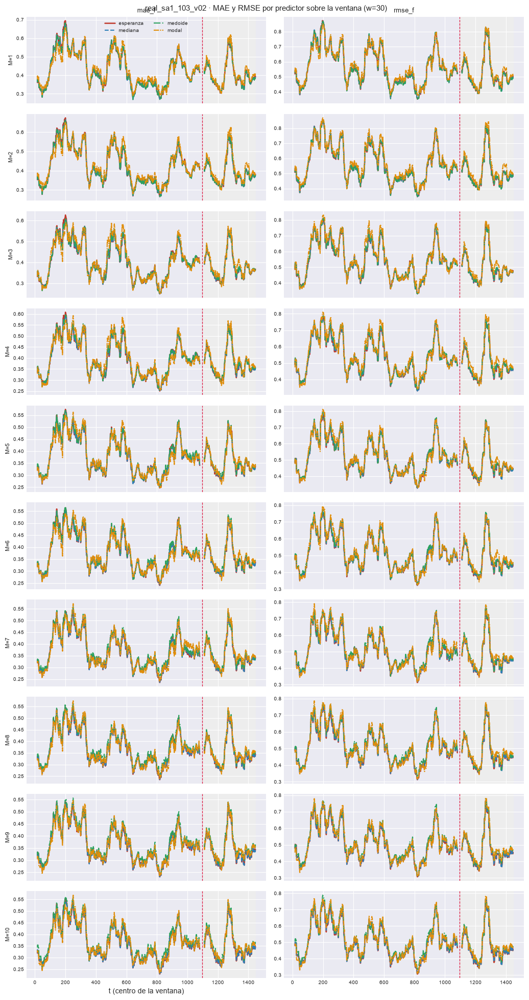

In [12]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        tp = filtrar_ventana(EST[M]["tablas_fun"][w], intervalo="equicolas")
        tp.attrs["w"] = w
        plot_ventana_movil(
            tp, T0, METRICAS_A_COLS, columna_grupo="predictor", estilos=ESTILOS_PREDICTORES,
            title=f"M={M} · Bloque A por predictor · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"58_ventana_predictores_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

plot_ventana_grupos_por_M(
    {M: filtrar_ventana(EST[M]["tablas_fun"][W_REF], intervalo="equicolas") for M in M_OK},
    ["mae_f", "rmse_f"], "predictor", T0, ESTILOS_PREDICTORES,
    f"{EXPERIMENT_BASE} · MAE y RMSE por predictor sobre la ventana (w={W_REF})",
    PATH_BARRIDO / f"108_predictores_ventana_w{W_REF}.png")
plt.show()

## 5. Bloque B por construcción de intervalo

Equi-colas, banda simultánea y HDR puntual (docs §03_05_05) sobre las mismas extracciones; las seis métricas van sobre la unión de tramos. Las figuras de los $M$ superpuestos son de la equi-colas.

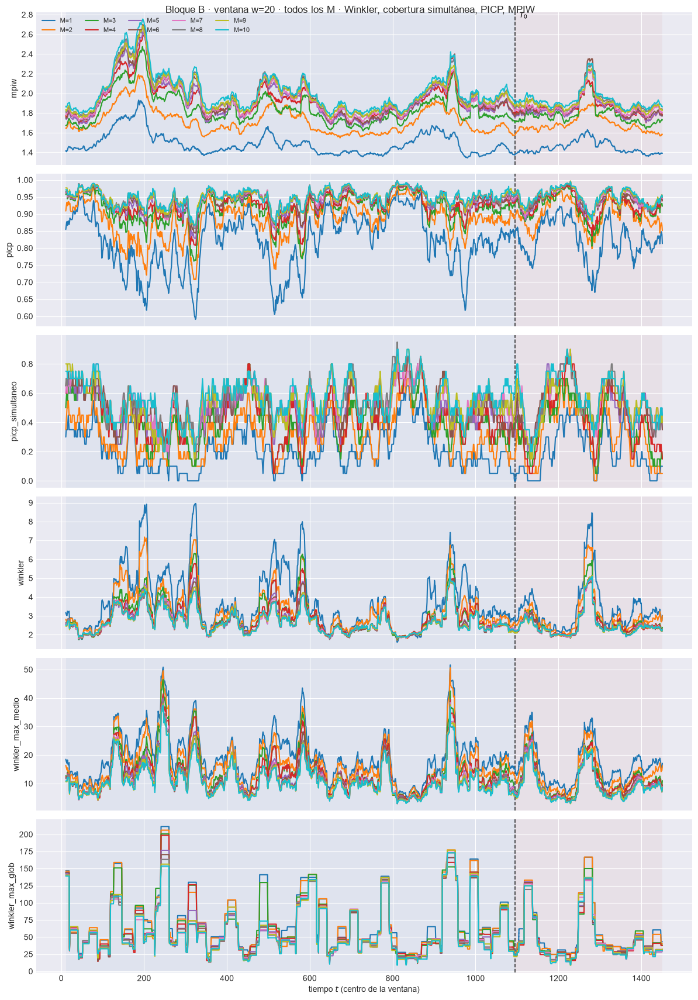

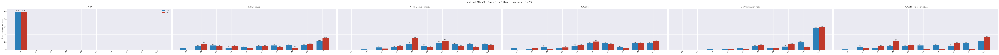

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.2s  mpiw: w=30 train=1.87  w=30 test=1.829


  2/6 (33.3%) t=0.1s eta=0.1s  picp: w=30 train=0.936  w=30 test=0.9337


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.4667  w=30 test=0.4667


  4/6 (66.7%) t=0.1s eta=0.1s  winkler: w=30 train=2.754  w=30 test=2.419


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=12.07  w=30 test=9.29


  6/6 (100.0%) t=0.2s eta=0.0s  winkler_max_glob: w=30 train=62.34  w=30 test=38.18


[plot_ventana_movil] listo: 6 pasos en 0.9s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_barrido_M\86_bloqueB_w30.png


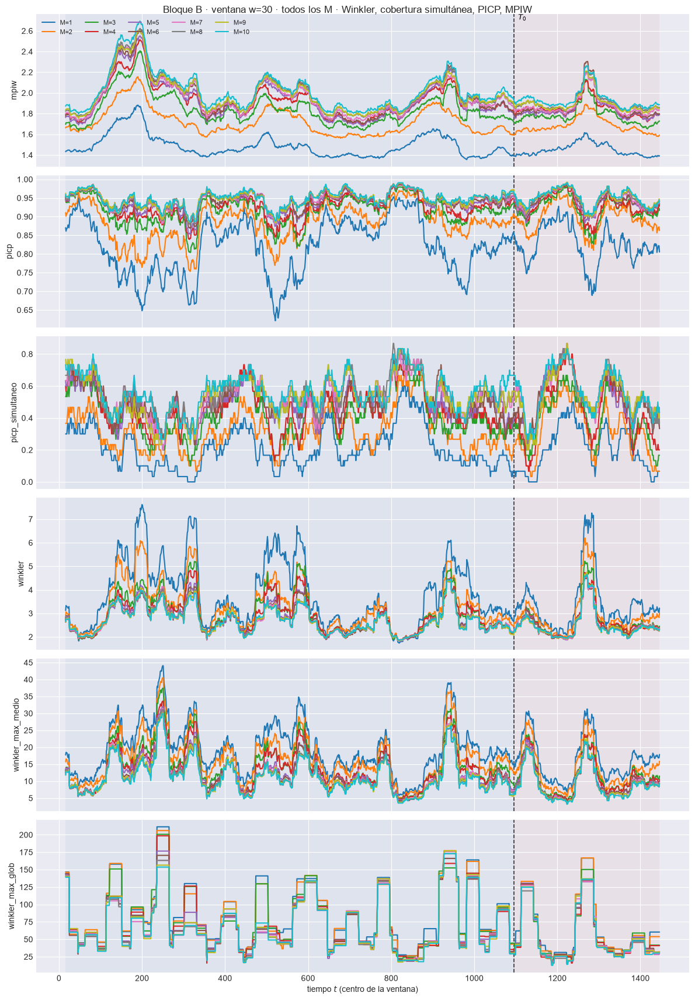

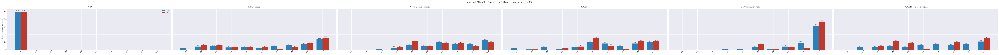

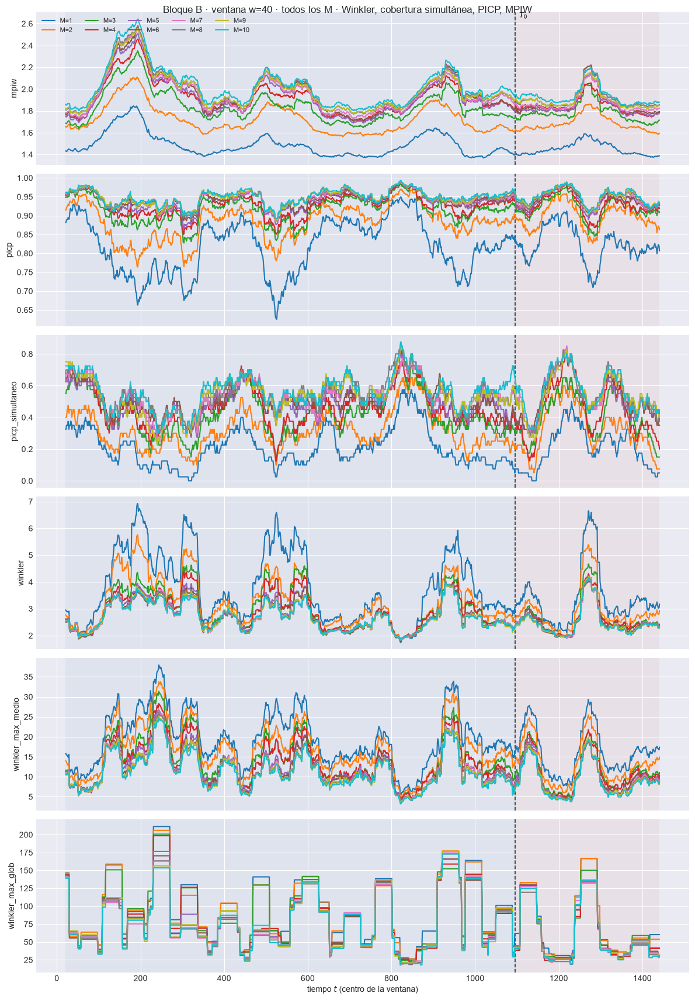

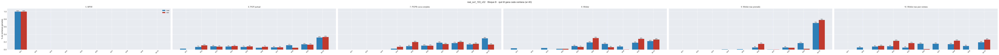

In [13]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

### 5.1 Las tres construcciones en la ventana móvil

`59_ventana_intervalos_w<w>.png` por $M$ y quién gana cada ventana (`109_*`). En PICP y PICPB gana la más cercana al nominal.

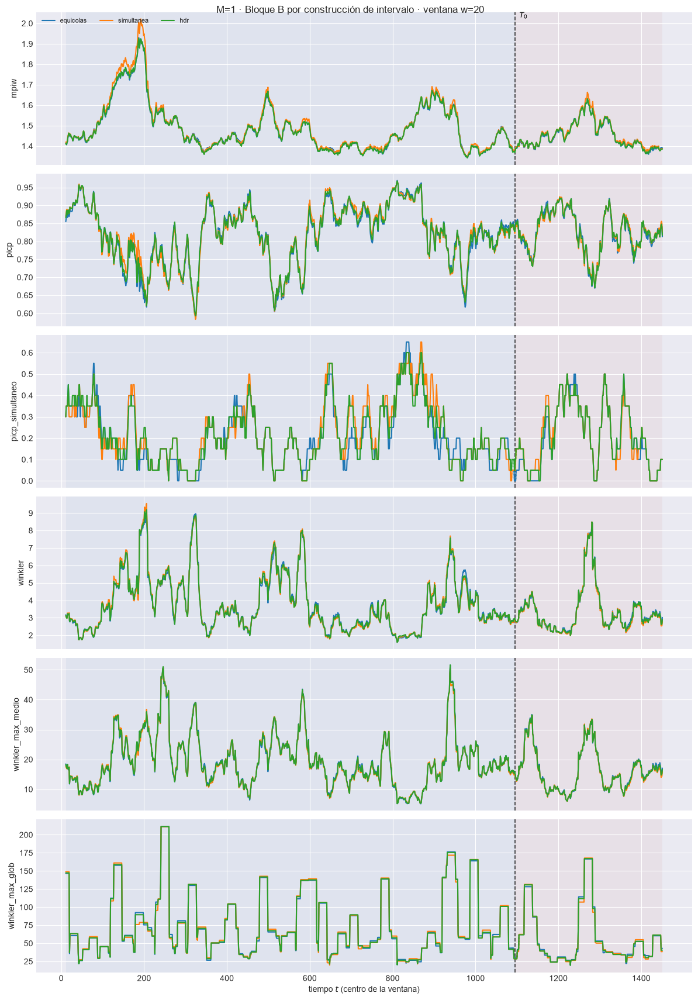

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=1.457  w=30 test=1.445


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.8253  w=30 test=0.8228


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.2  w=30 test=0.2


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=3.381  w=30 test=3.051


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=18.72  w=30 test=14.9


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=69.7  w=30 test=49.9


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m01\59_ventana_intervalos_w30.png


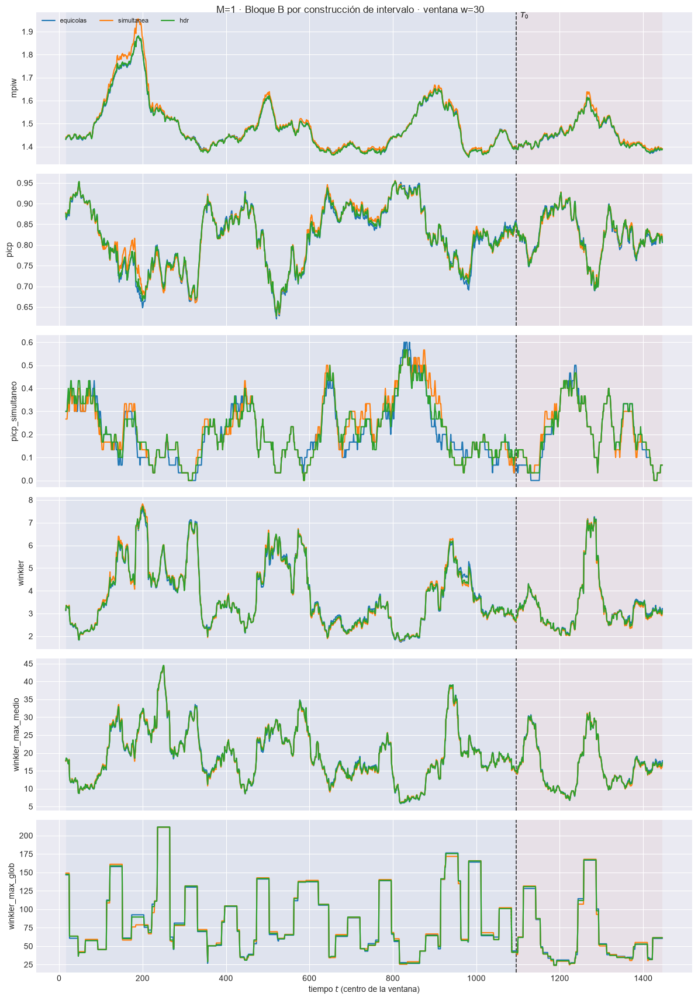

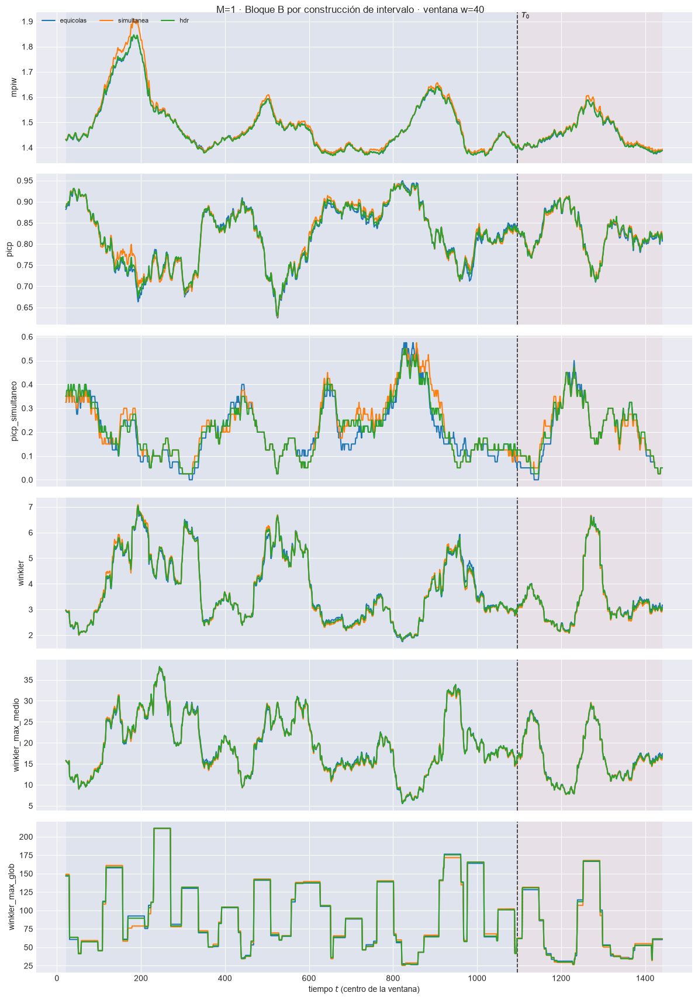

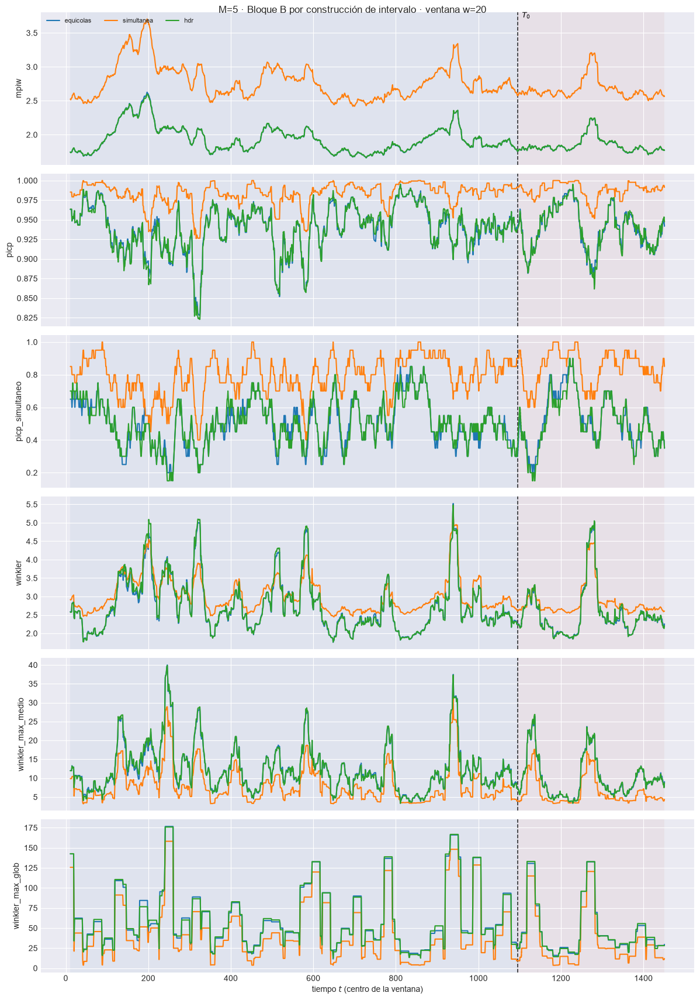

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=2.054  w=30 test=1.873


  2/6 (33.3%) t=0.0s eta=0.0s  picp: w=30 train=0.9537  w=30 test=0.9573


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.5667  w=30 test=0.6333


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=2.781  w=30 test=2.568


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=10.26  w=30 test=6.973


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=57.7  w=30 test=35.2


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m05\59_ventana_intervalos_w30.png


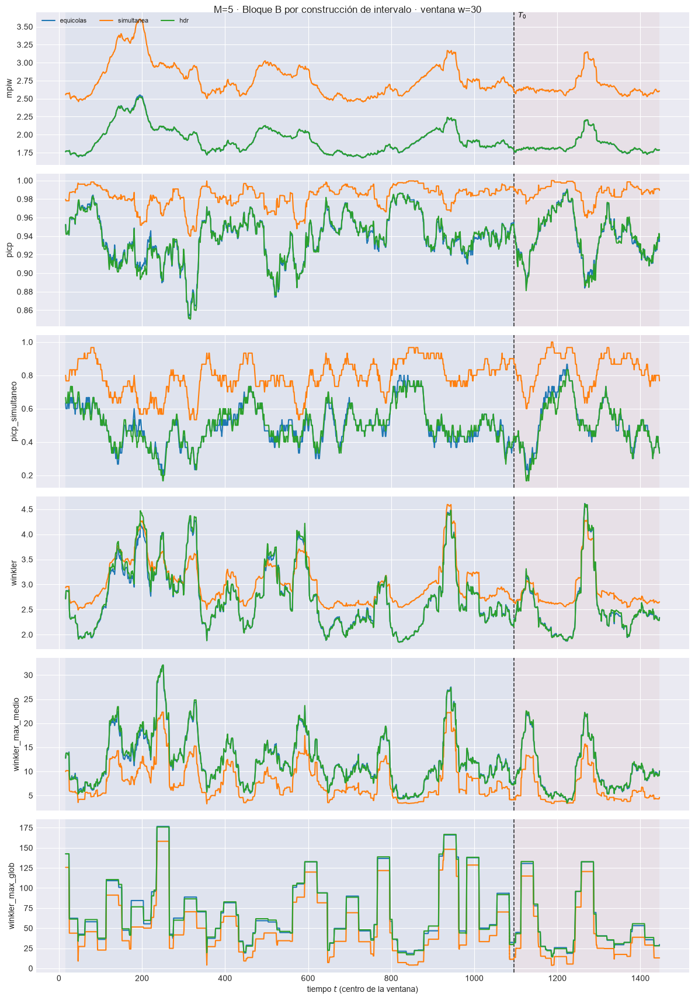

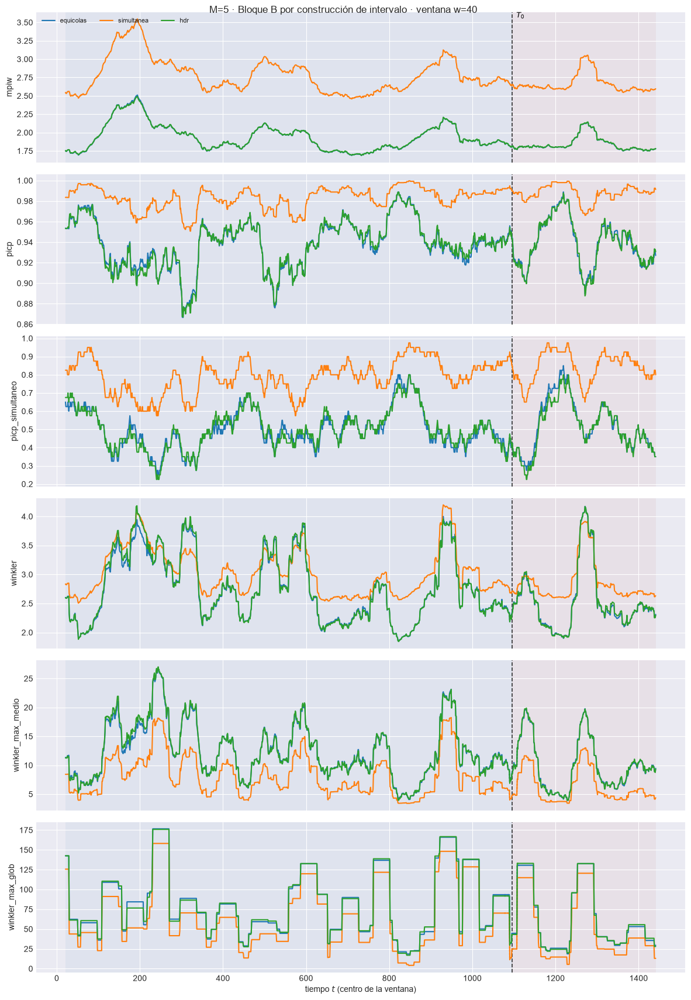

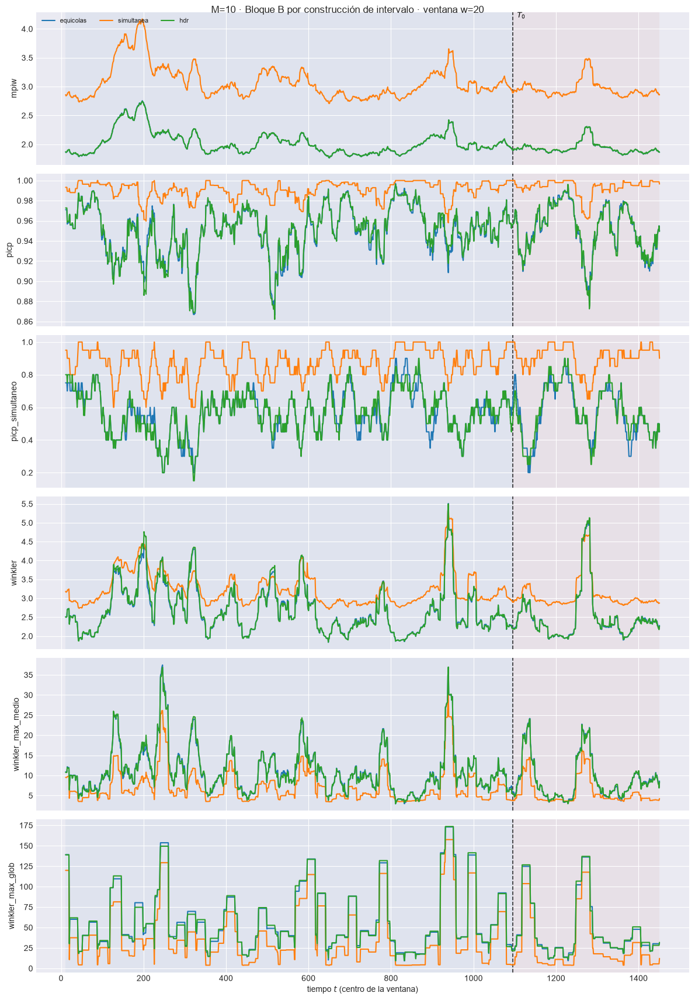

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=2.13  w=30 test=1.96


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9641  w=30 test=0.9681


  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.6333  w=30 test=0.7


  4/6 (66.7%) t=0.0s eta=0.0s  winkler: w=30 train=2.876  w=30 test=2.506


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.991  w=30 test=6.137


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=53.04  w=30 test=31.68


[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m10\59_ventana_intervalos_w30.png


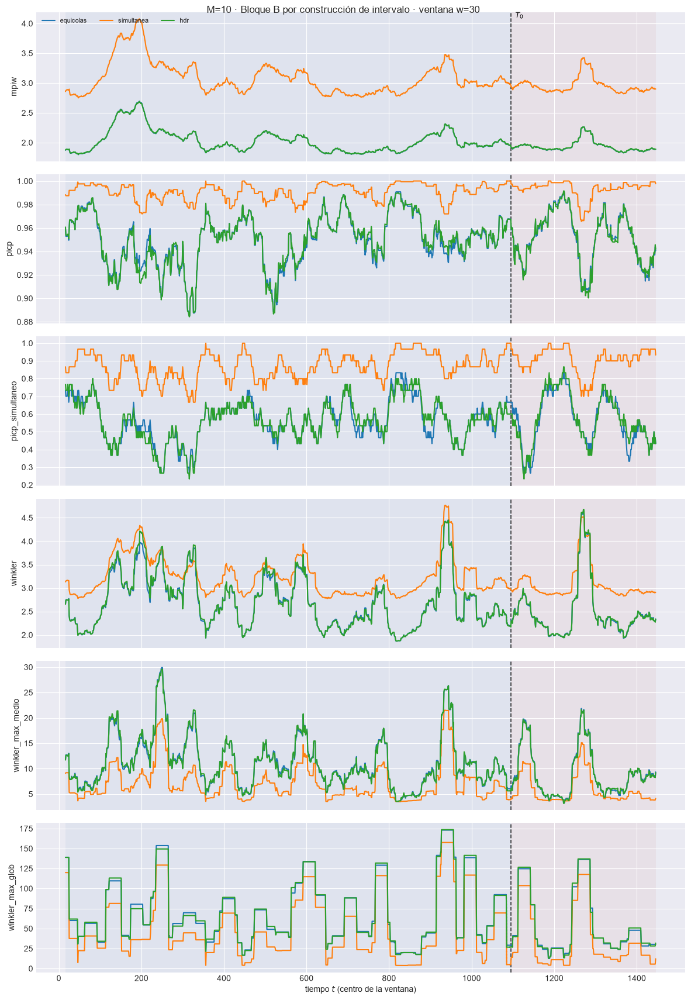

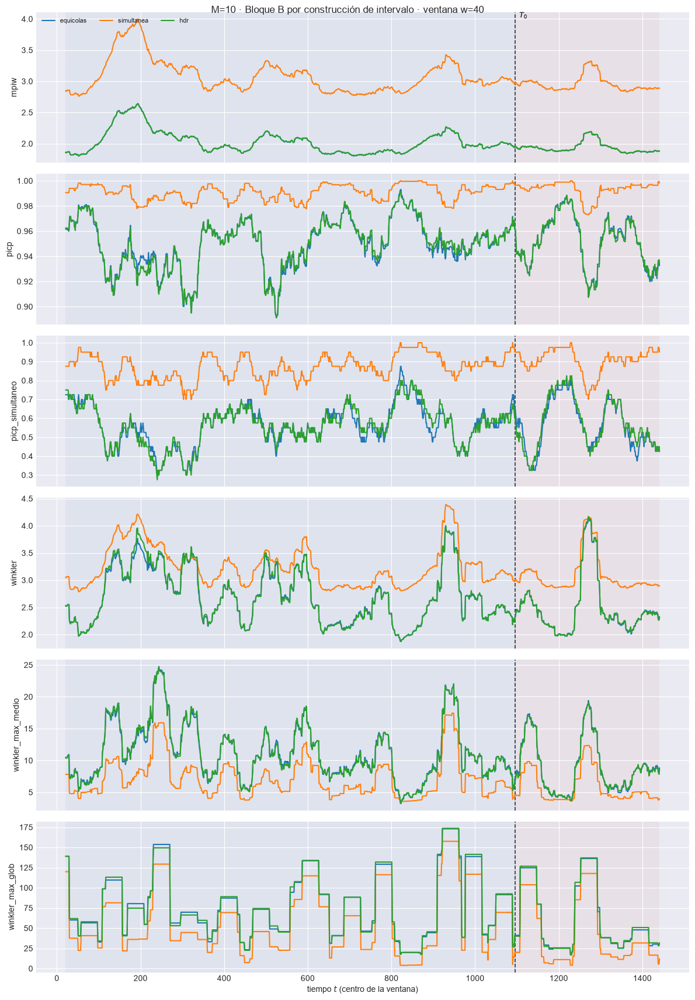

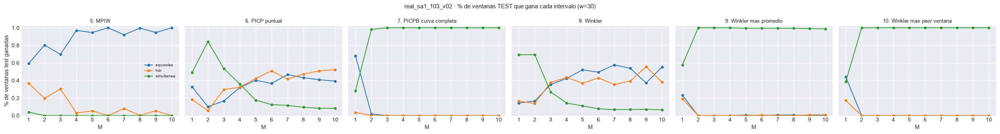

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,59.2%,80.4%,69.6%,97.0%,94.6%,100.0%,92.0%,99.7%,94.6%,100.0%
simultanea,3.9%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
hdr,36.9%,19.6%,30.4%,3.0%,5.4%,0.0%,8.0%,0.3%,5.4%,0.0%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,32.7%,10.1%,16.7%,31.8%,40.2%,36.6%,46.7%,43.2%,40.8%,39.3%
simultanea,49.1%,84.2%,53.6%,36.0%,17.6%,12.5%,11.6%,9.5%,8.3%,8.3%
hdr,18.2%,5.7%,29.8%,32.1%,42.3%,50.9%,41.7%,47.3%,50.9%,52.4%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,68.2%,1.8%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
simultanea,28.3%,98.2%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
hdr,3.6%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,14.3%,16.7%,35.4%,42.3%,52.1%,49.4%,57.7%,53.9%,37.2%,55.4%
simultanea,69.3%,69.3%,26.8%,14.3%,11.0%,7.7%,6.8%,6.8%,7.1%,6.5%
hdr,16.4%,14.0%,37.8%,43.5%,36.9%,42.9%,35.4%,39.3%,55.7%,38.1%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,23.2%,0.0%,0.0%,0.0%,0.6%,0.0%,0.6%,0.6%,0.0%,0.3%
simultanea,57.4%,100.0%,100.0%,100.0%,99.4%,99.4%,99.4%,99.4%,99.1%,98.8%
hdr,19.3%,0.0%,0.0%,0.0%,0.0%,0.6%,0.0%,0.0%,0.9%,0.9%


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,44.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
simultanea,38.7%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
hdr,17.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


In [14]:
for M in (m for m in M_DETALLE if m in M_OK):
    for w in VENTANAS_W:
        ti = filtrar_ventana(EST[M]["tablas_fun"][w], predictor="esperanza")
        ti.attrs["w"] = w
        plot_ventana_movil(
            ti, T0, METRICAS_B_COLS, columna_grupo="intervalo",
            title=f"M={M} · Bloque B por construcción de intervalo · ventana w={w}",
            save_path=str(EST[M]["paths"]["out_report"] / f"59_ventana_intervalos_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

for M in M_OK:
    EST[M]["ventana_int"] = filtrar_ventana(EST[M]["tablas_fun"][W_REF], predictor="esperanza")
GANA_I, REL_I = ganadores_por_ventana(EST, "ventana_int", "intervalo", METRICAS_B, NIVEL)
GANA_I.to_csv(PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.csv", index=False)
plot_ganador_grupo_vs_M(GANA_I, "intervalo", METRICAS_B,
                        f"{EXPERIMENT_BASE} · % de ventanas TEST que gana cada intervalo (w={W_REF})",
                        save_path=PATH_BARRIDO / f"109_ganador_intervalo_w{W_REF}.png")
plt.show()
for etiqueta, _c in METRICAS_B:
    display(GANA_I[(GANA_I.metrica == etiqueta) & (GANA_I.bloque == "test")]
            .pivot(index="intervalo", columns="M", values="pct_ventanas_ganadas").loc[list(INTERVALOS)]
            .style.format("{:.1%}").background_gradient(cmap="RdYlGn", axis=None)
            .set_caption(f"{etiqueta} · % de ventanas TEST ganadas por cada intervalo (w={W_REF})"))

## 6. Muestra de predicciones

Ventana de detalle, frontera train/test y ventanas con peor `METRICA_PEORES`.

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2649


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=0.983 rmse=0.3928


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2169


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=0.944 rmse=0.3235


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.892 rmse=0.476


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=0.896 rmse=0.3544


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=0.906 rmse=0.5224


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3493


[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.962 (nominal 0.95)


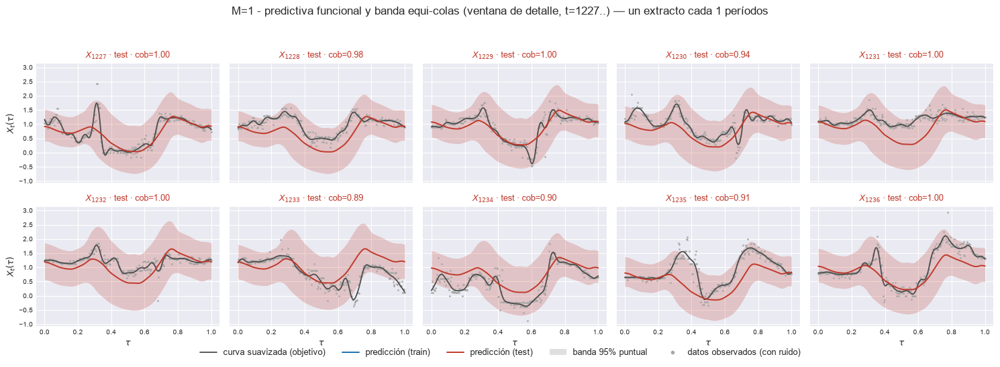

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2668


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.4058


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2096


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3347


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.892 rmse=0.456


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=0.997 rmse=0.3452


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=0.899 rmse=0.5156


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=0.972 rmse=0.3436


[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.976 (nominal 0.95)


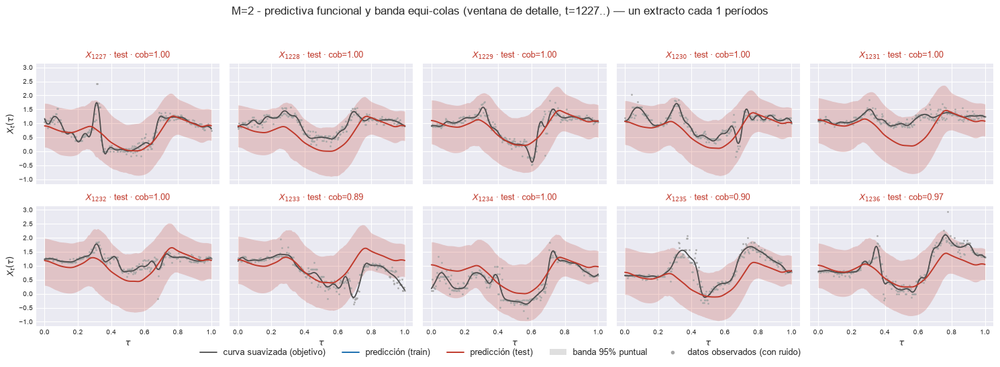

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2658


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.3633


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2398


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3291


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.934 rmse=0.3853


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2595


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=0.913 rmse=0.4681


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3353


[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.983 (nominal 0.95)


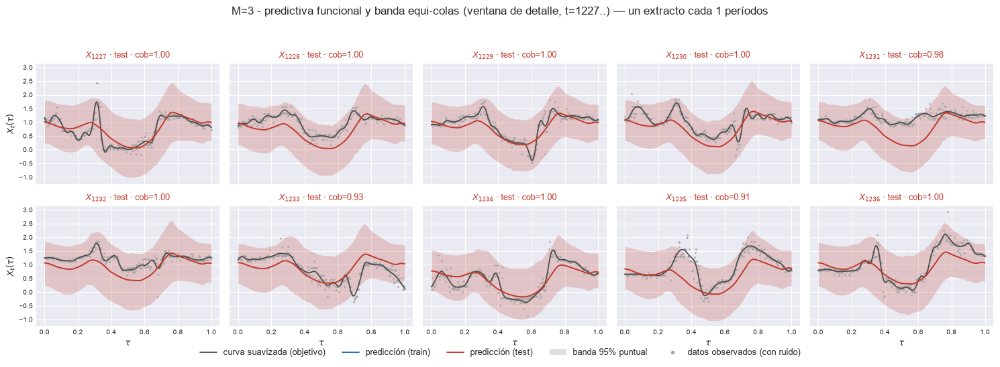

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2627


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.3731


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2429


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3277


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.934 rmse=0.3914


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2456


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=1.000 rmse=0.4296


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3043


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.993 (nominal 0.95)


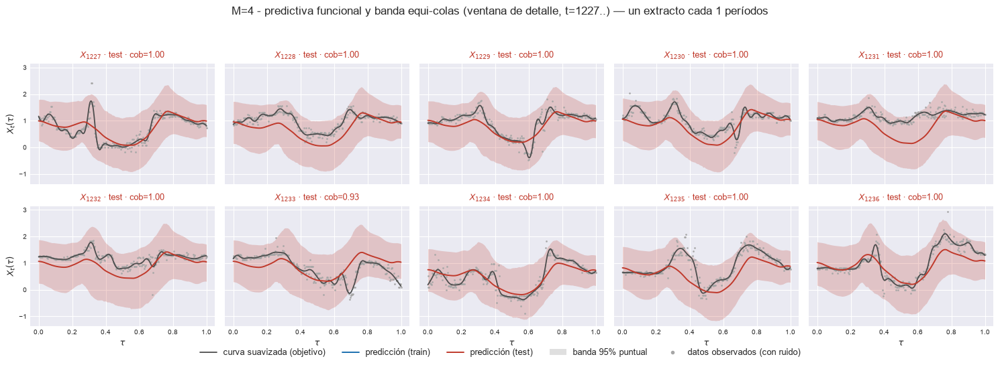

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2572


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.4032


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2727


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3347


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.969 rmse=0.3773


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2679


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=1.000 rmse=0.4177


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3138


[plot_extractos_curvas] listo: 10 pasos en 1.1s  cob media train=nan test=0.997 (nominal 0.95)


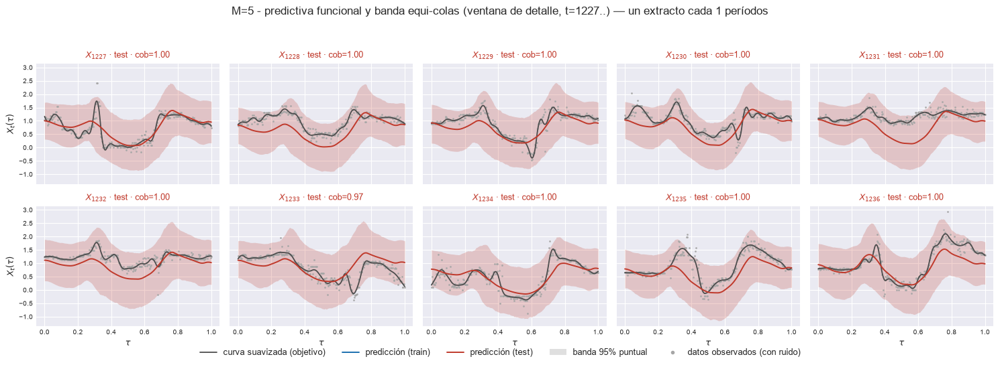

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2674


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.4013


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2594


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3363


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.965 rmse=0.3735


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2709


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=1.000 rmse=0.4155


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3133


[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.989 (nominal 0.95)


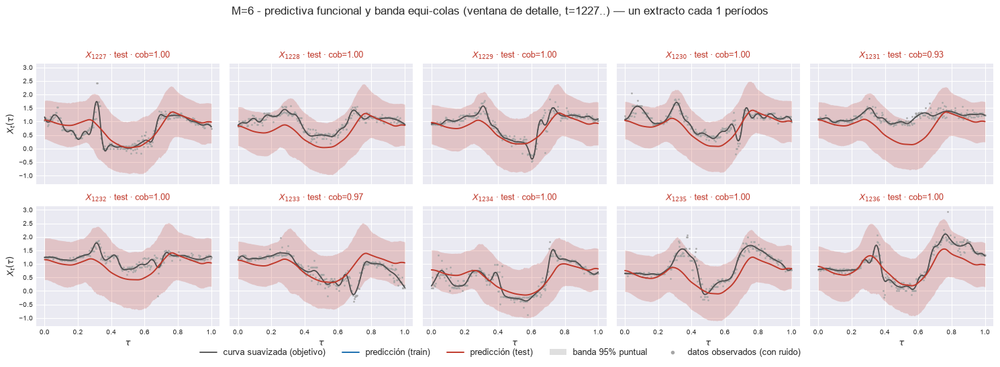

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2814


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.3903


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2374


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3267


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.979 rmse=0.3869


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2693


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=1.000 rmse=0.448


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3168


[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.998 (nominal 0.95)


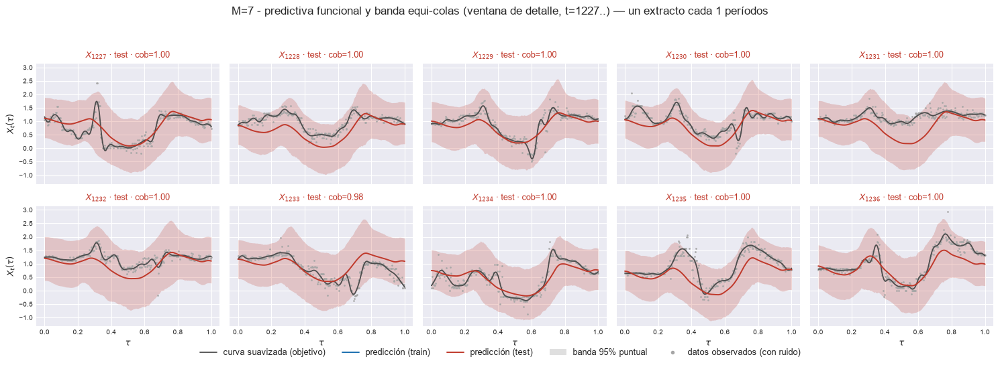

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2783


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.3888


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2366


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.3136


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.951 rmse=0.3888


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2649


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=0.986 rmse=0.4431


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3095


[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.994 (nominal 0.95)


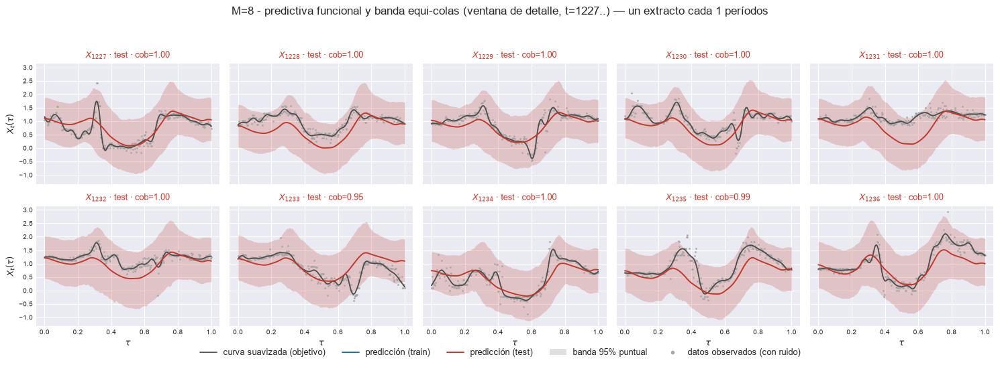

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.3099


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.3288


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.2262


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.2912


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.986 rmse=0.3793


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2989


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=1.000 rmse=0.4363


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3309


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.999 (nominal 0.95)


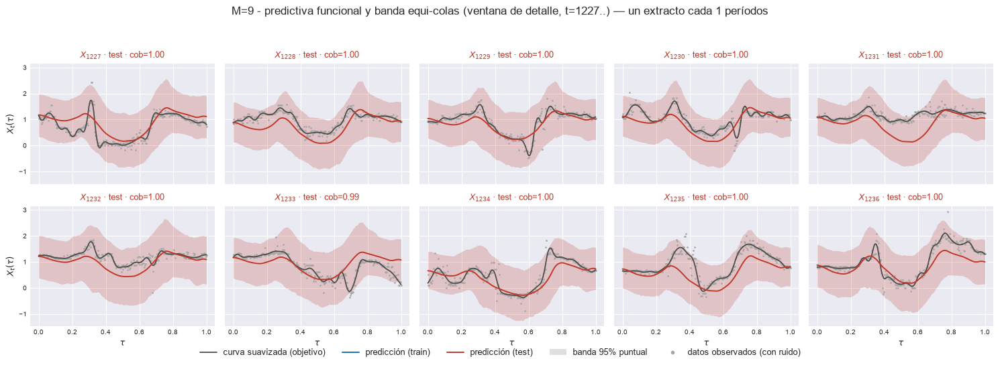

[plot_extractos_curvas] inicio (10 pasos)


  1/10 (10.0%) t=0.0s eta=0.0s  t=1227 [test] cob=1.000 rmse=0.2975


  2/10 (20.0%) t=0.0s eta=0.0s  t=1228 [test] cob=1.000 rmse=0.3393


  3/10 (30.0%) t=0.0s eta=0.0s  t=1229 [test] cob=1.000 rmse=0.224


  4/10 (40.0%) t=0.0s eta=0.0s  t=1230 [test] cob=1.000 rmse=0.2931


...

  7/10 (70.0%) t=0.0s eta=0.0s  t=1233 [test] cob=0.962 rmse=0.3877


  8/10 (80.0%) t=0.0s eta=0.0s  t=1234 [test] cob=1.000 rmse=0.2863


  9/10 (90.0%) t=0.0s eta=0.0s  t=1235 [test] cob=0.983 rmse=0.4347


  10/10 (100.0%) t=0.0s eta=0.0s  t=1236 [test] cob=1.000 rmse=0.3272


[plot_extractos_curvas] listo: 10 pasos en 0.8s  cob media train=nan test=0.994 (nominal 0.95)


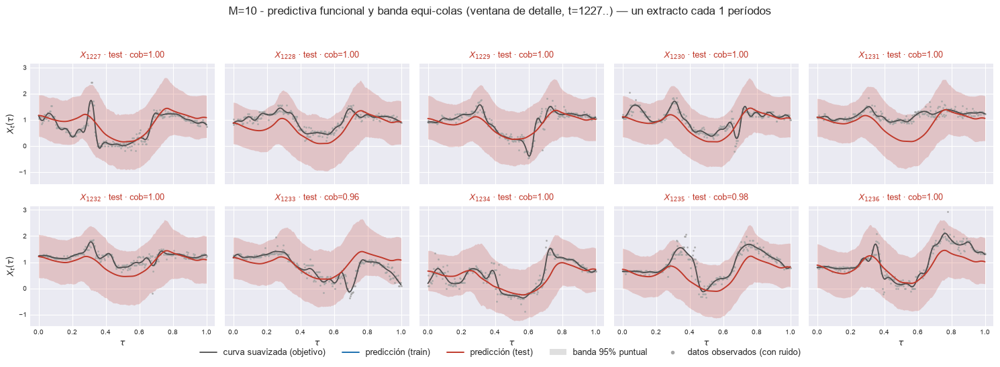

In [15]:
# Los N_DETALLE orígenes de la ventana de detalle (§3.2).
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[IDX_DET], e["X_pred"][IDX_DET], e["li_f"][IDX_DET], e["ls_f"][IDX_DET],
        grilla, T0, t=T_DET, cada=1, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[IDX_DET],
        title=f"M={M} - predictiva funcional y banda equi-colas (ventana de detalle, t={T0_DET}..)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=0.972 rmse=0.3552


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=0.958 rmse=0.3392


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=0.955 rmse=0.3054


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.771 rmse=0.5362


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.635 rmse=0.7699


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=0.986 rmse=0.3283


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.771 rmse=0.4993


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.914 test=0.797 (nominal 0.95)


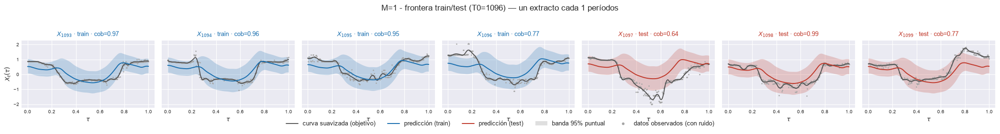

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=0.962 rmse=0.3914


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.333


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=0.972 rmse=0.3049


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.917 rmse=0.5011


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.740 rmse=0.6847


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2726


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.726 rmse=0.5227


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.963 test=0.822 (nominal 0.95)


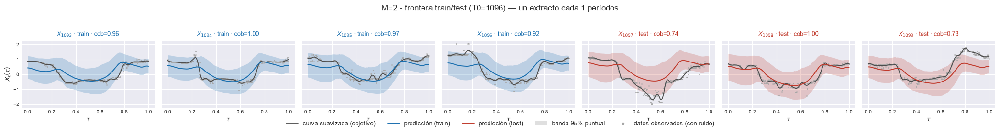

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3982


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.3373


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.2871


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.920 rmse=0.5113


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.774 rmse=0.6775


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.3014


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.851 rmse=0.4814


[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.980 test=0.875 (nominal 0.95)


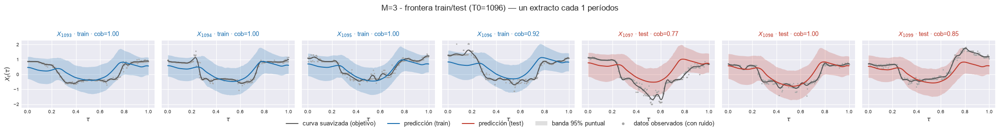

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3989


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2954


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.2476


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.955 rmse=0.4614


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.826 rmse=0.6525


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2782


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.816 rmse=0.4753


[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.989 test=0.881 (nominal 0.95)


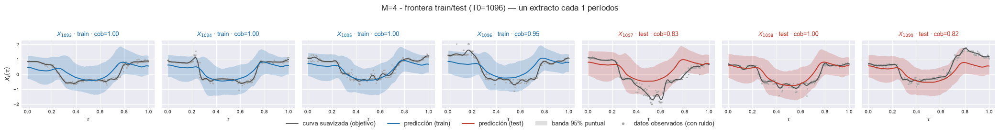

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3056


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.1828


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1558


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.979 rmse=0.409


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.806 rmse=0.6329


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2529


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.892 rmse=0.4658


[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.995 test=0.899 (nominal 0.95)


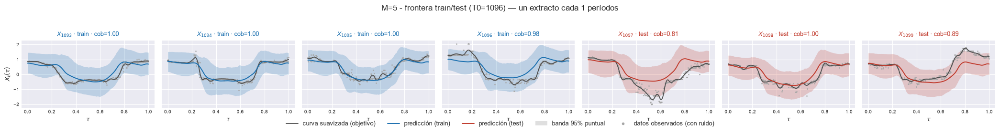

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.2977


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.1877


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1578


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=0.976 rmse=0.4065


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.806 rmse=0.6358


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2425


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.955 rmse=0.4663


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.994 test=0.920 (nominal 0.95)


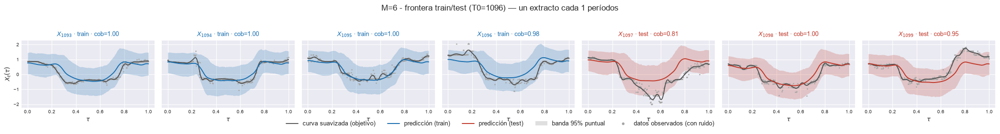

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3266


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2003


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1558


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.4347


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.774 rmse=0.6712


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2856


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.962 rmse=0.4415


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=0.912 (nominal 0.95)


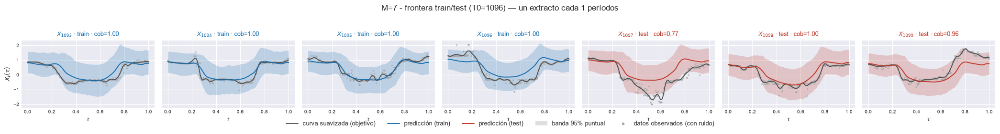

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.314


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2088


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1555


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.433


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.792 rmse=0.674


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.3141


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.972 rmse=0.4383


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=0.921 (nominal 0.95)


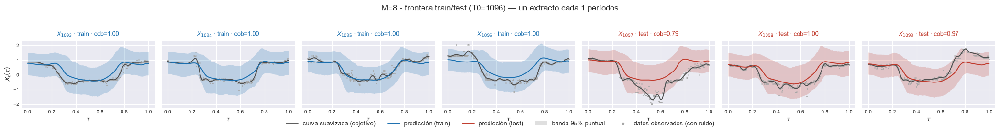

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3122


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2108


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1678


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.4217


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.826 rmse=0.6347


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2968


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=0.962 rmse=0.4489


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=1.000 test=0.929 (nominal 0.95)


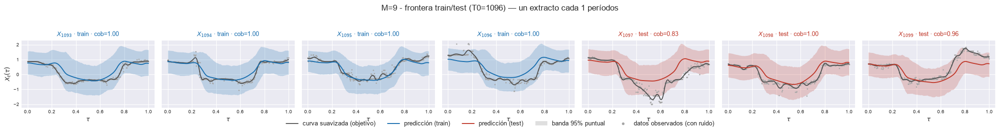

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=1093 [train] cob=1.000 rmse=0.3063


  2/7 (28.6%) t=0.0s eta=0.0s  t=1094 [train] cob=1.000 rmse=0.2095


  3/7 (42.9%) t=0.0s eta=0.0s  t=1095 [train] cob=1.000 rmse=0.1642


  4/7 (57.1%) t=0.0s eta=0.0s  t=1096 [train] cob=1.000 rmse=0.4246


  5/7 (71.4%) t=0.0s eta=0.0s  t=1097 [test] cob=0.830 rmse=0.6414


  6/7 (85.7%) t=0.0s eta=0.0s  t=1098 [test] cob=1.000 rmse=0.2952


  7/7 (100.0%) t=0.0s eta=0.0s  t=1099 [test] cob=1.000 rmse=0.4556


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=1.000 test=0.943 (nominal 0.95)


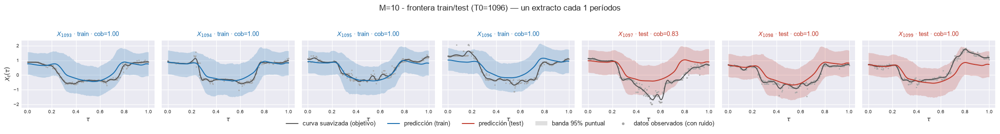

In [16]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.825109


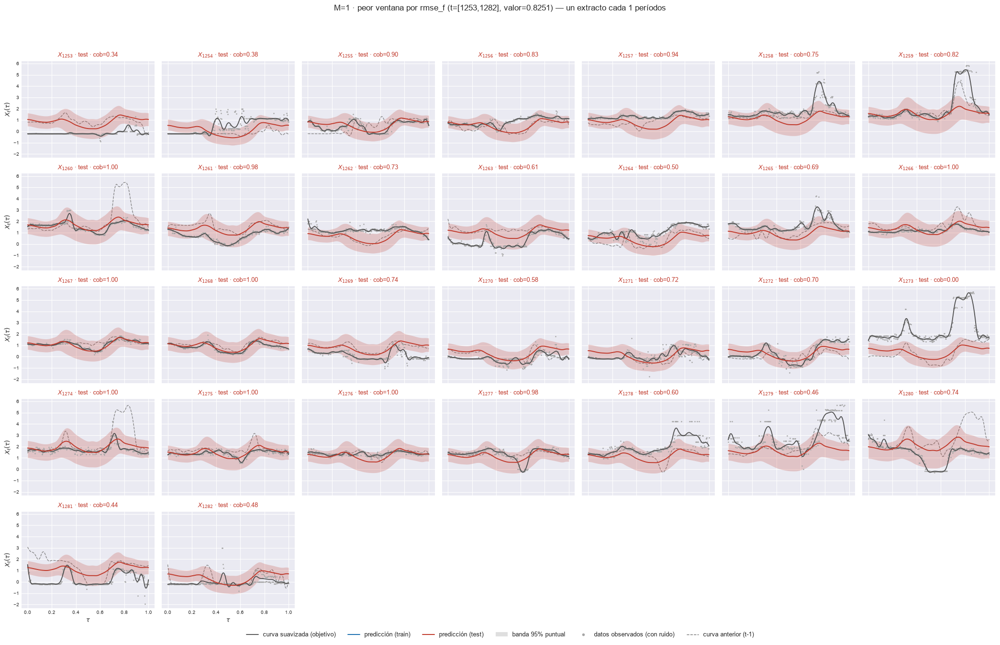

    t=[1252, 1281]  rmse_f=0.821358


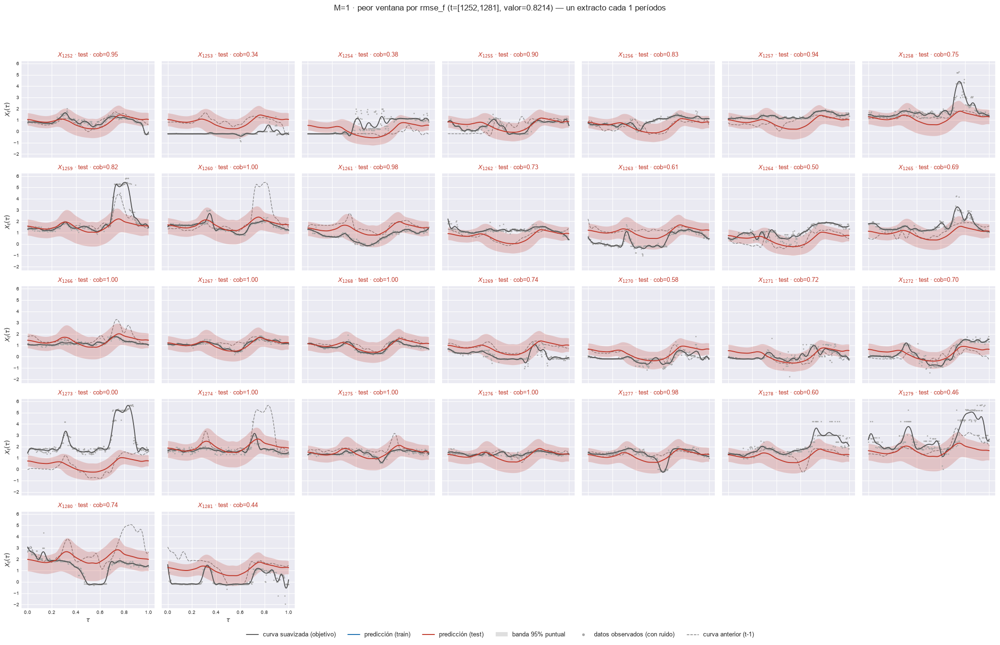

    t=[1257, 1286]  rmse_f=0.816109


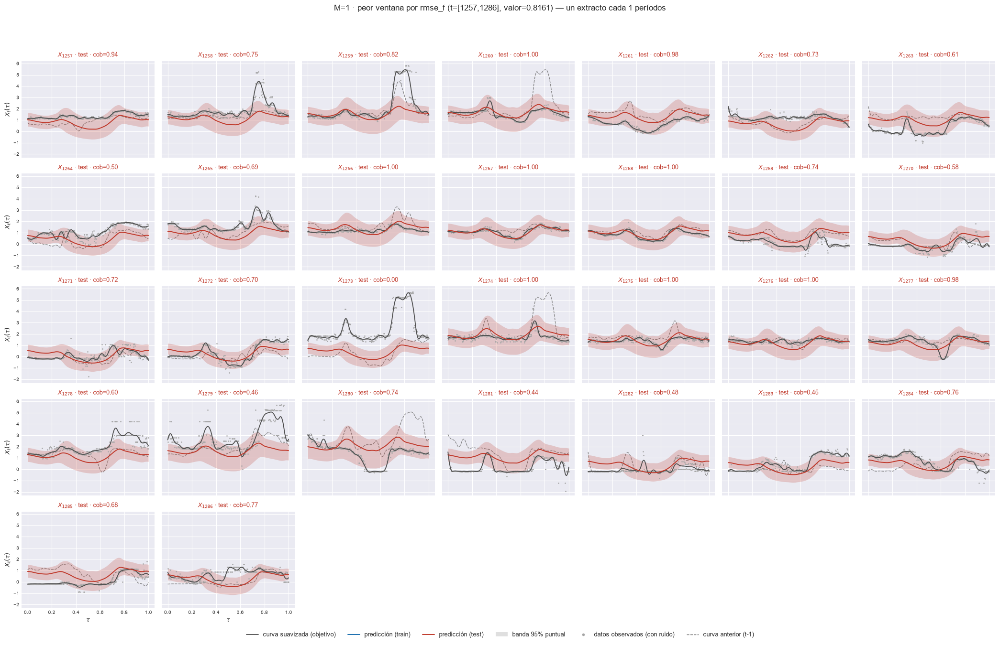

    t=[1258, 1287]  rmse_f=0.813166


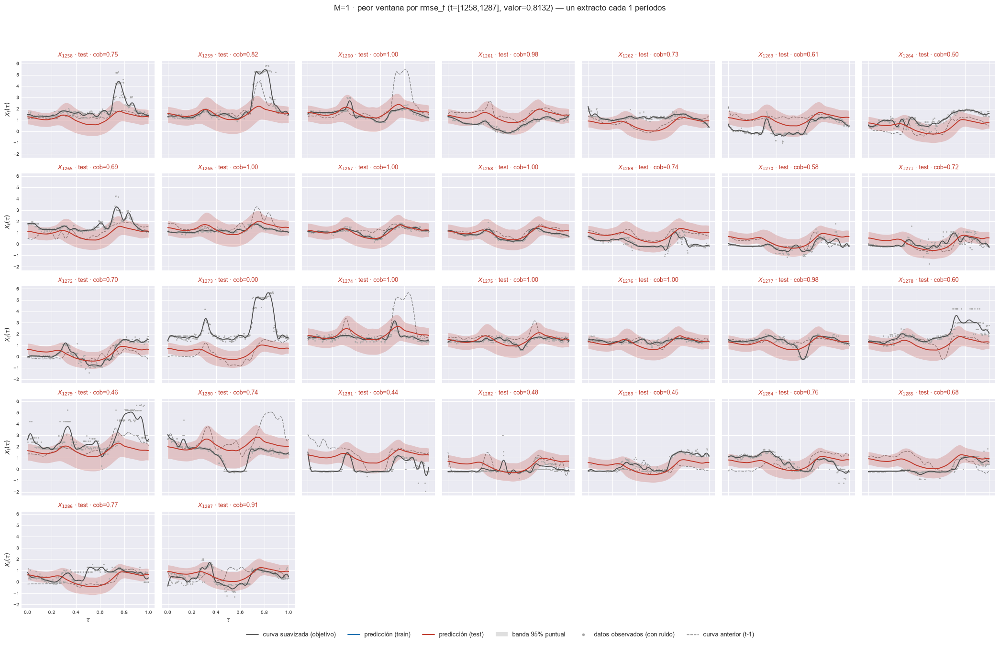

    t=[1256, 1285]  rmse_f=0.811707


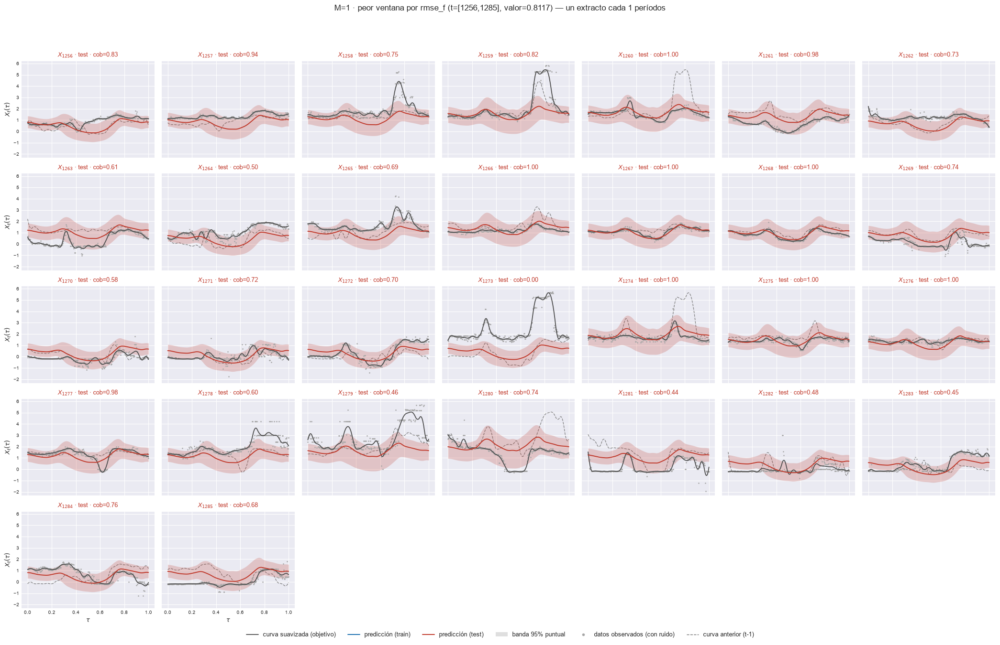

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.816734


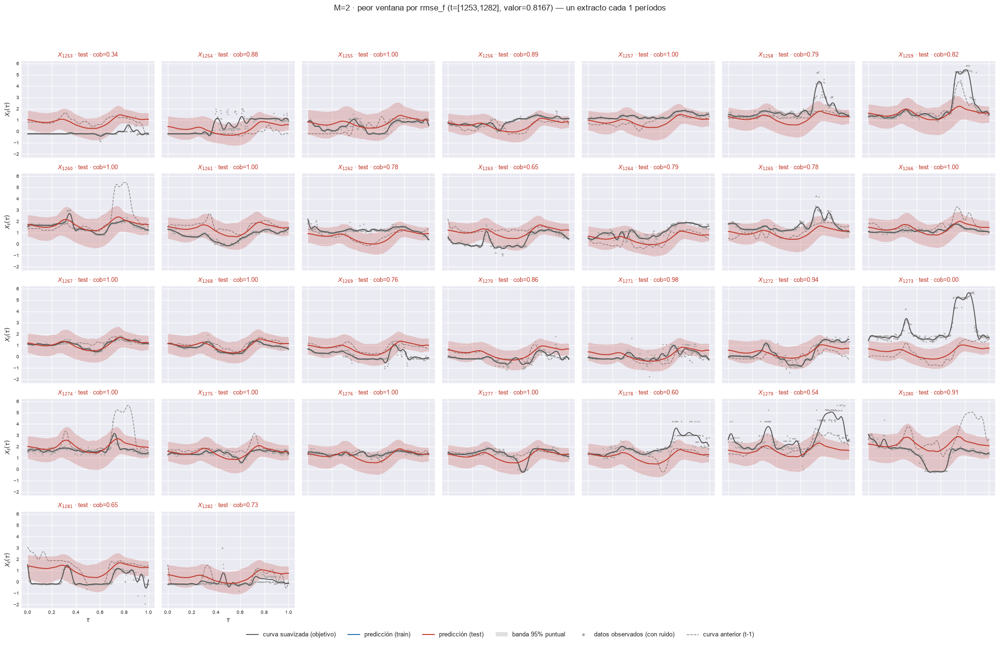

    t=[1252, 1281]  rmse_f=0.812516


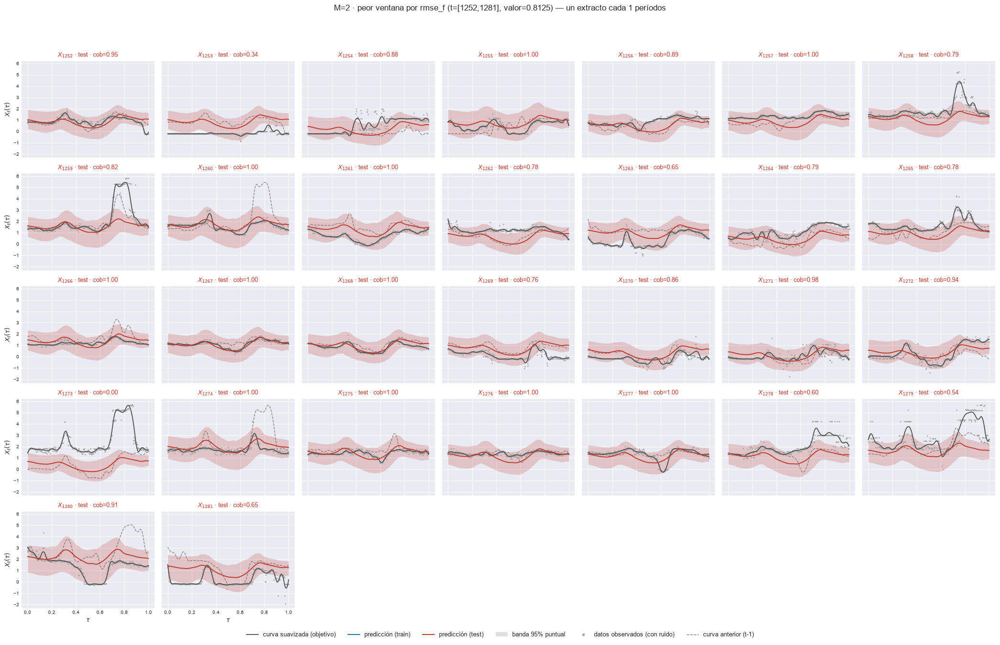

    t=[1258, 1287]  rmse_f=0.806430


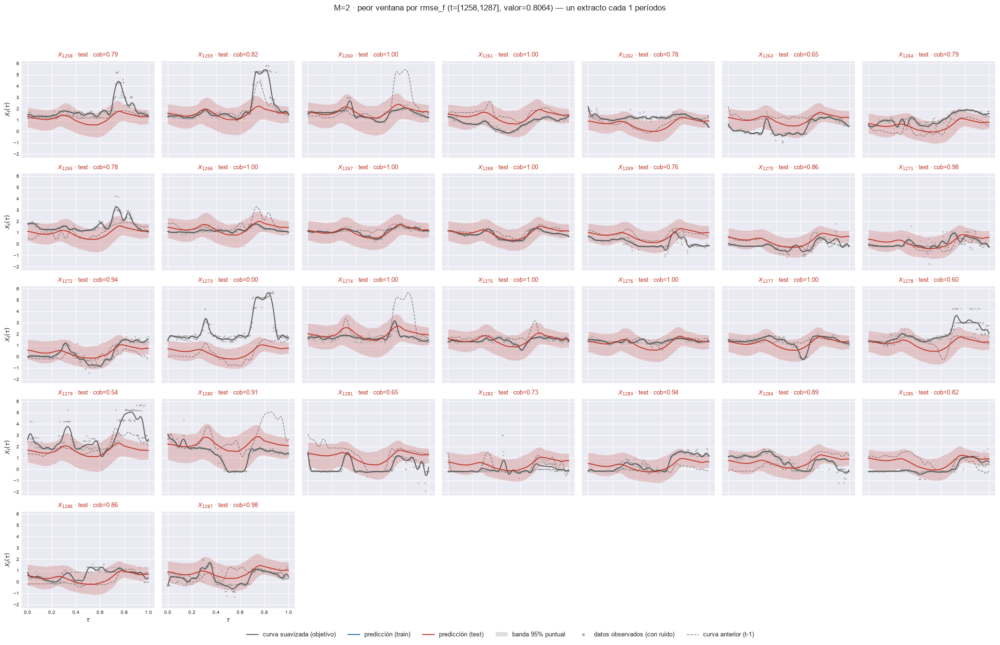

    t=[1257, 1286]  rmse_f=0.805852


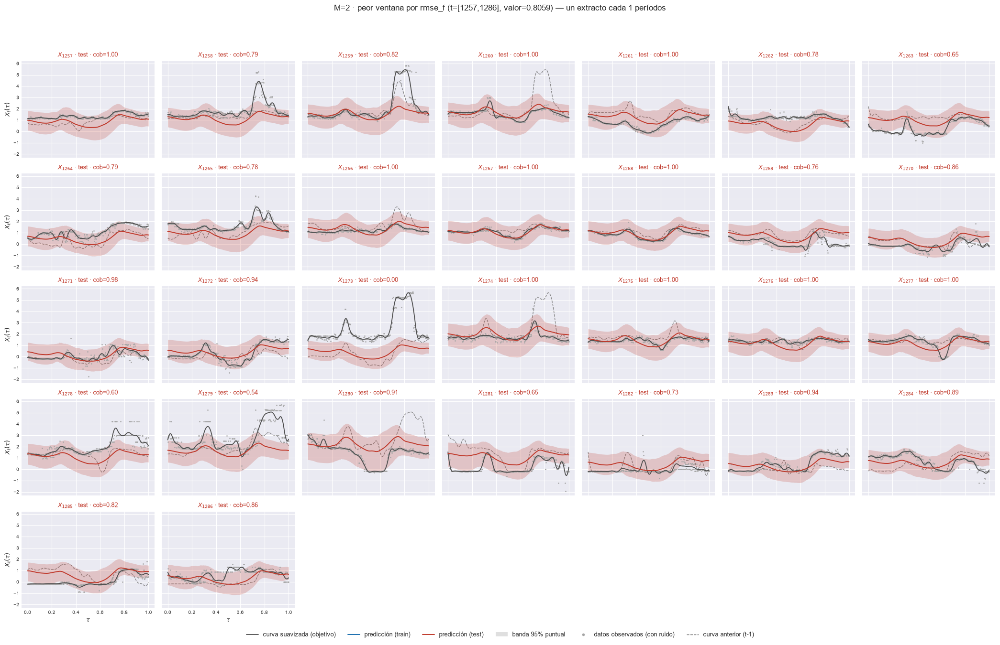

    t=[1256, 1285]  rmse_f=0.803629


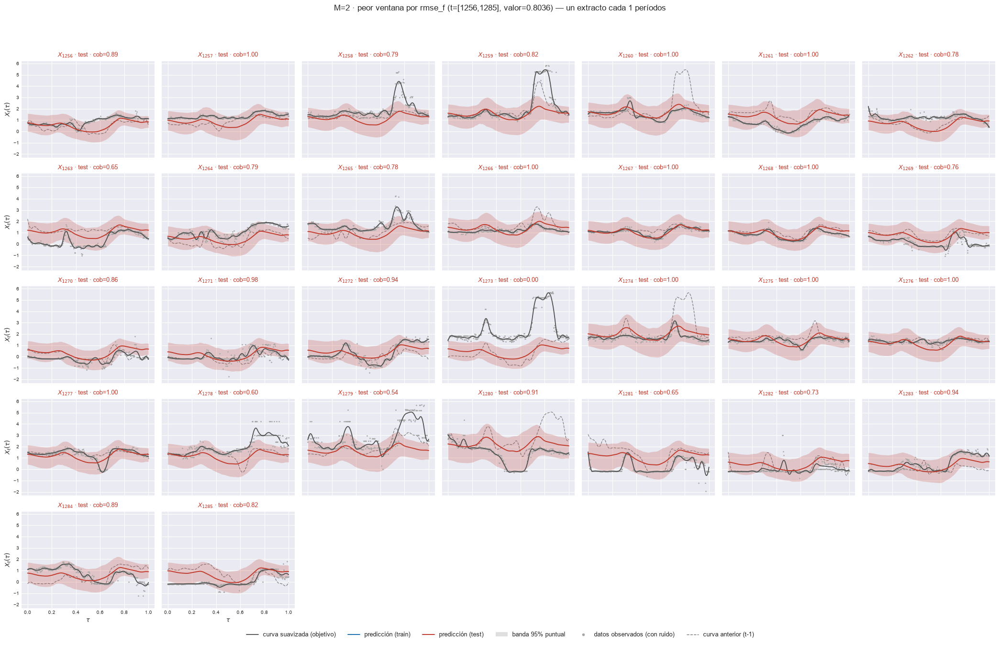

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.778506


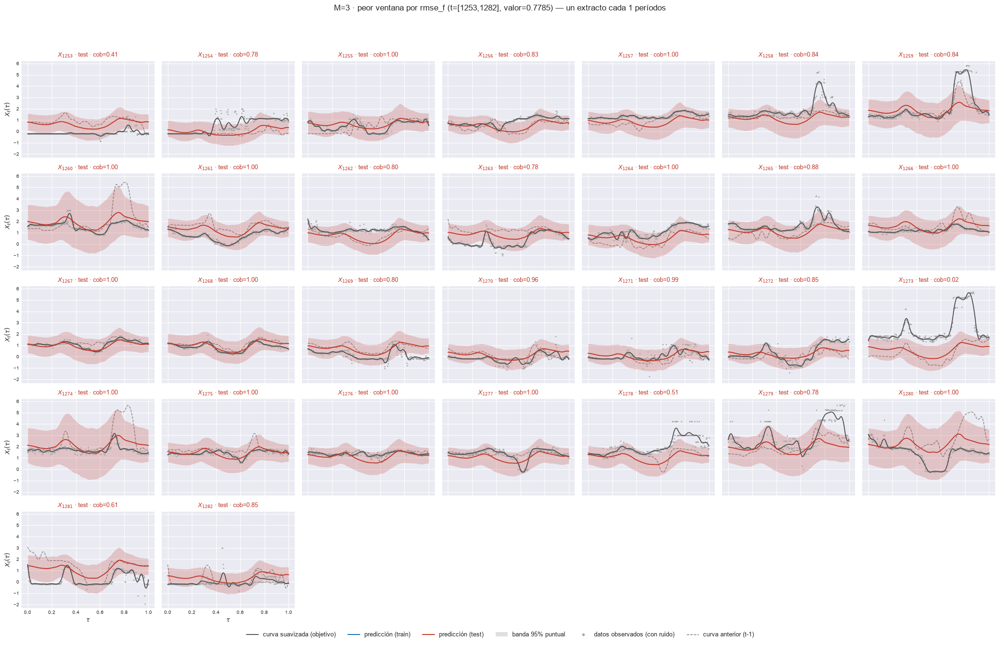

    t=[1252, 1281]  rmse_f=0.775759


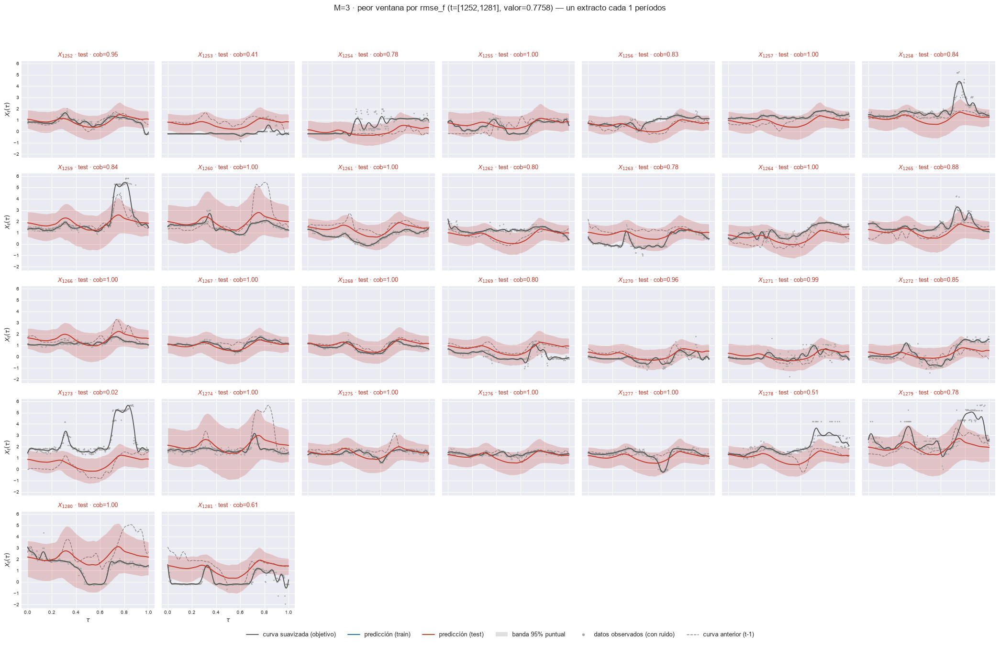

    t=[1254, 1283]  rmse_f=0.771473


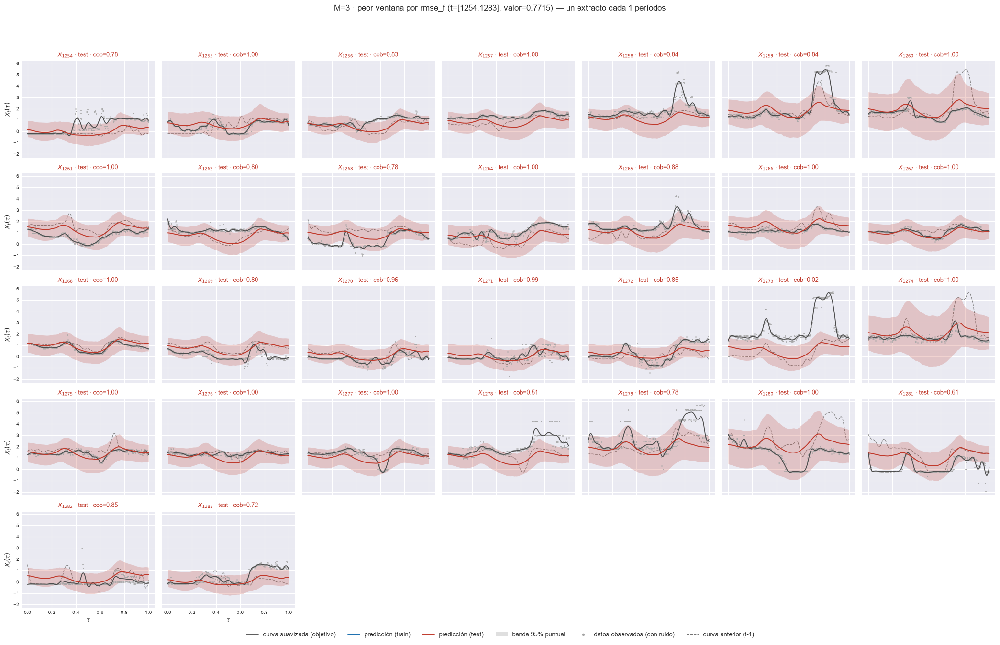

    t=[1257, 1286]  rmse_f=0.770216


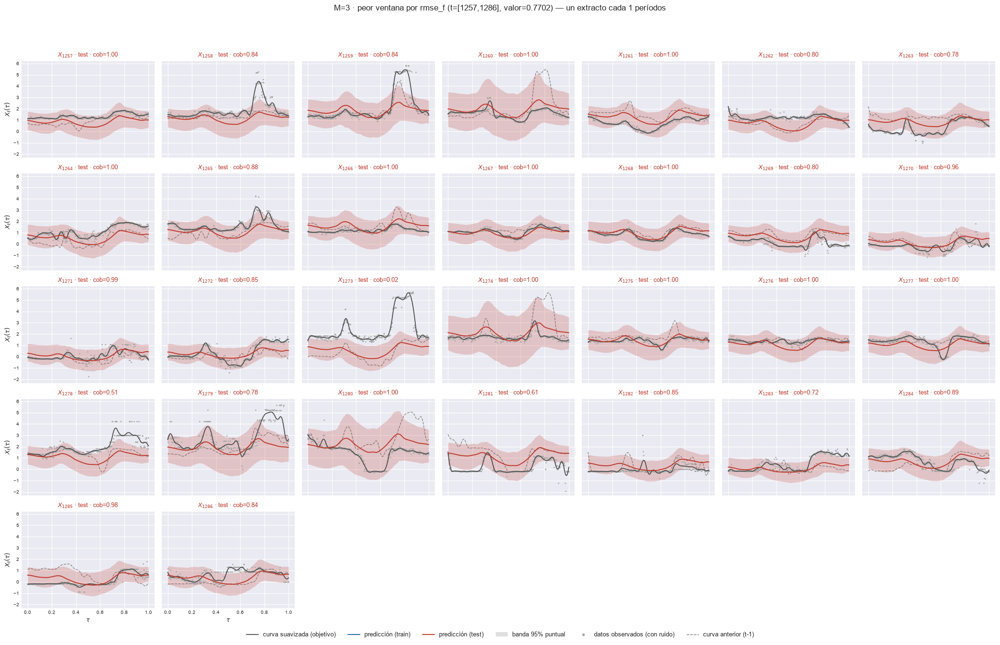

    t=[1256, 1285]  rmse_f=0.768392


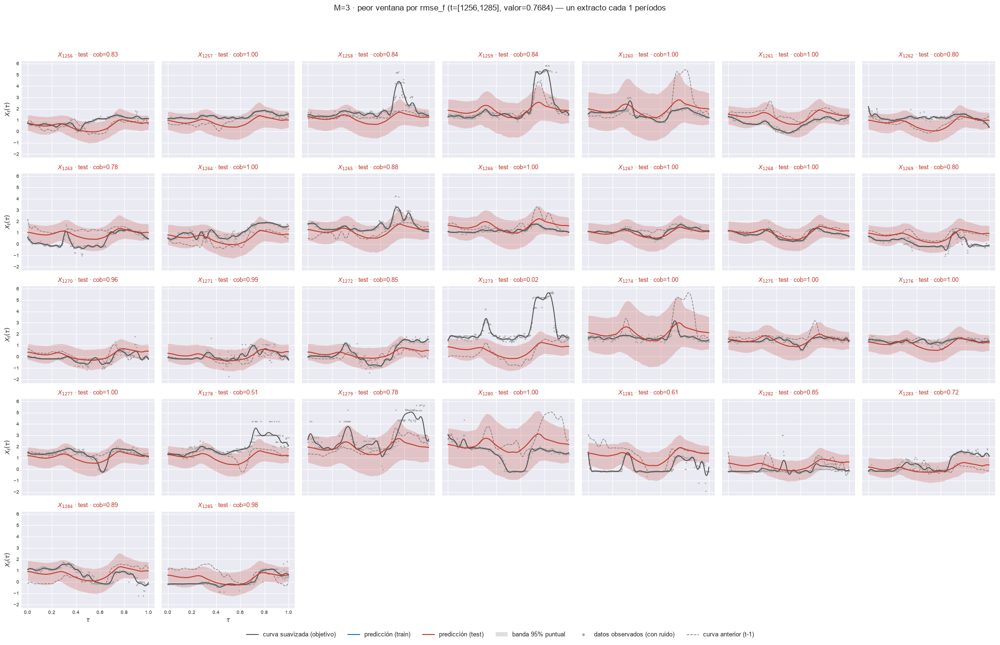

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.766530


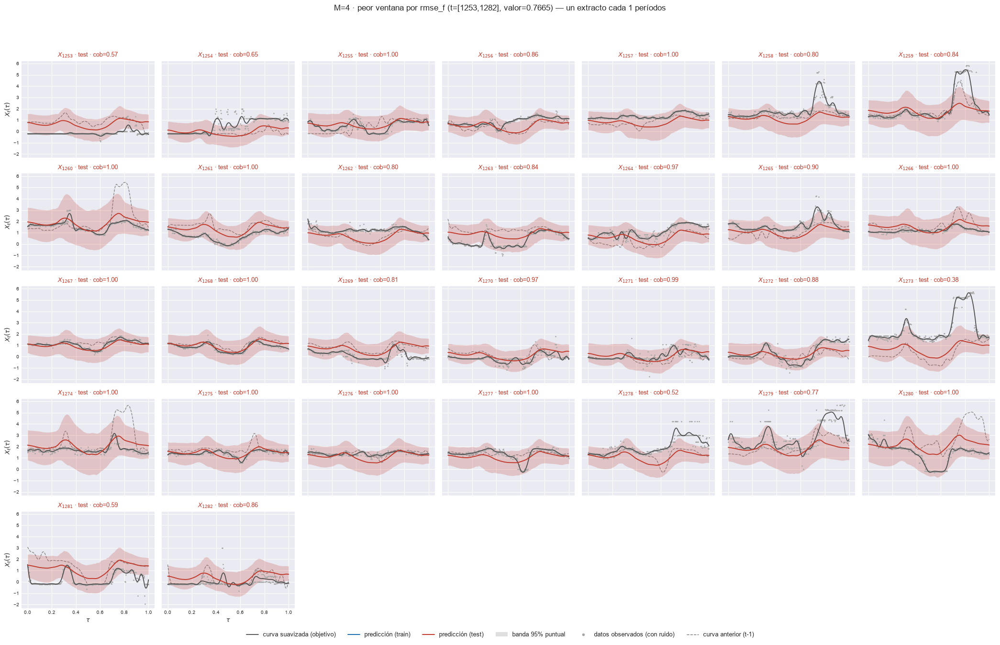

    t=[1252, 1281]  rmse_f=0.762741


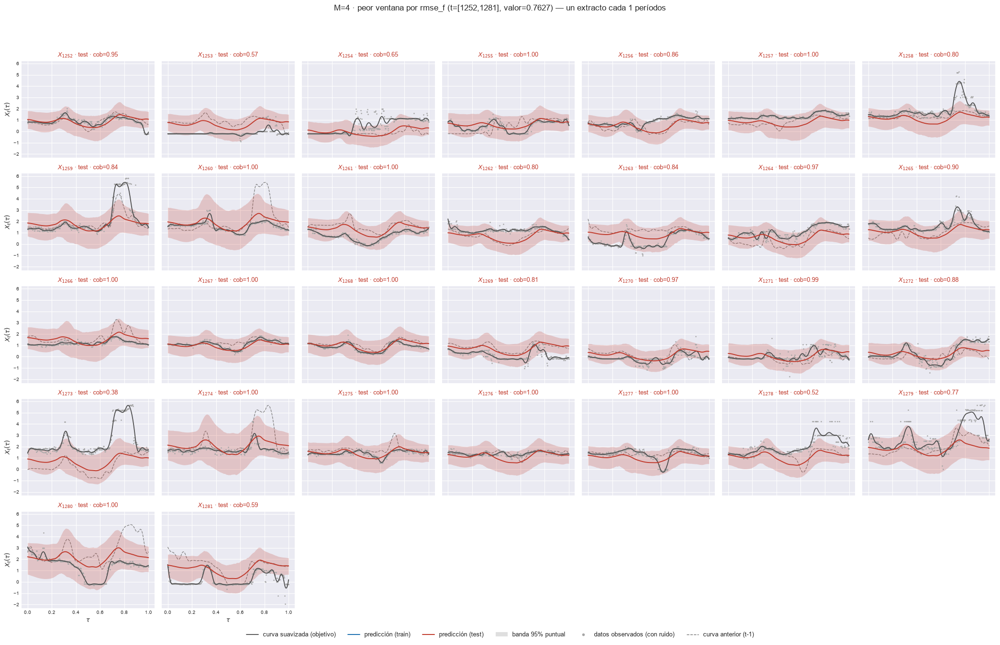

    t=[1254, 1283]  rmse_f=0.759364


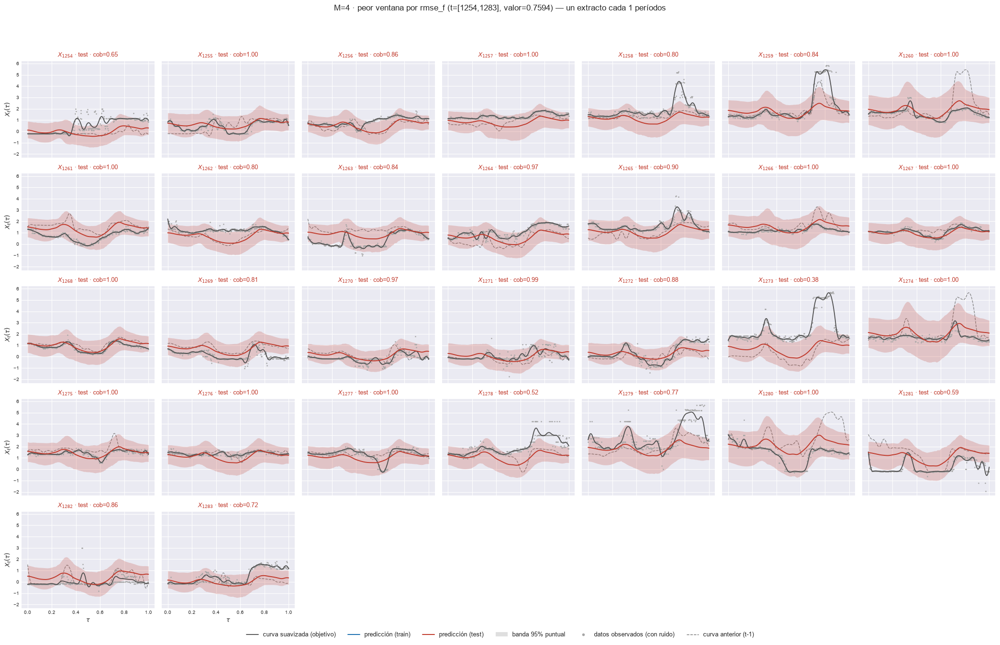

    t=[1257, 1286]  rmse_f=0.756561


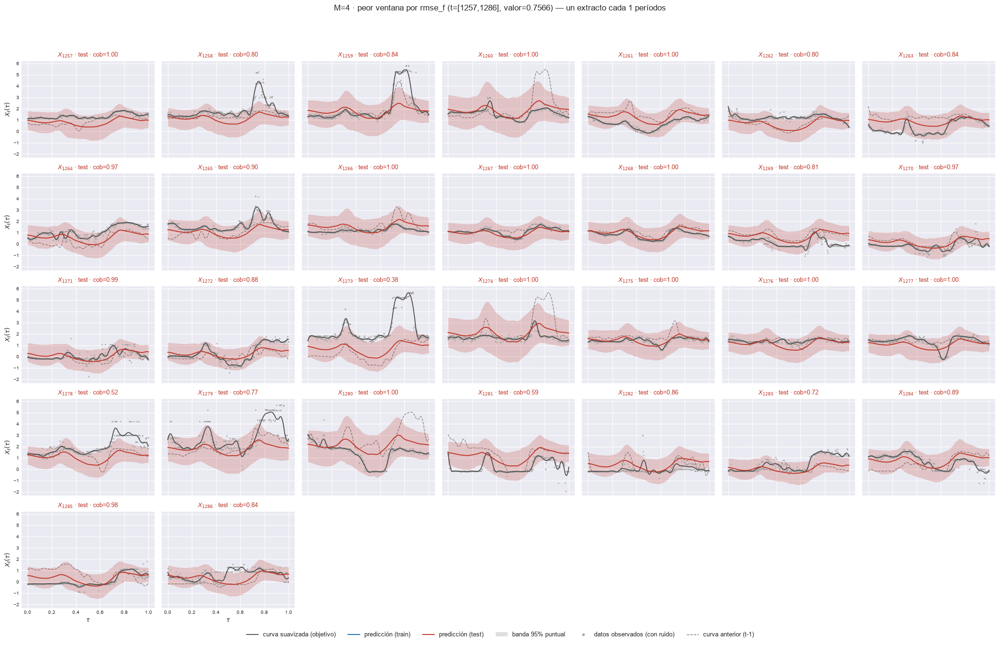

    t=[1256, 1285]  rmse_f=0.755122


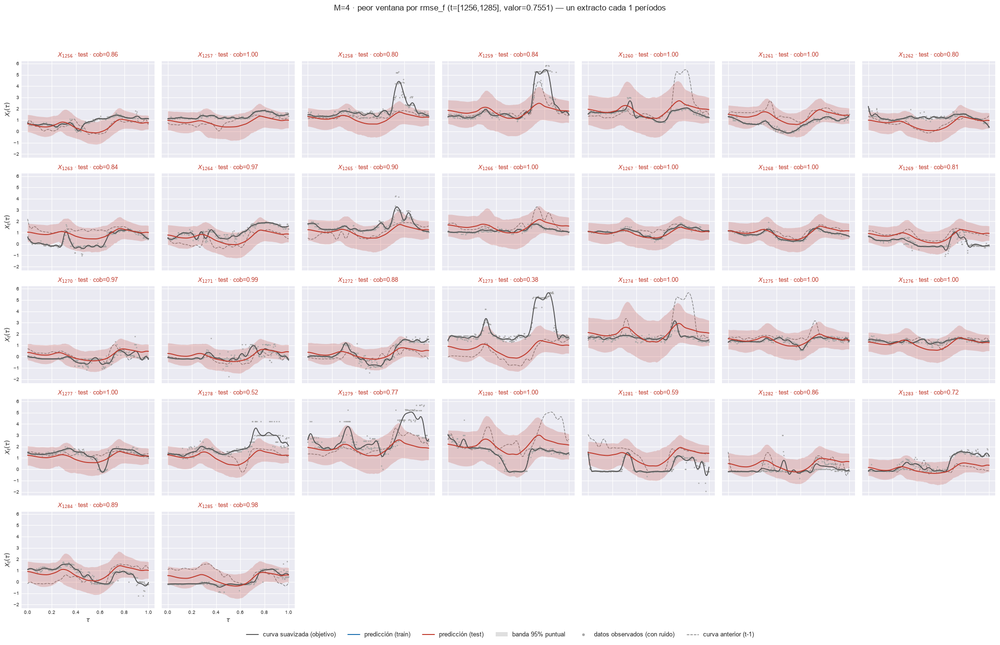

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.745494


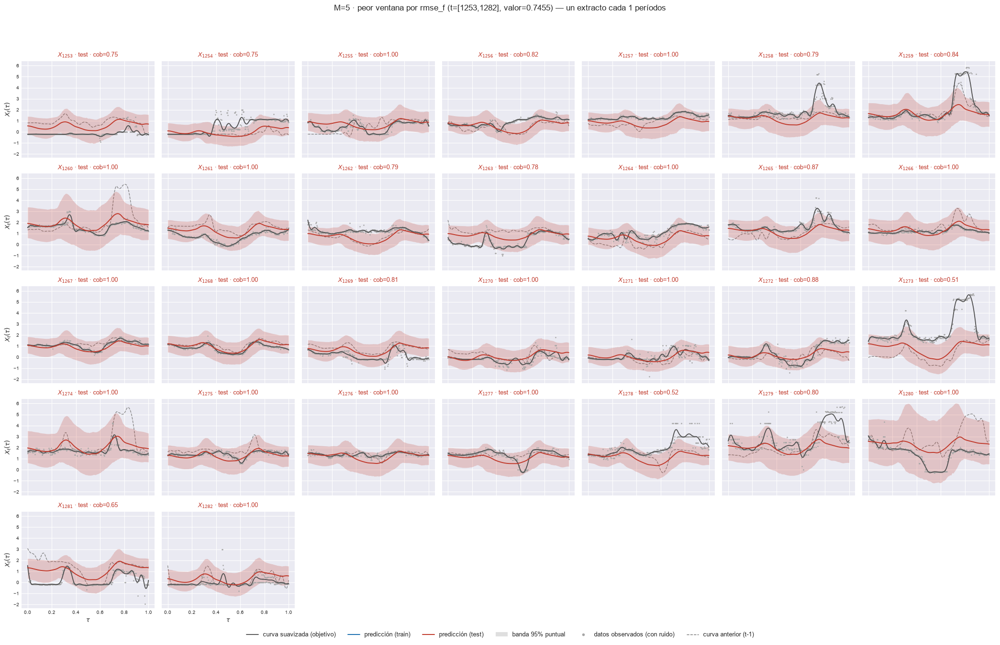

    t=[1252, 1281]  rmse_f=0.742622


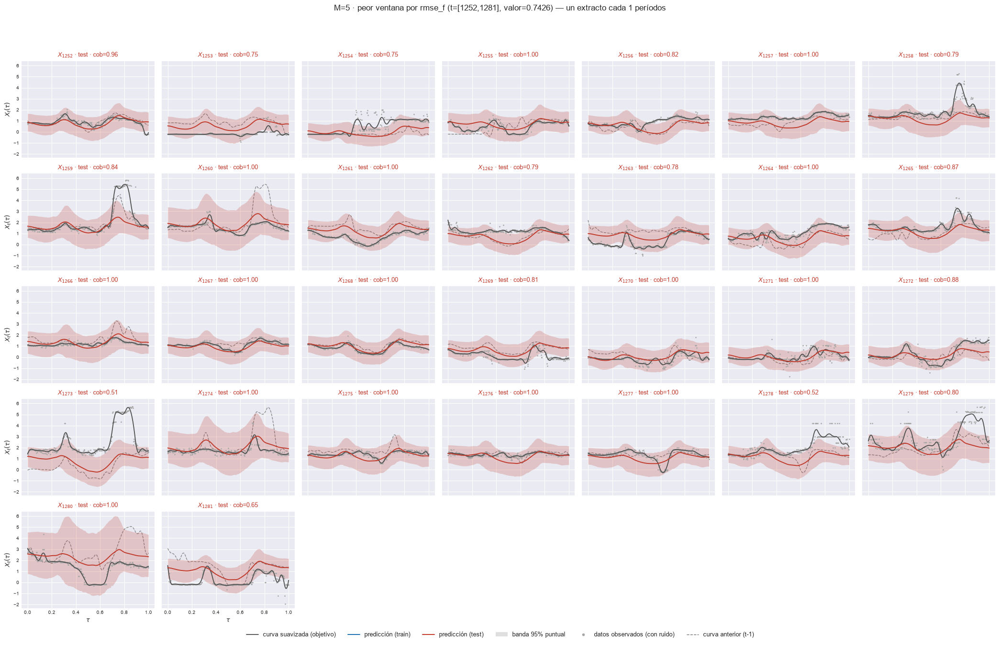

    t=[1254, 1283]  rmse_f=0.741089


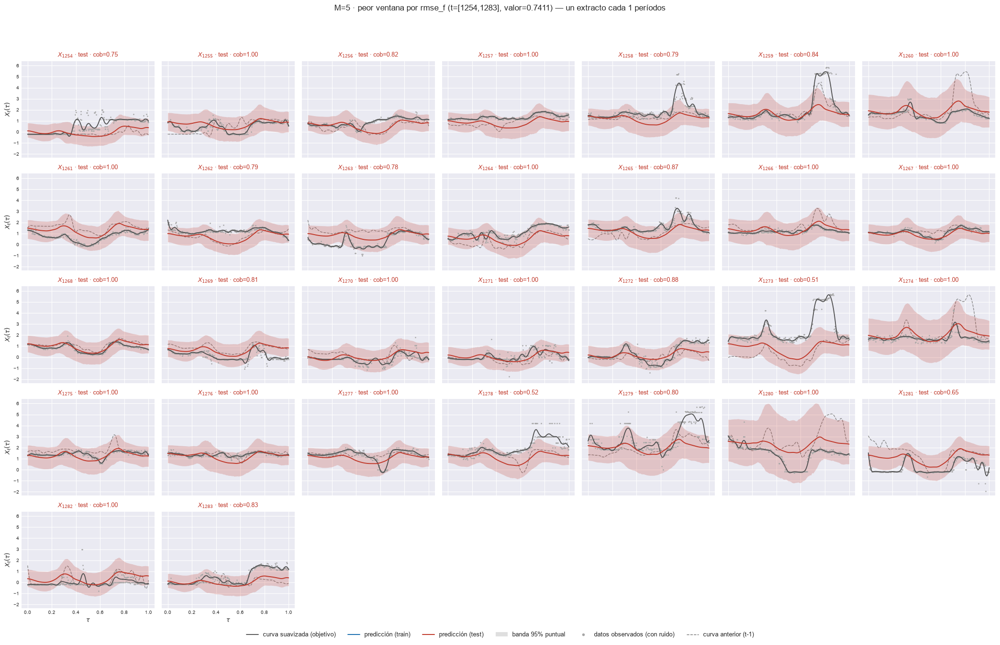

    t=[1257, 1286]  rmse_f=0.737506


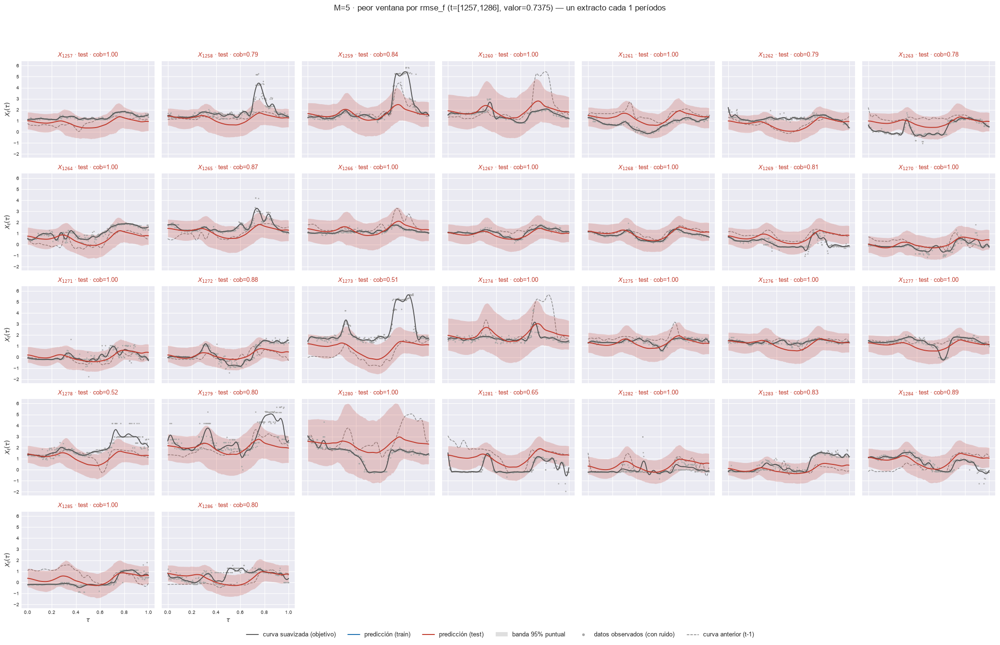

    t=[1255, 1284]  rmse_f=0.734916


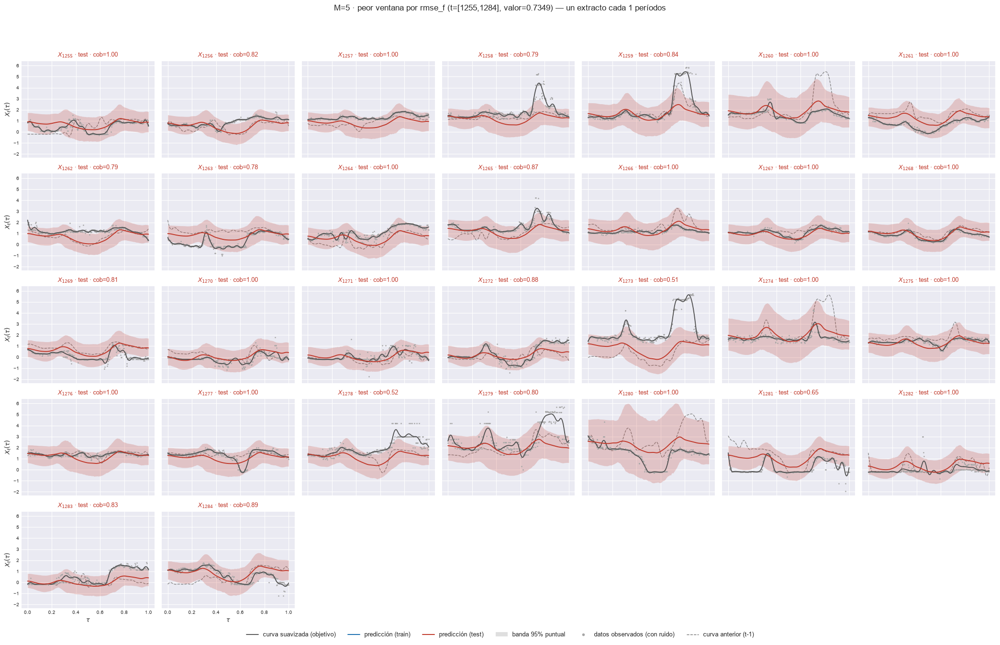

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.747483


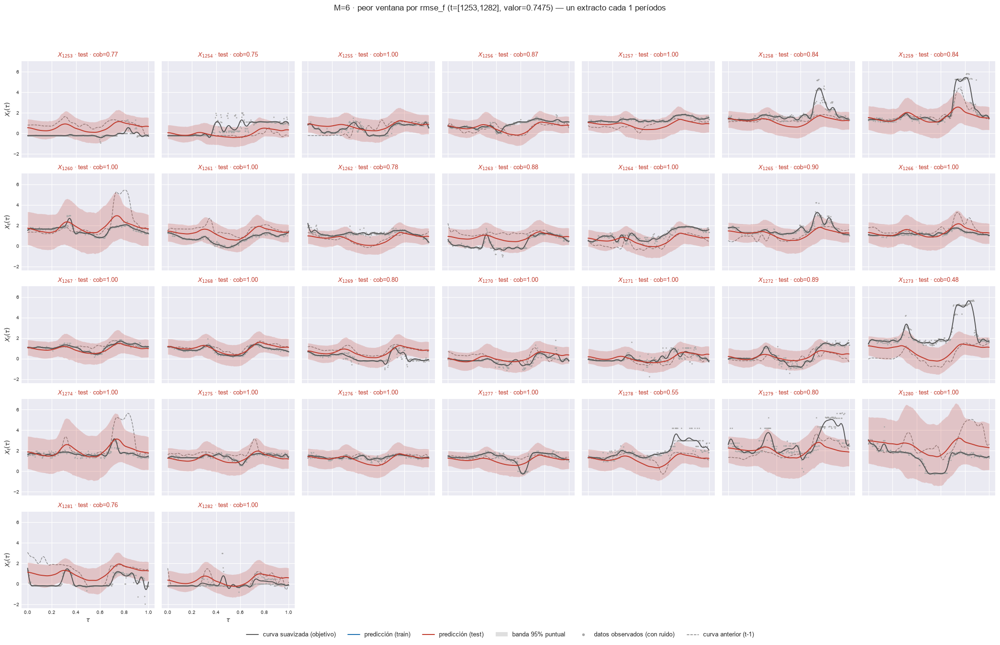

    t=[1252, 1281]  rmse_f=0.744279


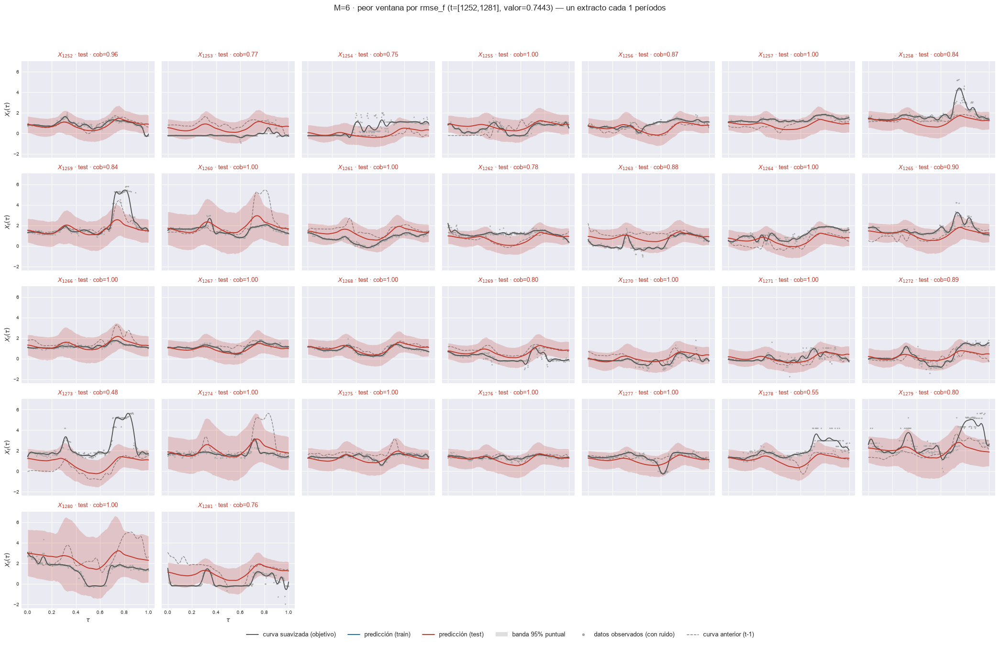

    t=[1254, 1283]  rmse_f=0.742737


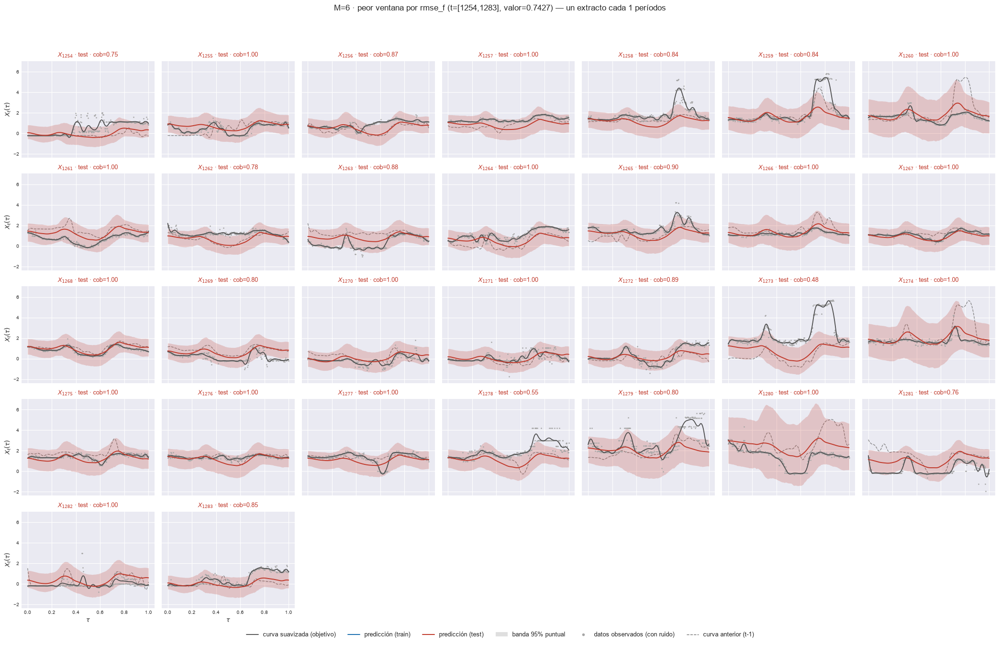

    t=[1257, 1286]  rmse_f=0.739683


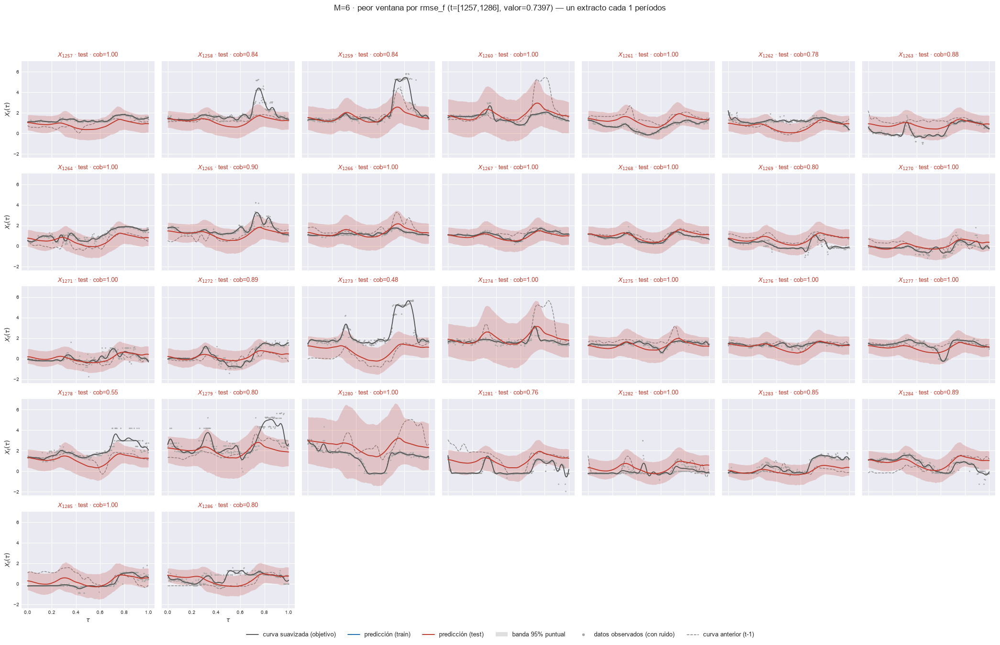

    t=[1258, 1287]  rmse_f=0.737409


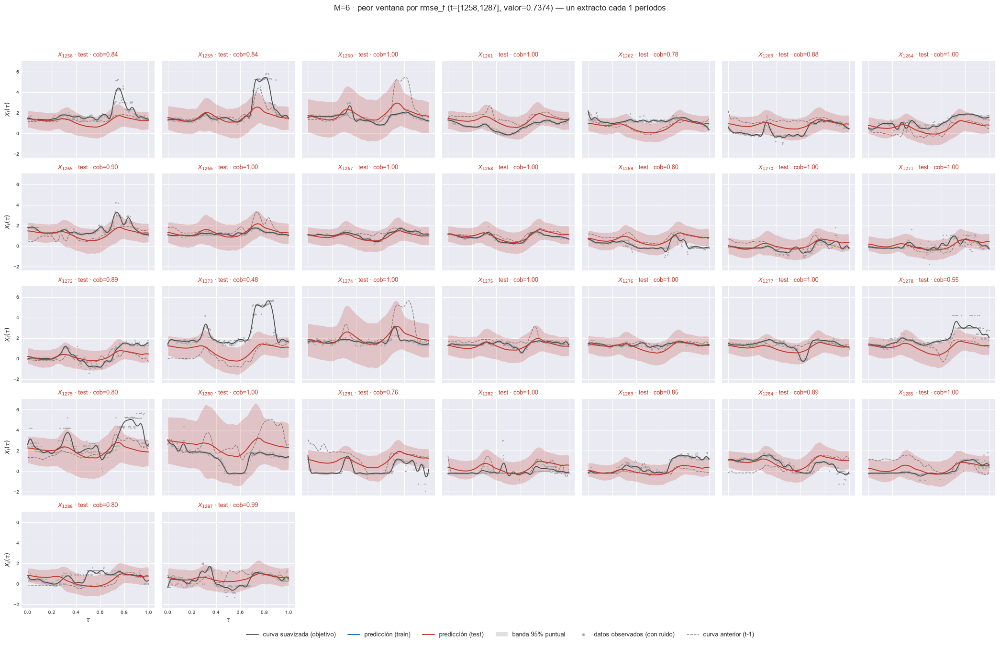

[M=7] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.764186


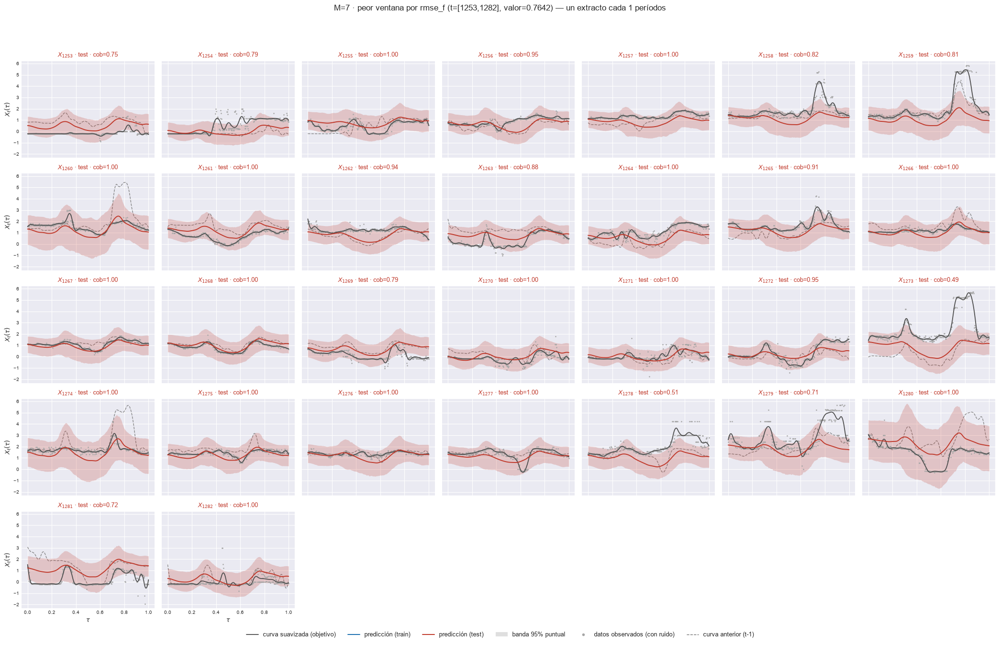

    t=[1252, 1281]  rmse_f=0.762269


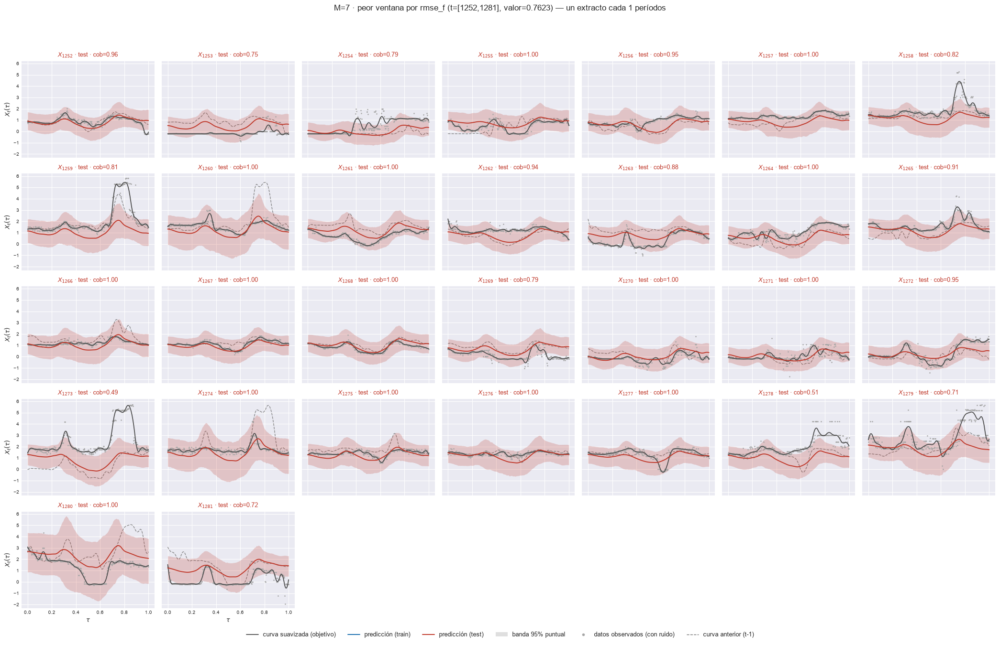

    t=[1254, 1283]  rmse_f=0.760900


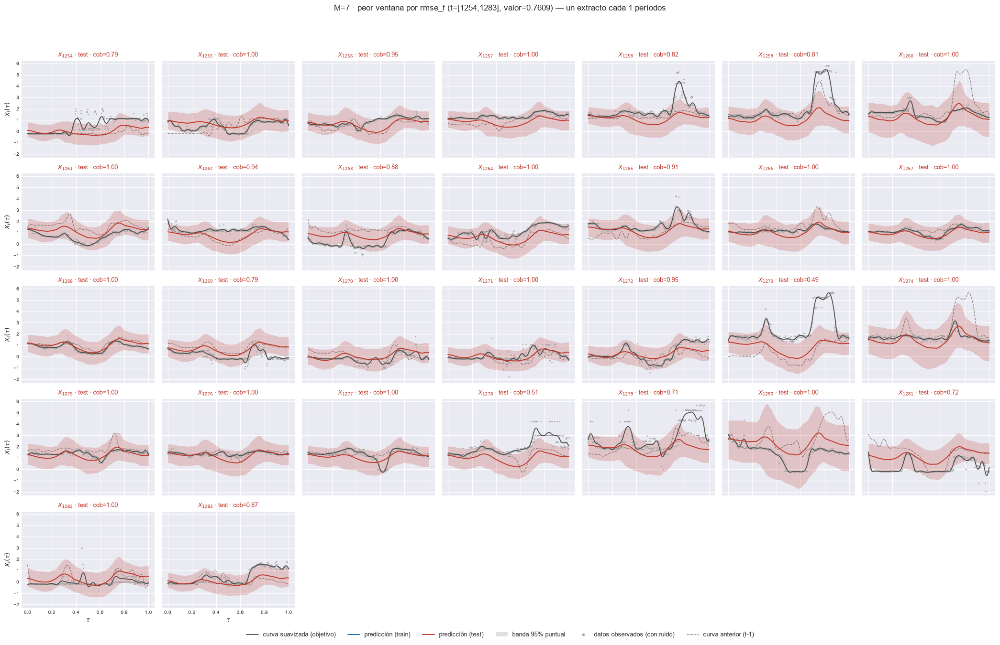

    t=[1257, 1286]  rmse_f=0.758265


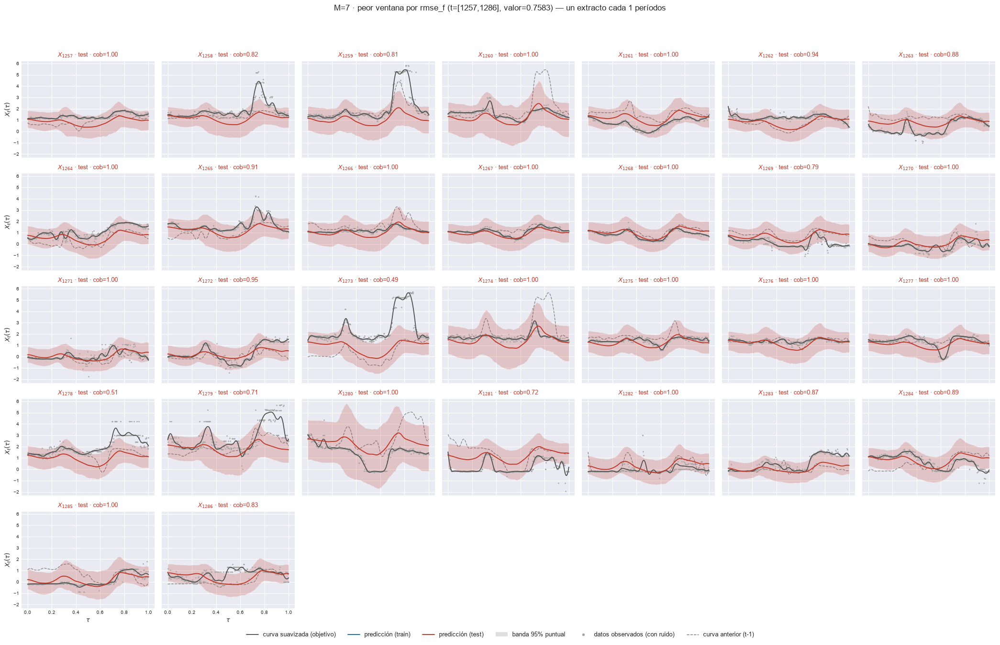

    t=[1258, 1287]  rmse_f=0.756232


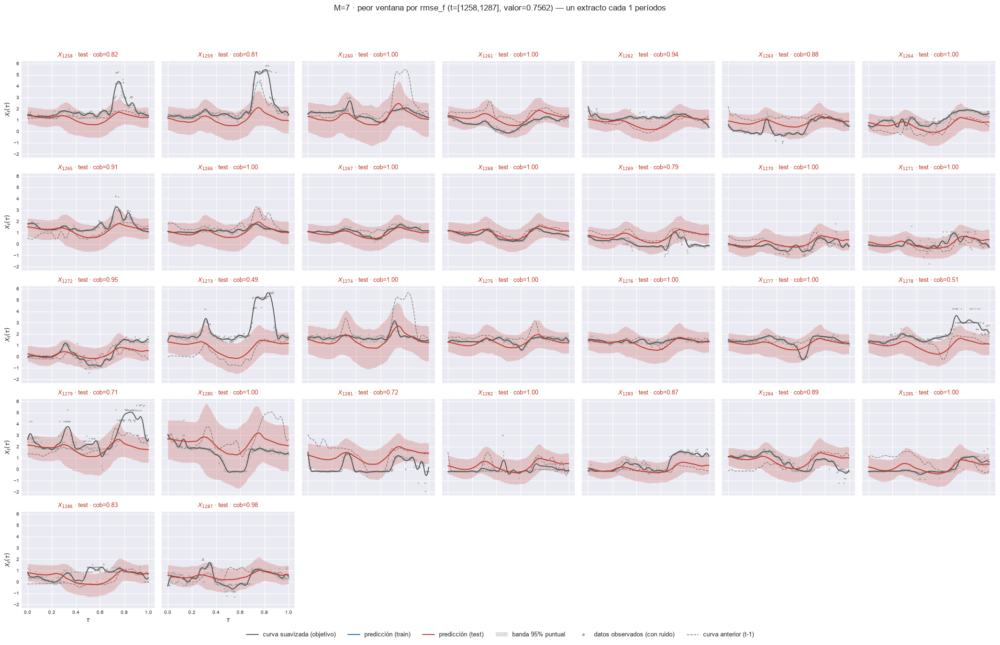

[M=8] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.759540


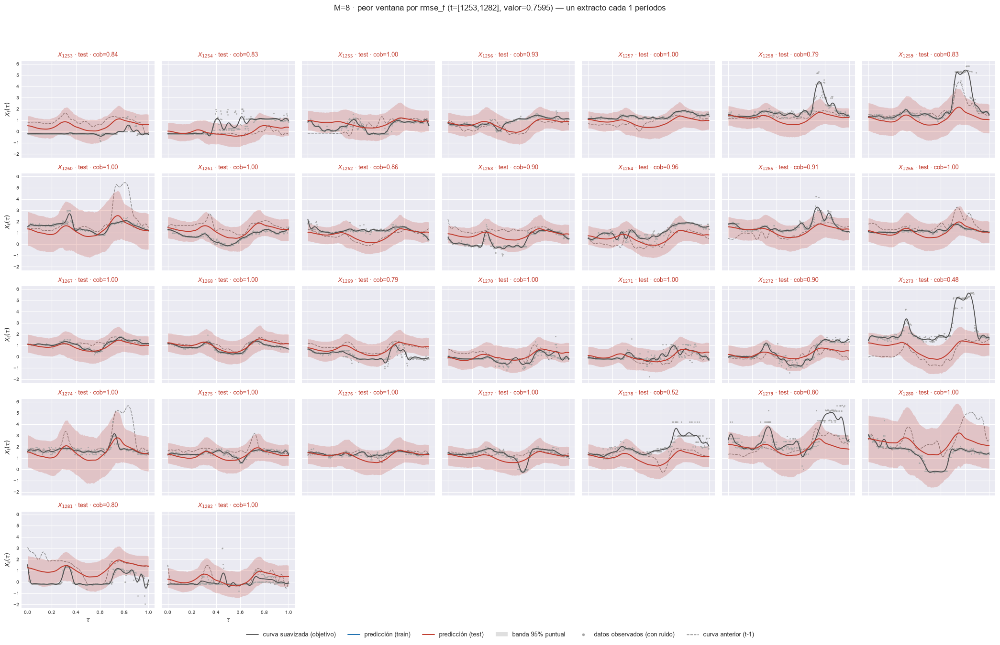

    t=[1252, 1281]  rmse_f=0.757688


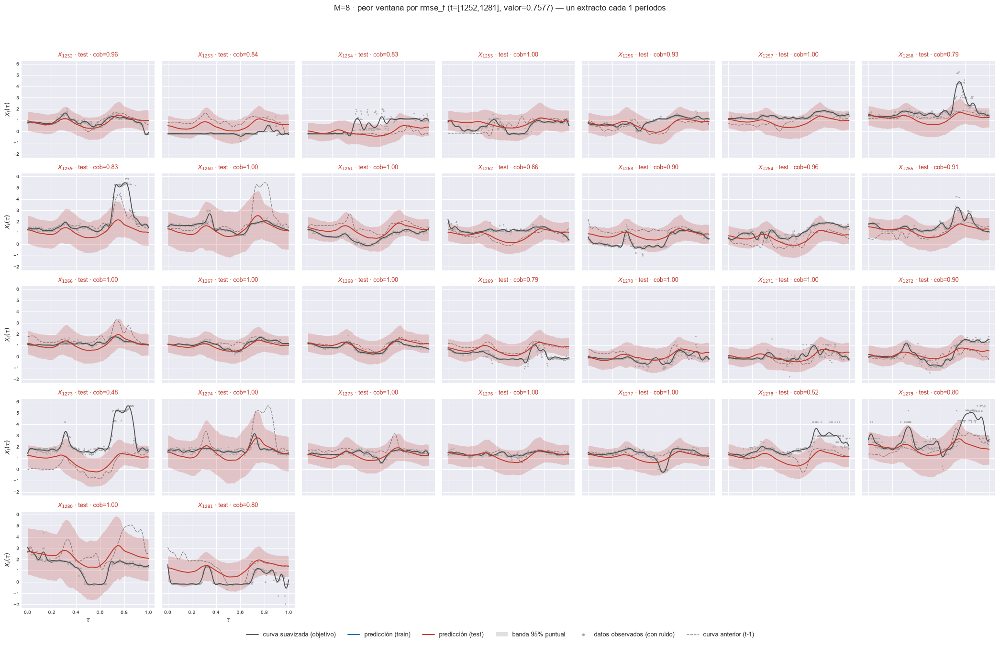

    t=[1254, 1283]  rmse_f=0.757056


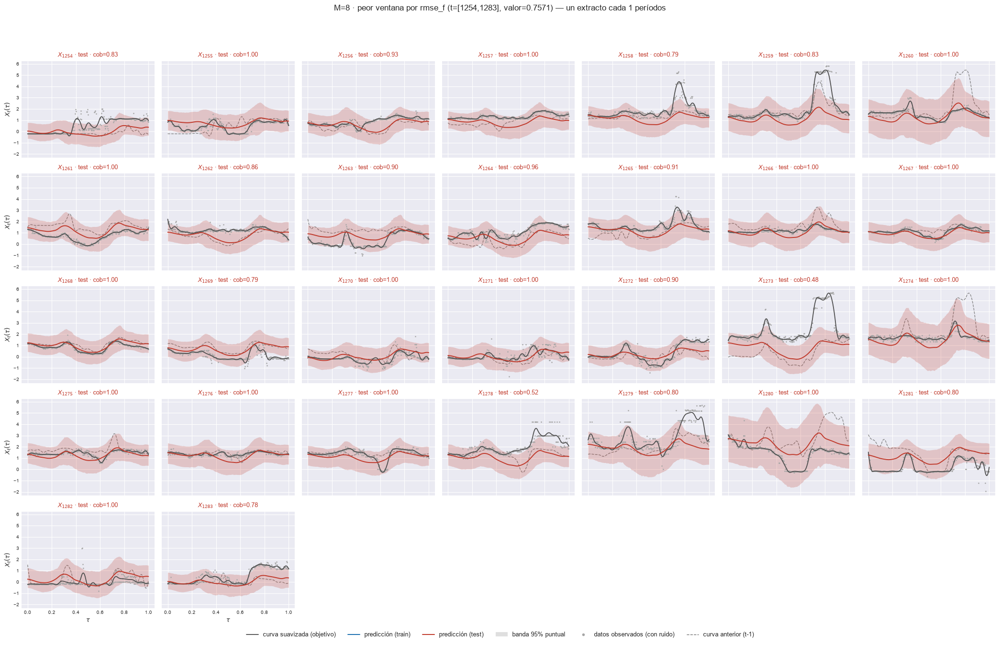

    t=[1257, 1286]  rmse_f=0.754104


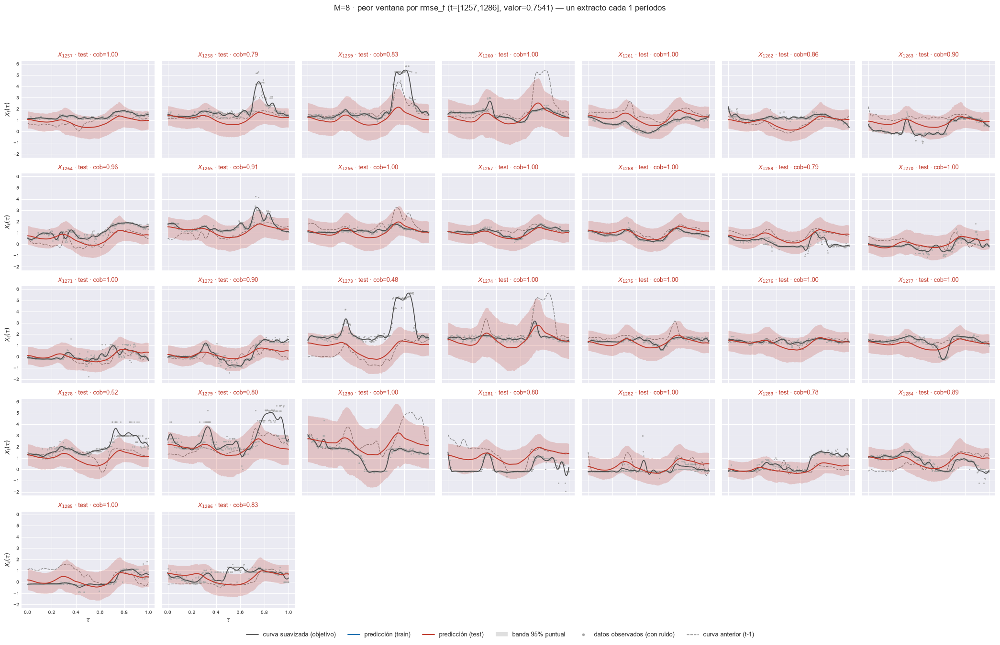

    t=[1255, 1284]  rmse_f=0.751551


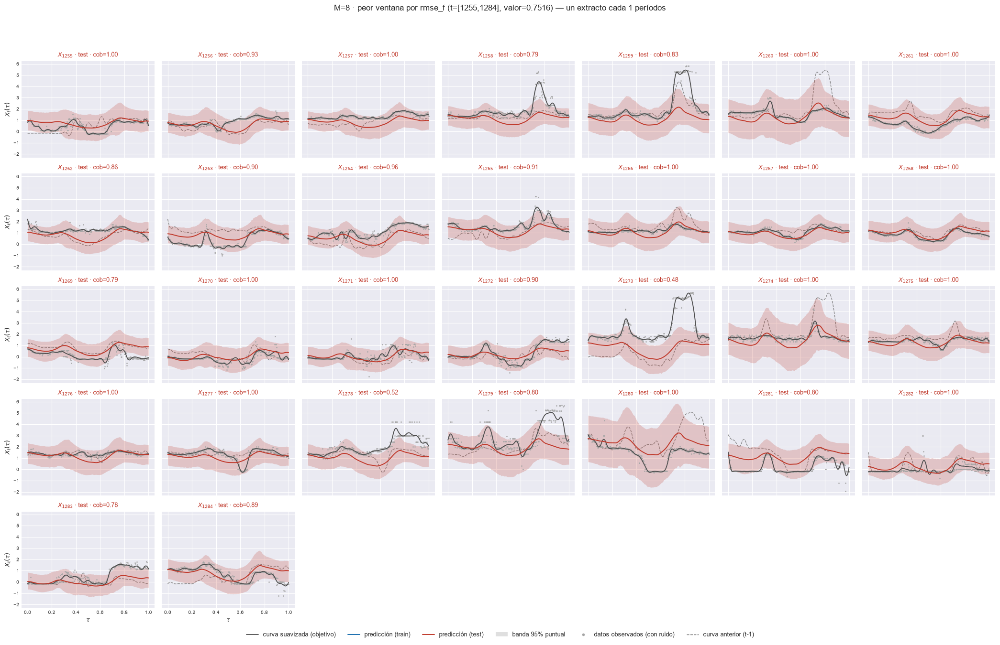

[M=9] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.766510


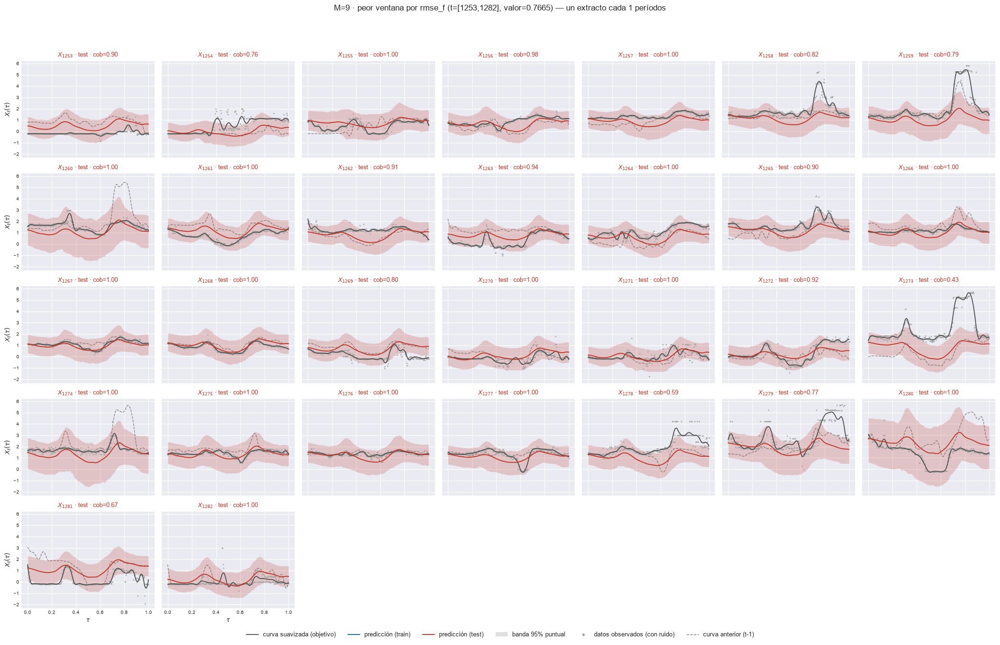

    t=[1252, 1281]  rmse_f=0.765112


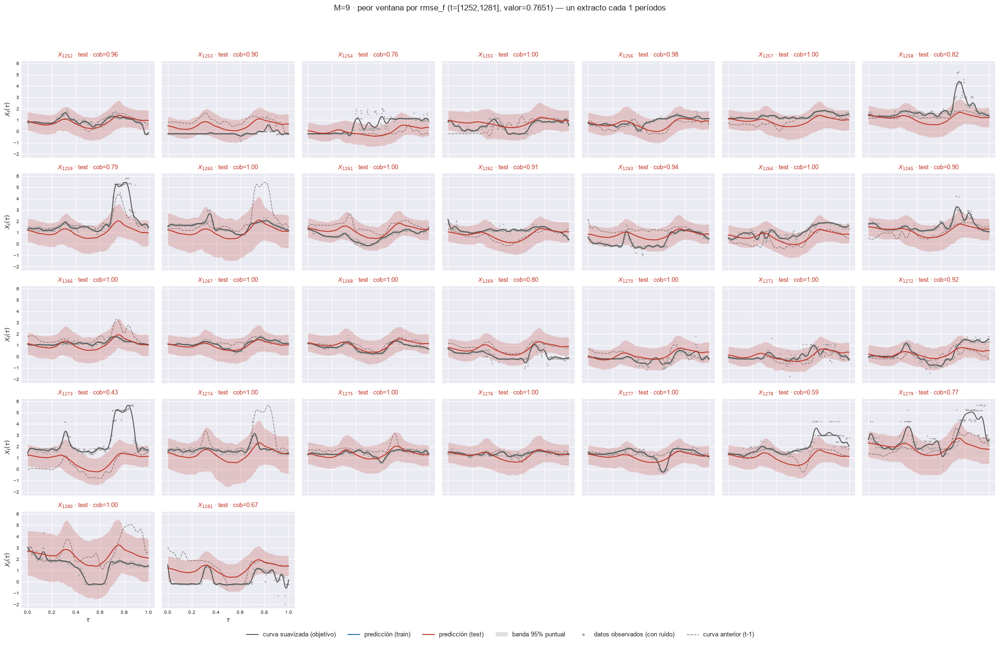

    t=[1254, 1283]  rmse_f=0.763238


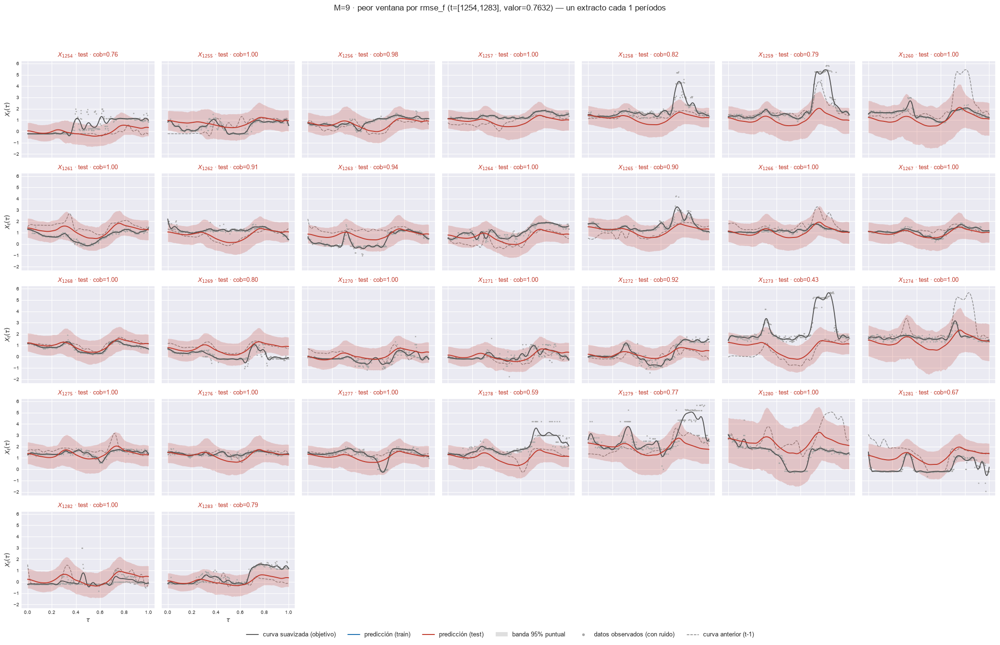

    t=[1257, 1286]  rmse_f=0.761273


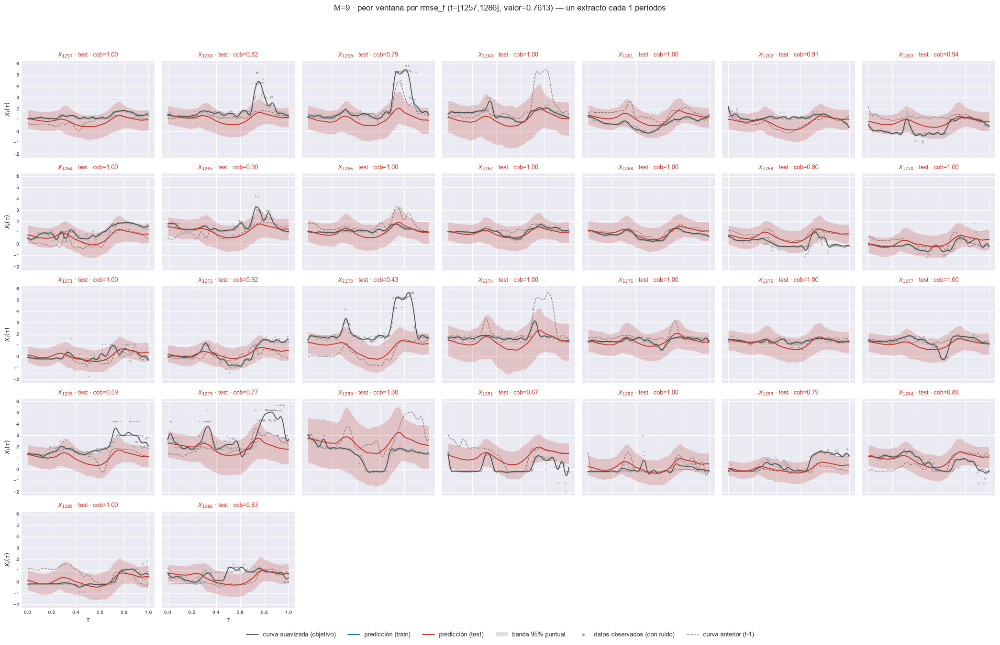

    t=[1258, 1287]  rmse_f=0.759567


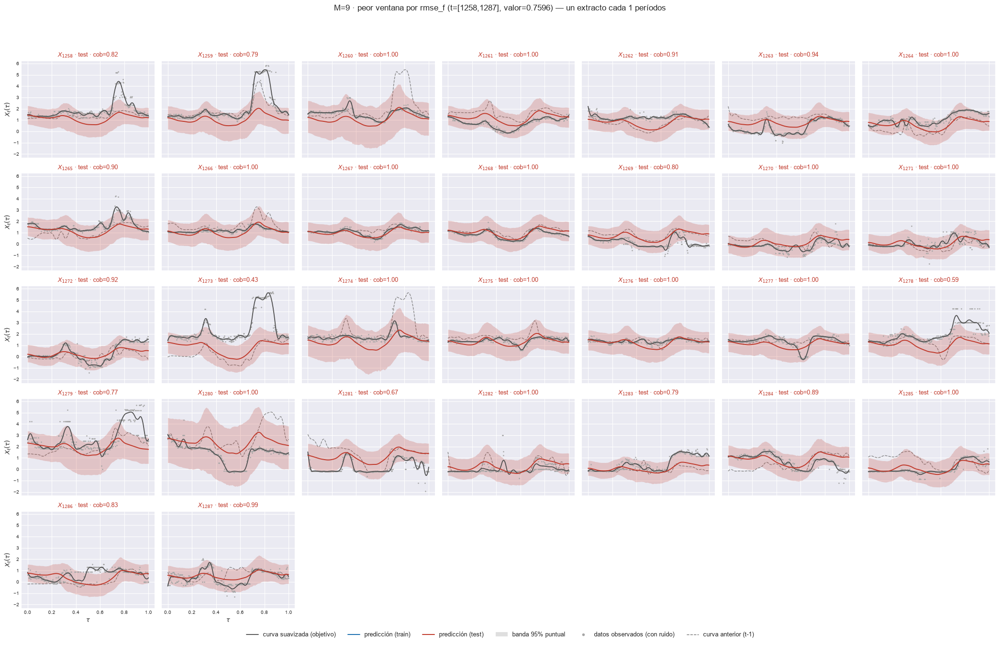

[M=10] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1253, 1282]  rmse_f=0.763702


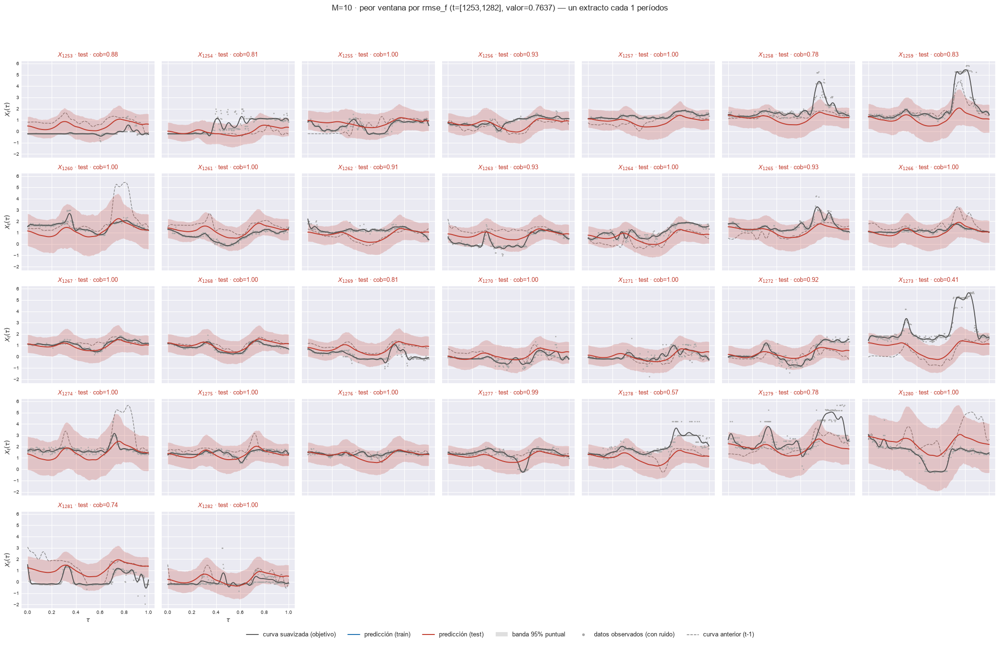

    t=[1252, 1281]  rmse_f=0.762151


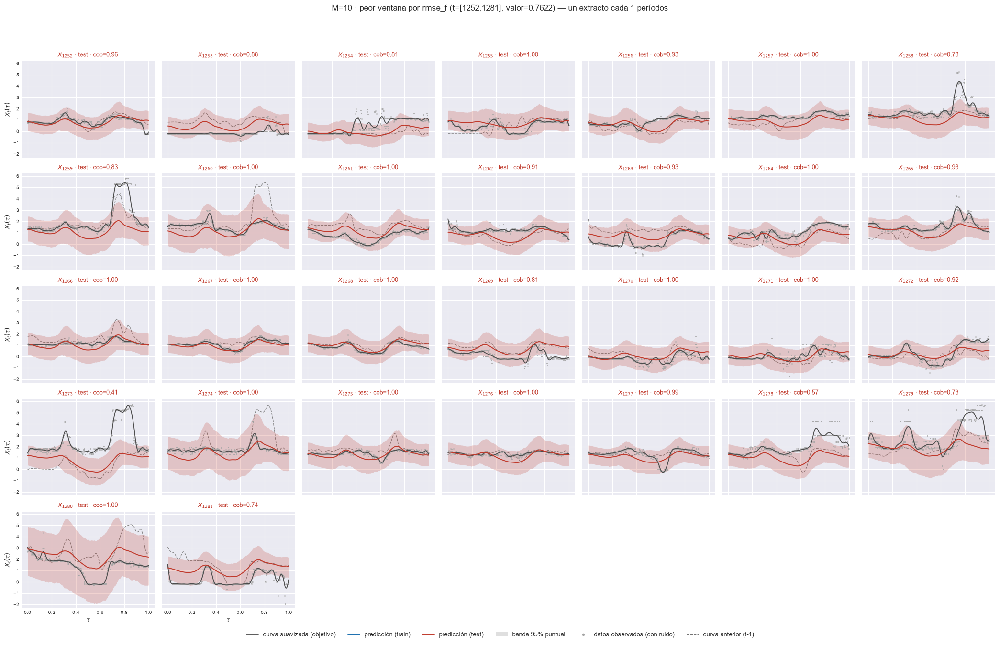

    t=[1254, 1283]  rmse_f=0.760392


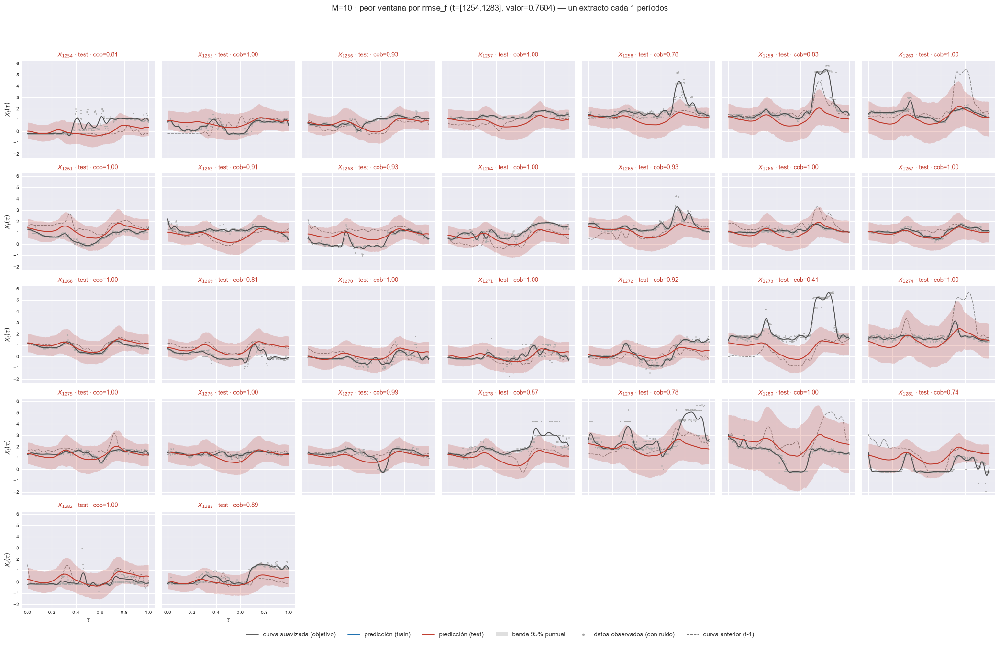

    t=[1257, 1286]  rmse_f=0.758295


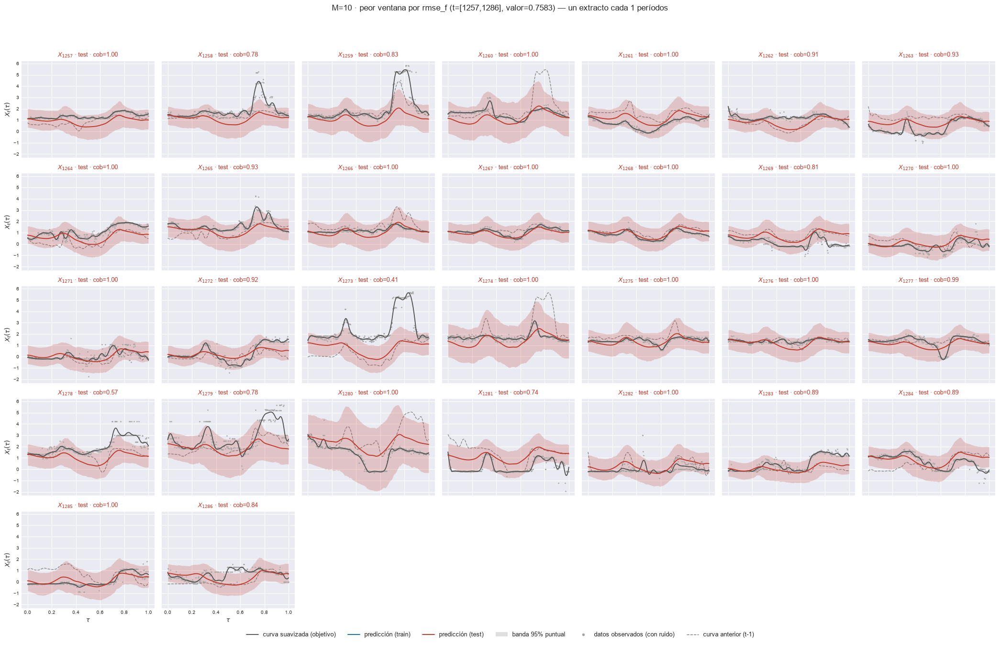

    t=[1258, 1287]  rmse_f=0.756270


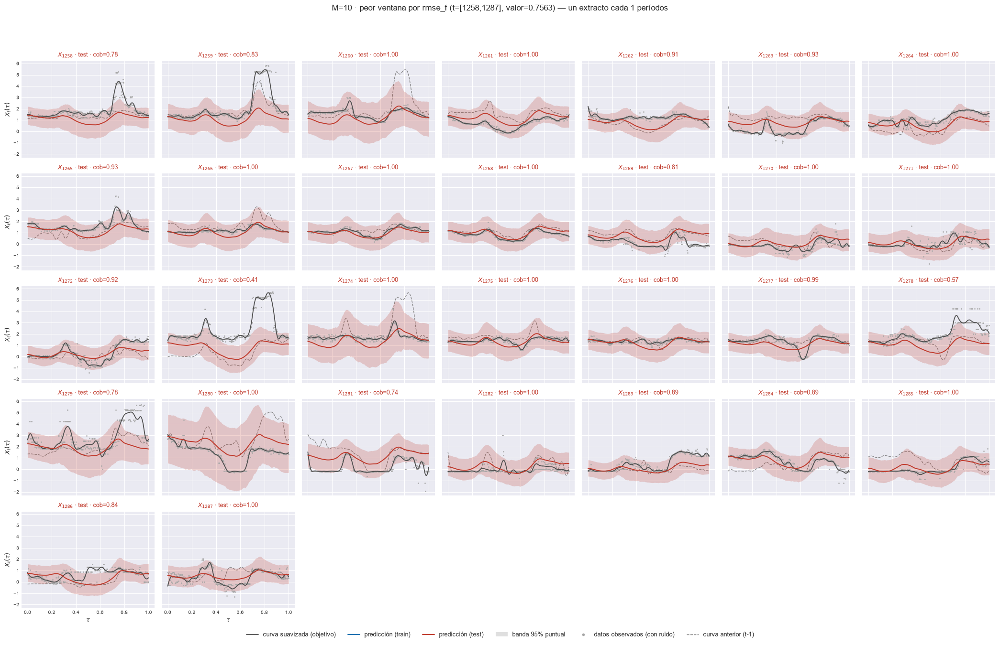

In [17]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

PIP global por covariable: el rezago 1 de cada score, propio y cruzados. Sin soporte verdadero contra el cual contrastar; con tres cadenas se reporta la dispersión entre cadenas. La lectura que importa en la 103 es qué scores rezagados gobiernan cada componente; en la 27 los rezagos cruzados eran clave (el diagnóstico de 2026-10-08 daba $\xi_2$ mucho mejor predicho con cruzados que con el propio).


In [18]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 1 variables, PIP en [1.000, 1.000]


[matriz_pip] listo: 1 pasos en 0.0s  tabla 1x2


[M=1] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000


...

  9/10 (90.0%) t=0.0s eta=0.0s  FPC 9: 3 cadenas, 10 variables, PIP en [0.178, 1.000]


  10/10 (100.0%) t=0.0s eta=0.0s  FPC 10: 3 cadenas, 10 variables, PIP en [0.112, 1.000]


[matriz_pip] listo: 10 pasos en 0.0s  tabla 10x20


[M=10] dispersion maxima entre cadenas: 0.462   ! las cadenas discrepan sobre la seleccion

,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd,FPC 7,FPC 7_sd,FPC 8,FPC 8_sd,FPC 9,FPC 9_sd,FPC 10,FPC 10_sd
variable,,,,,,,,,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,0.376,0.340,0.149,0.022,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.757,0.421,0.338,0.317
fpc_2_lag1,0.892,0.109,1.000,0.000,1.000,0.000,0.723,0.309,0.991,0.014,0.481,0.112,0.157,0.018,0.126,0.026,0.191,0.083,0.129,0.015
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,0.337,0.202,0.141,0.015,0.963,0.064,0.210,0.047,0.257,0.225
fpc_4_lag1,0.721,0.367,0.654,0.303,0.272,0.081,1.000,0.000,0.157,0.060,0.175,0.035,0.148,0.022,0.154,0.062,0.635,0.349,0.436,0.105
fpc_5_lag1,1.000,0.000,1.000,0.000,0.214,0.057,1.000,0.000,1.000,0.000,0.733,0.462,0.250,0.158,0.131,0.016,0.739,0.254,0.187,0.039
fpc_6_lag1,0.136,0.079,1.000,0.000,0.172,0.024,1.000,0.000,0.205,0.091,1.000,0.000,0.742,0.323,0.379,0.232,0.178,0.049,0.121,0.016
fpc_7_lag1,1.000,0.000,0.192,0.051,0.219,0.065,0.476,0.264,0.835,0.210,0.144,0.009,1.000,0.000,0.131,0.057,0.179,0.034,0.116,0.036
fpc_8_lag1,0.130,0.059,0.235,0.110,0.265,0.126,0.920,0.132,0.148,0.032,0.167,0.030,0.146,0.018,0.216,0.108,0.185,0.089,0.130,0.021
fpc_9_lag1,0.918,0.135,0.639,0.126,0.164,0.032,0.150,0.020,1.000,0.000,0.144,0.024,0.172,0.040,0.121,0.033,1.000,0.000,0.112,0.020


## 8. Cuadro resumen: mínimo, máximo y promedio

Por métrica y bloque train/test, sin las ventanas que cruzan $T_0$.

In [19]:
# Los dos objetivos, los cuatro predictores y los tres intervalos en 66_metricas_resumen.csv (por M) y 89_resumen_por_M.csv.
for M in M_OK:
    resumen_metricas(EST[M], M, DIS, ORIG)
resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)

_esp = resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")
                   & (resumen_bar.predictor == "esperanza") & (resumen_bar.intervalo == "equicolas")]
display(_esp.pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Esperanza · promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.8236 (nominal 0.95)  ·  PICP simultaneo test = 0.2103


[M=1] representacion_fpca  PICP puntual test = 0.9605 (nominal 0.95)  ·  PICP simultaneo test = 0.9605


[M=2] curva_suavizada      PICP puntual test = 0.8969 (nominal 0.95)  ·  PICP simultaneo test = 0.3260


[M=2] representacion_fpca  PICP puntual test = 0.9693 (nominal 0.95)  ·  PICP simultaneo test = 0.9117


[M=3] curva_suavizada      PICP puntual test = 0.9195 (nominal 0.95)  ·  PICP simultaneo test = 0.4081
[M=3] representacion_fpca  PICP puntual test = 0.9536 (nominal 0.95)  ·  PICP simultaneo test = 0.8369


...

[M=7] curva_suavizada      PICP puntual test = 0.9453 (nominal 0.95)  ·  PICP simultaneo test = 0.5444


[M=7] representacion_fpca  PICP puntual test = 0.9557 (nominal 0.95)  ·  PICP simultaneo test = 0.7386
[M=8] curva_suavizada      PICP puntual test = 0.9468 (nominal 0.95)  ·  PICP simultaneo test = 0.5467
[M=8] representacion_fpca  PICP puntual test = 0.9566 (nominal 0.95)  ·  PICP simultaneo test = 0.7211


[M=9] curva_suavizada      PICP puntual test = 0.9491 (nominal 0.95)  ·  PICP simultaneo test = 0.5452


[M=9] representacion_fpca  PICP puntual test = 0.9569 (nominal 0.95)  ·  PICP simultaneo test = 0.6949
[M=10] curva_suavizada      PICP puntual test = 0.9516 (nominal 0.95)  ·  PICP simultaneo test = 0.5601
[M=10] representacion_fpca  PICP puntual test = 0.9579 (nominal 0.95)  ·  PICP simultaneo test = 0.6937


M,1,2,3,4,5,6,7,8,9,10
metrica,,,,,,,,,,
1. MAE (L^1),0.403985,0.393555,0.382728,0.377049,0.357144,0.353823,0.352101,0.352019,0.347245,0.347621
10. Winkler max peor ventana,65.835361,64.665013,58.587744,55.649423,55.773393,56.247206,55.532546,53.974257,56.222719,54.200327
2. RMSE (L^2),0.522612,0.512418,0.501522,0.494719,0.479925,0.476823,0.474643,0.475070,0.470193,0.471260
3. E_max promedio por curva,1.063764,1.050158,1.038681,1.028184,1.018594,1.014307,1.013816,1.015570,1.008859,1.006960
4. E_max peor de la ventana,2.366236,2.363326,2.354404,2.323809,2.334126,2.324805,2.334870,2.345428,2.336789,2.339354
5. MPIW,1.453037,1.687378,1.785685,1.844686,1.846999,1.872278,1.871909,1.911271,1.899368,1.936003
6. PICP puntual,0.823621,0.896861,0.919524,0.927951,0.938990,0.941869,0.945259,0.946844,0.949073,0.951630
7. PICPB curva completa,0.210317,0.325992,0.408135,0.447123,0.528075,0.532837,0.544444,0.546726,0.545238,0.560119
8. Winkler,3.399650,2.934094,2.660211,2.604926,2.530137,2.514570,2.494757,2.506049,2.497310,2.490056


### 8.1 Bloque A por predictor

Promedio en test por predictor y $M$ (`101_*`); cambio relativo contra la esperanza.

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.4040,0.3936,0.3827,0.3770,0.3571,0.3538,0.3521,0.3520,0.3472,0.3476
mediana,0.4049,0.3949,0.3825,0.3775,0.3574,0.3544,0.3523,0.3529,0.3471,0.3478
medoide,0.4049,0.3945,0.3836,0.3791,0.3623,0.3613,0.3590,0.3614,0.3620,0.3638
modal,0.4168,0.4113,0.3921,0.3878,0.3616,0.3627,0.3612,0.3622,0.3564,0.3590


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.5226,0.5124,0.5015,0.4947,0.4799,0.4768,0.4746,0.4751,0.4702,0.4713
mediana,0.5229,0.5143,0.5018,0.4960,0.4808,0.4775,0.4757,0.4759,0.4706,0.4719
medoide,0.5229,0.5142,0.5032,0.4997,0.4866,0.4863,0.4860,0.4864,0.4873,0.4898
modal,0.5407,0.5401,0.5187,0.5186,0.4932,0.4951,0.4904,0.4930,0.4878,0.4911


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,1.0638,1.0502,1.0387,1.0282,1.0186,1.0143,1.0138,1.0156,1.0089,1.0070
mediana,1.0645,1.0526,1.0370,1.0291,1.0200,1.0154,1.0153,1.0171,1.0096,1.0090
medoide,1.0646,1.0523,1.0390,1.0354,1.0330,1.0333,1.0384,1.0389,1.0405,1.0561
modal,1.0834,1.0819,1.0479,1.0492,1.0370,1.0374,1.0345,1.0444,1.0330,1.0351


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,2.3662,2.3633,2.3544,2.3238,2.3341,2.3248,2.3349,2.3454,2.3368,2.3394
mediana,2.3684,2.3613,2.3508,2.3311,2.3470,2.3325,2.3413,2.3478,2.3394,2.3429
medoide,2.3686,2.3655,2.3595,2.3279,2.3597,2.3603,2.4074,2.3995,2.3644,2.4137
modal,2.4163,2.4030,2.3936,2.3999,2.3899,2.4286,2.4288,2.4564,2.4118,2.4284


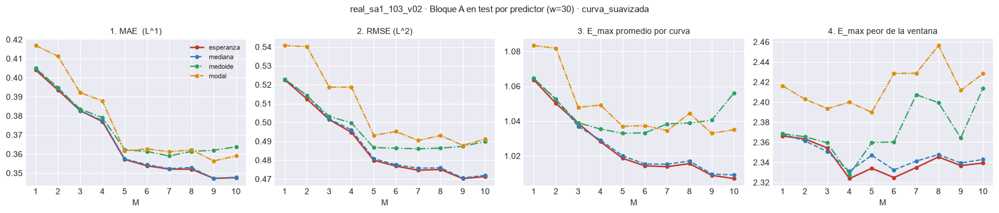

M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.2762,0.3139,0.3337,0.3422,0.3335,0.3353,0.3363,0.3388,0.3361,0.3379
mediana,0.2770,0.3154,0.3334,0.3423,0.3337,0.3358,0.3367,0.3396,0.3358,0.3379
medoide,0.2770,0.3151,0.3340,0.3446,0.3385,0.3431,0.3437,0.3477,0.3506,0.3539
modal,0.2938,0.3338,0.3436,0.3545,0.3383,0.3448,0.3454,0.3493,0.3453,0.3493


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.3587,0.4039,0.4307,0.4404,0.4393,0.4430,0.4484,0.4522,0.4508,0.4547
mediana,0.3588,0.4063,0.4310,0.4417,0.4403,0.4437,0.4496,0.4531,0.4512,0.4553
medoide,0.3588,0.4061,0.4326,0.4460,0.4466,0.4532,0.4604,0.4641,0.4686,0.4740
modal,0.3851,0.4385,0.4504,0.4670,0.4537,0.4626,0.4650,0.4710,0.4692,0.4752


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,0.3804,0.5387,0.6431,0.7081,0.7370,0.7666,0.8210,0.8378,0.8594,0.8777
mediana,0.3815,0.5433,0.6462,0.7121,0.7400,0.7703,0.8252,0.8403,0.8622,0.8817
medoide,0.3815,0.5410,0.6464,0.7216,0.7560,0.7945,0.8559,0.8708,0.9037,0.9292
modal,0.4047,0.5705,0.6610,0.7331,0.7531,0.7912,0.8451,0.8678,0.8846,0.9085


M,1,2,3,4,5,6,7,8,9,10
predictor,,,,,,,,,,
esperanza,1.2029,1.3276,1.6161,1.6283,1.7372,1.7702,2.0136,2.0347,2.0401,2.0714
mediana,1.1941,1.3373,1.6250,1.6420,1.7514,1.7807,2.0245,2.0399,2.0419,2.0842
medoide,1.1940,1.3406,1.6309,1.6553,1.7614,1.8181,2.1272,2.0863,2.1191,2.1577
modal,1.3317,1.4670,1.7111,1.7918,1.8568,1.9001,2.0946,2.1332,2.1622,2.1897


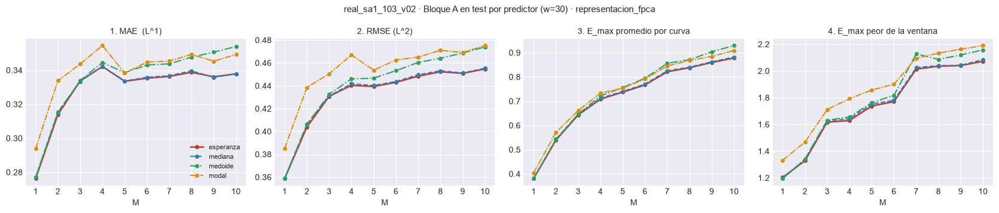

In [20]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_PRED = tabla_predictores(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_A:
        display(TAB_PRED.loc[col].style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    rel = TAB_PRED.div(TAB_PRED.xs("esperanza", level="predictor"), level="columna") - 1
    display(rel.style.format("{:+.1%}").background_gradient(cmap="RdYlGn_r", vmin=-0.1, vmax=0.1)
            .set_caption(f"Cambio relativo contra la esperanza · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_PRED, METRICAS_A,
                          f"{EXPERIMENT_BASE} · Bloque A en test por predictor (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"101_bloqueA_predictores_vs_M_{objetivo}.png")
    plt.show()

### 8.2 Bloque B por intervalo

Seis métricas en test por construcción y $M$ (`110_*`), con la esperanza.

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.4530,1.6874,1.7857,1.8447,1.8470,1.8723,1.8719,1.9113,1.8994,1.9360
simultanea,1.4606,2.1007,2.4190,2.5911,2.6690,2.7505,2.7865,2.8722,2.8850,2.9602
hdr,1.4542,1.6888,1.7862,1.8469,1.8492,1.8750,1.8738,1.9140,1.9020,1.9386


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.8236,0.8969,0.9195,0.9280,0.9390,0.9419,0.9453,0.9468,0.9491,0.9516
simultanea,0.8250,0.9427,0.9757,0.9819,0.9879,0.9902,0.9912,0.9925,0.9925,0.9932
hdr,0.8248,0.8951,0.9189,0.9269,0.9390,0.9419,0.9440,0.9469,0.9488,0.9515


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.2103,0.3260,0.4081,0.4471,0.5281,0.5328,0.5444,0.5467,0.5452,0.5601
simultanea,0.2176,0.5075,0.7199,0.7470,0.8438,0.8666,0.8725,0.8975,0.8990,0.9056
hdr,0.2175,0.3239,0.4121,0.4464,0.5123,0.5275,0.5401,0.5539,0.5508,0.5747


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,3.3996,2.9341,2.6602,2.6049,2.5301,2.5146,2.4948,2.5060,2.4973,2.4901
simultanea,3.3425,2.7751,2.7303,2.8371,2.8608,2.9208,2.9572,3.0237,3.0409,3.0998
hdr,3.3740,2.9323,2.6574,2.6139,2.5378,2.5155,2.4994,2.5080,2.4959,2.4962


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,16.3405,13.5410,11.2806,10.8223,9.9834,9.7009,9.4927,9.3493,9.3204,9.0263
simultanea,16.1181,9.8409,7.1562,6.8322,6.2610,6.1097,6.0179,5.9510,5.9386,5.8400
hdr,16.2085,13.5740,11.1679,10.7646,9.9909,9.6915,9.4573,9.2329,9.2320,8.9979


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,65.8354,64.6650,58.5877,55.6494,55.7734,56.2472,55.5325,53.9743,56.2227,54.2003
simultanea,65.5837,57.5708,47.2987,43.6917,42.2739,40.3821,39.4875,37.2865,38.1758,36.6005
hdr,65.7247,64.5487,58.8581,56.2769,56.4376,56.0340,56.4679,54.9153,56.2305,54.9337


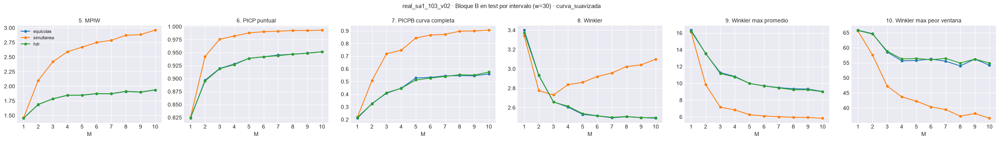

M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.4530,1.6874,1.7857,1.8447,1.8470,1.8723,1.8719,1.9113,1.8994,1.9360
simultanea,1.4606,2.1007,2.4190,2.5911,2.6690,2.7505,2.7865,2.8722,2.8850,2.9602
hdr,1.4542,1.6888,1.7862,1.8469,1.8492,1.8750,1.8738,1.9140,1.9020,1.9386


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.9605,0.9693,0.9536,0.9516,0.9522,0.9560,0.9557,0.9566,0.9569,0.9579
simultanea,0.9636,0.9900,0.9906,0.9935,0.9933,0.9936,0.9934,0.9937,0.9937,0.9947
hdr,0.9606,0.9675,0.9538,0.9516,0.9521,0.9545,0.9553,0.9556,0.9559,0.9578


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,0.9605,0.9117,0.8369,0.7996,0.7684,0.7596,0.7386,0.7211,0.6949,0.6937
simultanea,0.9636,0.9714,0.9568,0.9594,0.9520,0.9540,0.9425,0.9421,0.9384,0.9502
hdr,0.9606,0.8998,0.8464,0.8088,0.7710,0.7651,0.7383,0.7305,0.7009,0.6979


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,1.7798,1.9683,2.1778,2.2047,2.2647,2.2813,2.3373,2.3697,2.3835,2.3885
simultanea,1.7767,2.2394,2.5304,2.6674,2.7535,2.8310,2.8968,2.9713,2.9921,3.0574
hdr,1.7827,1.9673,2.1800,2.2119,2.2709,2.2870,2.3431,2.3738,2.3844,2.3951


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,2.4513,2.7916,3.7248,4.0998,4.7598,4.9100,5.9081,5.9890,6.3087,6.3358
simultanea,2.4470,2.8892,3.3958,3.7059,4.0057,4.1409,4.6259,4.7407,4.7683,4.8518
hdr,2.4552,2.8029,3.7397,4.1108,4.7234,4.9353,5.9393,5.9770,6.3282,6.3558


M,1,2,3,4,5,6,7,8,9,10
intervalo,,,,,,,,,,
equicolas,12.5956,15.6504,24.3105,22.4028,28.1098,30.4397,40.6212,40.6975,42.6172,41.4963
simultanea,13.0588,9.9502,14.2272,11.9239,15.6611,16.6434,24.2801,24.5732,24.6976,25.0310
hdr,12.8865,15.5031,24.7528,23.1249,28.2990,30.5443,41.2410,41.0172,42.7444,42.0556


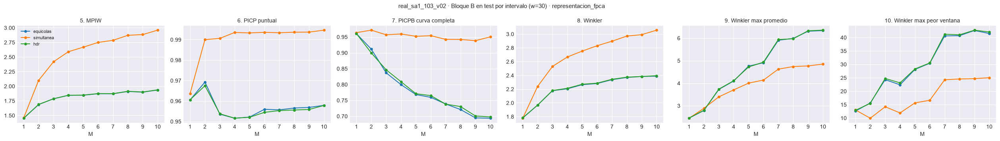

In [21]:
for objetivo in ("curva_suavizada", "representacion_fpca"):
    TAB_INT = tabla_intervalos(resumen_bar, PATH_BARRIDO, objetivo=objetivo)
    for etiqueta, col in METRICAS_B:
        display(TAB_INT.loc[col].style.format("{:.4f}")
                .set_caption(f"{etiqueta} · TEST · objetivo={objetivo}"))
    plot_predictores_vs_M(TAB_INT, METRICAS_B,
                          f"{EXPERIMENT_BASE} · Bloque B en test por intervalo (w={W_REF}) · {objetivo}",
                          save_path=PATH_BARRIDO / f"110_intervalos_vs_M_{objetivo}.png")
    plt.show()

## 9. Monitoreo univariado por componente FPCA

MAE, RMSE y MISE del score por componente sobre la ventana móvil. Solo monitoreo.

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.2s  t=16 [train] rmse=0.317


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.3421


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.5119


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4483


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.4919


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.2843


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.2787


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.3289


[ventana_movil_scores[FPC 1, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


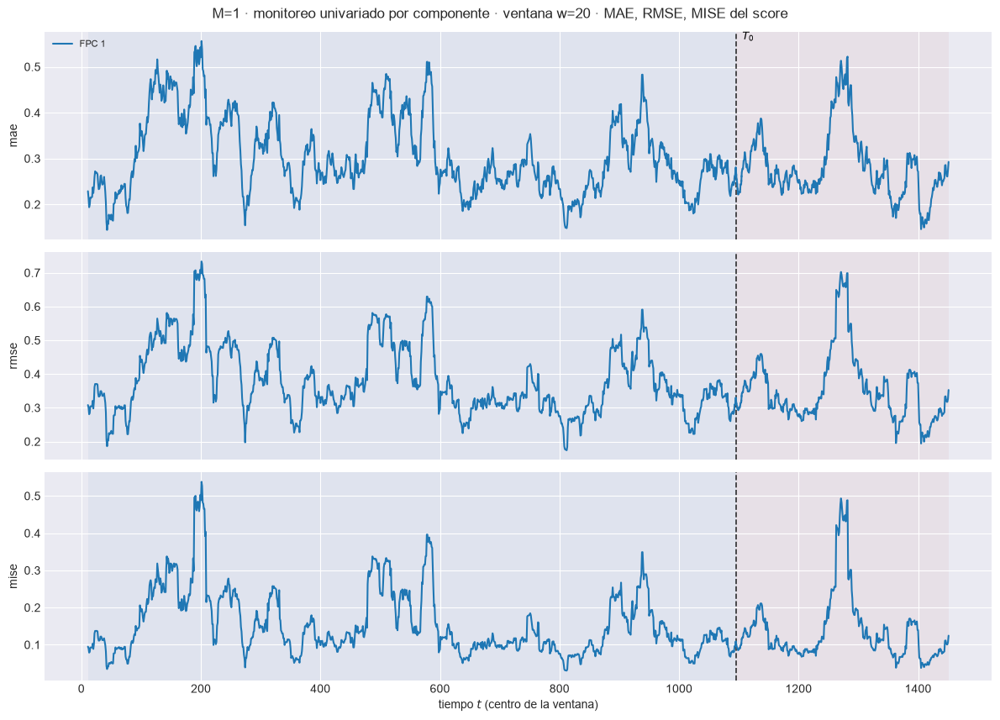

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2866  w=30 test=0.2615


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.358  w=30 test=0.3344


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1281  w=30 test=0.1119


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m01\91_ventana_univariado_w30.png


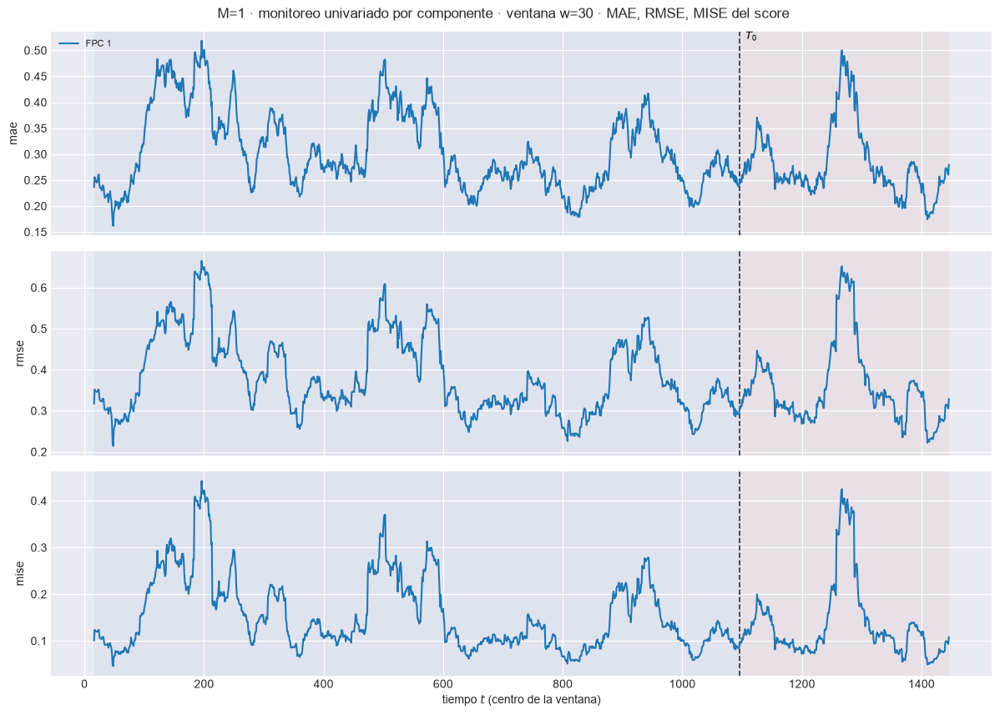

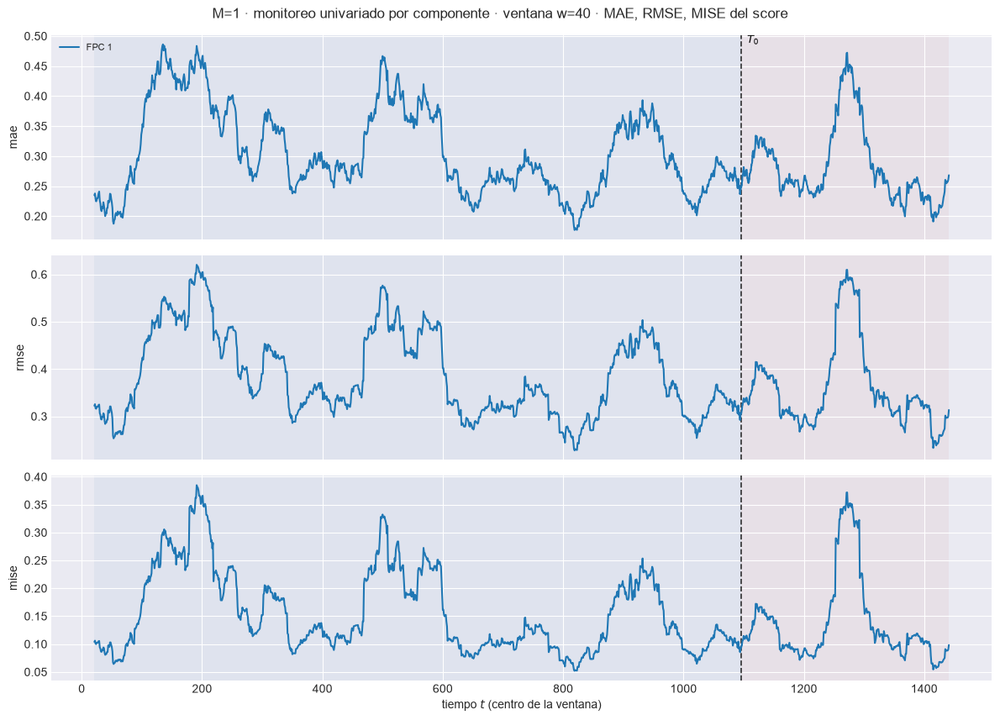

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.9s  t=16 [train] rmse=0.3115


  71/1431 ( 5.0%) t=0.0s eta=0.2s  t=86 [train] rmse=0.3367


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.5091


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4491


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.2672


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.2001


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.2184


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.1972


[ventana_movil_scores[FPC 2, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


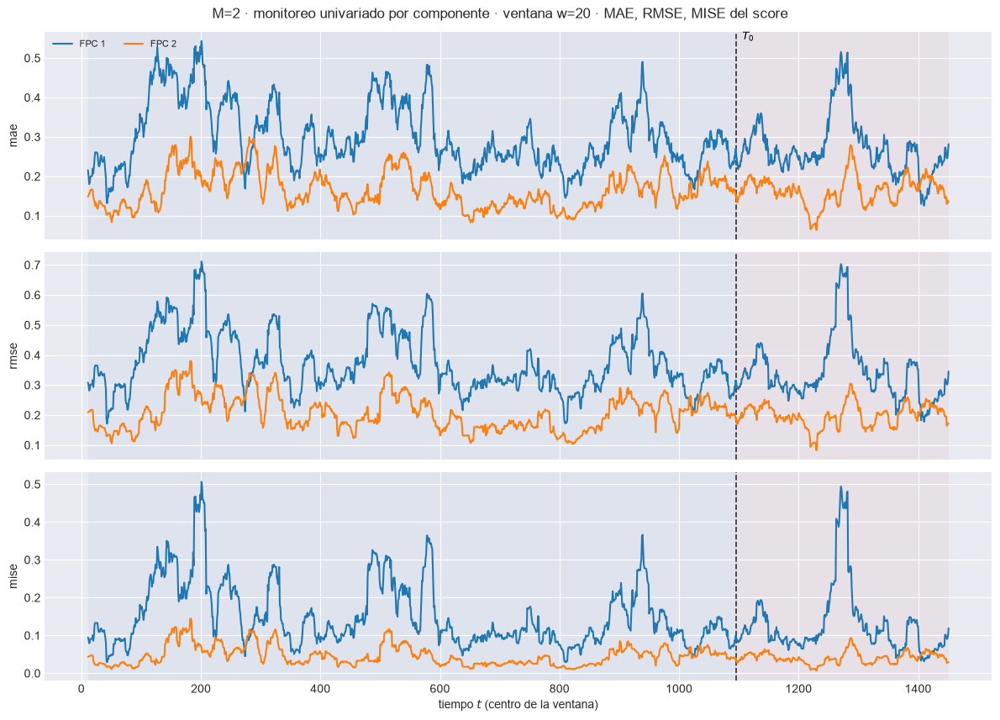

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2187  w=30 test=0.1987


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.2825  w=30 test=0.2379


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.07981  w=30 test=0.0566


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m02\91_ventana_univariado_w30.png


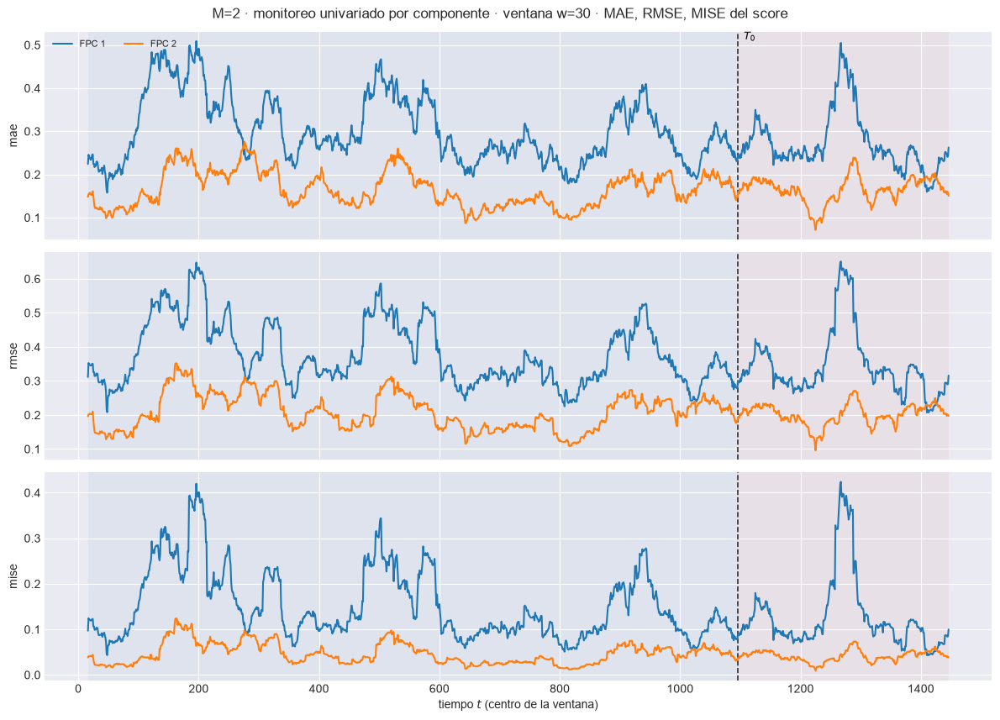

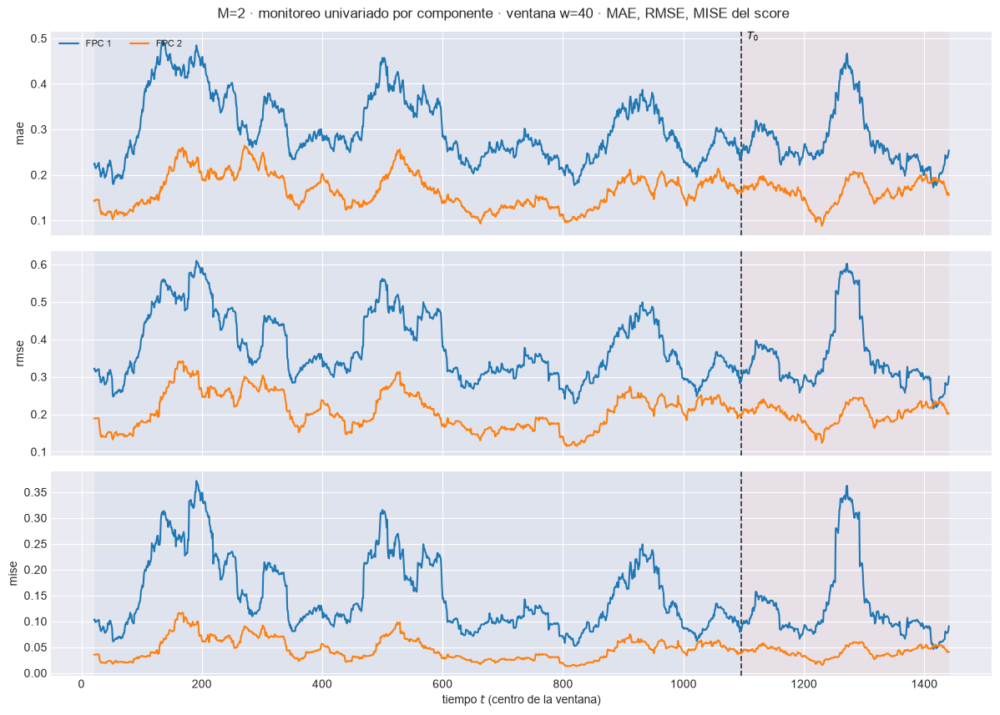

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.4s  t=16 [train] rmse=0.309


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.294


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.4246


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4235


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.221


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.1735


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.1881


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.1936


[ventana_movil_scores[FPC 3, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


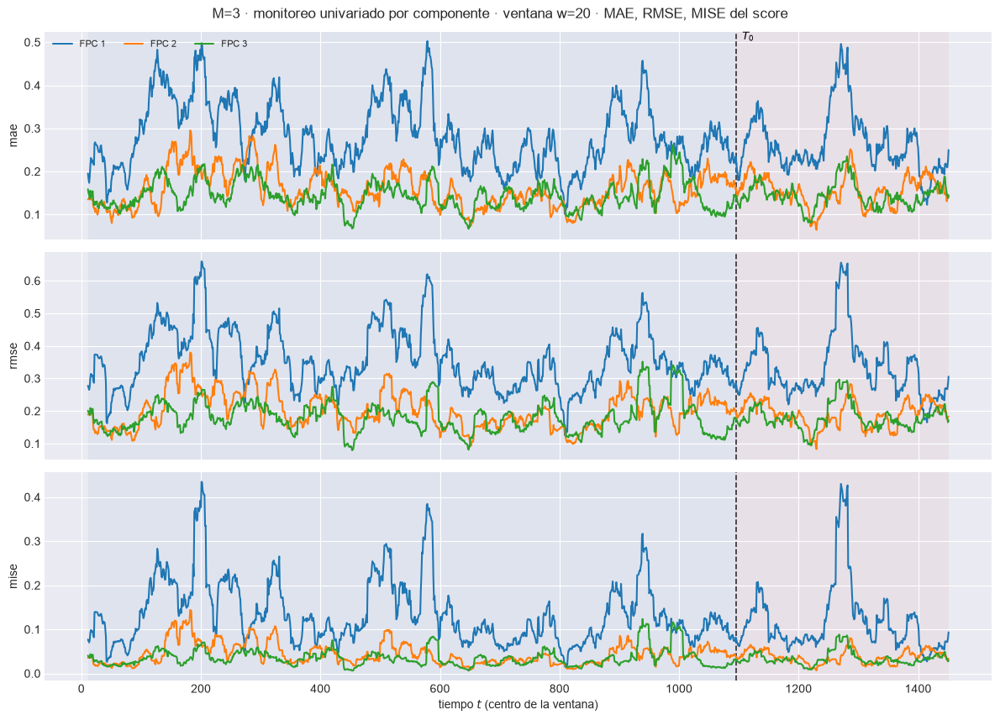

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1729  w=30 test=0.1681


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.2219  w=30 test=0.2087


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.04923  w=30 test=0.04358


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m03\91_ventana_univariado_w30.png


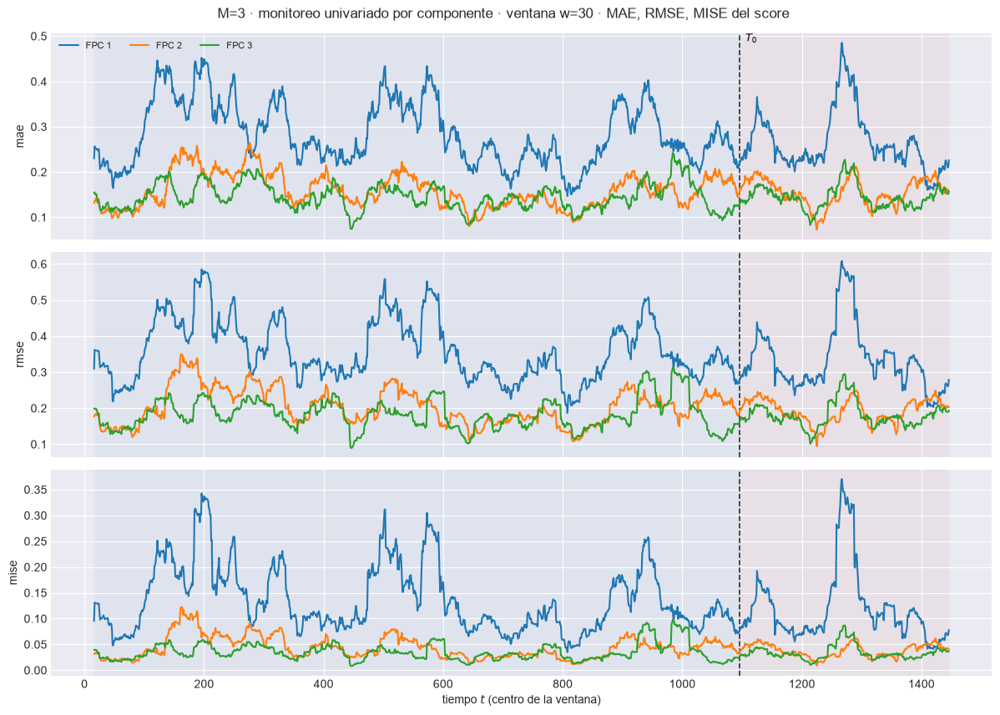

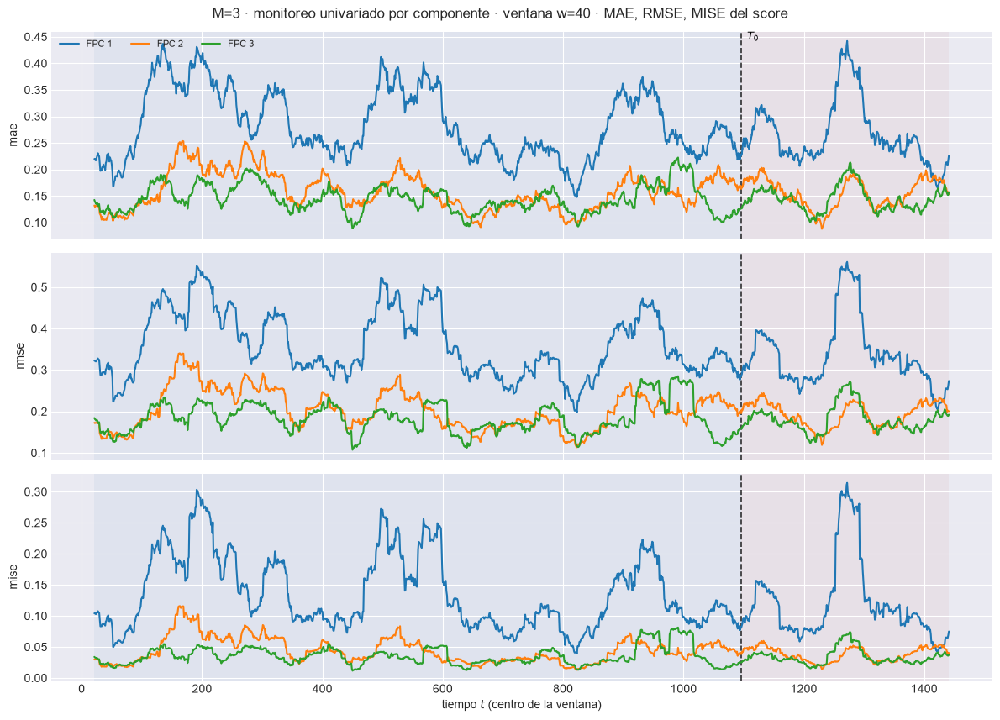

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.4s  t=16 [train] rmse=0.319


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2967


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.4015


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4241


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.119


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.06694


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.1431


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.1307


[ventana_movil_scores[FPC 4, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


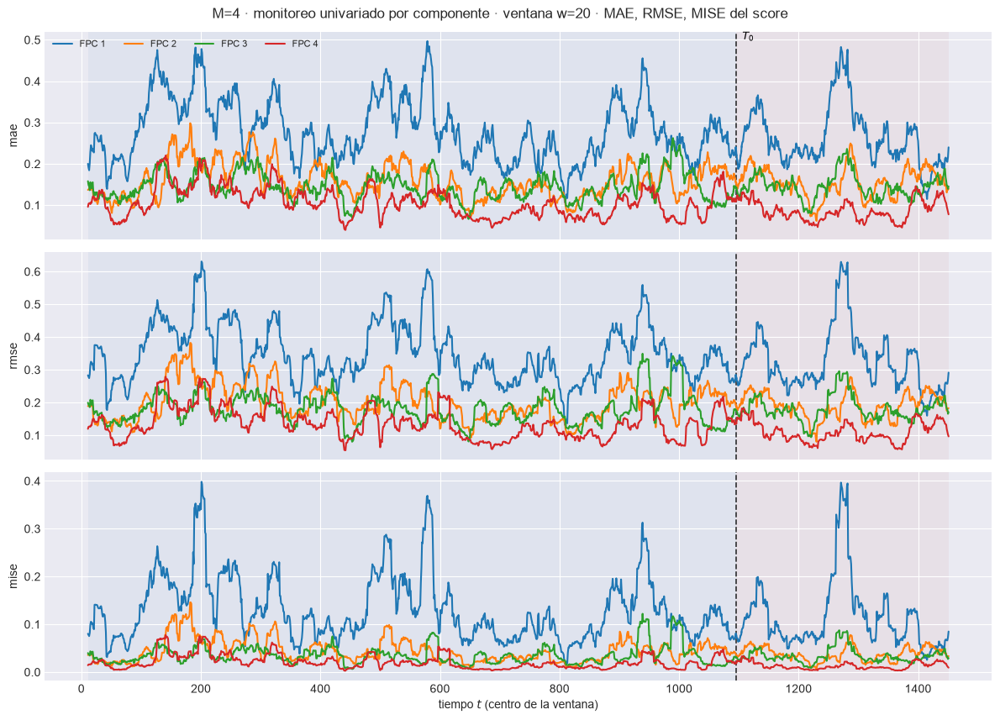

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1509  w=30 test=0.1477


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1934  w=30 test=0.1804


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.03739  w=30 test=0.03256


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m04\91_ventana_univariado_w30.png


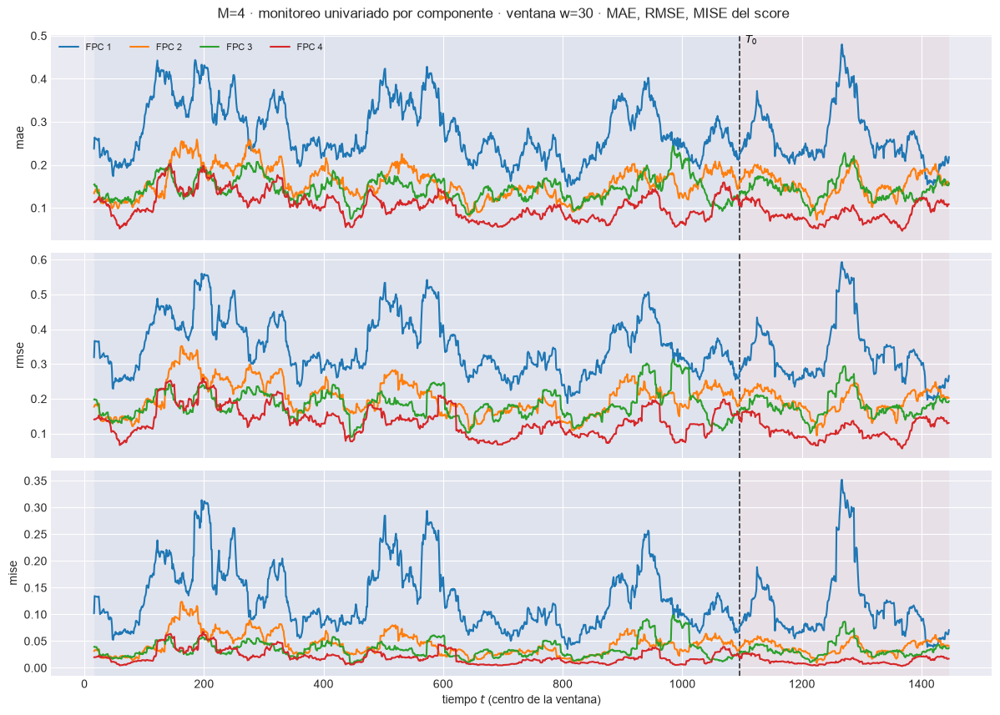

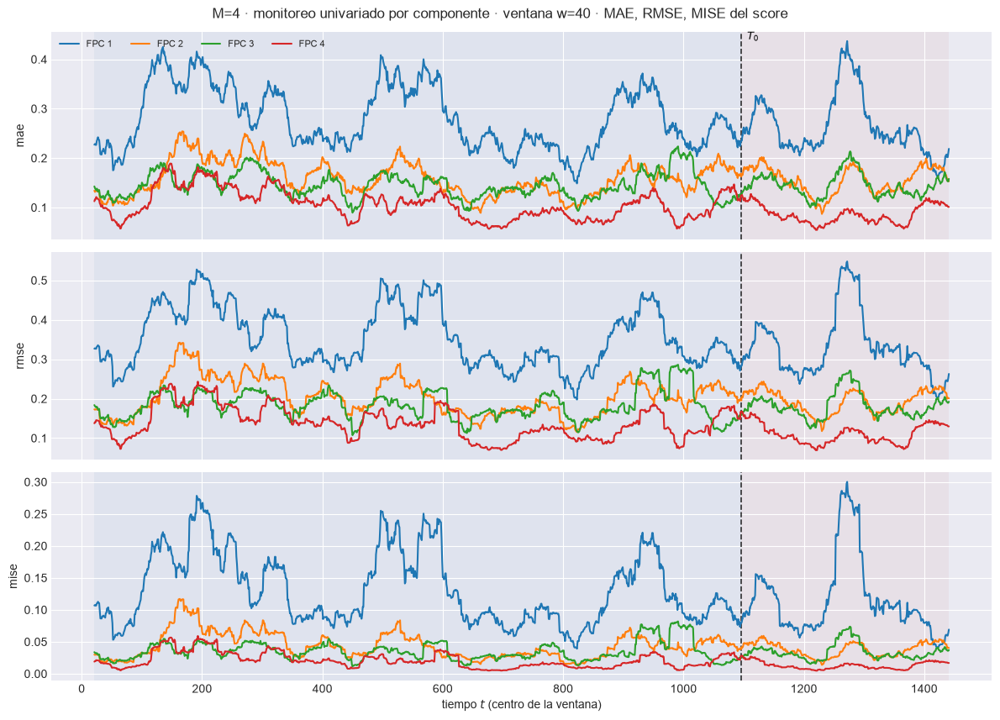

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.4s  t=16 [train] rmse=0.3119


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2961


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3806


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4014


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.1653


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.09144


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.1365


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.1072


[ventana_movil_scores[FPC 5, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


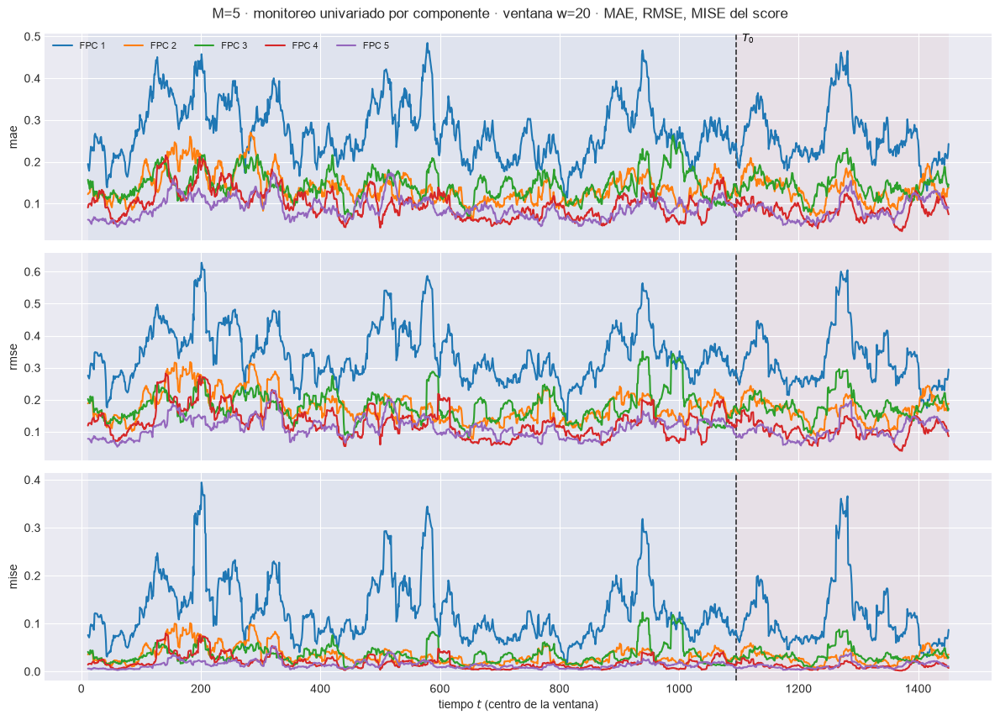

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.128  w=30 test=0.1212


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1646  w=30 test=0.154


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.02709  w=30 test=0.02373


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m05\91_ventana_univariado_w30.png


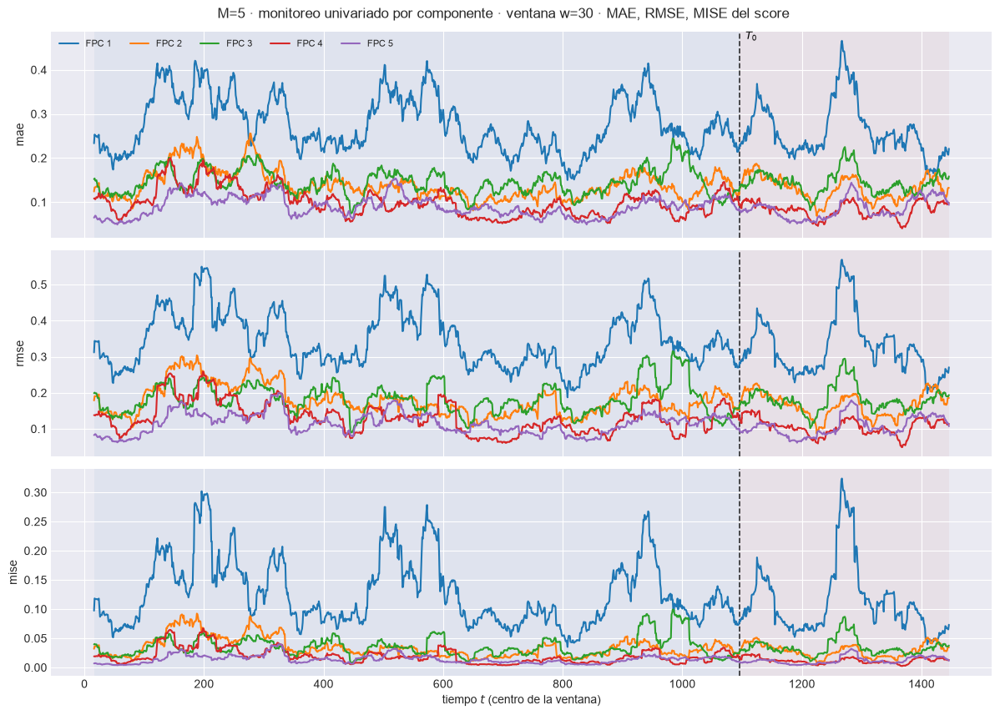

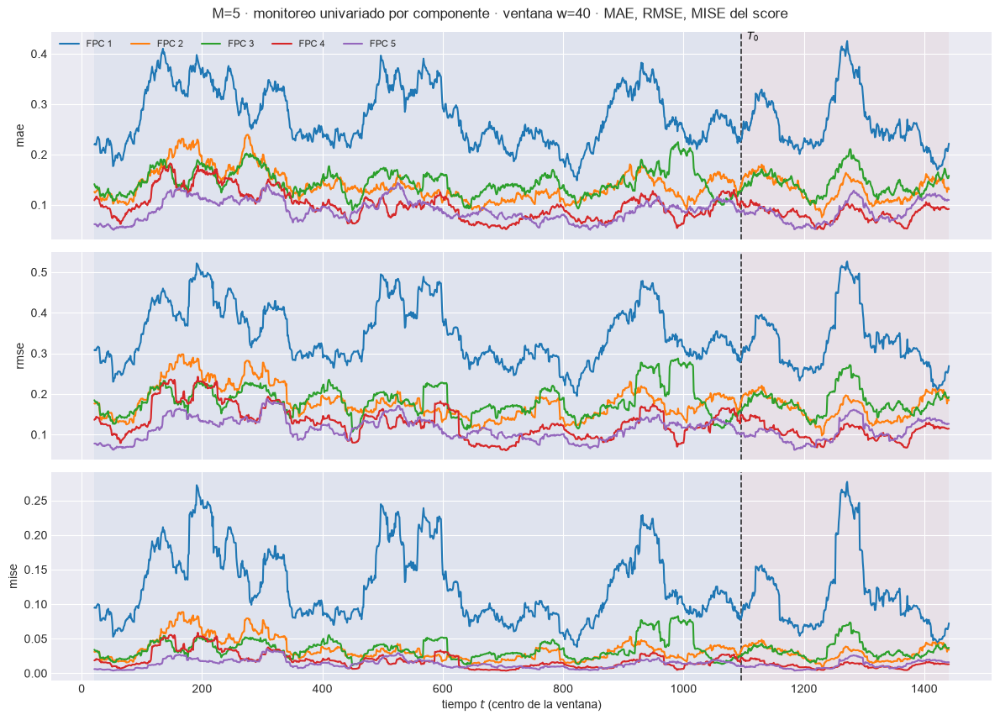

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.8s  t=16 [train] rmse=0.3058


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2946


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3879


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4003


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.07094


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.06288


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.06869


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.06299


[ventana_movil_scores[FPC 6, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


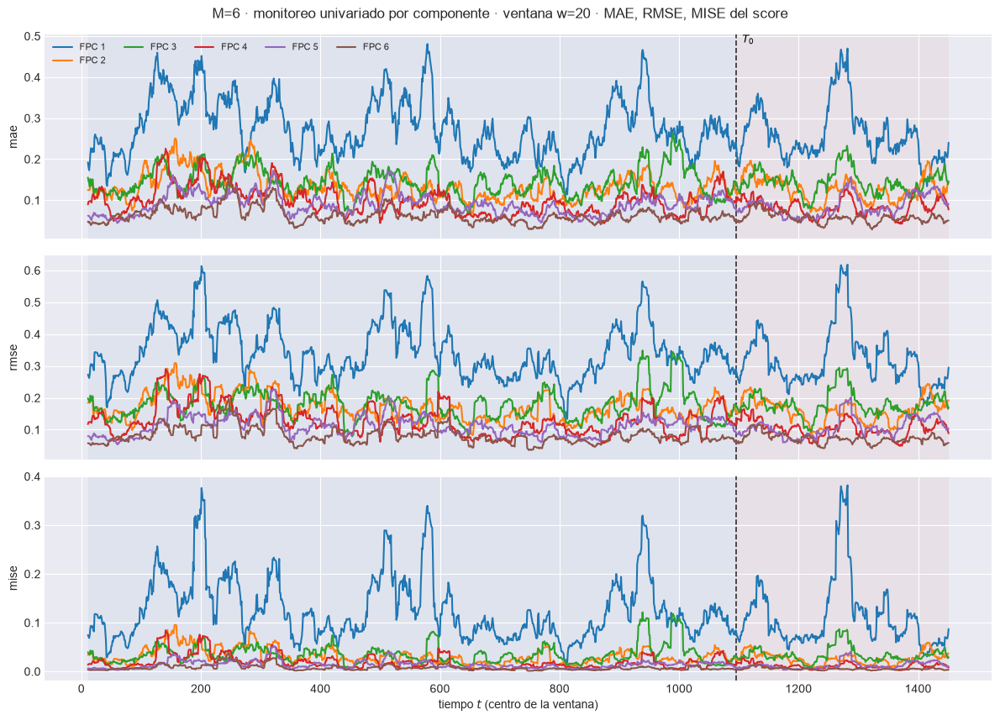

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1157  w=30 test=0.1074


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1469  w=30 test=0.1363


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.02157  w=30 test=0.01859


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m06\91_ventana_univariado_w30.png


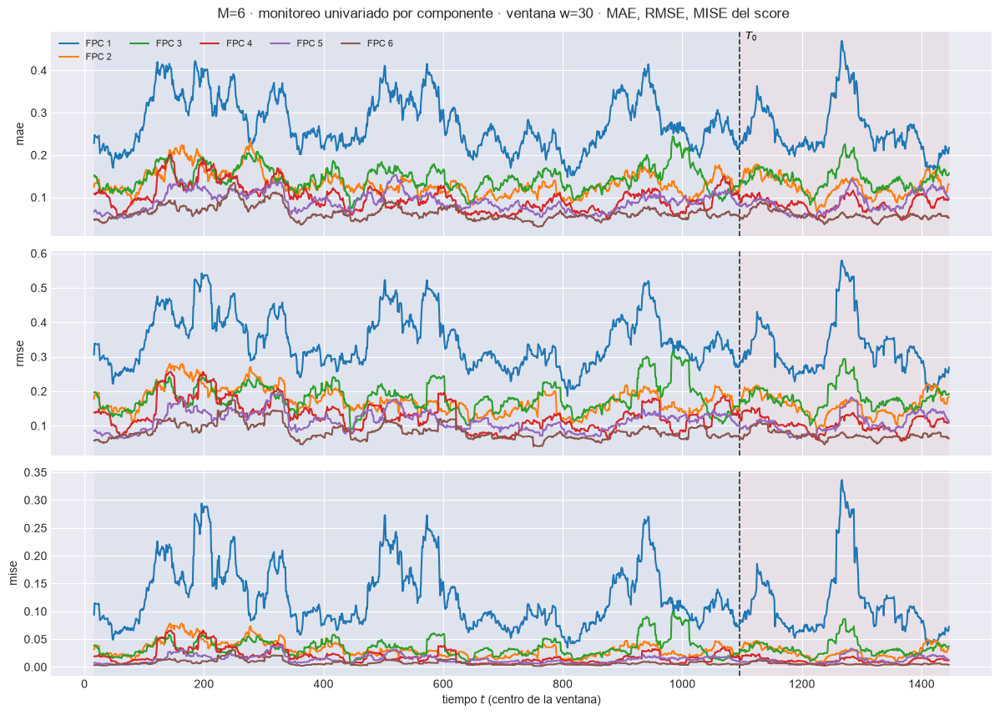

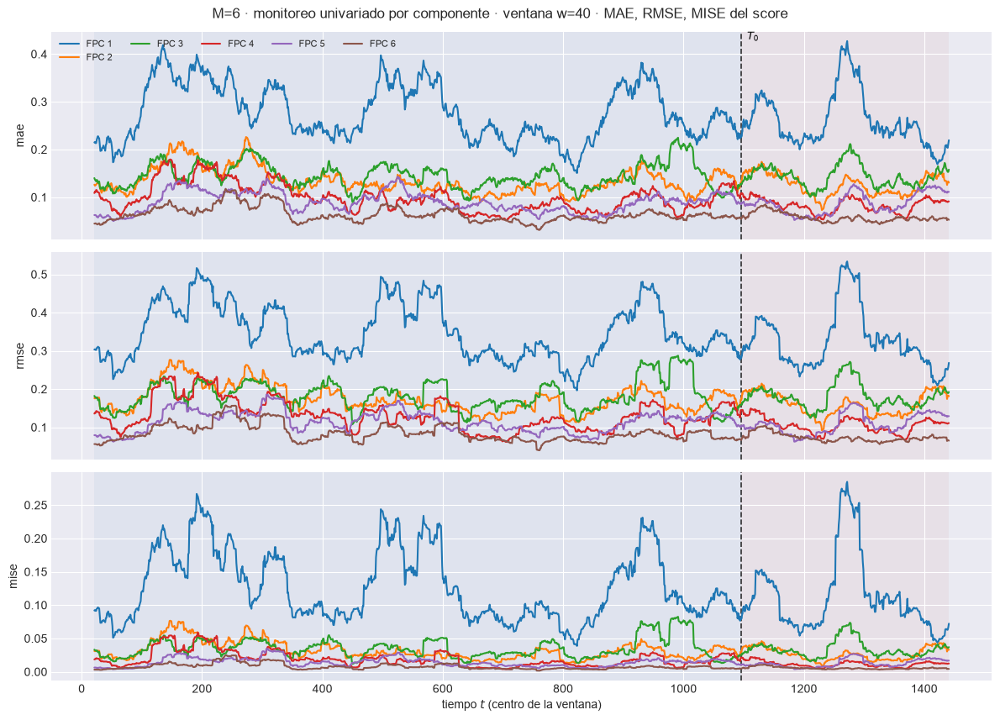

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.4s  t=16 [train] rmse=0.3115


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2941


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3447


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.403


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.07783


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.07243


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.06909


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.07284


[ventana_movil_scores[FPC 7, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


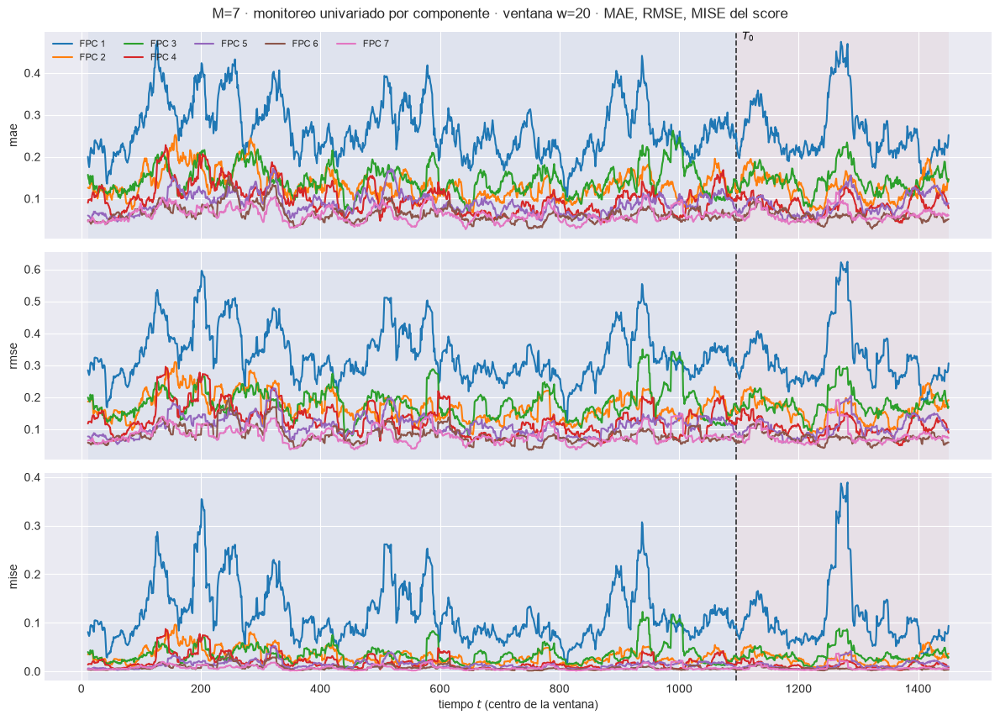

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.1036  w=30 test=0.09695


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1328  w=30 test=0.1225


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01765  w=30 test=0.015


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m07\91_ventana_univariado_w30.png


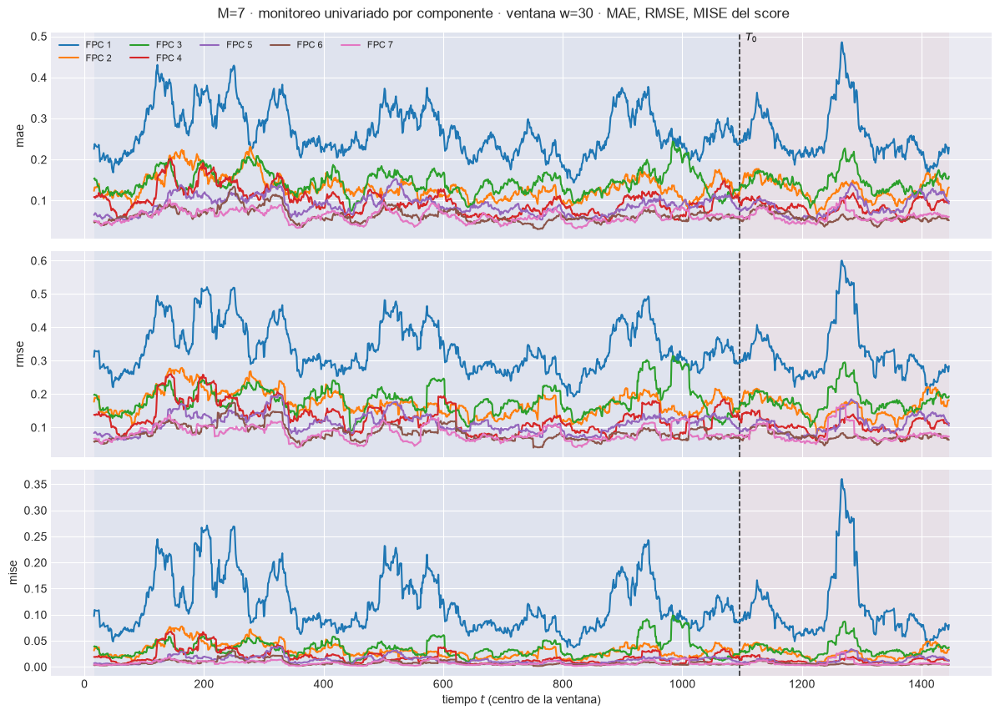

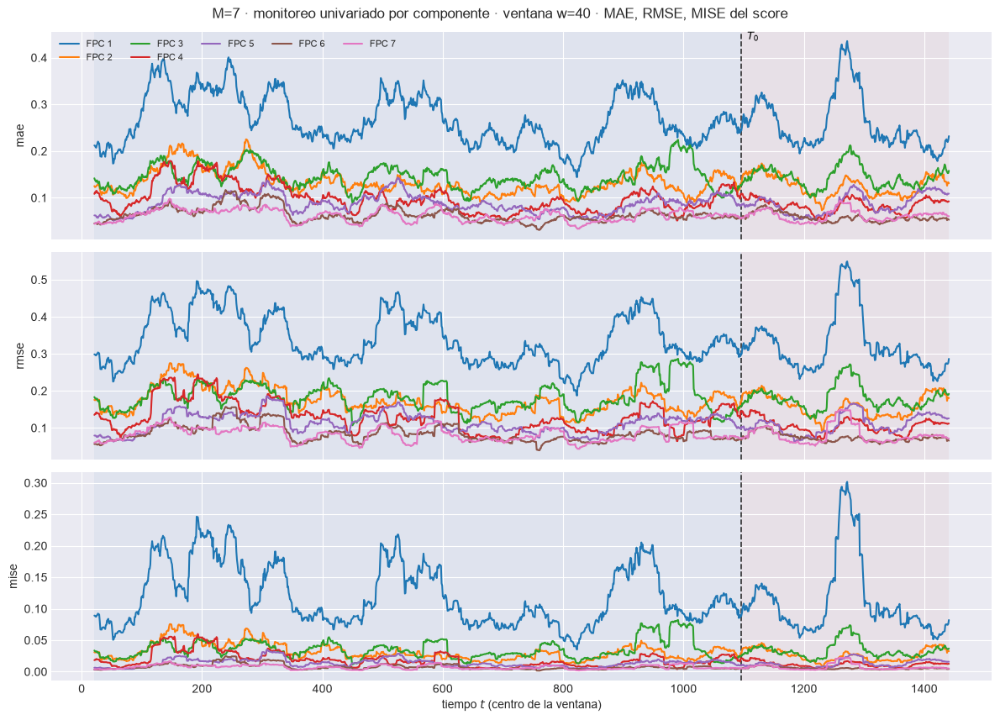

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.3s  t=16 [train] rmse=0.3185


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2964


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3478


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4029


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.09593


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.04875


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.05212


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.05621


[ventana_movil_scores[FPC 8, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


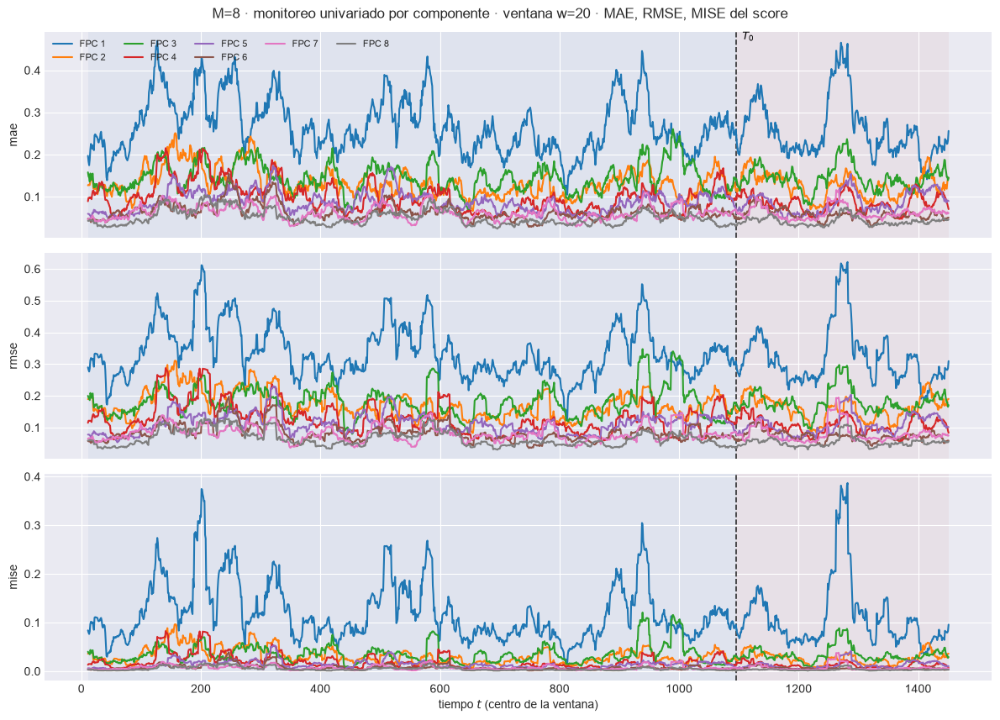

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.09243  w=30 test=0.0839


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1206  w=30 test=0.1071


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01454  w=30 test=0.01147


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m08\91_ventana_univariado_w30.png


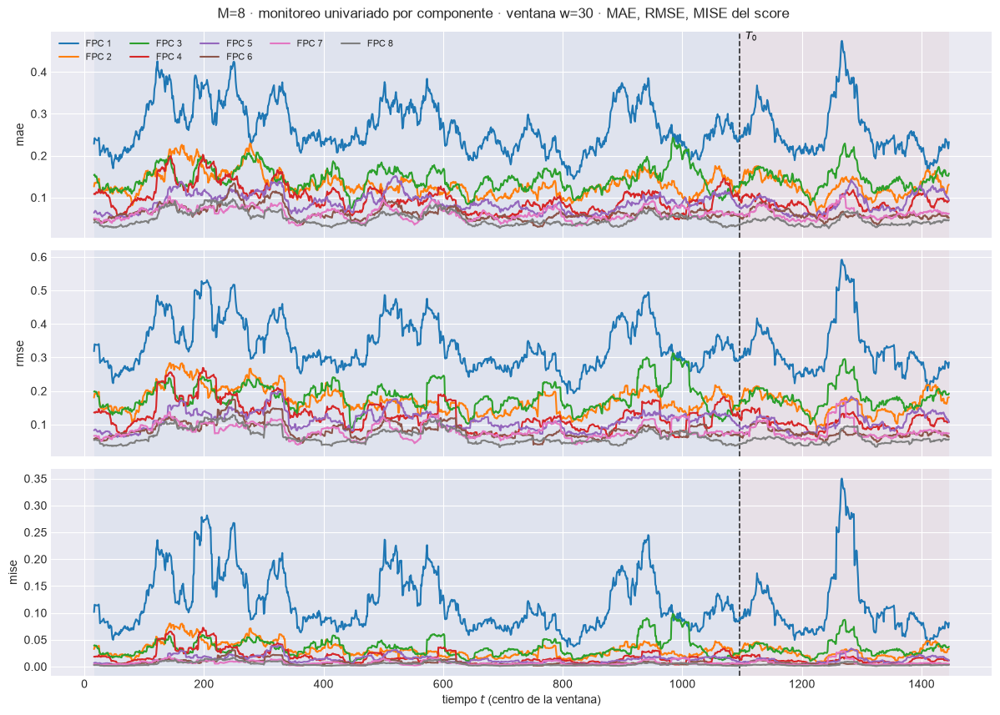

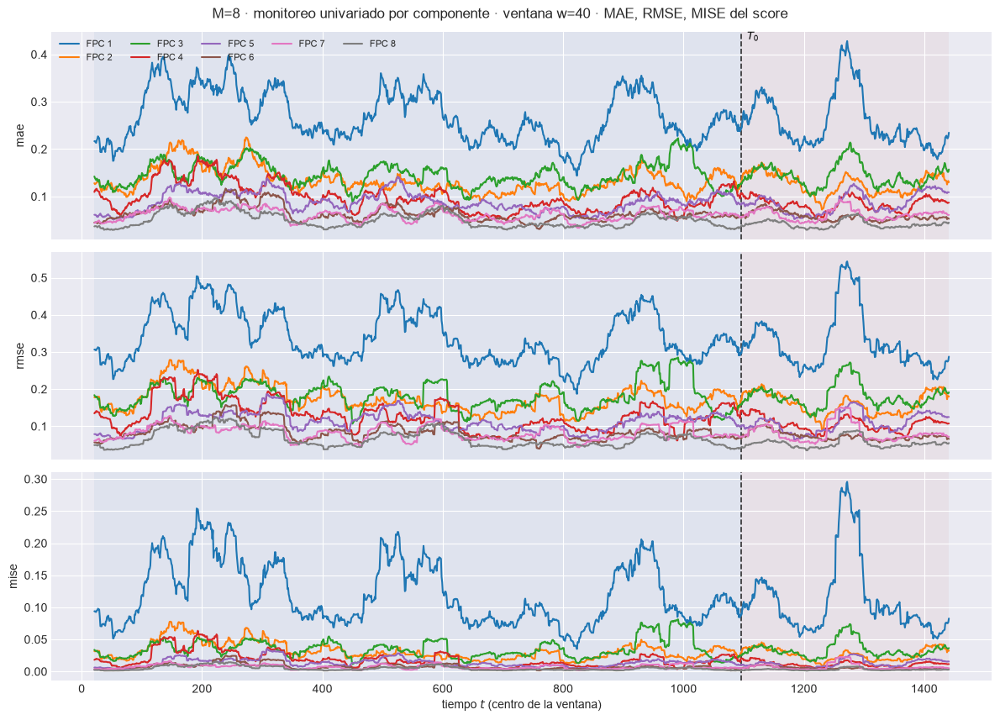

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.7s  t=16 [train] rmse=0.3087


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2885


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3601


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4039


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.06799


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.04671


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.04384


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.04552


[ventana_movil_scores[FPC 9, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


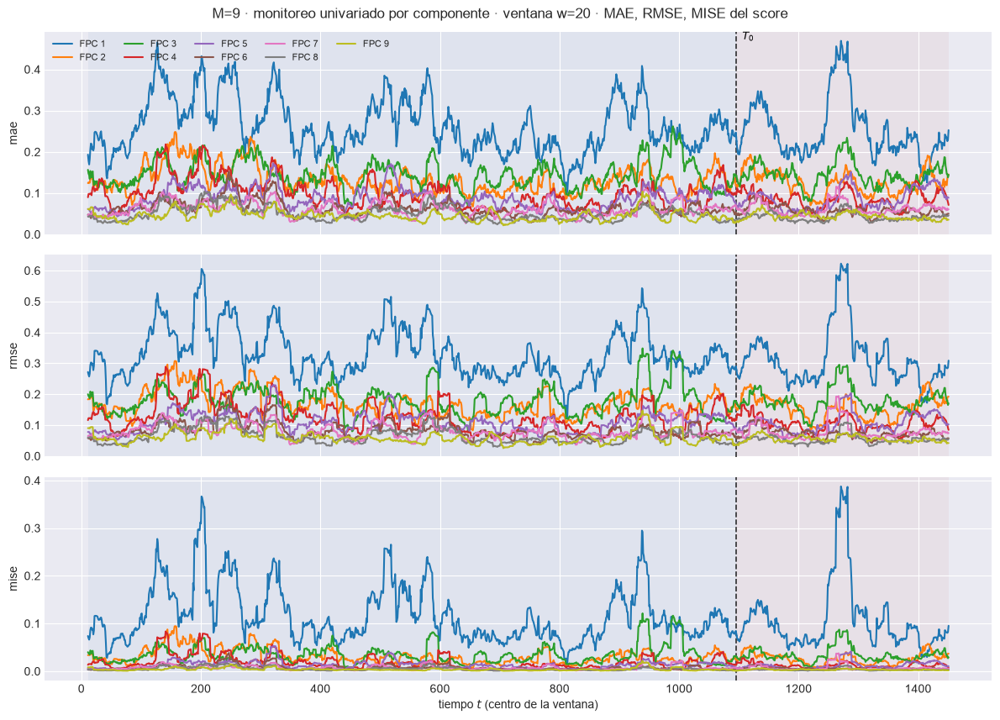

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.08245  w=30 test=0.07578


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1108  w=30 test=0.09579


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01227  w=30 test=0.009176


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m09\91_ventana_univariado_w30.png


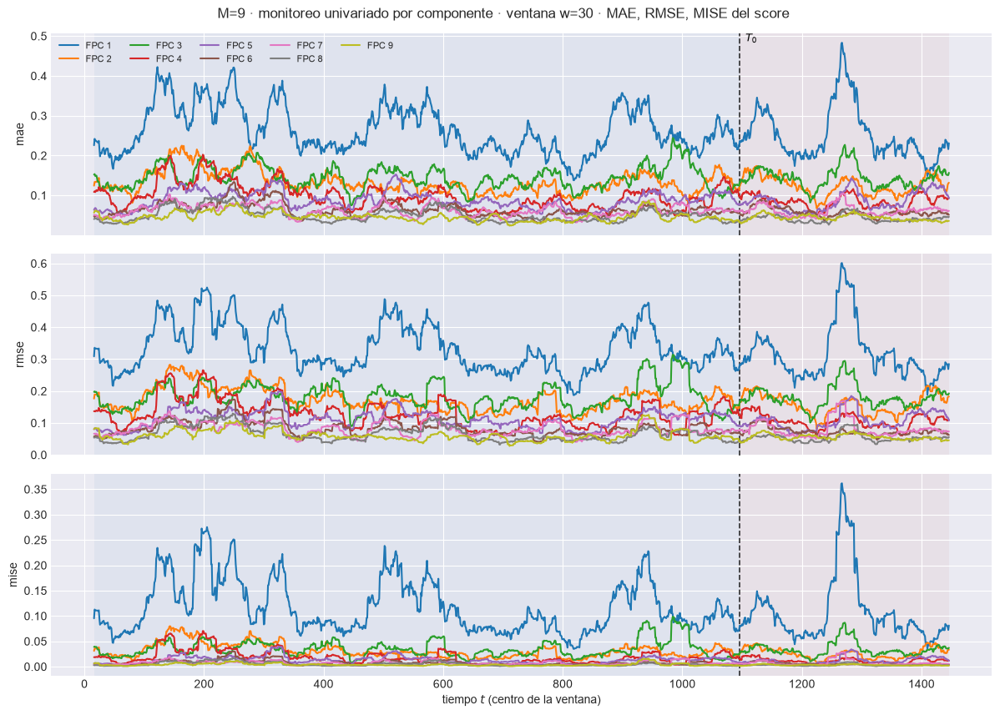

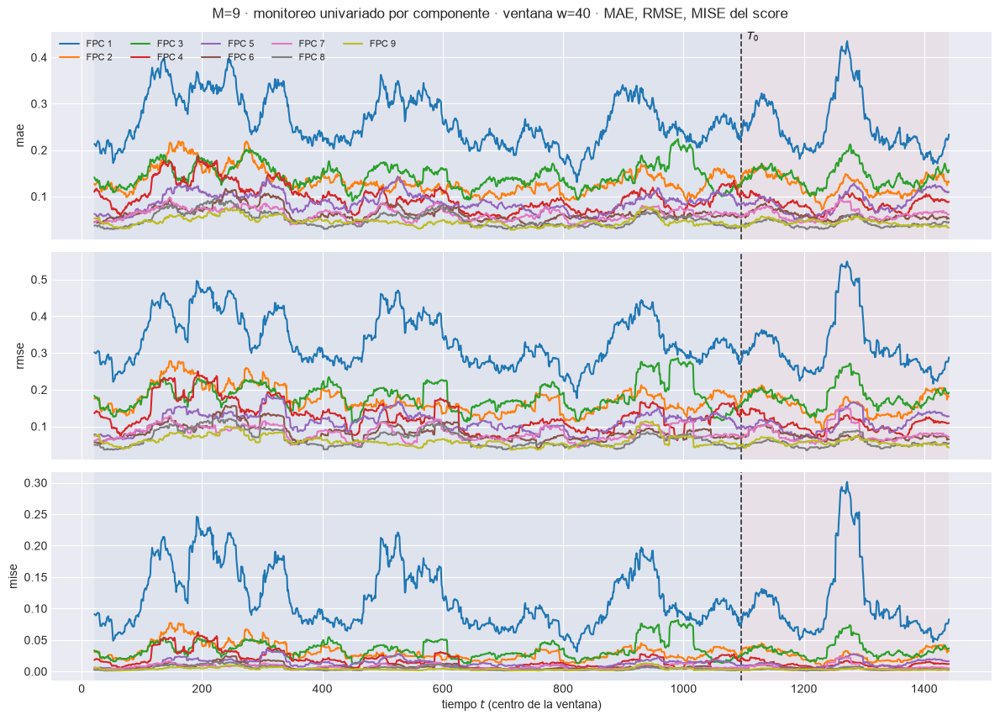

[ventana_movil_scores[FPC 1, w=30]] inicio (1431 pasos)


  1/1431 ( 0.1%) t=0.0s eta=1.4s  t=16 [train] rmse=0.3102


  71/1431 ( 5.0%) t=0.0s eta=0.1s  t=86 [train] rmse=0.2894


  142/1431 ( 9.9%) t=0.0s eta=0.1s  t=157 [train] rmse=0.3657


  213/1431 (14.9%) t=0.0s eta=0.1s  t=228 [train] rmse=0.4038


...

  1278/1431 (89.3%) t=0.1s eta=0.0s  t=1293 [test] rmse=0.03679


  1349/1431 (94.3%) t=0.1s eta=0.0s  t=1364 [test] rmse=0.04447


  1420/1431 (99.2%) t=0.1s eta=0.0s  t=1435 [test] rmse=0.04282


  1431/1431 (100.0%) t=0.1s eta=0.0s  t=1446 [test] rmse=0.04441


[ventana_movil_scores[FPC 10, w=30]] listo: 1431 pasos en 0.1s  29 ventanas cruzan T0


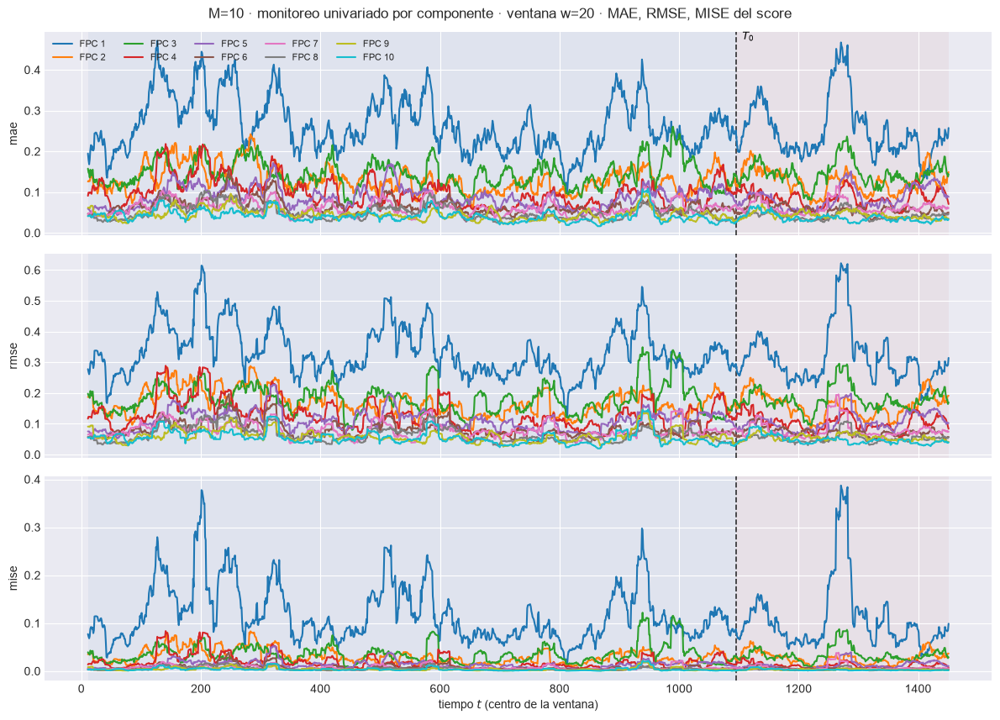

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.07556  w=30 test=0.06736


  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.1015  w=30 test=0.08699


  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.01029  w=30 test=0.007567


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m10\91_ventana_univariado_w30.png


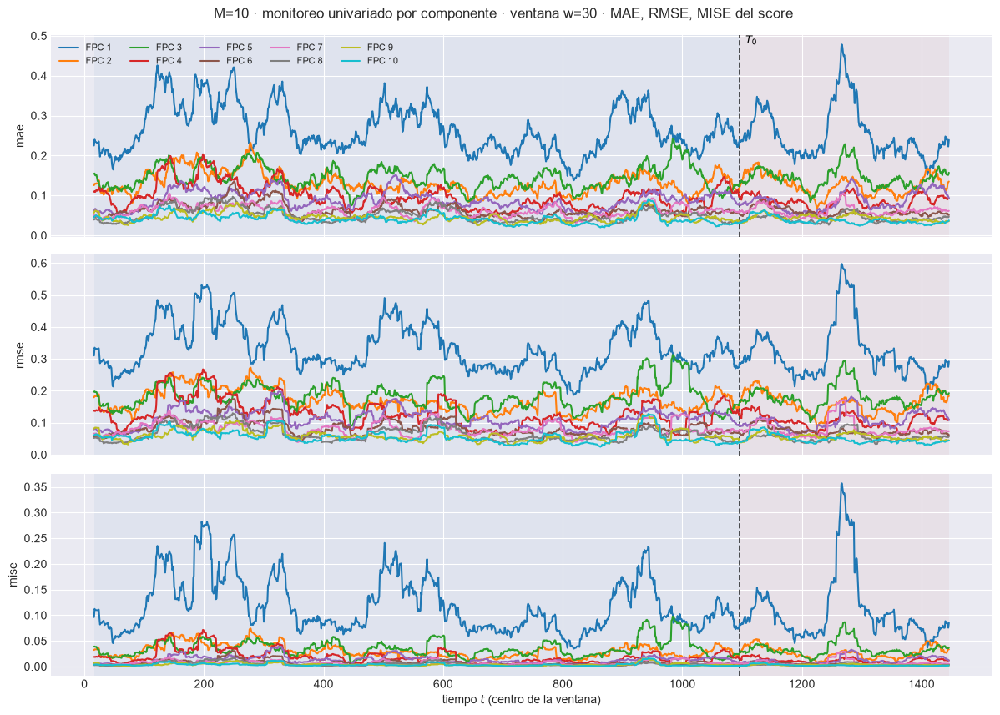

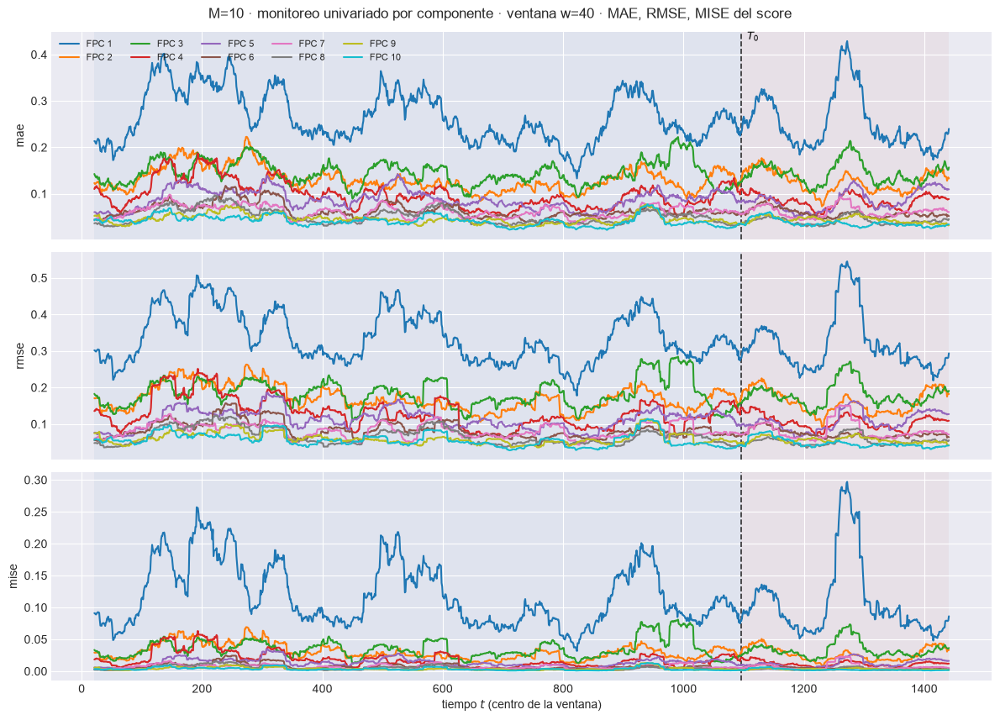

In [22]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

La banda es `li_s`/`ls_s` de §3, antes de propagar.

### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

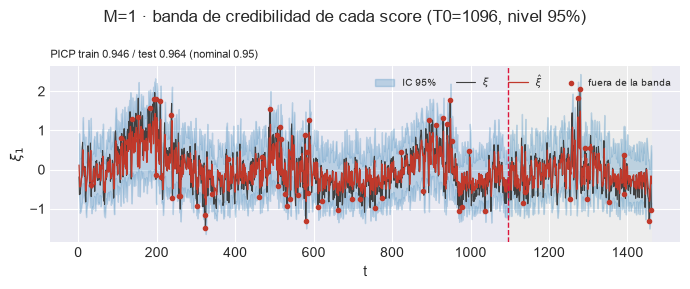

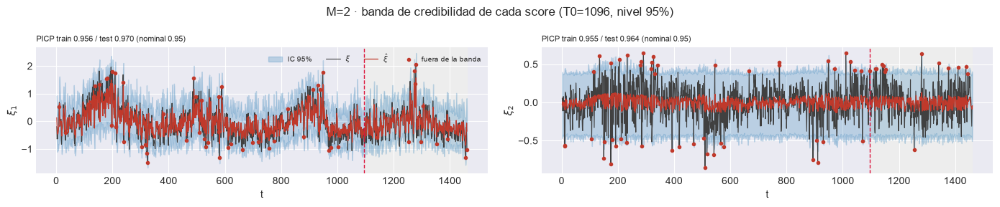

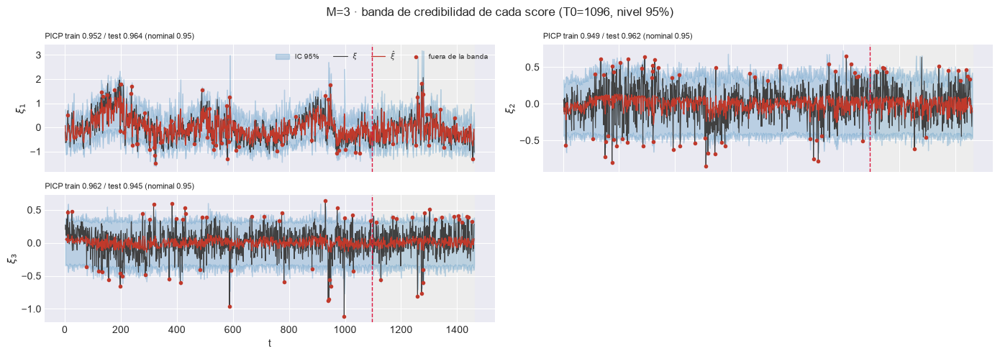

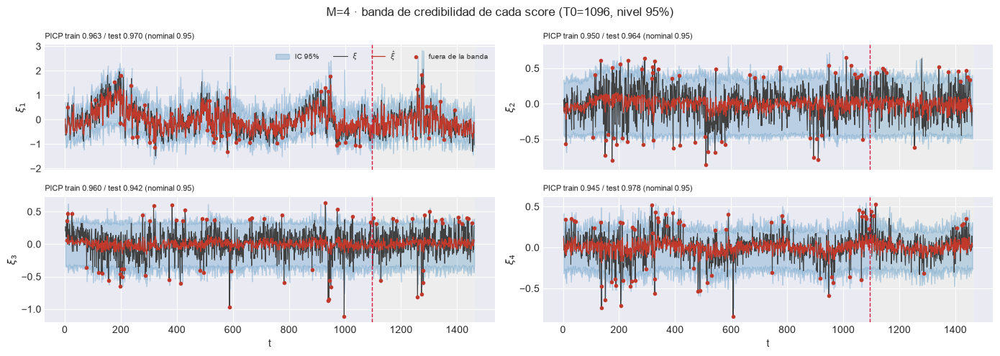

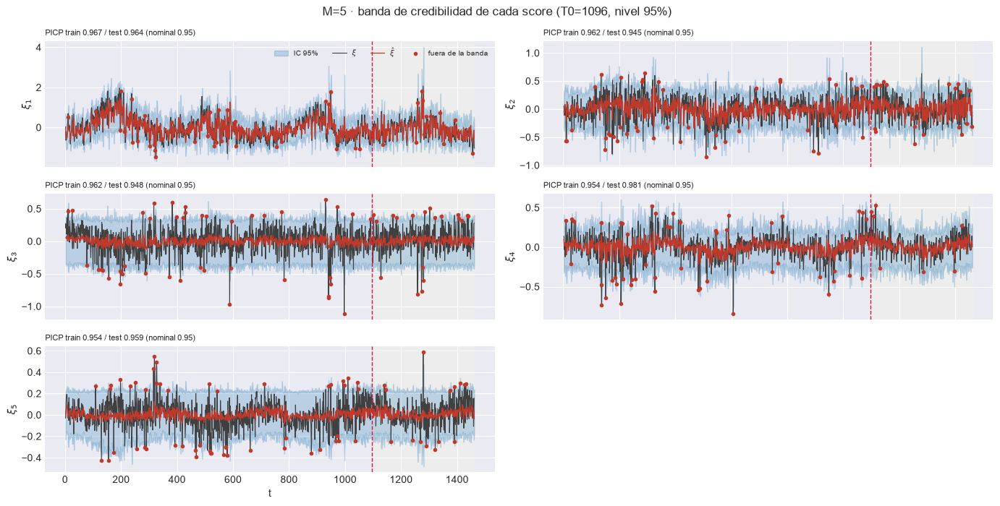

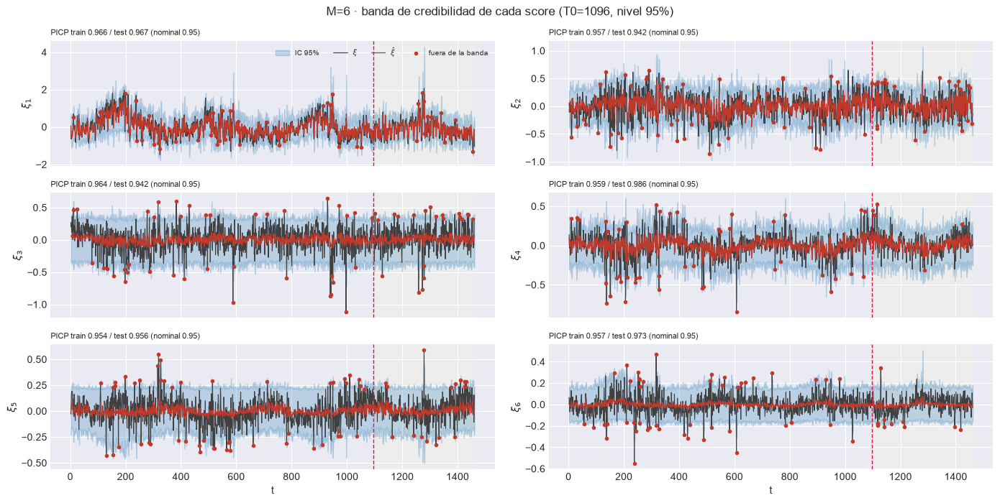

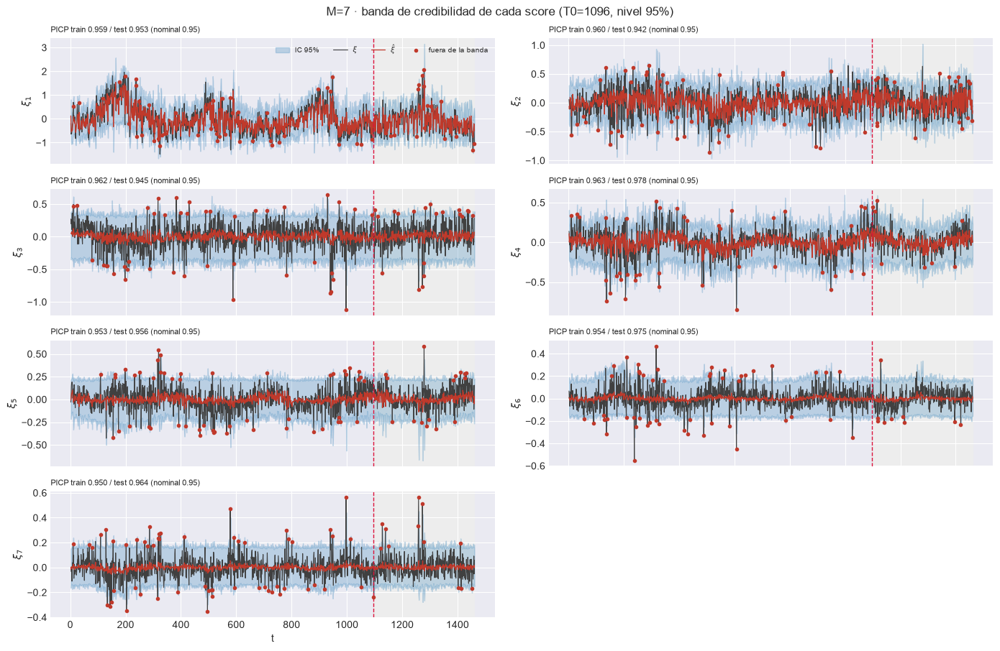

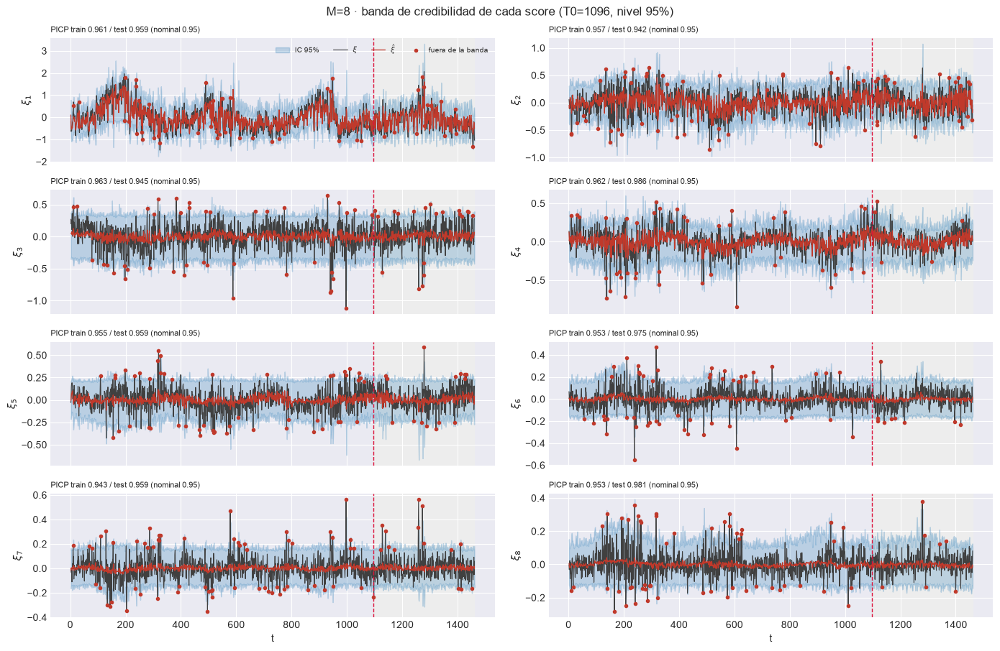

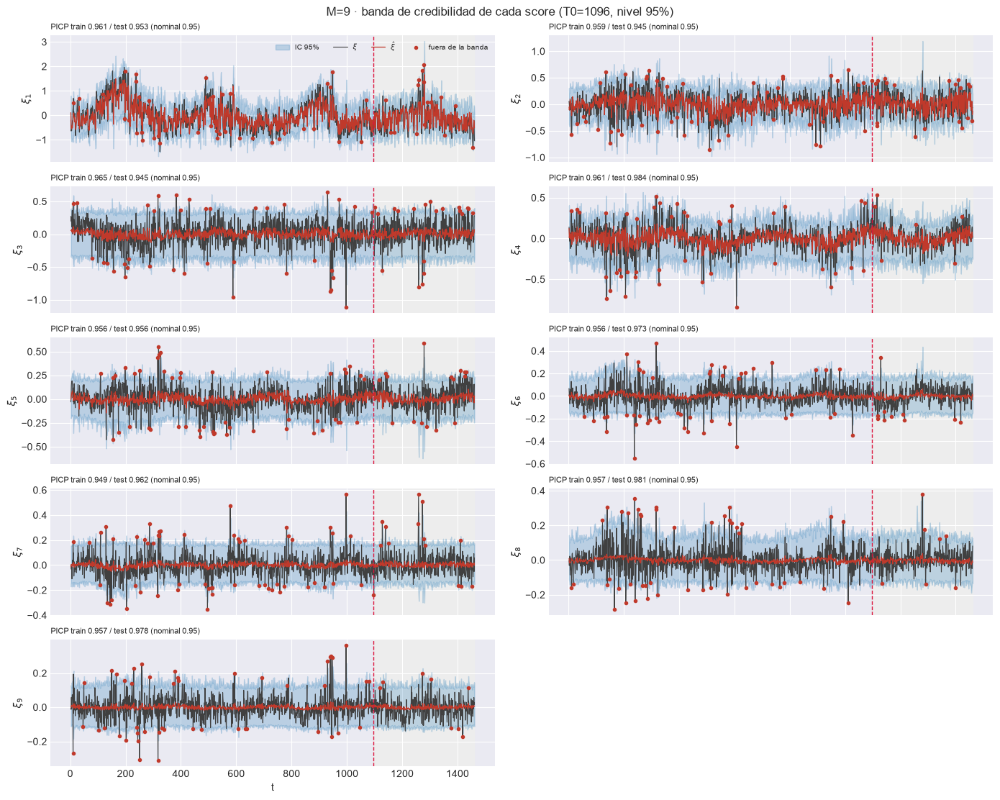

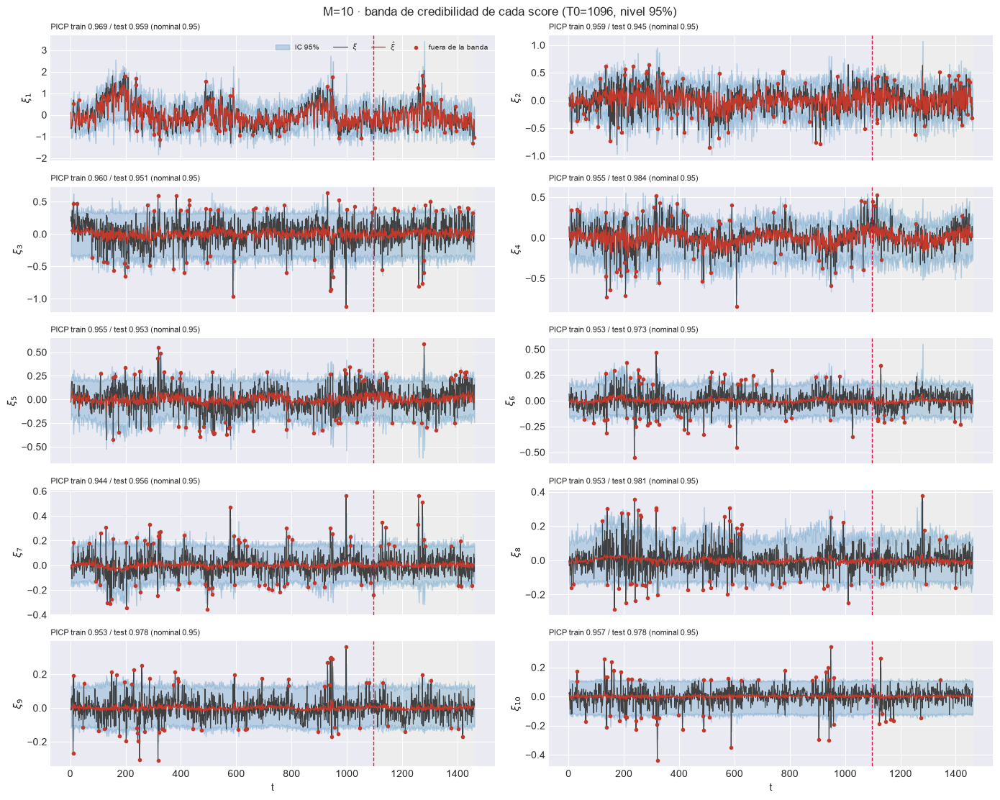

In [23]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

PICP, MPIW, Winkler y ACE por componente; global por bloque y sobre la ventana móvil.

OK ninguna componente se aleja mas de 0.1 del nominal en test.


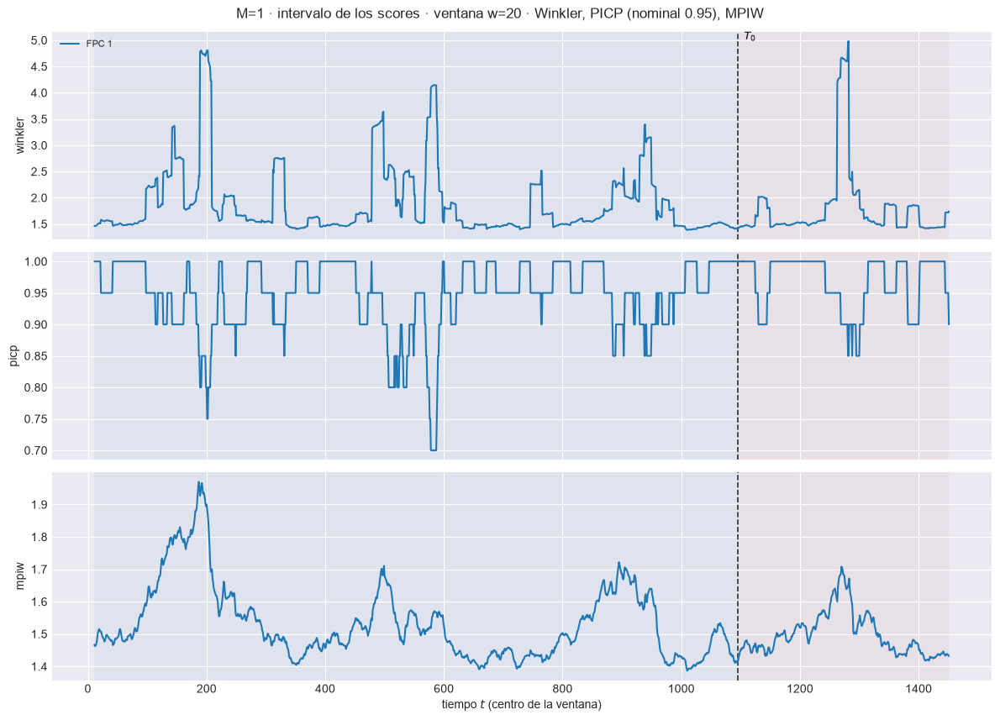

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.629  w=30 test=1.623


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.504  w=30 test=1.491


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m01\93_ventana_scores_intervalo_w30.png


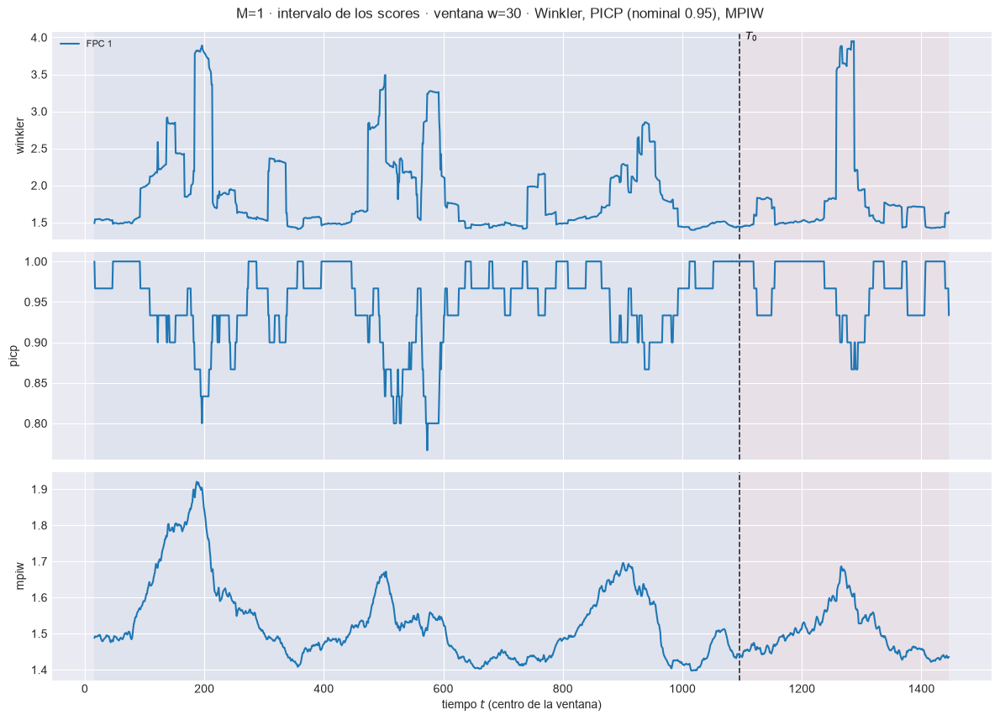

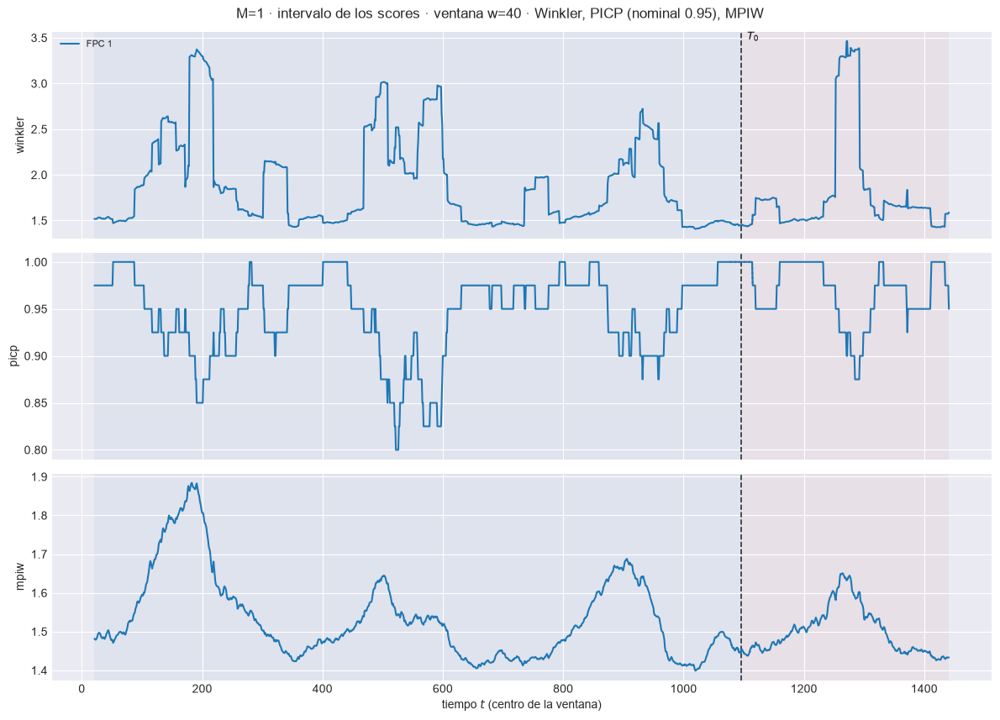

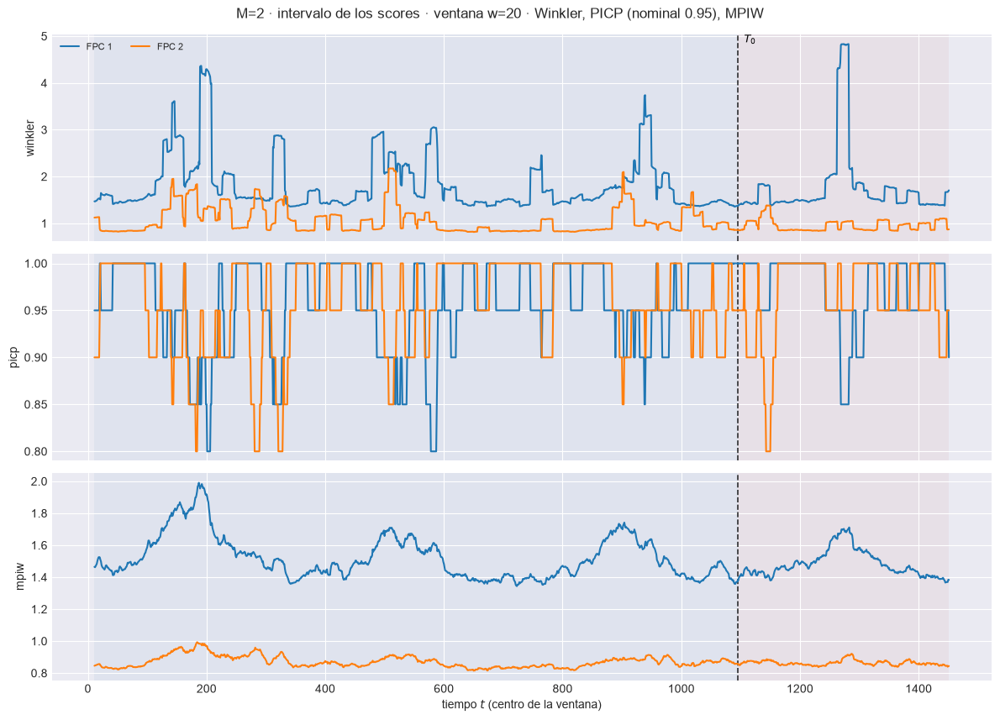

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.426  w=30 test=1.312


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.174  w=30 test=1.14


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m02\93_ventana_scores_intervalo_w30.png


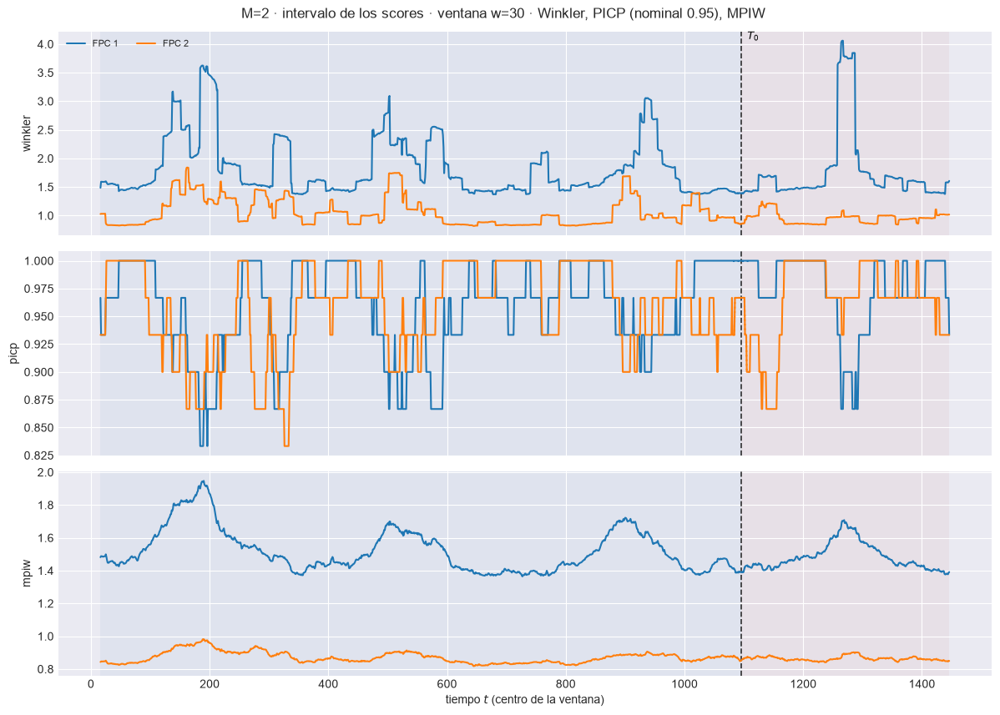

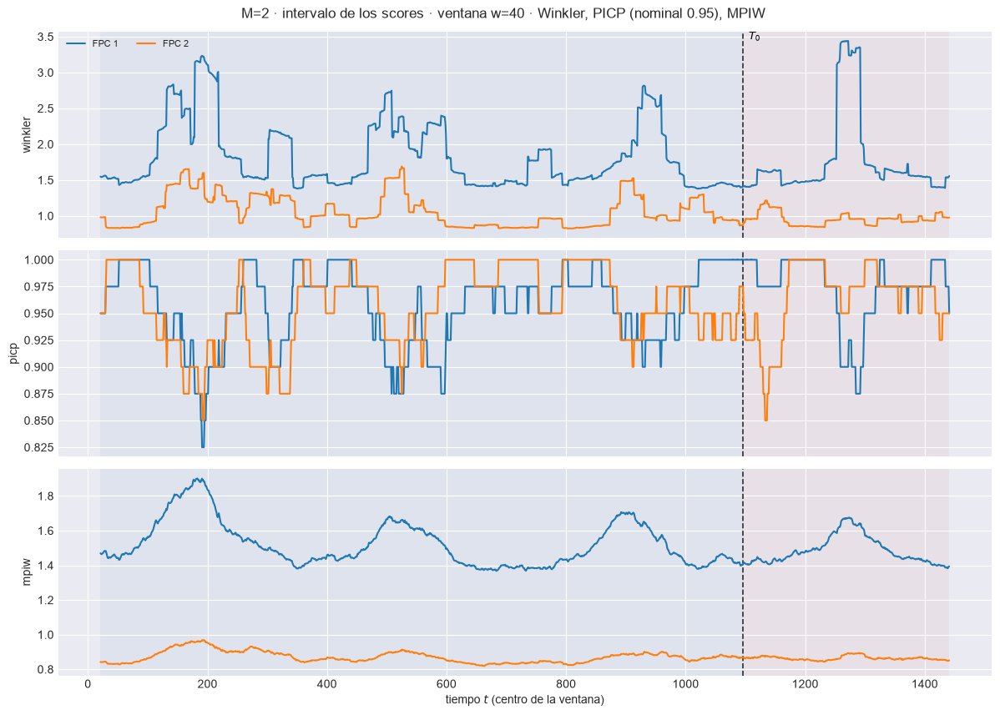

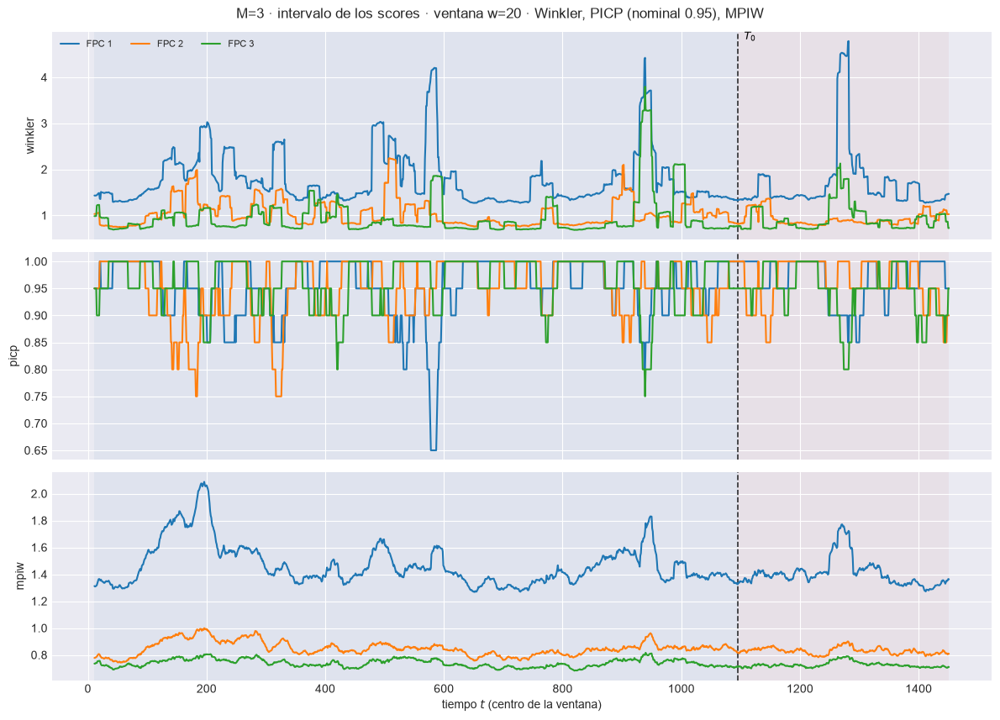

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.109  w=30 test=1.016


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.8474  w=30 test=0.829


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m03\93_ventana_scores_intervalo_w30.png


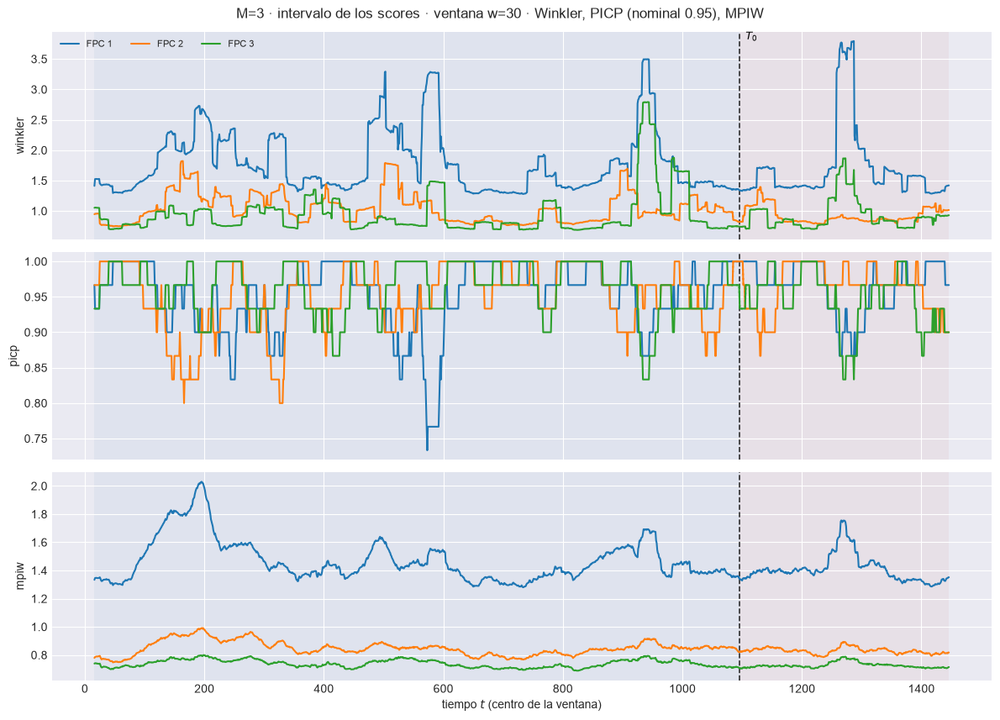

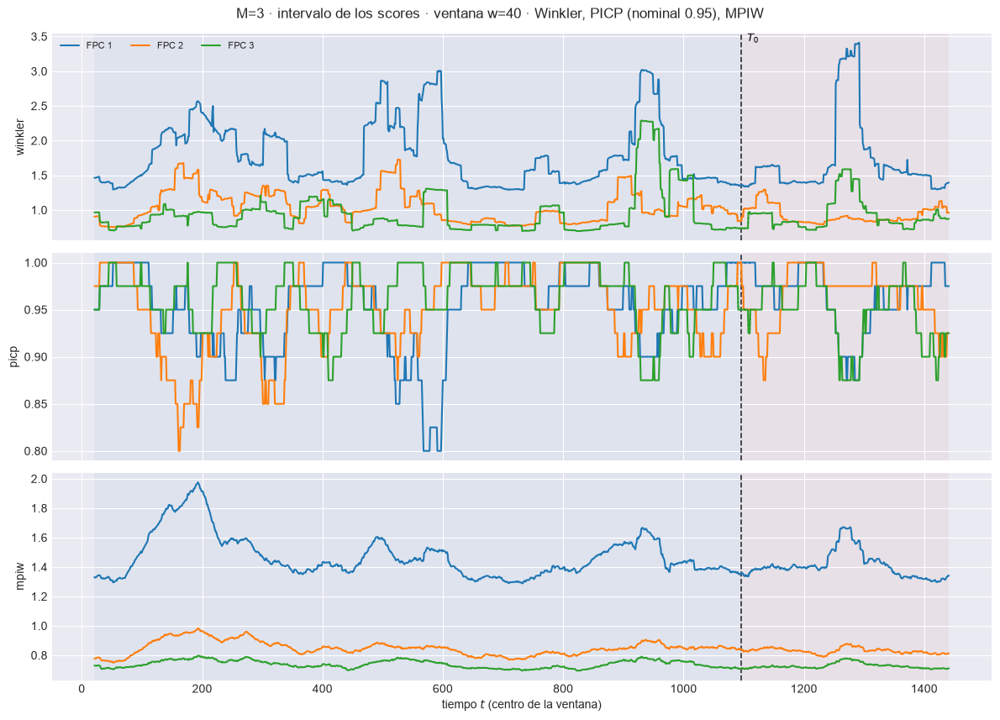

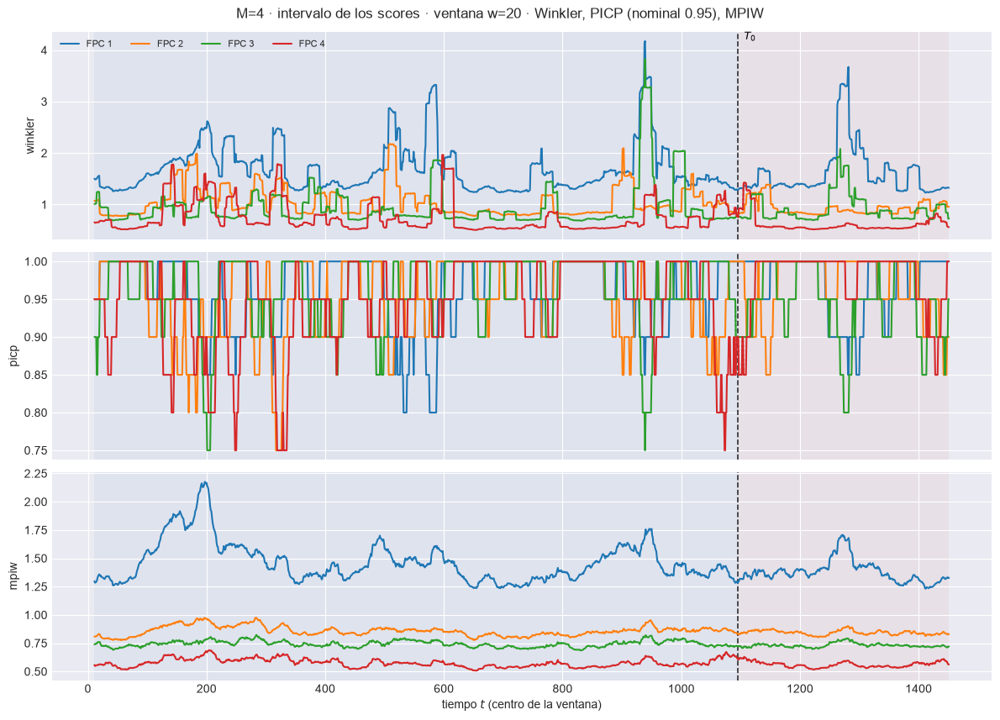

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.9789  w=30 test=0.8967


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.7902  w=30 test=0.7953


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m04\93_ventana_scores_intervalo_w30.png


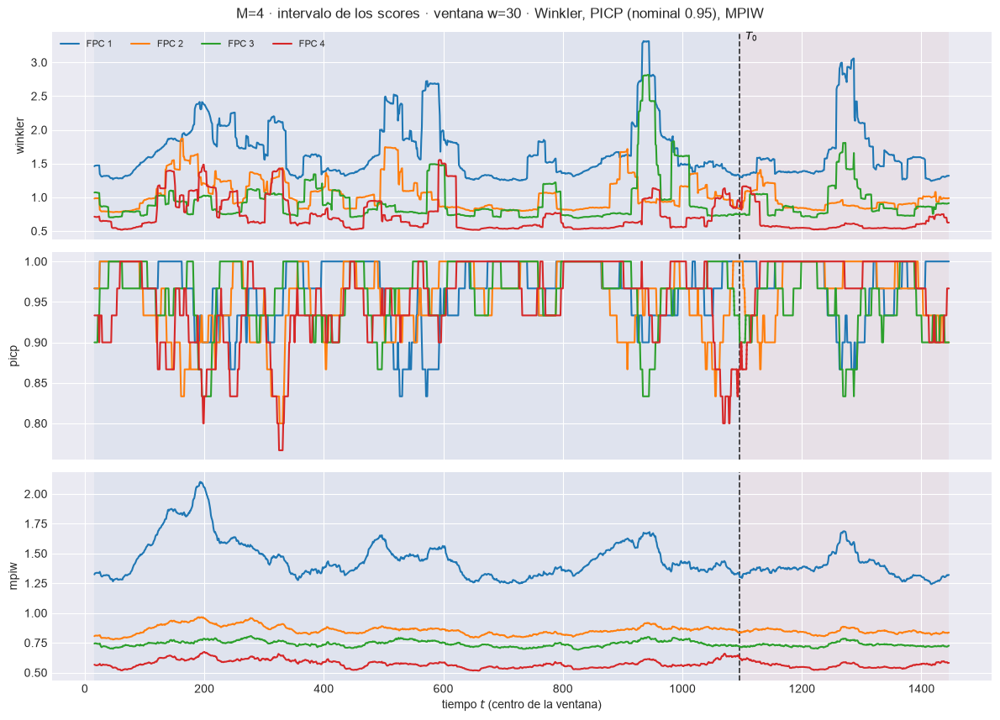

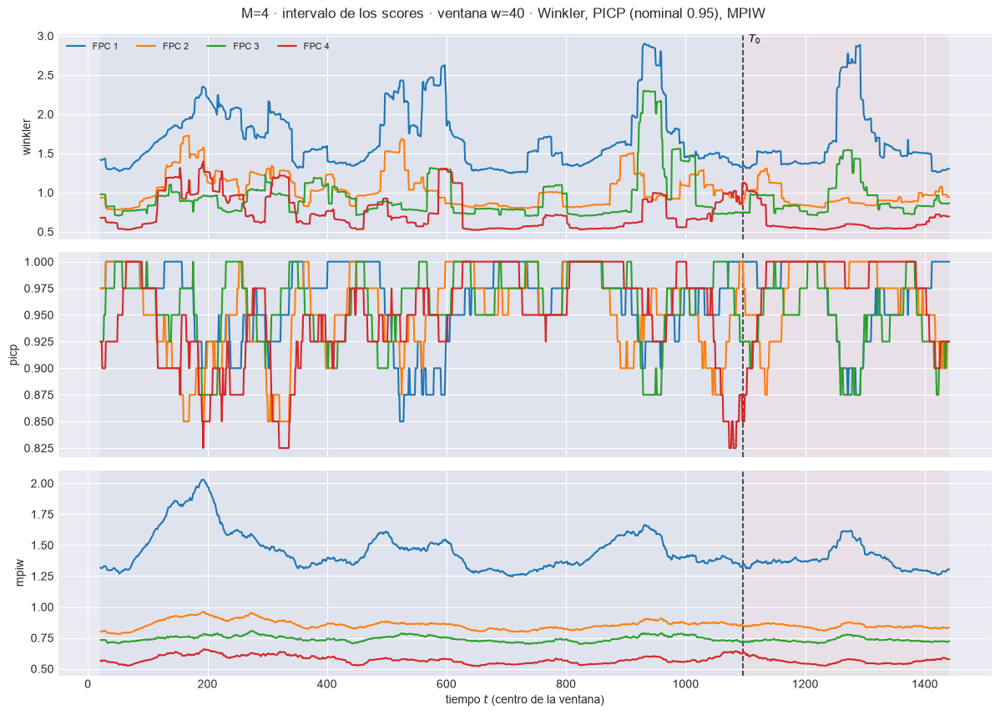

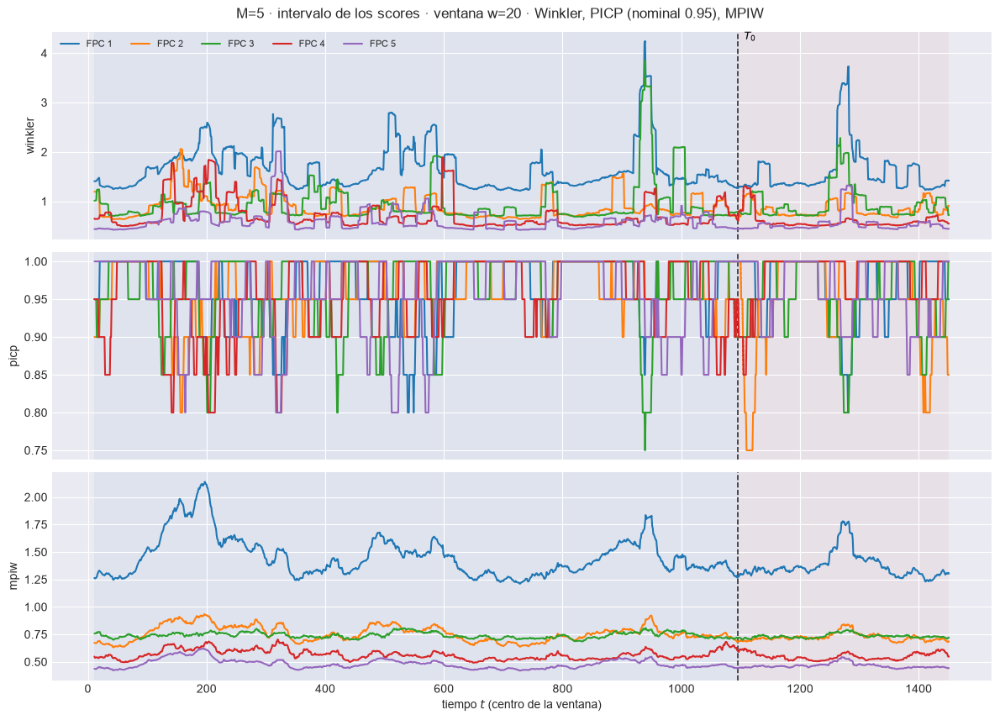

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.793  w=30 test=0.7628


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.7199  w=30 test=0.715


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m05\93_ventana_scores_intervalo_w30.png


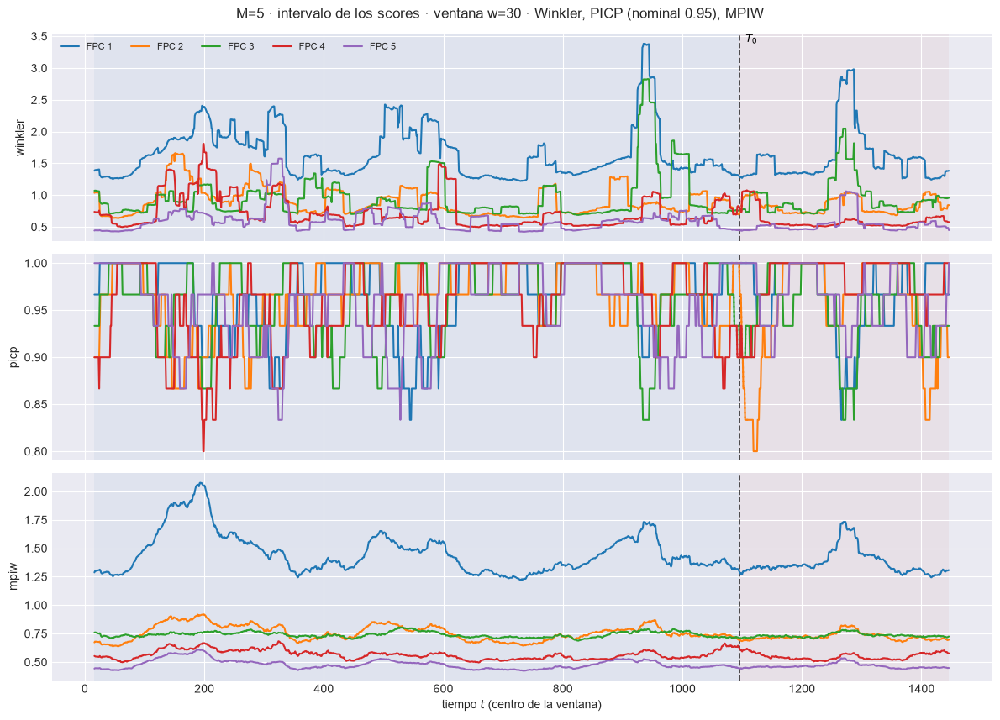

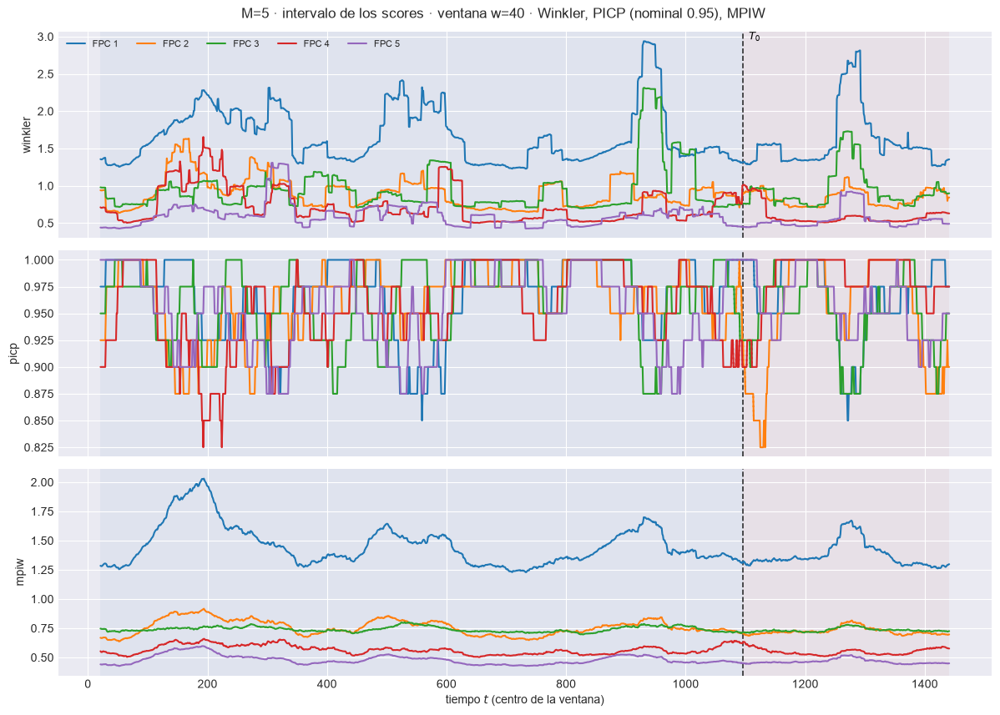

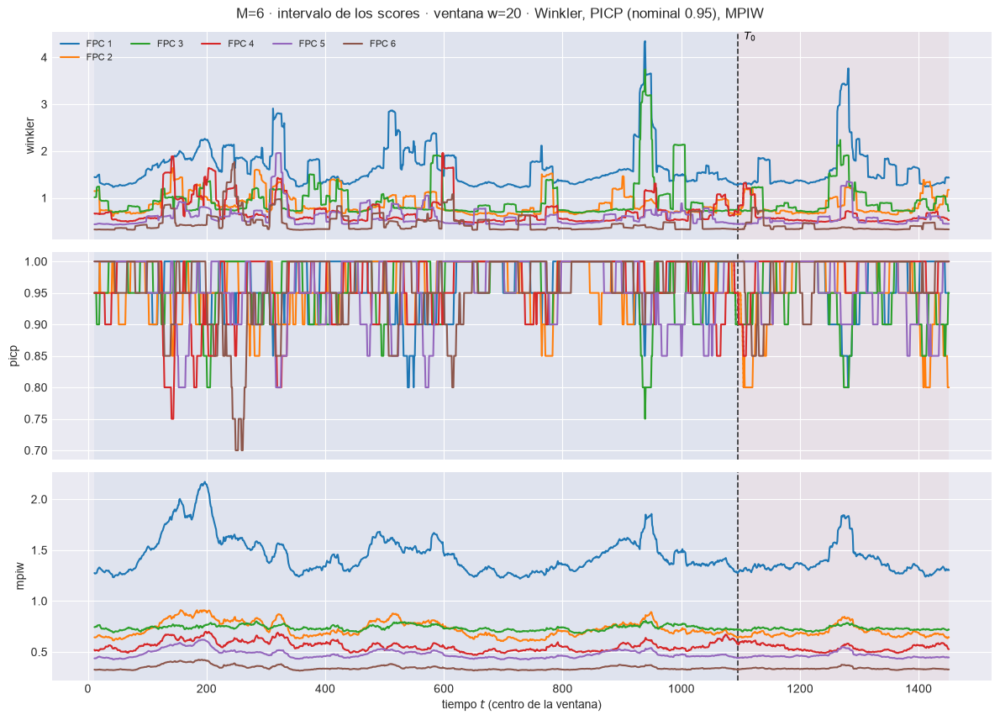

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.7272  w=30 test=0.6808


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.6326  w=30 test=0.626


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m06\93_ventana_scores_intervalo_w30.png


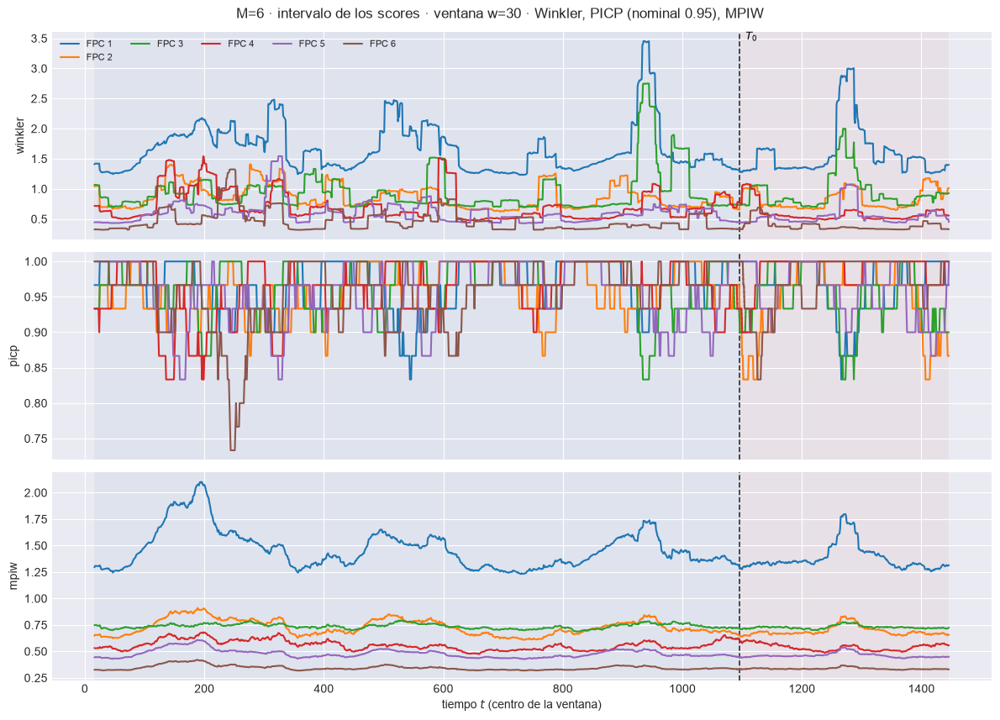

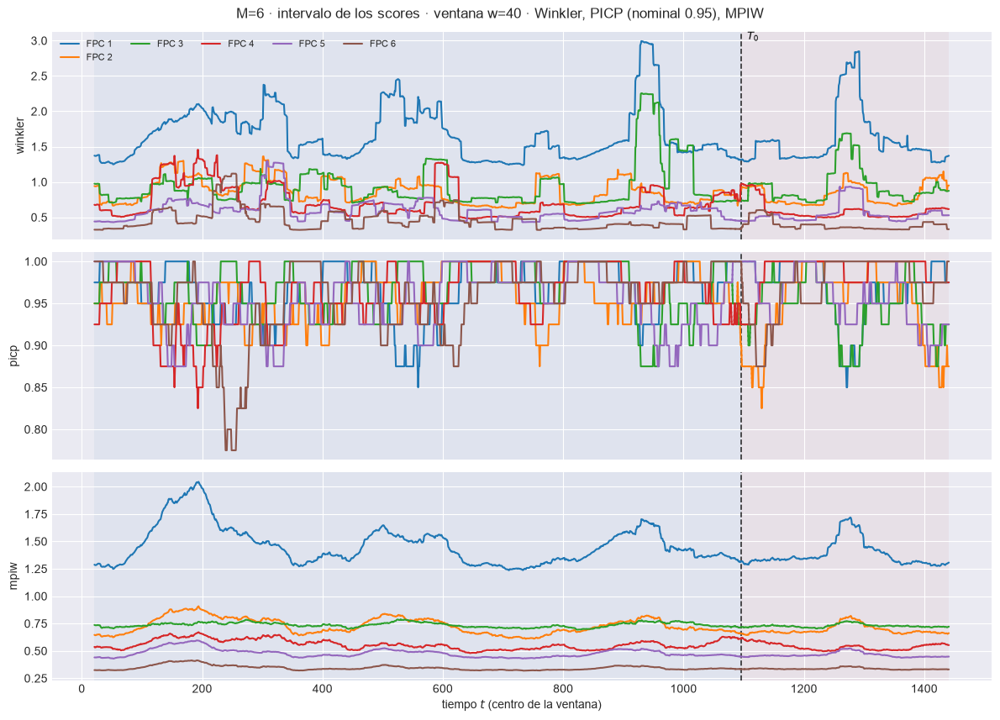

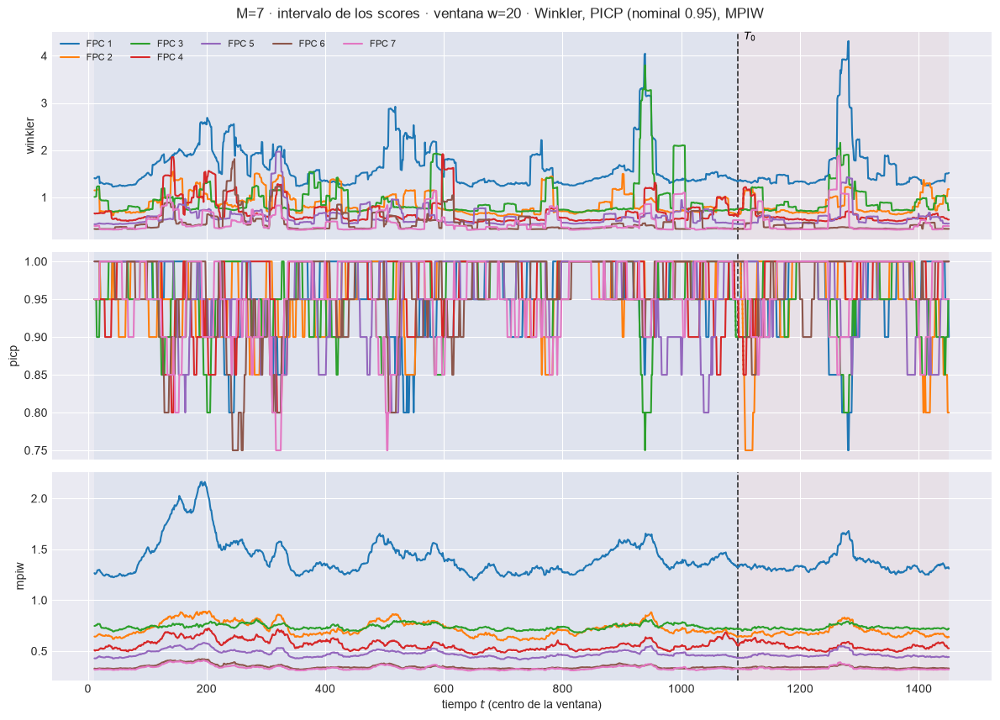

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.696  w=30 test=0.6177


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.5581  w=30 test=0.5393


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m07\93_ventana_scores_intervalo_w30.png


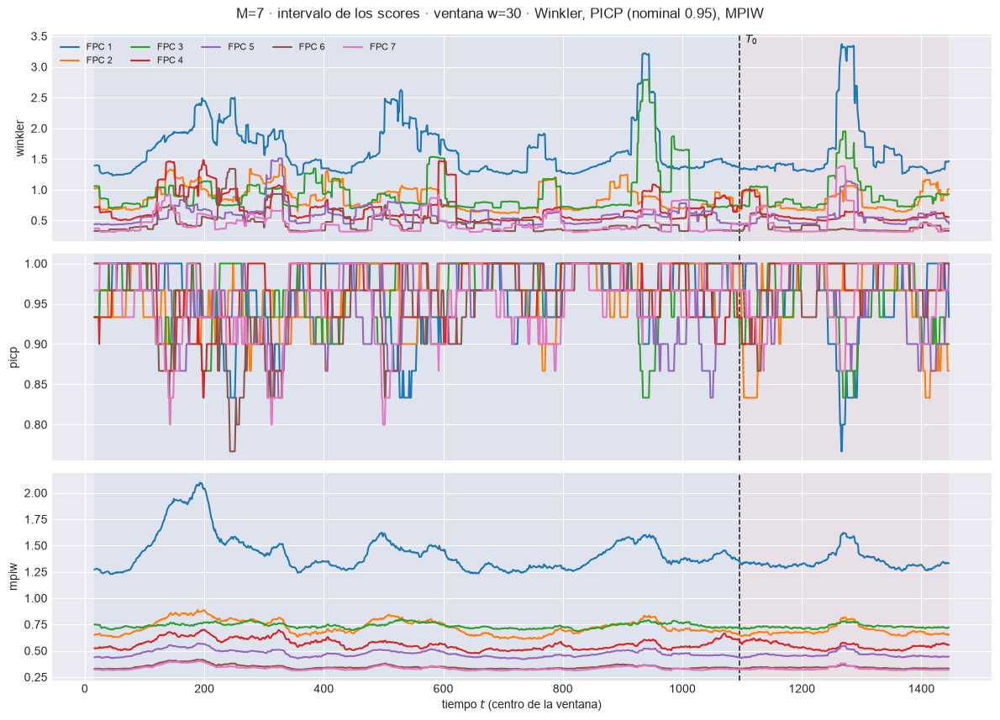

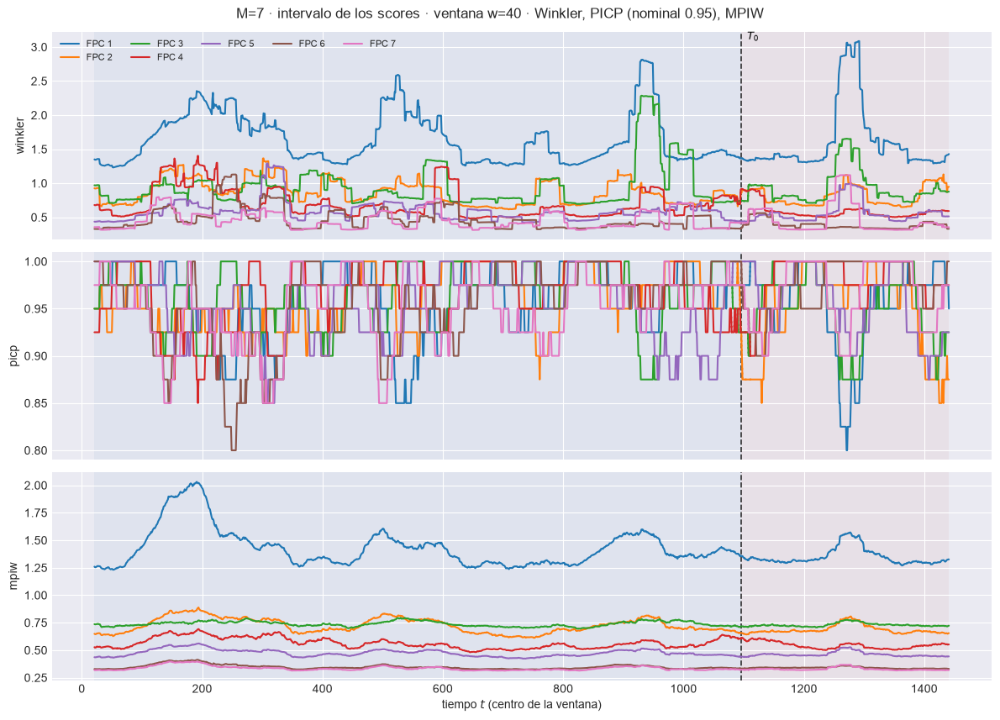

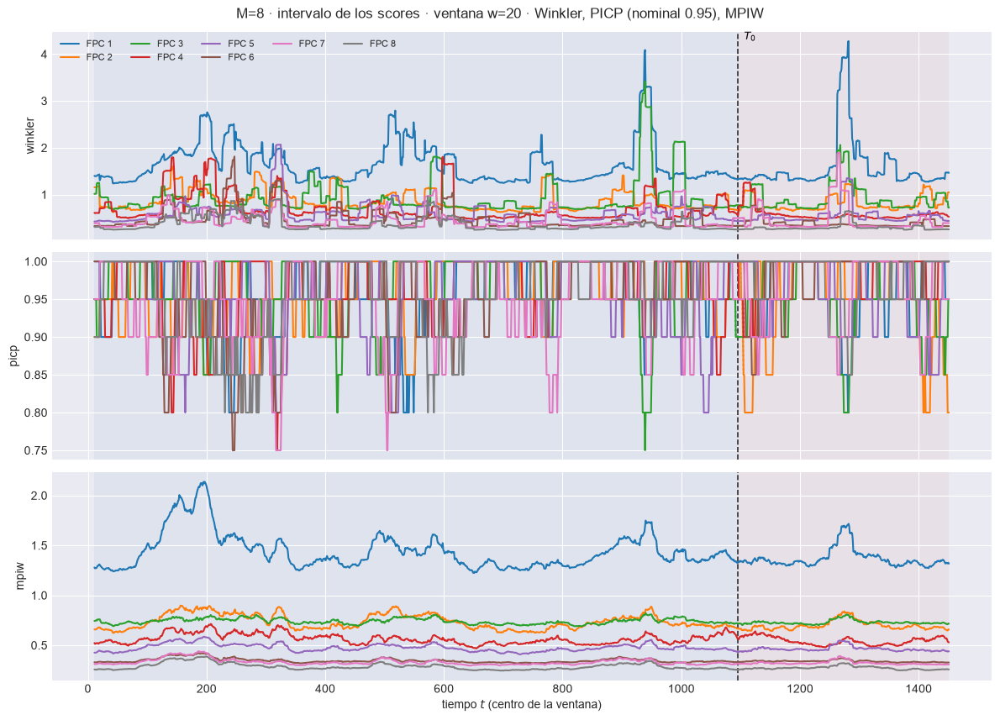

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.6549  w=30 test=0.5572


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.5135  w=30 test=0.4981


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m08\93_ventana_scores_intervalo_w30.png


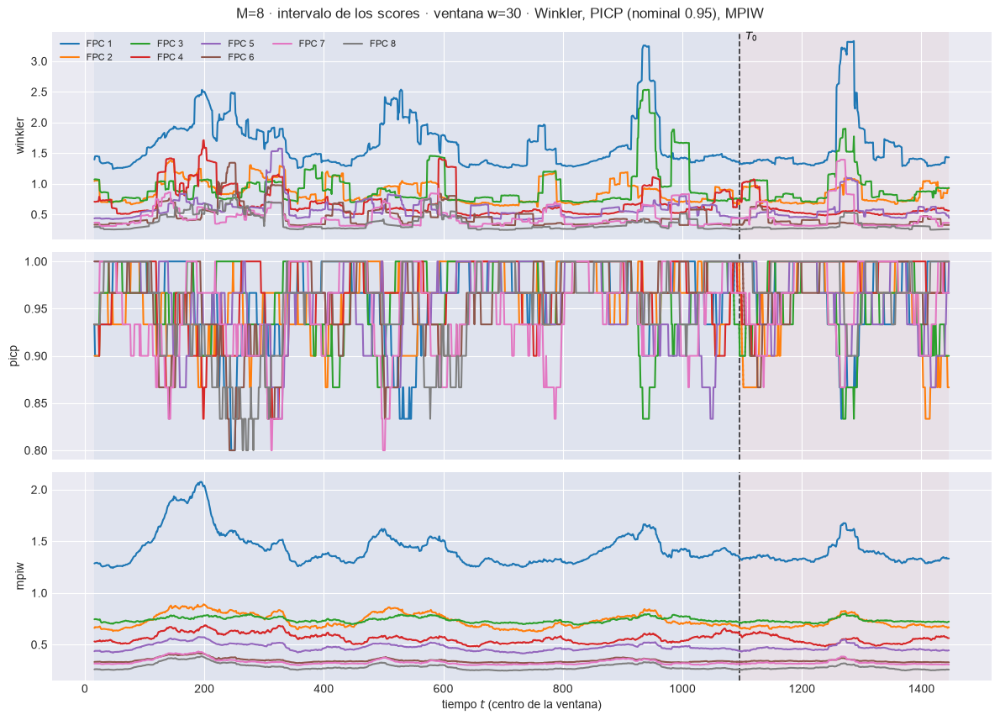

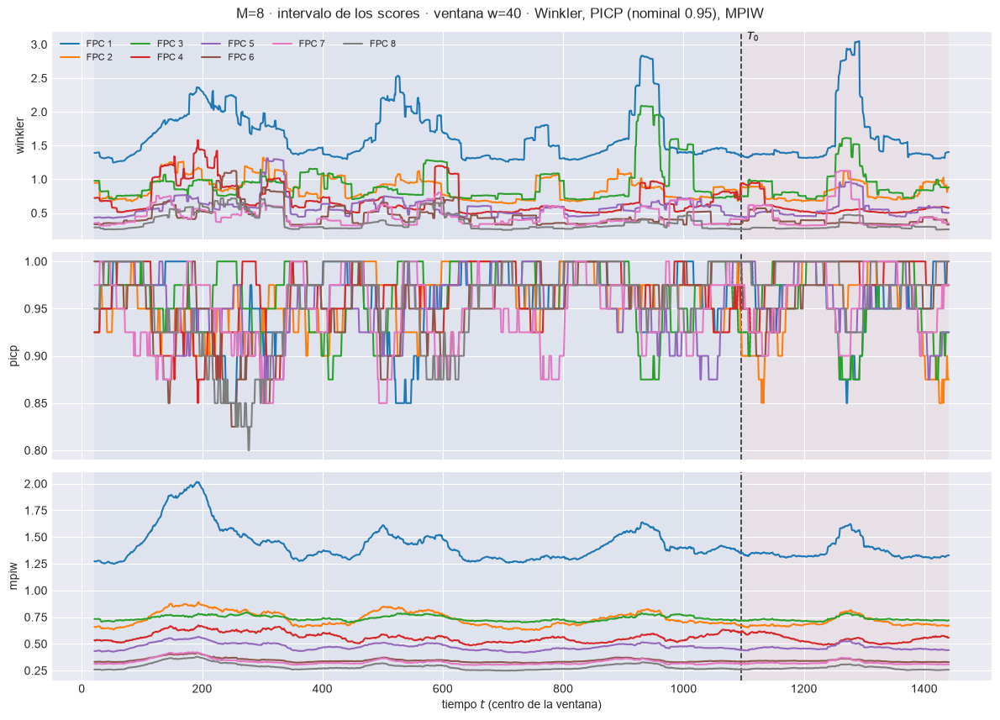

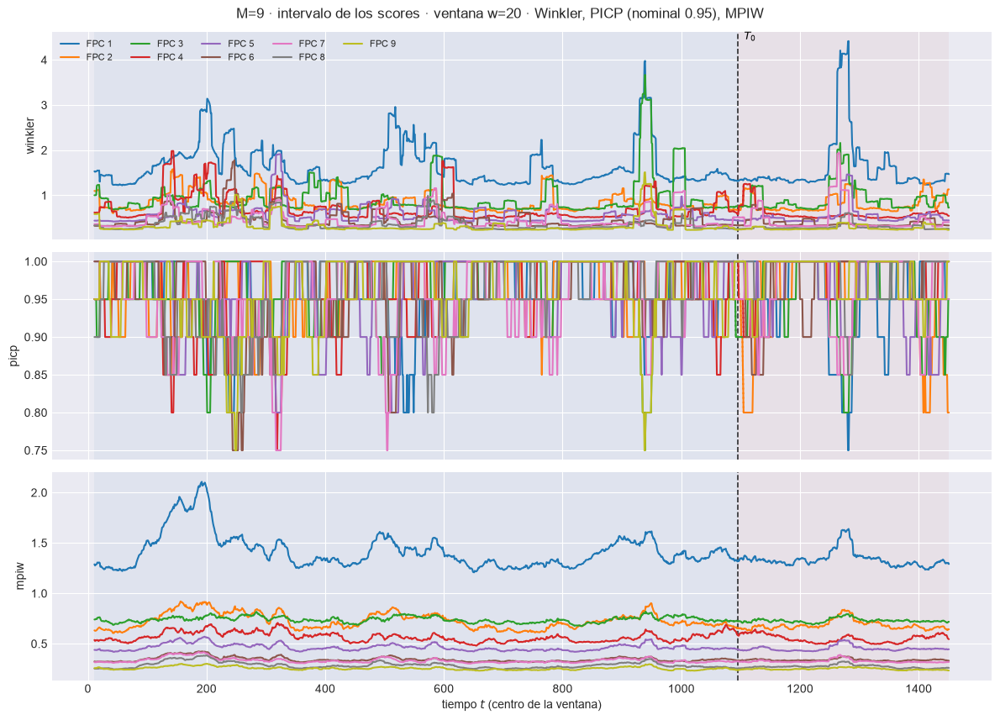

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.5927  w=30 test=0.5165


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.4557  w=30 test=0.4471


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m09\93_ventana_scores_intervalo_w30.png


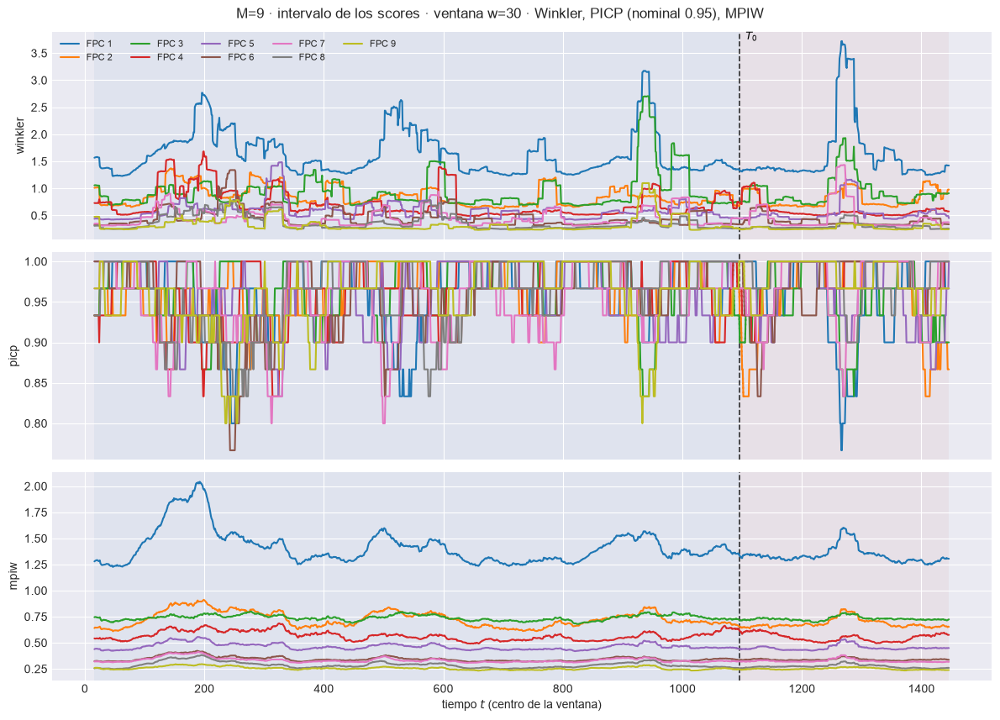

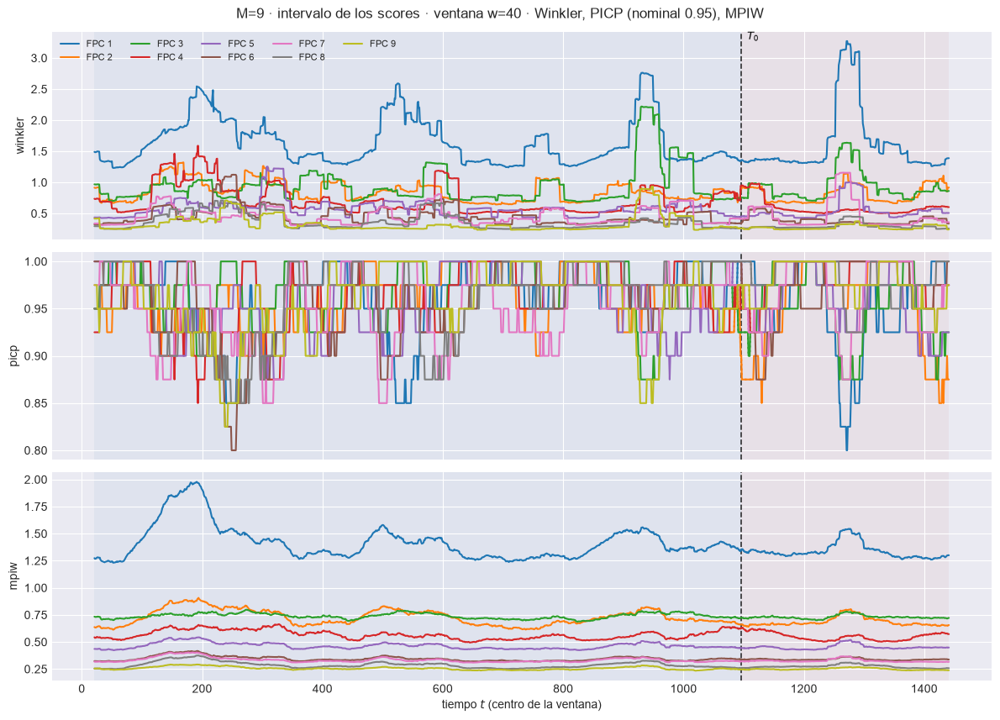

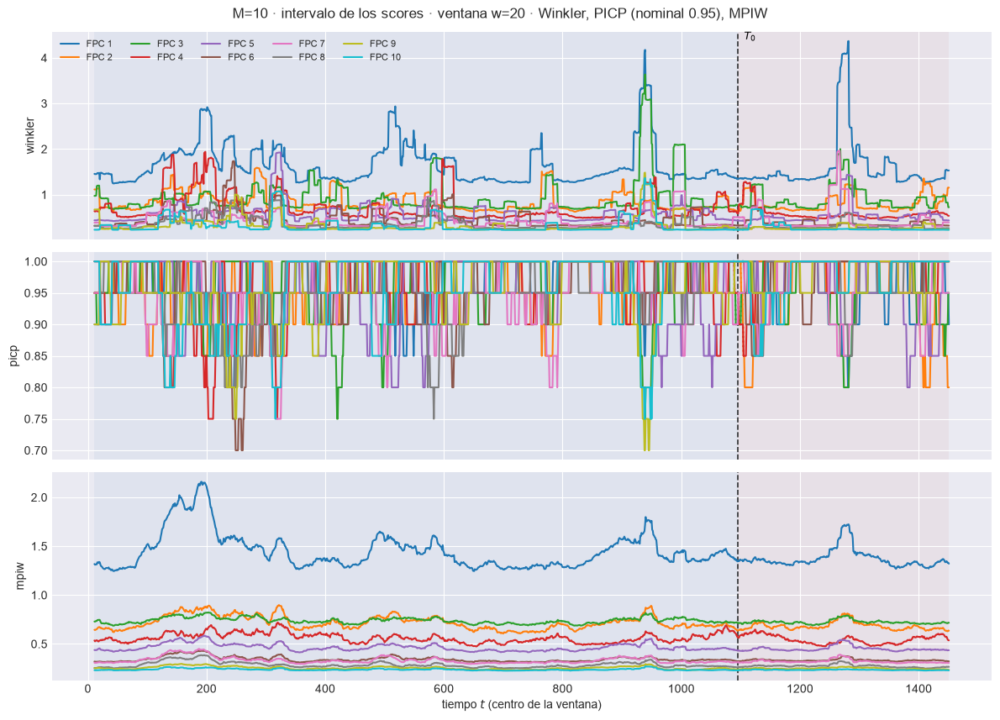

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.1s  winkler: w=30 train=0.5557  w=30 test=0.489


  2/3 (66.7%) t=0.1s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=0.4239  w=30 test=0.4057


[plot_ventana_movil] listo: 3 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_sa1_103_v02_m10\93_ventana_scores_intervalo_w30.png


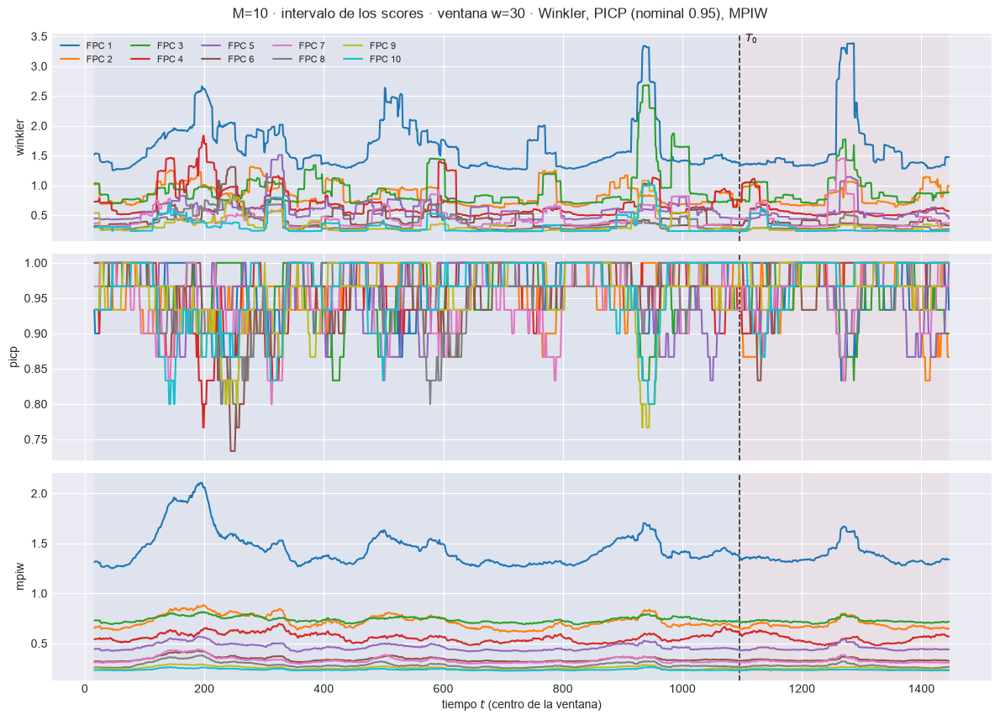

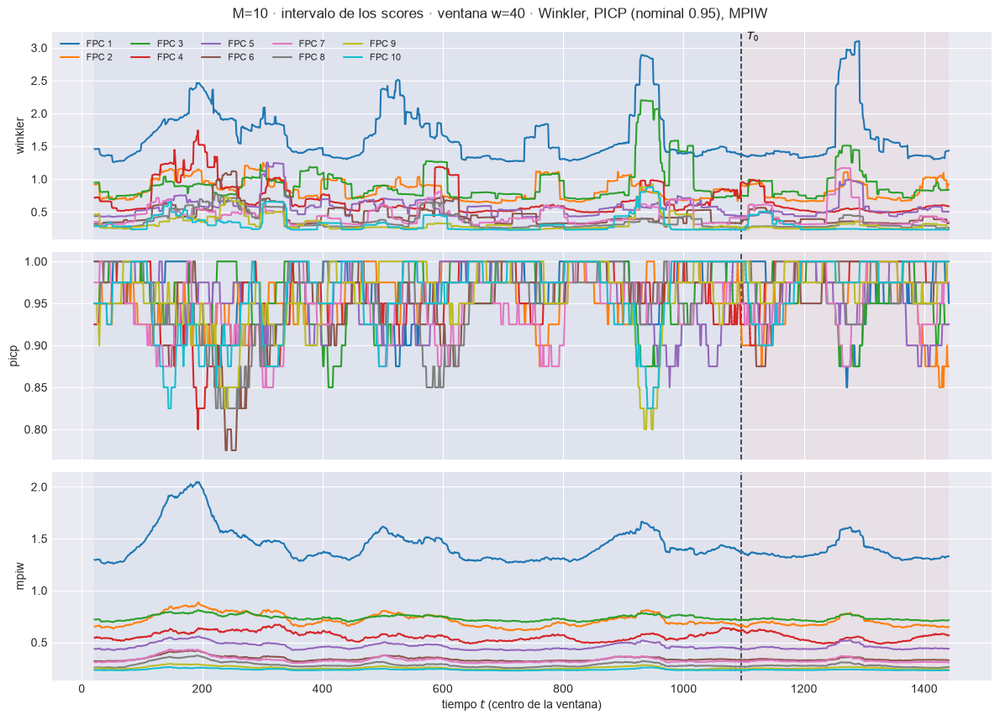

In [24]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente con la diagonal; train y test con marcador distinto.

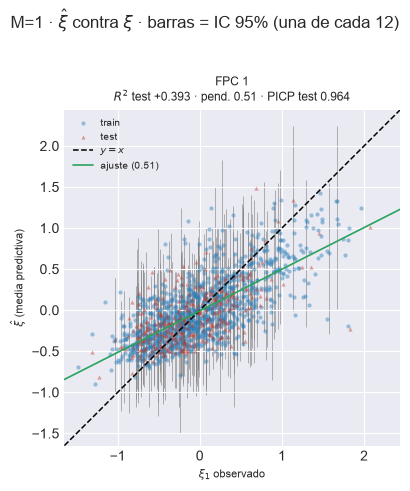

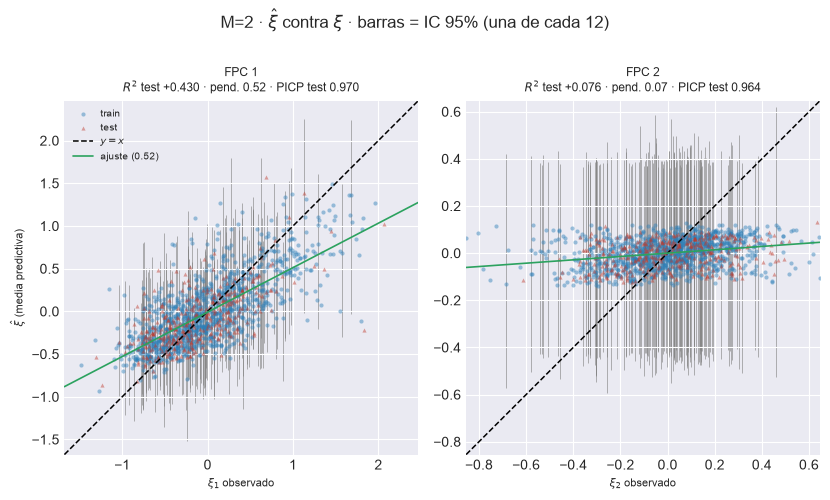

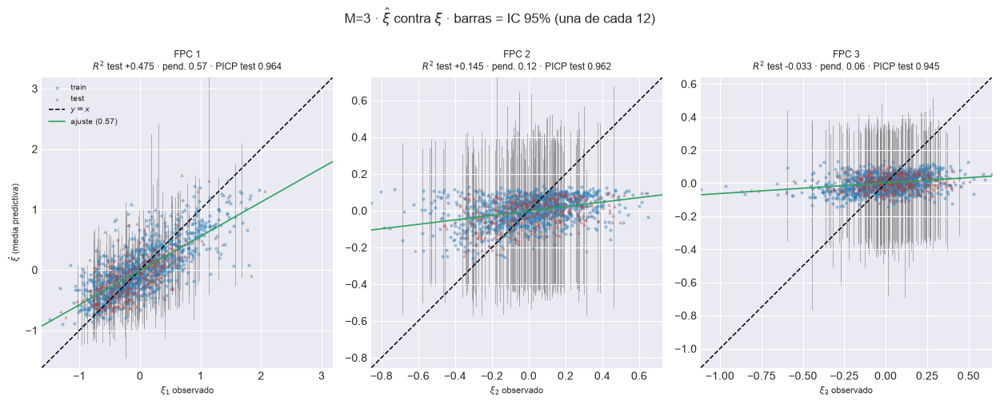

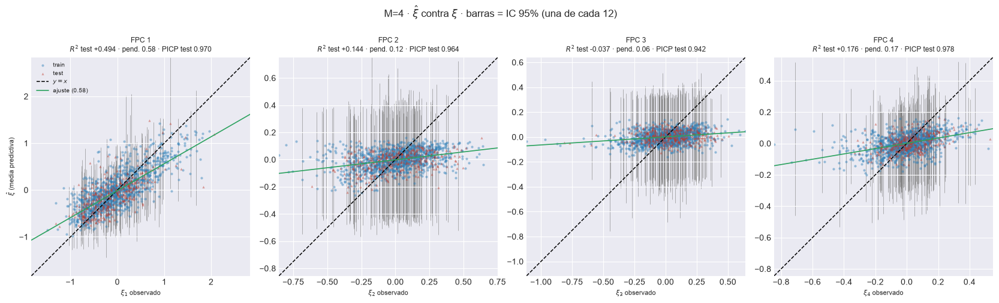

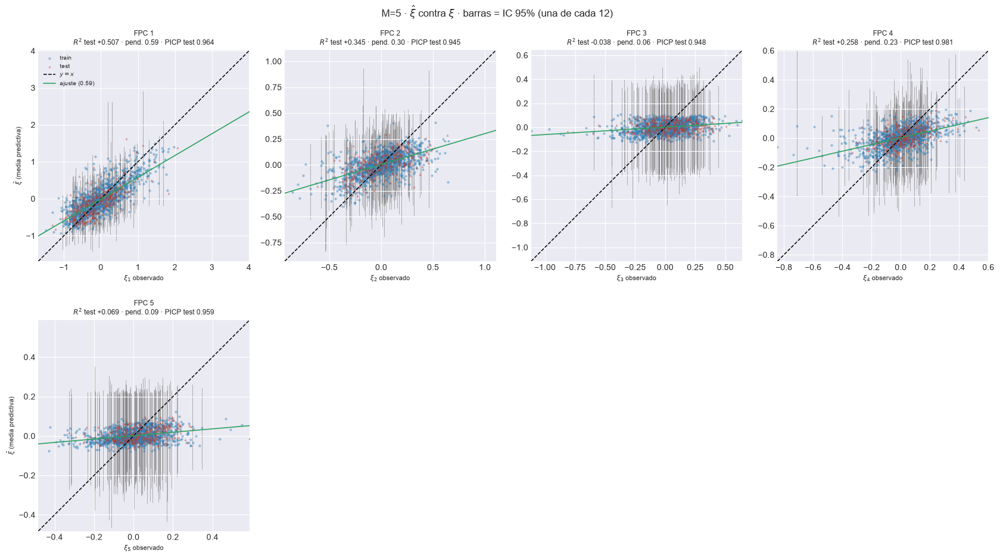

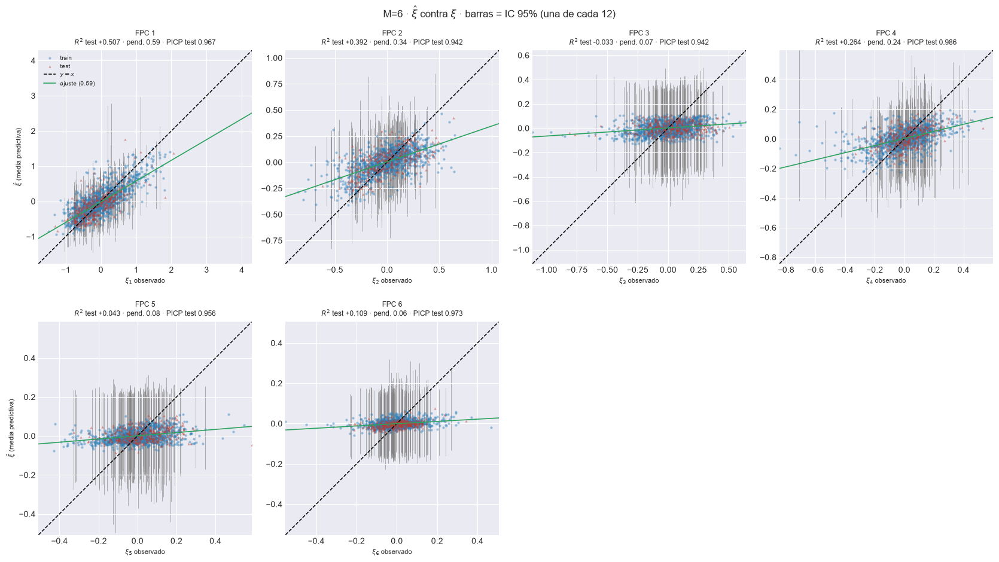

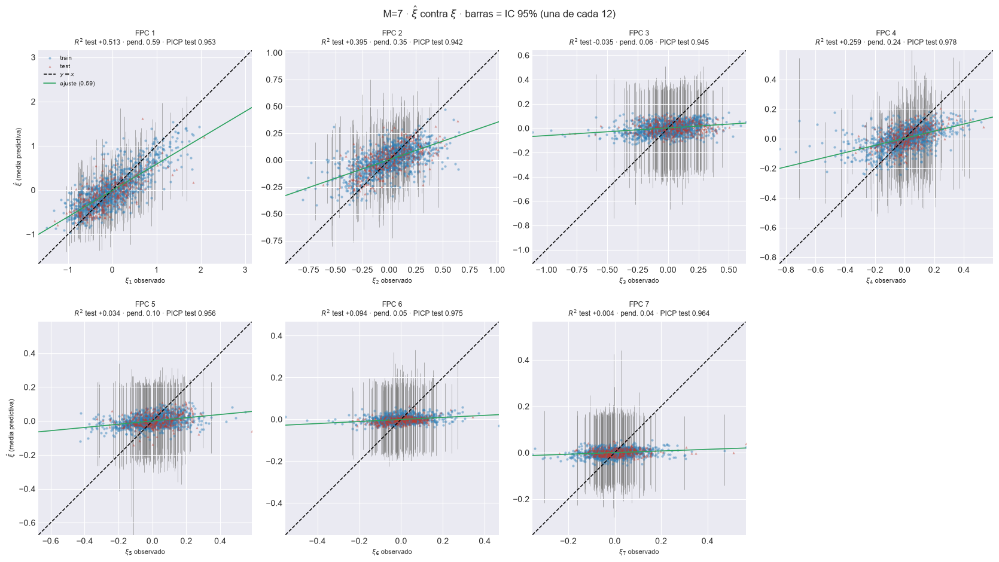

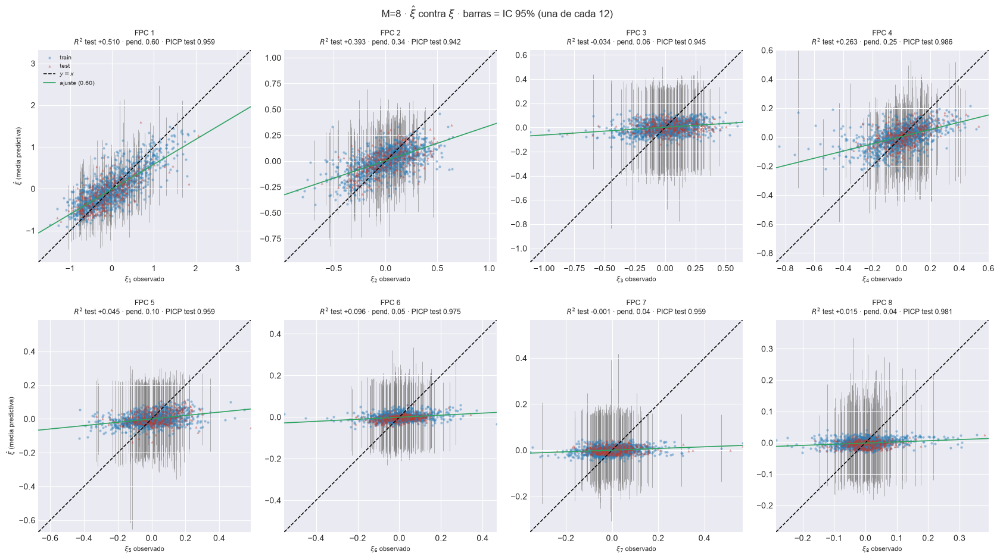

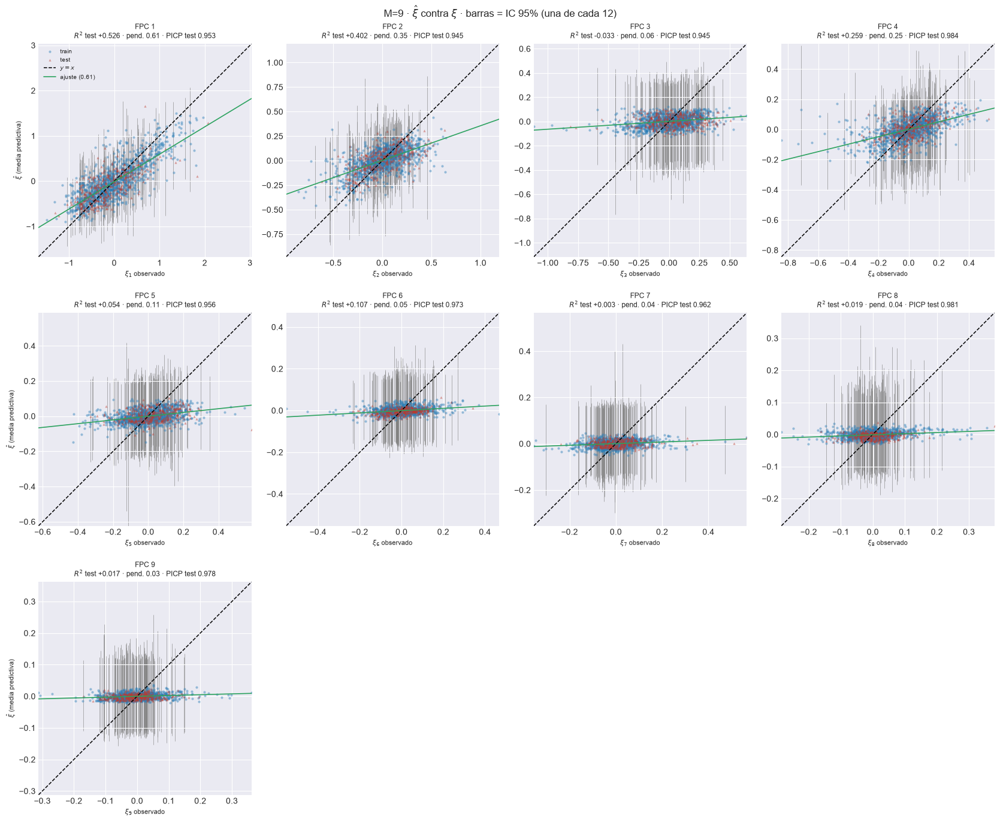

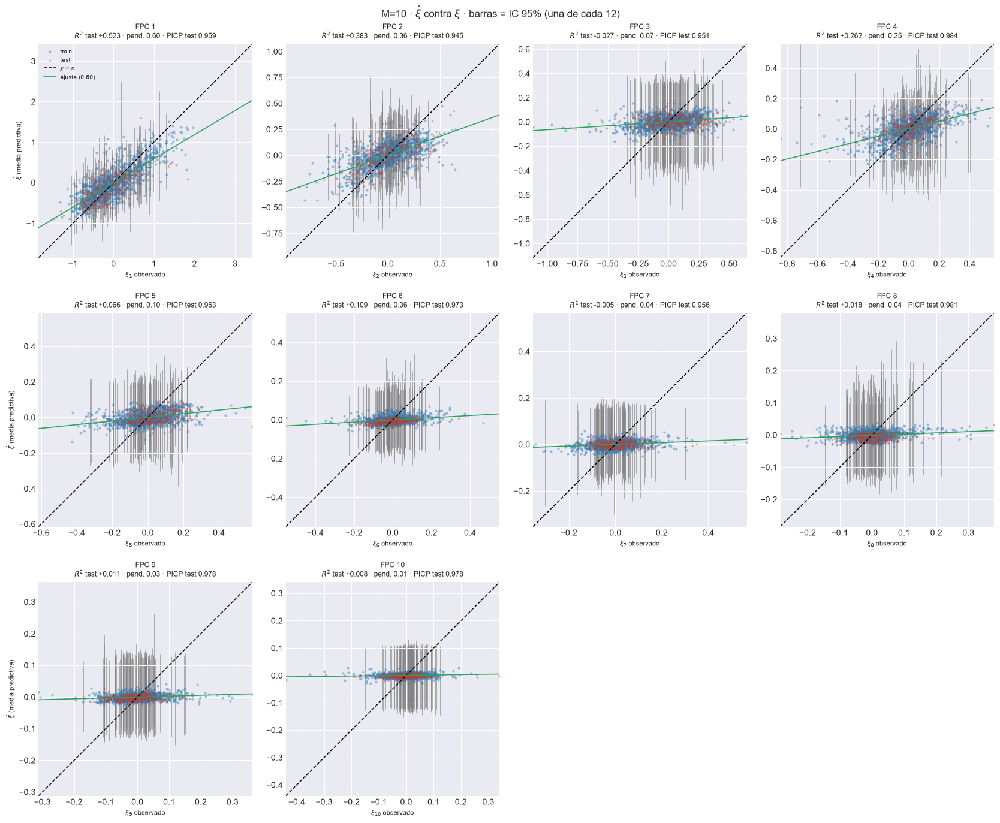

In [25]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()

## 11. Diagnóstico de multimodalidad

En la ventana de detalle, como cuentas: por score, orígenes con $|\hat E - \mathrm{mediana}| > 0.25\,\hat s$; por origen, distancia de la mediana puntual a la extracción más cercana contra la de vecinas.

In [26]:
# Sobre los N_DETALLE orígenes de la ventana de detalle: cuentas k de N_DETALLE, descriptivas.
wn, MULTI = pesos_normalizados(grilla, PESOS_TAU), {}
for M in M_OK:
    e = EST[M]
    q16, q50, q84 = np.quantile(e["SC_draws"][:, IDX_DET], [0.16, 0.5, 0.84], axis=0)
    sep = np.abs(e["Y_hat"][IDX_DET] - q50) / np.maximum((q84 - q16) / 2.0, 1e-12)   # (N_DETALLE, M)
    por_score = pd.DataFrame({"componente": [f"FPC {c + 1}" for c in e["component_idx"]],
                              "n_origenes": N_DETALLE,
                              f"n_sep_gt_{UMBRAL_SEP}": (sep > UMBRAL_SEP).sum(axis=0),
                              "sep_mediana": np.median(sep, axis=0), "sep_max": sep.max(axis=0)})
    d = distancia_a_muestra_mas_cercana(curvas_draws(e, DIS, IDX_DET), e["X_PRED"]["mediana"][IDX_DET],
                                        grilla, PESOS_TAU, N_REF_NN, SEED_PRED)
    por_origen = pd.DataFrame({"t": T_DET, **d, "l1_esperanza_mediana":
                               np.abs(e["X_pred"][IDX_DET] - e["X_PRED"]["mediana"][IDX_DET]) @ wn,
                               "sep_max_score": sep.max(axis=1)})
    por_score.to_csv(e["paths"]["out_report"] / "60_multimodalidad_por_score.csv", index=False)
    por_origen.to_csv(e["paths"]["out_report"] / "61_distancia_mediana_muestra.csv", index=False)
    MULTI[M] = (por_score, por_origen)
multi_bar = pd.concat([MULTI[M][0].assign(M=M, t0_detalle=T0_DET) for M in M_OK], ignore_index=True)
multi_bar.to_csv(PATH_BARRIDO / "100_multimodalidad_por_M.csv", index=False)

display(multi_bar.pivot(index="componente", columns="M", values=f"n_sep_gt_{UMBRAL_SEP}")
        .reindex([f"FPC {k}" for k in range(1, max(M_OK) + 1)])
        .style.format("{:.0f}", na_rep="-").background_gradient(cmap="Reds", vmin=0, vmax=N_DETALLE, axis=None)
        .set_caption(f"Ventana de detalle (t={T0_DET}..): orígenes, de {N_DETALLE}, con "
                     f"|esperanza − mediana| > {UMBRAL_SEP} sd robusta, por score (descriptivo)"))
display(pd.DataFrame({M: MULTI[M][1].set_index("t")["razon"] for M in M_OK}).style.format("{:.2f}")
        .set_caption("Ventana de detalle · razón d(mediana, extracción más cercana) / d típica, por origen"))

M,1,2,3,4,5,6,7,8,9,10
componente,,,,,,,,,,
FPC 1,0,0,0,0,0,0,0,0,0,0
FPC 2,-,0,0,0,0,0,0,0,0,0
FPC 3,-,-,0,0,0,0,0,0,0,0
FPC 4,-,-,-,0,0,0,0,0,0,0
FPC 5,-,-,-,-,0,0,0,0,0,0
FPC 6,-,-,-,-,-,0,0,0,0,0
FPC 7,-,-,-,-,-,-,0,0,0,0
FPC 8,-,-,-,-,-,-,-,0,0,0
FPC 9,-,-,-,-,-,-,-,-,0,0


,1,2,3,4,5,6,7,8,9,10
t,,,,,,,,,,
1227,0.52,0.26,1.03,0.54,0.44,0.72,0.41,0.64,0.60,0.65
1228,6.06,0.40,0.45,0.65,0.51,0.77,0.60,0.59,0.63,0.61
1229,1.51,0.66,0.61,0.66,0.65,0.45,0.63,0.54,0.71,0.50
1230,0.43,0.91,0.70,0.52,0.61,0.80,0.58,0.51,0.62,0.66
1231,3.45,0.57,0.35,0.53,0.78,0.65,0.74,0.60,0.60,0.51
1232,0.31,0.28,0.91,0.70,0.62,0.57,0.48,0.73,0.75,0.82
1233,0.13,0.67,1.43,0.84,0.58,0.63,0.47,0.65,0.36,0.60
1234,2.54,0.97,0.45,0.56,0.80,0.65,0.46,0.66,0.56,0.49
1235,0.54,0.86,0.49,0.65,0.54,0.72,0.74,0.58,0.50,0.61


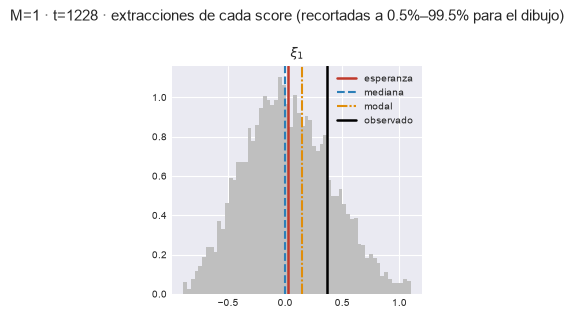

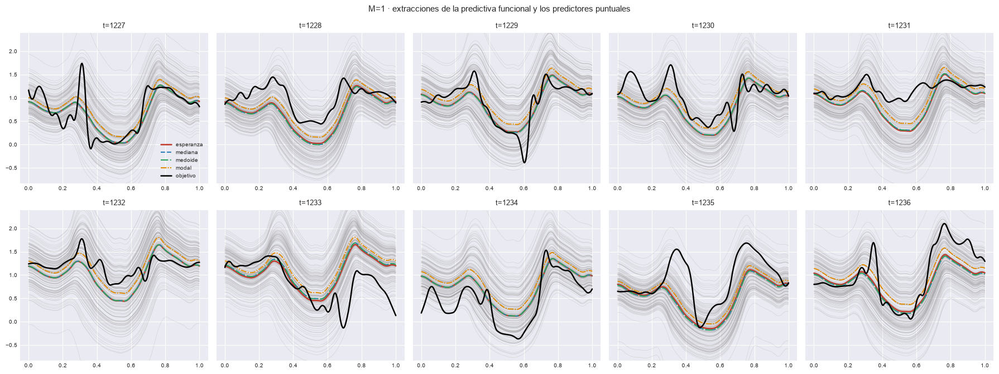

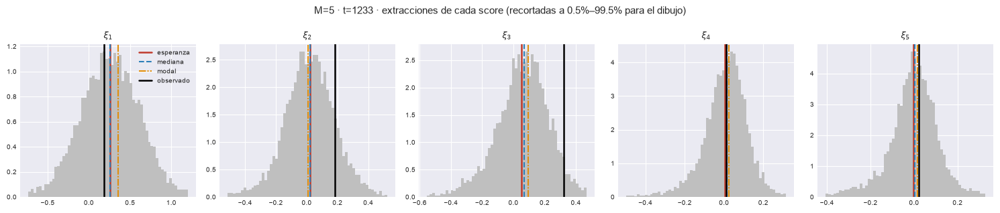

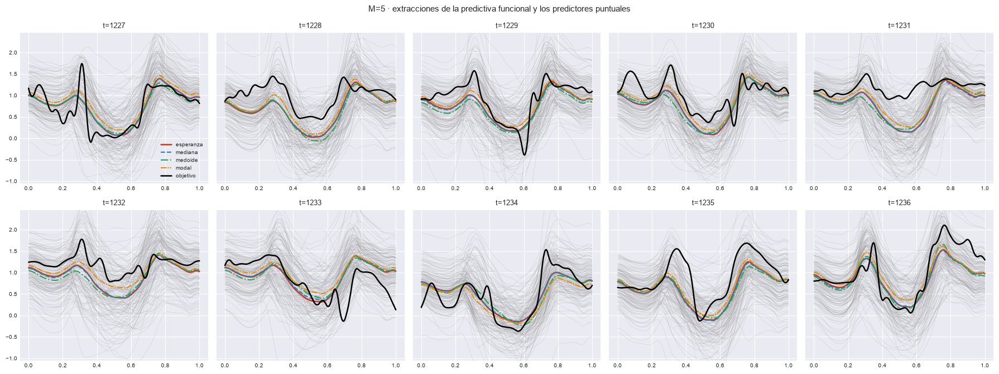

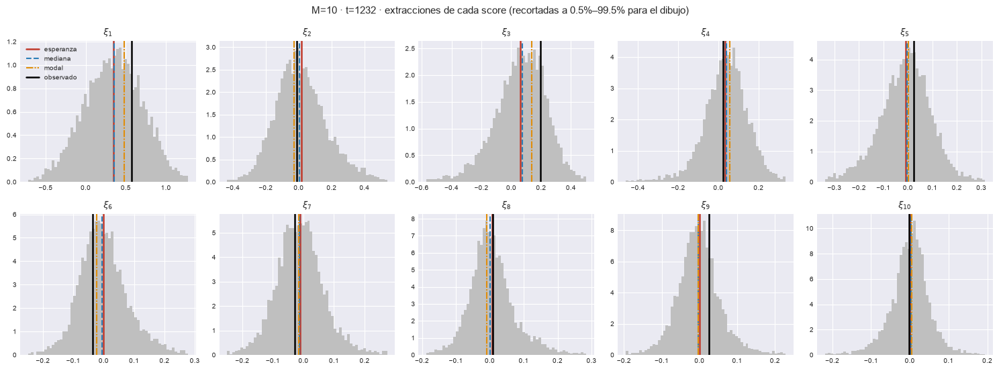

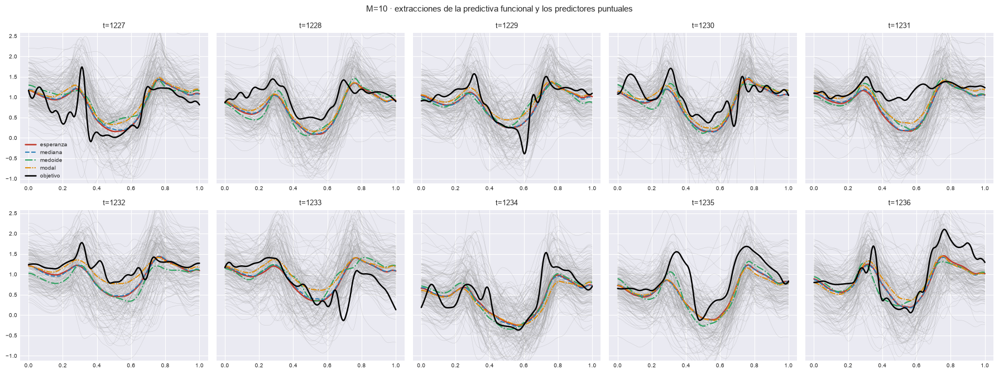

In [27]:
# El origen más multimodal de la ventana: extracciones por score; los N_DETALLE: curvas y predictores.
for M in (m for m in M_DETALLE if m in M_OK):
    e, po = EST[M], MULTI[M][1]
    i_mm = int(IDX_DET[int(np.argmax(po["sep_max_score"].to_numpy()))])
    marcas = {"esperanza": e["Y_hat"], "mediana": np.median(e["SC_draws"], axis=0),
              "modal": e["Y_mod"], "observado": e["Y_obs"]}
    plot_histogramas_draws(e["SC_draws"], i_mm, marcas, int(t_orig[i_mm]), M,
                           save_path=e["paths"]["out_report"] / f"61_histogramas_draws_t{int(t_orig[i_mm])}.png")
    plt.show()
    plot_curvas_predictores(curvas_draws(e, DIS, IDX_DET), {p: e["X_PRED"][p][IDX_DET] for p in PREDICTORES},
                            X_obj_ev[IDX_DET], grilla, T_DET, M, ncols=5,
                            save_path=e["paths"]["out_report"] / "61b_curvas_predictores.png")
    plt.show()

## 12. Comportamientos predictivos

k-medias sobre las extracciones de scores por origen; $K$ con las reglas de docs §03_06_02 (valle, crecimiento, masa); con $a_\tau \le 1$ se recortan los draws al 0.5–99.5 %. §12.1 y §12.4 sobre toda la serie; §12.2, §12.3, §12.5 y el cierre de §12.4 sobre la ventana de detalle. Se persiste en `comportamientos_psbp.npz`.

### 12.1 Número de comportamientos por origen

    comportamientos: 250/1460 origenes


    comportamientos: 500/1460 origenes


    comportamientos: 750/1460 origenes


    comportamientos: 1000/1460 origenes


    comportamientos: 1250/1460 origenes


...

    comportamientos: 1000/1460 origenes


    comportamientos: 1250/1460 origenes


M=10: K en test  K=1: 100.0%   (recorte si, 108 s)


M,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


M,1,2,3,4,5,6,7,8,9,10
K,,,,,,,,,,
1,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%,100.0%
2,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
3,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
4,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
5,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
6,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


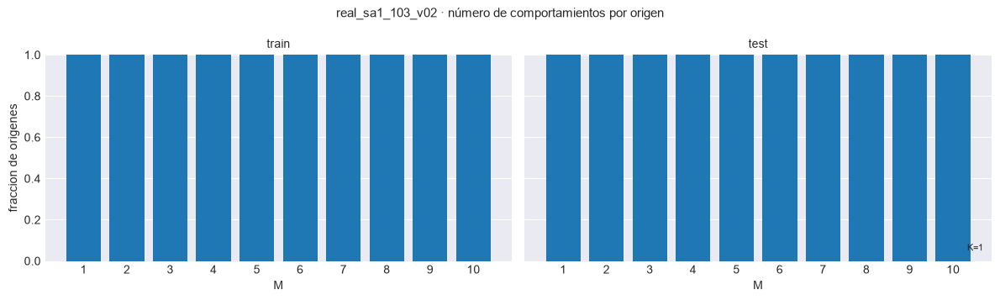

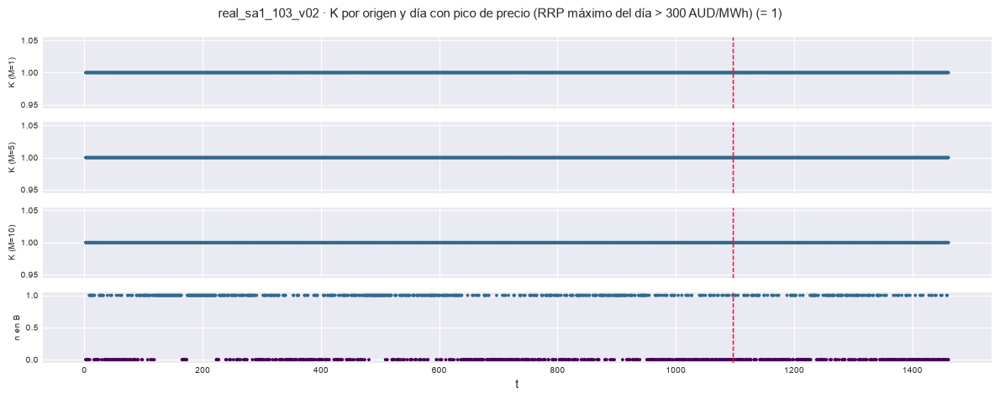

In [28]:
K_BAR = comportamientos_barrido(EST, M_OK, DIS, ORIG, PATH_BARRIDO, solo_test=COMP_SOLO_TEST)
for b in ("train", "test"):
    display(K_BAR[K_BAR.bloque == b].pivot(index="K", columns="M", values="frac")
            .style.format("{:.1%}").set_caption(f"Fracción de orígenes {b.upper()} con K comportamientos (102_K_por_M.csv)"))
plot_K_barrido(K_BAR, f"{EXPERIMENT_BASE} · número de comportamientos por origen", PATH_BARRIDO / "102_K_por_M.png")
plt.show()

plot_K_serie({M: EST[M]["COMP"]["K"] for M in M_DETALLE if M in M_OK}, t_orig, T0, n_B=EVENTO_OR,
             titulo=f"{EXPERIMENT_BASE} · K por origen y {DESCR_EVENTO} (= 1)",
             save_path=PATH_BARRIDO / "102b_K_serie.png")
plt.show()


### 12.2 Ventana de detalle: curvas típicas, bandas condicionales y tramos de la HDR

Grilla `63_comportamientos_ejemplos.png` y una figura por origen `63_detalle_t<t>.png`.

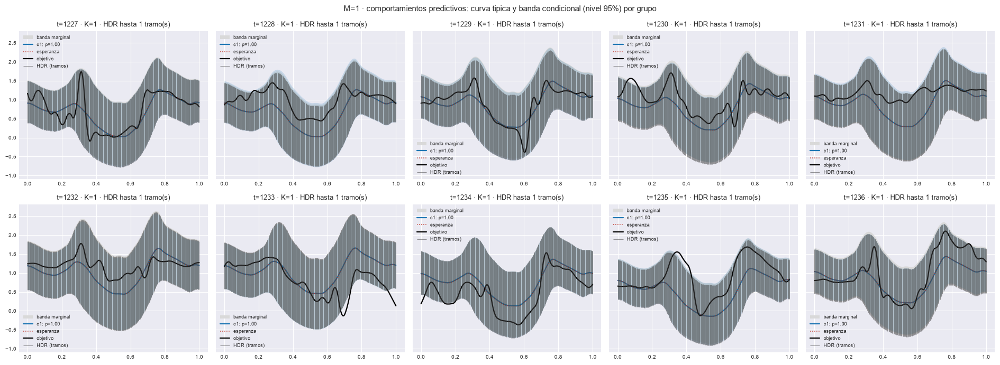

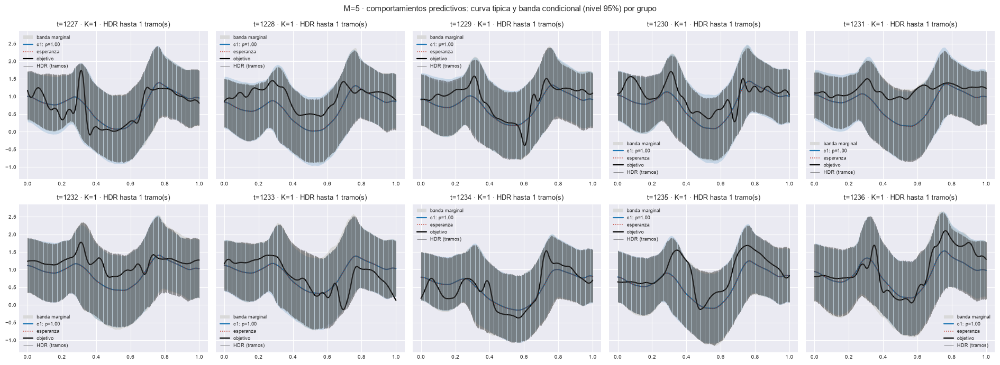

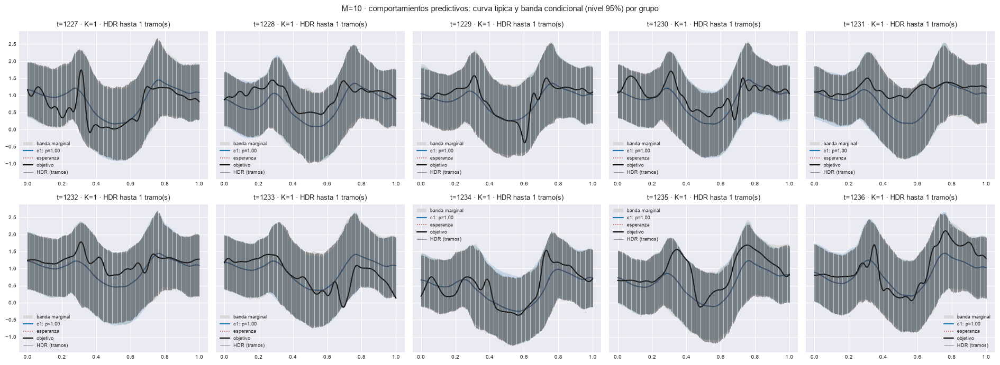

In [29]:
ESTILO_INT = {"equicolas": "#2c7fb8", "simultanea": "#8856a7", "hdr": "#2ca25f"}


def figura_origen(e, i, M, save_path):
    # Un origen: objetivo, los predictores, equi-colas, simultánea, tramos de la HDR y curvas típicas.
    C, (Ls, Us), (Lh, Uh) = e["COMP"], e["INTERVALOS"]["simultanea"], e["INTERVALOS"]["hdr"]
    fig, ax = plt.subplots(figsize=(8.6, 4.6))
    ax.fill_between(grilla, Ls[i, :, 0], Us[i, :, 0], color=ESTILO_INT["simultanea"], alpha=0.12, lw=0,
                    label="banda simultánea")
    ax.fill_between(grilla, e["li_f"][i], e["ls_f"][i], color=ESTILO_INT["equicolas"], alpha=0.22, lw=0,
                    label="equi-colas")
    for k in range(Lh.shape[2]):
        ok = np.isfinite(Lh[i, :, k])
        ax.vlines(grilla[ok], Lh[i, ok, k], Uh[i, ok, k], color=ESTILO_INT["hdr"], lw=1.1, alpha=0.75,
                  label="HDR (tramos)" if k == 0 else None)
    for c in range(int(C["K"][i])):
        ax.plot(grilla, C["curvas"][i, c], color="0.3", lw=0.8 + 2.4 * C["masas"][i, c], ls=(0, (4, 2)),
                label=f"comportamiento {c + 1}: p = {C['masas'][i, c]:.2f}")
    for pr in PREDICTORES:
        ax.plot(grilla, e["X_PRED"][pr][i], label=pr, **ESTILOS_PREDICTORES.get(pr, {}))
    ax.plot(grilla, X_obj_ev[i], color="k", lw=2.0, label="observada (objetivo)")
    ax.set_title(f"M={M} · t={int(t_orig[i])} · K={int(C['K'][i])} · HDR hasta "
                 f"{int(e['hdr_tramos'][i].max())} tramo(s)", fontsize=10)
    ax.set_xlabel(r"$\tau$")
    ax.legend(fontsize=7, ncol=2, loc="best")
    fig.tight_layout()
    fig.savefig(str(save_path), dpi=150, bbox_inches="tight")
    return fig


for M in (m for m in M_DETALLE if m in M_OK):
    e = EST[M]
    plot_comportamientos(e["COMP"], list(IDX_DET), X_obj_ev, e["li_f"], e["ls_f"], grilla, t_orig, M,
                         X_esp=e["X_pred"], hdr=e["INTERVALOS"]["hdr"], ncols=5,
                         save_path=e["paths"]["out_report"] / "63_comportamientos_ejemplos.png")
    plt.show()
    for i in IDX_DET:
        figura_origen(e, i, M, e["paths"]["out_report"] / f"63_detalle_t{int(t_orig[i])}.png")
        plt.close()

### 12.3 Catálogo global

Las mismas reglas sobre los centroides de la ventana, ponderados por masa.

M= 1: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 2: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 3: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 4: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 5: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 6: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 7: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 8: catalogo global con L=1 comportamiento(s), masas [1.0]
M= 9: catalogo global con L=1 comportamiento(s), masas [1.0]
M=10: catalogo global con L=1 comportamiento(s), masas [1.0]


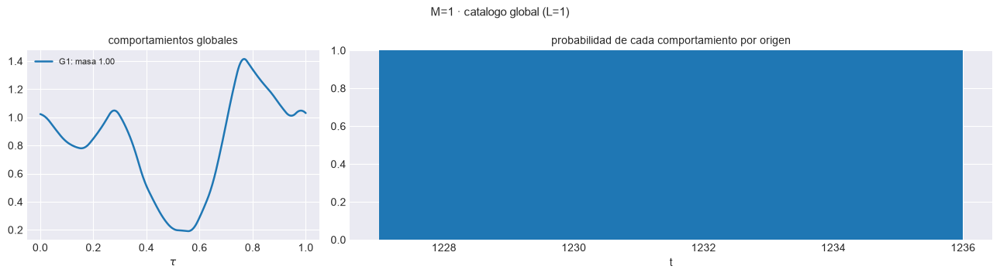

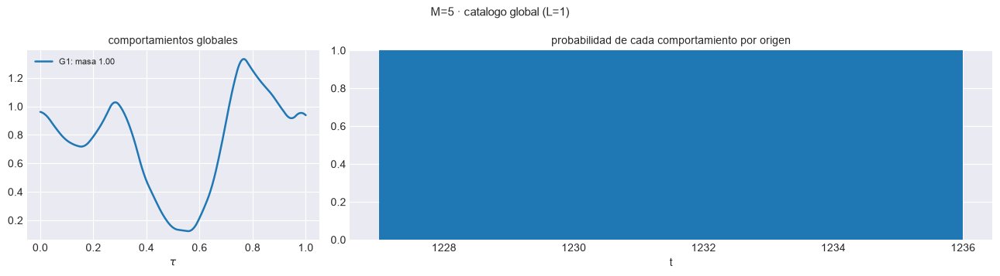

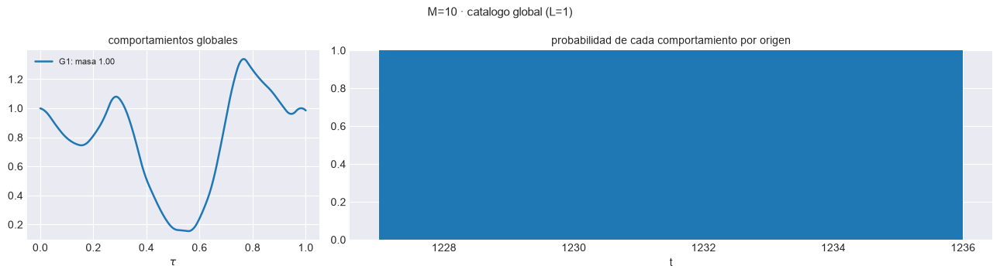

In [30]:
# catalogo_barrido sólo usa es_train para la máscara: la ventana de detalle hace de 'test'.
ORIG_DET = {**ORIG, "es_train": ~MASK_DET}
CAT_BAR = catalogo_barrido(EST, M_OK, ORIG_DET, PATH_BARRIDO)
for M in (m for m in M_DETALLE if m in M_OK):
    plot_catalogo(EST[M]["CATALOGO"], grilla, t_orig, M,
                  save_path=EST[M]["paths"]["out_report"] / "64_catalogo_global.png")
    plt.show()

### 12.4 Comportamientos contra el calendario y los picos

No hay régimen verdadero. La referencia externa son los **picos de precio** (el día predicho supera `UMBRAL_PICO_RRP` AUD/MWh en algún intervalo) y el calendario (día de la semana y mes). Sobre toda la serie de prueba, la tabla cruzada de $K$ con el día de la semana, con el mes y con el pico del día predicho (`65_comportamientos_calendario.csv` por $M$, `104_comportamientos_calendario_por_M.csv` en el barrido) y, para los orígenes con $K \ge 2$, cuántos caen en día con pico o en el día siguiente a uno: la hipótesis es que la bimodalidad aparece cuando el día anterior tuvo pico (¿se repite o no?). Al final, la misma lectura sobre la ventana de detalle, como cuentas.


In [31]:
DIAS_ORDEN = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
AYER = f"ayer_{NOMBRE_EVENTO}"
filas = []
for M in M_OK:
    K = EST[M]["COMP"]["K"].astype(int)
    df = pd.DataFrame({"M": M, "t": t_orig, "bloque": np.where(es_train, "train", "test"), "K": K,
                       **{k: v for k, v in VERDAD_DET.items()}})
    df[NOMBRE_EVENTO], df[AYER] = df[NOMBRE_EVENTO].astype(bool), df[AYER].astype(bool)
    df.drop(columns="M").to_csv(EST[M]["paths"]["out_report"] / "65_comportamientos_calendario.csv", index=False)
    filas.append(df)
    te = df[df.bloque == "test"]
    cruz = pd.crosstab(te["dia_semana"], te["K"]).reindex(DIAS_ORDEN).fillna(0).astype(int)
    display(cruz.style.set_caption(f"M={M} · TEST · orígenes por día de la semana del día predicho y K (cuentas)"))
    display(pd.crosstab(te["mes"], te["K"]).style.set_caption(f"M={M} · TEST · orígenes por mes del día predicho y K (cuentas)"))
    display(pd.crosstab([te[NOMBRE_EVENTO], te[AYER]], te["K"])
            .style.set_caption(f"M={M} · TEST · orígenes por {NOMBRE_EVENTO} del día predicho y del anterior, y K (cuentas)"))
    k2 = te[te.K >= 2]
    print(f"M={M}: K >= 2 en {len(k2)} de {len(te)} orígenes de test · de ellos, día predicho con {NOMBRE_EVENTO} "
          f"{int(k2[NOMBRE_EVENTO].sum())} y día anterior con {NOMBRE_EVENTO} {int(k2[AYER].sum())} · "
          f"base en test: {te[NOMBRE_EVENTO].mean():.0%} de los días predichos tienen {NOMBRE_EVENTO}")
CAL = pd.concat(filas, ignore_index=True)
CAL.to_csv(PATH_BARRIDO / "104_comportamientos_calendario_por_M.csv", index=False)
display(CAL[CAL.t.isin(T_DET)].set_index(["M", "t"])[["fecha", "dia_semana", "mes", NOMBRE_MEDIDA, NOMBRE_EVENTO, AYER, "K"]]
        .style.format({NOMBRE_MEDIDA: "{:.1f}"})
        .set_caption(f"Ventana de detalle (t={T0_DET}..{T0_DET + N_DETALLE - 1}): calendario, {NOMBRE_EVENTO} y K por origen (descriptivo)"))


K,1
dia_semana,
Mon,52
Tue,52
Wed,53
Thu,52
Fri,52
Sat,52
Sun,52


K,1
mes,
1,31
2,28
3,31
4,30
5,31
6,30
7,31
8,31
9,30


M=1: K >= 2 en 0 de 365 orígenes de test · de ellos, día predicho con pico 0 y día anterior con pico 0 · base en test: 35% de los días predichos tienen pico


K,1
dia_semana,
Mon,52
Tue,52
Wed,53
Thu,52
Fri,52
Sat,52
Sun,52


K,1
mes,
1,31
2,28
3,31
4,30
5,31
6,30
7,31
8,31
9,30


...

K,1
mes,
1,31
2,28
3,31
4,30
5,31
6,30
7,31
8,31
9,30


M=9: K >= 2 en 0 de 365 orígenes de test · de ellos, día predicho con pico 0 y día anterior con pico 0 · base en test: 35% de los días predichos tienen pico


K,1
dia_semana,
Mon,52
Tue,52
Wed,53
Thu,52
Fri,52
Sat,52
Sun,52


K,1
mes,
1,31
2,28
3,31
4,30
5,31
6,30
7,31
8,31
9,30


M=10: K >= 2 en 0 de 365 orígenes de test · de ellos, día predicho con pico 0 y día anterior con pico 0 · base en test: 35% de los días predichos tienen pico


### 12.5 Ventana de detalle, origen por origen

`112_ventana_detalle_por_origen.csv`: $K$ y masas, tramos de la HDR, longitud y cobertura de cada intervalo, calendario (fecha, día de la semana, mes), pico del día predicho y del anterior, y error de cada predictor.

In [32]:
wn, filas = pesos_normalizados(grilla, PESOS_TAU), []
for M in M_OK:
    e, C = EST[M], EST[M]["COMP"]
    nm = {pr: normas_error_por_origen(X_obj_ev[IDX_DET], e["X_PRED"][pr][IDX_DET], grilla,
                                      pesos_tau=PESOS_TAU, verificar=False) for pr in PREDICTORES}
    for j, i in enumerate(IDX_DET):
        fila = {"M": M, "t": int(t_orig[i]), "K": int(C["K"][i]),
                **{f"p_{c + 1}": float(C["masas"][i, c]) for c in range(int(C["K"][i]))},
                "hdr_tramos_max": int(e["hdr_tramos"][i].max())}
        for nombre, (L, U) in e["INTERVALOS"].items():
            fila[f"long_{nombre}"] = float(ancho_tramos(L[i], U[i]) @ wn)
            fila[f"cob_{nombre}"] = float(cobertura_tramos(X_obj_ev[i], L[i], U[i]).mean())
        for pr in PREDICTORES:
            fila[f"mae_{pr}"], fila[f"rmse_{pr}"] = float(nm[pr]["l1"][j]), float(nm[pr]["l2"][j])
        fila.update({k: v[i] for k, v in VERDAD_DET.items()})
        filas.append(fila)
DETALLE = pd.DataFrame(filas)
cols_p = sorted([c for c in DETALLE.columns if c.startswith("p_")], key=lambda c: int(c[2:]))
DETALLE = DETALLE[["M", "t", "K"] + cols_p + [c for c in DETALLE.columns if c not in ["M", "t", "K"] + cols_p]]
DETALLE.to_csv(PATH_BARRIDO / "112_ventana_detalle_por_origen.csv", index=False)
for M in (m for m in M_DETALLE if m in M_OK):
    display(DETALLE[DETALLE.M == M].drop(columns="M").set_index("t").style.format(precision=3)
            .set_caption(f"M={M} · ventana de detalle origen por origen (112_ventana_detalle_por_origen.csv)"))

,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,rrp_max,pico,ayer_pico
t,,,,,,,,,,,,,,,,,,,,,,,
1227,1,1.000,1,1.477,1.000,1.534,1.000,1.488,1.000,0.179,0.265,0.179,0.265,0.179,0.265,0.214,0.278,2025-05-11,Sun,5,560.980,1,0
1228,1,1.000,1,1.410,0.983,1.417,0.969,1.399,0.972,0.338,0.393,0.354,0.412,0.356,0.415,0.254,0.294,2025-05-12,Mon,5,230.410,0,1
1229,1,1.000,1,1.545,1.000,1.511,1.000,1.509,1.000,0.156,0.217,0.157,0.219,0.157,0.219,0.184,0.246,2025-05-13,Tue,5,301.110,1,0
1230,1,1.000,1,1.554,0.944,1.540,0.941,1.544,0.938,0.265,0.324,0.260,0.320,0.260,0.320,0.190,0.260,2025-05-14,Wed,5,379.950,1,1
1231,1,1.000,1,1.553,1.000,1.579,1.000,1.566,1.000,0.292,0.384,0.279,0.369,0.281,0.371,0.206,0.284,2025-05-15,Thu,5,311.280,1,1
1232,1,1.000,1,1.732,1.000,1.718,1.000,1.719,1.000,0.240,0.284,0.238,0.281,0.238,0.281,0.189,0.227,2025-05-16,Fri,5,314.430,1,1
1233,1,1.000,1,1.629,0.892,1.611,0.878,1.638,0.892,0.351,0.475,0.361,0.492,0.361,0.493,0.413,0.562,2025-05-17,Sat,5,349.090,1,1
1234,1,1.000,1,1.512,0.896,1.521,0.920,1.532,0.906,0.314,0.353,0.316,0.355,0.317,0.356,0.421,0.460,2025-05-18,Sun,5,302.060,1,1
1235,1,1.000,1,1.396,0.906,1.419,0.878,1.399,0.896,0.388,0.523,0.410,0.547,0.410,0.547,0.337,0.454,2025-05-19,Mon,5,391.460,1,1


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,rrp_max,pico,ayer_pico
t,,,,,,,,,,,,,,,,,,,,,,,
1227,1,1.000,1,1.761,1.000,2.505,1.000,1.766,1.000,0.184,0.257,0.183,0.257,0.184,0.261,0.235,0.296,2025-05-11,Sun,5,560.980,1,0
1228,1,1.000,1,1.712,1.000,2.532,1.000,1.716,1.000,0.358,0.404,0.352,0.398,0.375,0.431,0.298,0.336,2025-05-12,Mon,5,230.410,0,1
1229,1,1.000,1,1.774,1.000,2.581,1.000,1.784,1.000,0.221,0.273,0.230,0.280,0.285,0.332,0.185,0.243,2025-05-13,Tue,5,301.110,1,0
1230,1,1.000,1,1.702,1.000,2.425,1.000,1.705,1.000,0.280,0.335,0.277,0.333,0.293,0.353,0.215,0.273,2025-05-14,Wed,5,379.950,1,1
1231,1,1.000,1,1.719,1.000,2.492,1.000,1.721,1.000,0.376,0.476,0.384,0.480,0.375,0.468,0.289,0.398,2025-05-15,Thu,5,311.280,1,1
1232,1,1.000,1,1.914,1.000,2.697,1.000,1.918,1.000,0.279,0.332,0.279,0.331,0.314,0.371,0.180,0.217,2025-05-16,Fri,5,314.430,1,1
1233,1,1.000,1,1.859,0.969,2.659,1.000,1.866,0.986,0.293,0.376,0.289,0.375,0.293,0.378,0.289,0.388,2025-05-17,Sat,5,349.090,1,1
1234,1,1.000,1,1.745,1.000,2.492,1.000,1.747,1.000,0.201,0.267,0.204,0.270,0.214,0.290,0.241,0.316,2025-05-18,Sun,5,302.060,1,1
1235,1,1.000,1,1.788,1.000,2.611,1.000,1.796,1.000,0.314,0.418,0.324,0.430,0.325,0.426,0.272,0.362,2025-05-19,Mon,5,391.460,1,1


,K,p_1,hdr_tramos_max,long_equicolas,cob_equicolas,long_simultanea,cob_simultanea,long_hdr,cob_hdr,mae_esperanza,rmse_esperanza,mae_mediana,rmse_mediana,mae_medoide,rmse_medoide,mae_modal,rmse_modal,fecha,dia_semana,mes,rrp_max,pico,ayer_pico
t,,,,,,,,,,,,,,,,,,,,,,,
1227,1,1.000,1,1.972,1.000,3.047,1.000,1.976,1.000,0.234,0.298,0.243,0.305,0.303,0.363,0.313,0.369,2025-05-11,Sun,5,560.980,1,0
1228,1,1.000,1,1.860,1.000,2.843,1.000,1.865,1.000,0.297,0.340,0.291,0.335,0.316,0.375,0.250,0.287,2025-05-12,Mon,5,230.410,0,1
1229,1,1.000,1,1.907,1.000,2.946,1.000,1.910,1.000,0.165,0.224,0.173,0.232,0.203,0.285,0.161,0.234,2025-05-13,Tue,5,301.110,1,0
1230,1,1.000,1,1.798,1.000,2.777,1.000,1.803,1.000,0.237,0.294,0.237,0.293,0.223,0.267,0.200,0.254,2025-05-14,Wed,5,379.950,1,1
1231,1,1.000,1,1.837,1.000,2.724,1.000,1.842,1.000,0.327,0.439,0.311,0.425,0.292,0.401,0.215,0.328,2025-05-15,Thu,5,311.280,1,1
1232,1,1.000,1,1.966,1.000,2.920,1.000,1.975,1.000,0.228,0.288,0.228,0.285,0.322,0.365,0.109,0.151,2025-05-16,Fri,5,314.430,1,1
1233,1,1.000,1,1.933,0.962,2.996,1.000,1.937,0.976,0.289,0.386,0.282,0.386,0.333,0.431,0.310,0.426,2025-05-17,Sat,5,349.090,1,1
1234,1,1.000,1,1.844,1.000,2.834,1.000,1.848,1.000,0.207,0.286,0.212,0.294,0.222,0.319,0.257,0.350,2025-05-18,Sun,5,302.060,1,1
1235,1,1.000,1,1.844,0.983,2.727,1.000,1.843,1.000,0.338,0.435,0.342,0.445,0.347,0.432,0.351,0.453,2025-05-19,Mon,5,391.460,1,1
